In [1]:
# ============================================================
# CELL 1 - SETUP, ENVIRONMENT & EVALUATION PROTOCOL
# Notebook: 06_multimodal_retrieval_evaluation.ipynb
# ============================================================

import sys
import json
import hashlib
import platform

from pathlib import Path
from importlib.metadata import (
    version,
    PackageNotFoundError
)

import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt

from IPython.display import display


print("NOTEBOOK 06 - MULTIMODAL RETRIEVAL EVALUATION")
print("=" * 75)

EVAL06_SETUP_COMPLETED = False


# ============================================================
# 1. EVALUATION CONFIGURATION
# ============================================================

EVAL06_RANDOM_STATE = 42

EVAL06_SPLIT_RATIOS = {
    "gallery": 0.60,
    "validation": 0.20,
    "test": 0.20,
}

EVAL06_TOP_K_VALUES = (1, 3, 5, 10)

EVAL06_ALPHA_GRID = np.linspace(
    0.0,
    1.0,
    11
)

EVAL06_DEFAULT_ALPHA = 0.5

EVAL06_TEXT_CONFIGURATIONS = (
    "Unigram",
    "Unigram + Bigram"
)

EVAL06_METHODS = (
    "Visual Only",
    "Text Only",
    "Weighted Fusion"
)

EVAL06_PRIMARY_SELECTION_METRIC = "mAP@5"

EVAL06_EVALUATION_METRICS = (
    "Precision@K",
    "Recall@K",
    "MRR@K",
    "mAP@K",
    "nDCG@K",
)

EVAL06_RELEVANCE_POLICY = (
    "same_plant_class"
)

EVAL06_TIE_BREAKING_POLICY = (
    "similarity_descending_then_sample_id_ascending"
)

EVAL06_NUMERICAL_TOLERANCE = 1e-10

EVAL06_SCOPE = (
    "Independent validation and test queries "
    "against a fit-only reference gallery"
)

# Only the gallery is allowed to fit learned
# transformations such as:
#
# - feature normalization / scaling
# - TF-IDF vocabulary
# - TF-IDF inverse document frequencies
#
# Validation and test queries must be transformed
# using the transformations fitted on the gallery.

EVAL06_FIT_POLICY = "gallery_only"

EVAL06_VALIDATION_POLICY = (
    "select_alpha_and_text_configuration"
)

EVAL06_TEST_POLICY = (
    "evaluate_once_after_configuration_is_frozen"
)

EVAL06_REQUIRE_LEAKAGE_AUDIT = True

EVAL06_ALLOW_FULL_GALLERY_TFIDF_FOR_TEST = False

EVAL06_ALLOW_FULL_GALLERY_SCALER_FOR_TEST = False

EVAL06_ALLOW_TEST_SET_FOR_WEIGHT_SELECTION = False


# ============================================================
# 2. INITIALIZE VALIDATION RECORDS
# ============================================================

eval06_setup_checks = []


def eval06_setup_check(
    category,
    name,
    condition,
    detail=""
):

    eval06_setup_checks.append({
        "category": category,
        "validation_check": name,
        "passed": bool(condition),
        "detail": str(detail),
    })


# ============================================================
# 3. LOCATE PROJECT ROOT
# ============================================================

# Supports opening Jupyter from:
#
# D:/Project/Multimodal_Leaf_Retrieval/
#
# or:
#
# D:/Project/Multimodal_Leaf_Retrieval/notebooks/

EVAL06_WORKING_DIRECTORY = Path.cwd().resolve()

if EVAL06_WORKING_DIRECTORY.name.lower() in (
    "notebooks",
    "notebook"
):

    EVAL06_PROJECT_ROOT = (
        EVAL06_WORKING_DIRECTORY.parent
    )

else:

    EVAL06_PROJECT_ROOT = (
        EVAL06_WORKING_DIRECTORY
    )

print("\n1. PROJECT PATH CONFIGURATION")
print("-" * 75)

print(
    "Current working directory:",
    EVAL06_WORKING_DIRECTORY
)

print(
    "Project root:",
    EVAL06_PROJECT_ROOT
)


# ============================================================
# 4. LOCATE NOTEBOOK 05 ARTIFACTS
# ============================================================

# Cell 19 stored gallery_index.csv,
# gallery_metadata.csv, feature arrays, and
# the SHA-256 manifest.
#
# Search only known candidate directories.
# If necessary, set EVAL06_SOURCE_ARTIFACTS_DIR
# manually to the actual Cell 19 output directory.

EVAL06_ARTIFACT_CANDIDATES = [
    EVAL06_PROJECT_ROOT
    / "results"
    / "artifacts"
    / "multimodal_fusion",

    EVAL06_PROJECT_ROOT
    / "results"
    / "metrics"
    / "artifacts"
    / "multimodal_fusion",

    EVAL06_PROJECT_ROOT
    / "artifacts"
    / "multimodal_fusion",

    EVAL06_WORKING_DIRECTORY
    / "results"
    / "artifacts"
    / "multimodal_fusion",
]

# Optional explicit override.

if (
    "EVAL06_SOURCE_ARTIFACTS_DIR"
    in globals()
):

    EVAL06_ARTIFACT_CANDIDATES.insert(
        0,
        Path(
            globals()[
                "EVAL06_SOURCE_ARTIFACTS_DIR"
            ]
        )
    )

required_source_files = (
    "gallery_index.csv",
    "gallery_metadata.csv",
    "fusion_artifact_config.json",
    "fusion_artifact_manifest.json",
)

EVAL06_SOURCE_ARTIFACTS_DIR = None

for candidate in EVAL06_ARTIFACT_CANDIDATES:

    candidate = Path(candidate).resolve()

    if all(
        (candidate / filename).is_file()
        for filename in required_source_files
    ):

        EVAL06_SOURCE_ARTIFACTS_DIR = (
            candidate
        )

        break

if EVAL06_SOURCE_ARTIFACTS_DIR is None:

    attempted = "\n".join(
        str(path)
        for path in EVAL06_ARTIFACT_CANDIDATES
    )

    raise FileNotFoundError(
        "Notebook 05 artifacts were not found.\n"
        "Check the directory generated by Cell 19.\n\n"
        f"Locations checked:\n{attempted}"
    )

print("\n2. NOTEBOOK 05 ARTIFACTS")
print("-" * 75)

print(
    "Source artifacts directory:",
    EVAL06_SOURCE_ARTIFACTS_DIR
)

for filename in required_source_files:

    print("[FOUND]", filename)


# ============================================================
# 5. DEFINE NOTEBOOK 06 OUTPUT DIRECTORIES
# ============================================================

EVAL06_OUTPUT_ROOT = (
    EVAL06_PROJECT_ROOT
    / "results"
)

EVAL06_METRICS_DIR = (
    EVAL06_OUTPUT_ROOT
    / "metrics"
    / "retrieval_evaluation"
)

EVAL06_FIGURES_DIR = (
    EVAL06_OUTPUT_ROOT
    / "figures"
    / "retrieval_evaluation"
)

EVAL06_ARTIFACTS_DIR = (
    EVAL06_OUTPUT_ROOT
    / "artifacts"
    / "retrieval_evaluation"
)

for directory in [
    EVAL06_METRICS_DIR,
    EVAL06_FIGURES_DIR,
    EVAL06_ARTIFACTS_DIR,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True
    )

print("\n3. NOTEBOOK 06 OUTPUT DIRECTORIES")
print("-" * 75)

print("Metrics  :", EVAL06_METRICS_DIR)
print("Figures  :", EVAL06_FIGURES_DIR)
print("Artifacts:", EVAL06_ARTIFACTS_DIR)


# ============================================================
# 6. LOAD NOTEBOOK 05 GALLERY INDEX
# ============================================================

EVAL06_GALLERY_INDEX_DF = pd.read_csv(
    EVAL06_SOURCE_ARTIFACTS_DIR
    / "gallery_index.csv",

    dtype={
        "sample_id": str,
        "class_label": str,
    },

    encoding="utf-8-sig"
)

EVAL06_GALLERY_METADATA_DF = pd.read_csv(
    EVAL06_SOURCE_ARTIFACTS_DIR
    / "gallery_metadata.csv",

    dtype={
        "sample_id": str,
    },

    encoding="utf-8-sig"
)

EVAL06_GALLERY_INDEX_DF = (
    EVAL06_GALLERY_INDEX_DF
    .reset_index(drop=True)
)

EVAL06_GALLERY_METADATA_DF = (
    EVAL06_GALLERY_METADATA_DF
    .reset_index(drop=True)
)

EVAL06_SAMPLE_IDS = (
    EVAL06_GALLERY_INDEX_DF[
        "sample_id"
    ].to_numpy(dtype=str)
)

EVAL06_LABELS = (
    EVAL06_GALLERY_INDEX_DF[
        "class_label"
    ].to_numpy(dtype=str)
)

EVAL06_N_SAMPLES = len(
    EVAL06_SAMPLE_IDS
)

EVAL06_CLASSES = sorted(
    np.unique(EVAL06_LABELS)
)

print("\n4. LOADED DATASET INVENTORY")
print("-" * 75)

print(
    "Gallery index shape:",
    EVAL06_GALLERY_INDEX_DF.shape
)

print(
    "Gallery metadata shape:",
    EVAL06_GALLERY_METADATA_DF.shape
)

print("Sample count:", EVAL06_N_SAMPLES)
print("Class count :", len(EVAL06_CLASSES))


# ============================================================
# 7. VALIDATE DATASET AND SAMPLE ALIGNMENT
# ============================================================

eval06_setup_check(
    "Dataset",
    "Exactly 104 samples",
    EVAL06_N_SAMPLES == 104
)

eval06_setup_check(
    "Dataset",
    "Exactly five plant classes",
    len(EVAL06_CLASSES) == 5
)

eval06_setup_check(
    "Dataset",
    "Sample IDs are non-null",
    EVAL06_GALLERY_INDEX_DF[
        "sample_id"
    ].notna().all()
)

eval06_setup_check(
    "Dataset",
    "Sample IDs are unique",
    EVAL06_GALLERY_INDEX_DF[
        "sample_id"
    ].is_unique
)

eval06_setup_check(
    "Dataset",
    "Class labels are non-null",
    EVAL06_GALLERY_INDEX_DF[
        "class_label"
    ].notna().all()
)

eval06_setup_check(
    "Alignment",
    "Index positions are contiguous",

    np.array_equal(
        EVAL06_GALLERY_INDEX_DF[
            "matrix_row_index"
        ].to_numpy(),

        np.arange(
            EVAL06_N_SAMPLES
        )
    )
)

eval06_setup_check(
    "Alignment",
    "Metadata has 104 rows",
    len(EVAL06_GALLERY_METADATA_DF)
    == EVAL06_N_SAMPLES
)

eval06_setup_check(
    "Alignment",
    "Gallery metadata sample order matches index",

    np.array_equal(
        EVAL06_GALLERY_METADATA_DF[
            "sample_id"
        ].to_numpy(dtype=str),

        EVAL06_SAMPLE_IDS
    )
)

EVAL06_CLASS_COUNTS_DF = (
    EVAL06_GALLERY_INDEX_DF

    .groupby(
        "class_label",
        as_index=False
    )

    .agg(
        sample_count=(
            "sample_id",
            "count"
        )
    )

    .sort_values(
        "class_label"
    )

    .reset_index(drop=True)
)

eval06_setup_check(
    "Dataset",
    "All classes contain sufficient samples for splitting",

    EVAL06_CLASS_COUNTS_DF[
        "sample_count"
    ].ge(10).all()
)

print("\n5. CLASS DISTRIBUTION")
print("-" * 75)

display(
    EVAL06_CLASS_COUNTS_DF
)


# ============================================================
# 8. VERIFY NOTEBOOK 05 ARTIFACT MANIFEST
# ============================================================

EVAL06_SOURCE_MANIFEST = json.loads(
    (
        EVAL06_SOURCE_ARTIFACTS_DIR
        / "fusion_artifact_manifest.json"
    ).read_text(
        encoding="utf-8"
    )
)

EVAL06_SOURCE_CONFIG = json.loads(
    (
        EVAL06_SOURCE_ARTIFACTS_DIR
        / "fusion_artifact_config.json"
    ).read_text(
        encoding="utf-8"
    )
)


def eval06_sha256(path):

    digest = hashlib.sha256()

    with open(path, "rb") as file:

        for chunk in iter(
            lambda: file.read(
                1024 * 1024
            ),
            b""
        ):

            digest.update(chunk)

    return digest.hexdigest()


source_integrity_rows = []

for entry in EVAL06_SOURCE_MANIFEST["entries"]:

    path = (
        EVAL06_SOURCE_ARTIFACTS_DIR
        / entry["filename"]
    )

    exists = path.is_file()

    size_matches = (
        exists
        and
        path.stat().st_size
        == entry["size_bytes"]
    )

    hash_matches = (
        exists
        and
        eval06_sha256(path)
        == entry["sha256"]
    )

    source_integrity_rows.append({
        "artifact_key":
            entry["artifact_key"],

        "filename":
            entry["filename"],

        "file_exists":
            exists,

        "size_matches":
            size_matches,

        "sha256_matches":
            hash_matches,

        "passed":
            (
                exists
                and size_matches
                and hash_matches
            )
    })

EVAL06_SOURCE_INTEGRITY_DF = pd.DataFrame(
    source_integrity_rows
)

eval06_setup_check(
    "Source Artifacts",
    "All source file hashes match manifest",

    EVAL06_SOURCE_INTEGRITY_DF[
        "passed"
    ].all()
)

eval06_setup_check(
    "Source Artifacts",
    "Manifest entry count matches",

    len(EVAL06_SOURCE_INTEGRITY_DF)
    ==
    EVAL06_SOURCE_MANIFEST[
        "artifact_count"
    ]
)

eval06_setup_check(
    "Source Artifacts",
    "Configuration and manifest alignment signatures match",

    EVAL06_SOURCE_CONFIG[
        "sample_alignment_signature"
    ]
    ==
    EVAL06_SOURCE_MANIFEST[
        "sample_alignment_signature"
    ]
)

print("\n6. NOTEBOOK 05 ARTIFACT INTEGRITY")
print("-" * 75)

print(
    "Files verified:",
    len(EVAL06_SOURCE_INTEGRITY_DF)
)

print(
    "Passed integrity checks:",
    int(
        EVAL06_SOURCE_INTEGRITY_DF[
            "passed"
        ].sum()
    )
)

display(
    EVAL06_SOURCE_INTEGRITY_DF
)


# ============================================================
# 9. IDENTIFY AVAILABLE RAW INPUT COLUMNS
# ============================================================

# These columns are only candidates.
# Cell 2 will verify their actual contents.
#
# We do not automatically assume that a field
# is suitable for leakage-free evaluation.

EVAL06_TEXT_COLUMN_CANDIDATES = (
    "description",
    "deskripsi",
    "text",
    "text_description",
    "leaf_description",
    "deskripsi_daun",
    "plant_description",
    "keterangan_daun",
)

EVAL06_IMAGE_COLUMN_CANDIDATES = (
    "processed_image_path",
    "image_path",
    "image_filepath",
    "file_path",
    "filepath",
    "path",
    "filename",
    "nama_file",
)

EVAL06_GROUP_COLUMN_CANDIDATES = (
    "group_id",
    "capture_session",
    "session_id",
    "original_image_id",
    "plant_id",
    "source_image_id",
)

metadata_columns = list(
    EVAL06_GALLERY_METADATA_DF.columns
)

metadata_columns_lower = {
    str(column).lower(): column
    for column in metadata_columns
}


def eval06_find_columns(candidates):

    return [
        metadata_columns_lower[name.lower()]
        for name in candidates
        if name.lower() in metadata_columns_lower
    ]


EVAL06_AVAILABLE_TEXT_COLUMNS = (
    eval06_find_columns(
        EVAL06_TEXT_COLUMN_CANDIDATES
    )
)

EVAL06_AVAILABLE_IMAGE_COLUMNS = (
    eval06_find_columns(
        EVAL06_IMAGE_COLUMN_CANDIDATES
    )
)

EVAL06_AVAILABLE_GROUP_COLUMNS = (
    eval06_find_columns(
        EVAL06_GROUP_COLUMN_CANDIDATES
    )
)

print("\n7. RAW DATA SOURCE INVENTORY")
print("-" * 75)

print("Metadata columns:")
print(metadata_columns)

print("\nPossible text columns:")
print(EVAL06_AVAILABLE_TEXT_COLUMNS)

print("\nPossible image columns:")
print(EVAL06_AVAILABLE_IMAGE_COLUMNS)

print("\nPossible grouping columns:")
print(EVAL06_AVAILABLE_GROUP_COLUMNS)

print(
    "\n[INFO] Column suitability will be "
    "verified in Cell 2."
)


# ============================================================
# 10. VALIDATE EVALUATION PROTOCOL
# ============================================================

split_total = sum(
    EVAL06_SPLIT_RATIOS.values()
)

eval06_setup_check(
    "Evaluation Protocol",
    "Split proportions sum to 1",

    np.isclose(
        split_total,
        1.0
    )
)

eval06_setup_check(
    "Evaluation Protocol",
    "Alpha grid contains 11 weights",

    len(EVAL06_ALPHA_GRID) == 11
    and np.allclose(
        EVAL06_ALPHA_GRID,
        np.linspace(0, 1, 11)
    )
)

eval06_setup_check(
    "Evaluation Protocol",
    "Top-K values equal 1, 3, 5, 10",

    EVAL06_TOP_K_VALUES
    == (1, 3, 5, 10)
)

eval06_setup_check(
    "Evaluation Protocol",
    "Fitting policy uses gallery only",

    EVAL06_FIT_POLICY
    == "gallery_only"
)

eval06_setup_check(
    "Evaluation Protocol",
    "Full-gallery TF-IDF is prohibited for test evaluation",

    EVAL06_ALLOW_FULL_GALLERY_TFIDF_FOR_TEST
    is False
)

eval06_setup_check(
    "Evaluation Protocol",
    "Test-set model selection is prohibited",

    EVAL06_ALLOW_TEST_SET_FOR_WEIGHT_SELECTION
    is False
)

eval06_setup_check(
    "Evaluation Protocol",
    "Primary selection metric is mAP@5",

    EVAL06_PRIMARY_SELECTION_METRIC
    == "mAP@5"
)


# ============================================================
# 11. RECORD EXECUTION ENVIRONMENT
# ============================================================

def eval06_package_version(name):

    try:
        return version(name)

    except PackageNotFoundError:
        return "Not installed"


EVAL06_ENVIRONMENT_DF = pd.DataFrame([
    ("Python", platform.python_version()),
    ("Python executable", sys.executable),
    ("NumPy", np.__version__),
    ("pandas", pd.__version__),
    ("SciPy", scipy.__version__),
    ("scikit-learn", sklearn.__version__),
    ("Matplotlib", matplotlib.__version__),
    ("Pillow", eval06_package_version("pillow")),
    ("JupyterLab", eval06_package_version("jupyterlab")),
], columns=[
    "component",
    "version_or_path"
])

print("\n8. EXECUTION ENVIRONMENT")
print("-" * 75)

display(
    EVAL06_ENVIRONMENT_DF
)


# ============================================================
# 12. PREPARE REPRODUCIBLE PROTOCOL HANDOFF
# ============================================================

EVAL06_EVALUATION_PROTOCOL = {

    "notebook":
        "06_multimodal_retrieval_evaluation.ipynb",

    "random_state":
        EVAL06_RANDOM_STATE,

    "sample_count":
        int(EVAL06_N_SAMPLES),

    "class_count":
        len(EVAL06_CLASSES),

    "split_ratios":
        EVAL06_SPLIT_RATIOS,

    "fit_policy":
        EVAL06_FIT_POLICY,

    "relevance_policy":
        EVAL06_RELEVANCE_POLICY,

    "top_k_values":
        list(EVAL06_TOP_K_VALUES),

    "alpha_grid":
        EVAL06_ALPHA_GRID.tolist(),

    "default_alpha":
        EVAL06_DEFAULT_ALPHA,

    "text_configurations":
        list(EVAL06_TEXT_CONFIGURATIONS),

    "methods":
        list(EVAL06_METHODS),

    "metrics":
        list(EVAL06_EVALUATION_METRICS),

    "primary_selection_metric":
        EVAL06_PRIMARY_SELECTION_METRIC,

    "validation_policy":
        EVAL06_VALIDATION_POLICY,

    "test_policy":
        EVAL06_TEST_POLICY,

    "tie_breaking":
        EVAL06_TIE_BREAKING_POLICY,

    "require_leakage_audit":
        EVAL06_REQUIRE_LEAKAGE_AUDIT,

    "allow_full_gallery_tfidf_for_test":
        False,

    "allow_full_gallery_scaler_for_test":
        False,

    "allow_test_set_for_weight_selection":
        False,

    "source_artifact_directory":
        str(EVAL06_SOURCE_ARTIFACTS_DIR),

    "source_alignment_signature":
        EVAL06_SOURCE_CONFIG[
            "sample_alignment_signature"
        ],

    "independent_evaluation_completed":
        False,

    "notes": [
        (
            "Stratified partitioning is provisional "
            "until duplicate and grouping audits "
            "are completed."
        ),
        (
            "All learned feature transformations "
            "must be fitted on gallery data only."
        ),
        (
            "Validation selects alpha and the "
            "TF-IDF configuration."
        ),
        (
            "Test queries remain unused until "
            "model selection is frozen."
        ),
        (
            "Identical class-level text descriptions "
            "must be disclosed as a limitation."
        )
    ]
}


# ============================================================
# 13. FINAL SETUP VALIDATION
# ============================================================

EVAL06_SETUP_VALIDATION_DF = pd.DataFrame(
    eval06_setup_checks
)

EVAL06_TOTAL_CHECKS = len(
    EVAL06_SETUP_VALIDATION_DF
)

EVAL06_PASSED_CHECKS = int(
    EVAL06_SETUP_VALIDATION_DF[
        "passed"
    ].sum()
)

EVAL06_FAILED_CHECKS = (
    EVAL06_TOTAL_CHECKS
    -
    EVAL06_PASSED_CHECKS
)

print("\n9. FINAL SETUP VALIDATION")
print("-" * 75)

display(
    EVAL06_SETUP_VALIDATION_DF
)

EVAL06_SETUP_VALIDATION_DF.to_csv(
    EVAL06_METRICS_DIR
    / "601_evaluation_setup_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

assert EVAL06_SETUP_VALIDATION_DF[
    "passed"
].all(), (
    EVAL06_SETUP_VALIDATION_DF.loc[
        ~EVAL06_SETUP_VALIDATION_DF[
            "passed"
        ]
    ].to_string(index=False)
)


# ============================================================
# 14. SAVE SETUP REPORTS
# ============================================================

EVAL06_CLASS_COUNTS_DF.to_csv(
    EVAL06_METRICS_DIR
    / "602_evaluation_class_distribution.csv",
    index=False,
    encoding="utf-8-sig"
)

EVAL06_SOURCE_INTEGRITY_DF.to_csv(
    EVAL06_METRICS_DIR
    / "603_source_artifact_integrity.csv",
    index=False,
    encoding="utf-8-sig"
)

EVAL06_ENVIRONMENT_DF.to_csv(
    EVAL06_METRICS_DIR
    / "604_evaluation_environment.csv",
    index=False,
    encoding="utf-8-sig"
)

EVAL06_PROTOCOL_PATH = (
    EVAL06_METRICS_DIR
    / "605_evaluation_protocol.json"
)

EVAL06_PROTOCOL_PATH.write_text(
    json.dumps(
        EVAL06_EVALUATION_PROTOCOL,
        ensure_ascii=False,
        indent=2,
        allow_nan=False
    ),
    encoding="utf-8"
)


# ============================================================
# 15. FINAL COMPLETION CHECK
# ============================================================

assert EVAL06_FAILED_CHECKS == 0

assert EVAL06_PROTOCOL_PATH.is_file()

assert EVAL06_PROTOCOL_PATH.stat().st_size > 0

EVAL06_SETUP_COMPLETED = True


# ============================================================
# 16. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 75)

print("CELL 1 - EVALUATION SETUP COMPLETED SUCCESSFULLY")

print("=" * 75)

print("\nDATASET")
print("-" * 75)

print("Samples :", EVAL06_N_SAMPLES)
print("Classes :", len(EVAL06_CLASSES))

print("\nEVALUATION PROTOCOL")
print("-" * 75)

print("Gallery ratio     :", EVAL06_SPLIT_RATIOS["gallery"])
print("Validation ratio  :", EVAL06_SPLIT_RATIOS["validation"])
print("Test ratio        :", EVAL06_SPLIT_RATIOS["test"])

print("Fit policy        :", EVAL06_FIT_POLICY)
print("Selection metric  :", EVAL06_PRIMARY_SELECTION_METRIC)
print("Top-K values      :", EVAL06_TOP_K_VALUES)
print("Alpha grid        :", len(EVAL06_ALPHA_GRID), "values")

print("\nVALIDATION")
print("-" * 75)

print(
    "Checks passed:",
    f"{EVAL06_PASSED_CHECKS}/{EVAL06_TOTAL_CHECKS}"
)

print("Failed checks:", EVAL06_FAILED_CHECKS)

print("\n[PASS] Source artifacts located.")
print("[PASS] Sample and class alignment verified.")
print("[PASS] Source file integrity verified.")
print("[PASS] Evaluation protocol configured.")
print("[PASS] Gallery-only fitting policy established.")
print("[PASS] Validation and test separation defined.")
print("[PASS] Setup reports saved.")

print(
    "\n[INFO] No dataset splitting performed yet."
)

print(
    "[INFO] No TF-IDF or visual scaler fitting performed."
)

print(
    "[INFO] No validation or test performance computed."
)

print("\n" + "=" * 75)

print("NOTEBOOK 06 - CELL 1 COMPLETED")

print("=" * 75)

print(
    "\nNext cell: "
    "Cell 2 - Raw Data Audit & Leakage Detection"
)

NOTEBOOK 06 - MULTIMODAL RETRIEVAL EVALUATION

1. PROJECT PATH CONFIGURATION
---------------------------------------------------------------------------
Current working directory: D:\Project\Multimodal_Leaf_Retrieval\notebooks
Project root: D:\Project\Multimodal_Leaf_Retrieval

2. NOTEBOOK 05 ARTIFACTS
---------------------------------------------------------------------------
Source artifacts directory: D:\Project\Multimodal_Leaf_Retrieval\results\artifacts\multimodal_fusion
[FOUND] gallery_index.csv
[FOUND] gallery_metadata.csv
[FOUND] fusion_artifact_config.json
[FOUND] fusion_artifact_manifest.json

3. NOTEBOOK 06 OUTPUT DIRECTORIES
---------------------------------------------------------------------------
Metrics  : D:\Project\Multimodal_Leaf_Retrieval\results\metrics\retrieval_evaluation
Figures  : D:\Project\Multimodal_Leaf_Retrieval\results\figures\retrieval_evaluation
Artifacts: D:\Project\Multimodal_Leaf_Retrieval\results\artifacts\retrieval_evaluation

4. LOADED DATASET INV

,class_label,sample_count
0,Mangkok,20
1,Salam,19
2,Sambang Darah,20
3,Sirih,20
4,Tapak Kuda,25



6. NOTEBOOK 05 ARTIFACT INTEGRITY
---------------------------------------------------------------------------
Files verified: 13
Passed integrity checks: 13


,artifact_key,filename,file_exists,size_matches,sha256_matches,passed
0,visual_distance,visual_euclidean_distance.npy,True,True,True,True
1,visual_similarity,visual_similarity.npy,True,True,True,True
2,visual_features,visual_features_normalized.npy,True,True,True,True
3,text_similarity_unigram,text_cosine_unigram.npy,True,True,True,True
4,default_fusion_unigram,fusion_default_unigram_alpha_0p5.npy,True,True,True,True
5,tfidf_features_unigram,tfidf_features_unigram.npz,True,True,True,True
6,text_similarity_unigram_bigram,text_cosine_unigram_bigram.npy,True,True,True,True
7,default_fusion_unigram_bigram,fusion_default_unigram_bigram_alpha_0p5.npy,True,True,True,True
8,tfidf_features_unigram_bigram,tfidf_features_unigram_bigram.npz,True,True,True,True
9,alpha_grid,fusion_all_alpha_grid.npz,True,True,True,True



7. RAW DATA SOURCE INVENTORY
---------------------------------------------------------------------------
Metadata columns:
['multimodal_row_index', 'sample_id', 'nama_file', 'kelas', 'tampilan_daun', 'image_path', 'processed_image_path', 'mask_path', 'warna', 'bentuk', 'tepi', 'ujung', 'tekstur', 'original_description', 'cleaned_description', 'tokenized_description', 'tokens_json', 'token_count', 'unique_token_count', 'lexical_diversity', 'duplicate_token_sequence', 'roi_applied', 'final_foreground_ratio', 'final_foreground_pixels', 'final_border_ratio', 'hole_filling_applied', 'remaining_internal_holes', 'batch_status', 'image_quality_issues', 'text_quality_status', 'text_quality_issues', 'tokenization_status', 'tokenization_issues', 'processed_image_valid', 'processed_mask_valid', 'processed_text_valid', 'image_mask_aligned', 'multimodal_valid', 'final_dataset_status', 'final_review_notes', 'image_hash', 'quality_status', 'review_candidate', 'manual_review_required', 'catatan_verifi

,component,version_or_path
0,Python,3.13.14
1,Python executable,d:\Project\Multimodal_Leaf_Retrieval\.venv\Scr...
2,NumPy,2.5.5
3,pandas,3.1.1
4,SciPy,1.18.1
5,scikit-learn,1.9.1
6,Matplotlib,3.11.2
7,Pillow,13.0.0
8,JupyterLab,4.6.6



9. FINAL SETUP VALIDATION
---------------------------------------------------------------------------


,category,validation_check,passed,detail
0,Dataset,Exactly 104 samples,True,
1,Dataset,Exactly five plant classes,True,
2,Dataset,Sample IDs are non-null,True,
3,Dataset,Sample IDs are unique,True,
4,Dataset,Class labels are non-null,True,
5,Alignment,Index positions are contiguous,True,
6,Alignment,Metadata has 104 rows,True,
7,Alignment,Gallery metadata sample order matches index,True,
8,Dataset,All classes contain sufficient samples for spl...,True,
9,Source Artifacts,All source file hashes match manifest,True,



CELL 1 - EVALUATION SETUP COMPLETED SUCCESSFULLY

DATASET
---------------------------------------------------------------------------
Samples : 104
Classes : 5

EVALUATION PROTOCOL
---------------------------------------------------------------------------
Gallery ratio     : 0.6
Validation ratio  : 0.2
Test ratio        : 0.2
Fit policy        : gallery_only
Selection metric  : mAP@5
Top-K values      : (1, 3, 5, 10)
Alpha grid        : 11 values

VALIDATION
---------------------------------------------------------------------------
Checks passed: 19/19
Failed checks: 0

[PASS] Source artifacts located.
[PASS] Sample and class alignment verified.
[PASS] Source file integrity verified.
[PASS] Evaluation protocol configured.
[PASS] Gallery-only fitting policy established.
[PASS] Validation and test separation defined.
[PASS] Setup reports saved.

[INFO] No dataset splitting performed yet.
[INFO] No TF-IDF or visual scaler fitting performed.
[INFO] No validation or test performance comp

NOTEBOOK 06 - RAW DATA AUDIT & LEAKAGE DETECTION

1. RAW METADATA INVENTORY
---------------------------------------------------------------------------
Dataset shape: (104, 57)
Available columns: ['matrix_row_index', 'sample_id', 'class_label', 'multimodal_row_index', 'nama_file', 'kelas', 'tampilan_daun', 'image_path', 'processed_image_path', 'mask_path', 'warna', 'bentuk', 'tepi', 'ujung', 'tekstur', 'original_description', 'cleaned_description', 'tokenized_description', 'tokens_json', 'token_count', 'unique_token_count', 'lexical_diversity', 'duplicate_token_sequence', 'roi_applied', 'final_foreground_ratio', 'final_foreground_pixels', 'final_border_ratio', 'hole_filling_applied', 'remaining_internal_holes', 'batch_status', 'image_quality_issues', 'text_quality_status', 'text_quality_issues', 'tokenization_status', 'tokenization_issues', 'processed_image_valid', 'processed_mask_valid', 'processed_text_valid', 'image_mask_aligned', 'multimodal_valid', 'final_dataset_status', 'final_r

,matrix_row_index,sample_id,class_label,multimodal_row_index,nama_file,kelas,tampilan_daun,image_path,processed_image_path,mask_path,...,visual_feature_row,text_unigram_feature_row,text_combined_feature_row,image_text_alignment_valid,image_text_alignment_status,source_dataset_status,visual_feature_validation_status,multimodal_alignment_validated,multimodal_validation_row,manual_review_pending
0,0,leaf_165d2f32c7fda707,Mangkok,0,mangkok 10.jpeg,Mangkok,belakang,dataset/raw/daun_mangkok/foto belakang/mangkok...,dataset/processed/images/daun_mangkok/foto bel...,dataset/processed/masks/daun_mangkok/foto bela...,...,0,0,0,True,Aligned,Ready - Pending Review,Needs Review,True,0,True
1,1,leaf_8473270c3702f48b,Mangkok,1,mangkok 11.png,Mangkok,belakang,dataset/raw/daun_mangkok/foto belakang/mangkok...,dataset/processed/images/daun_mangkok/foto bel...,dataset/processed/masks/daun_mangkok/foto bela...,...,1,1,1,True,Aligned,Ready - Initial Checks Passed,Passed Initial Check,True,1,False
2,2,leaf_8f425d66b1e193b9,Mangkok,2,mangkok 12.png,Mangkok,belakang,dataset/raw/daun_mangkok/foto belakang/mangkok...,dataset/processed/images/daun_mangkok/foto bel...,dataset/processed/masks/daun_mangkok/foto bela...,...,2,2,2,True,Aligned,Ready - Initial Checks Passed,Passed Initial Check,True,2,False
3,3,leaf_0ebc8f4f3ee9c8d5,Mangkok,3,mangkok 13.png,Mangkok,belakang,dataset/raw/daun_mangkok/foto belakang/mangkok...,dataset/processed/images/daun_mangkok/foto bel...,dataset/processed/masks/daun_mangkok/foto bela...,...,3,3,3,True,Aligned,Ready - Initial Checks Passed,Passed Initial Check,True,3,False
4,4,leaf_b0c5f55e42499cae,Mangkok,4,mangkok 14.png,Mangkok,belakang,dataset/raw/daun_mangkok/foto belakang/mangkok...,dataset/processed/images/daun_mangkok/foto bel...,dataset/processed/masks/daun_mangkok/foto bela...,...,4,4,4,True,Aligned,Ready - Initial Checks Passed,Passed Initial Check,True,4,False



2. RAW TEXT SOURCE AUDIT
---------------------------------------------------------------------------
Selected text column: None


,column,nonempty_count,coverage_percent,median_word_count,unique_nonempty_texts



3. TEXT LEAKAGE DIAGNOSTICS
---------------------------------------------------------------------------
Missing descriptions : 104
Repeated-text samples: 0
Class-name mentions  : 0
Suspected class templates: 0


,class_name,sample_count,text_available_count,unique_descriptions,repeated_text_samples,label_mention_count,class_level_template_suspected
0,Mangkok,20,0,0,0,0,False
1,Salam,19,0,0,0,0,False
2,Sambang Darah,20,0,0,0,0,False
3,Sirih,20,0,0,0,0,False
4,Tapak Kuda,25,0,0,0,0,False


... (14 outputs left out)

,risk,severity,finding_count,requires_review,recommended_action
0,Missing raw text descriptions,High,104,True,Locate complete raw text before splitting.
1,Missing/unreadable image files,High,0,False,Repair raw image paths and unreadable files.
2,Target class name inside description,High,0,False,Review and exclude direct class-name clues.
3,Single repeated description within class,High,0,False,Review whether text is class-template metadata...
4,Exact text shared across different classes,Medium,0,False,Review ambiguous or copied descriptions.
5,Identical image associated with different classes,High,0,False,Resolve image-label conflicts.
6,Possible near-duplicate images,Medium,80,True,Manually review perceptual-hash matches before...
7,Insufficient split groups per class,High,0,False,Reconsider split ratios or gather independent ...



11. SPLIT READINESS
---------------------------------------------------------------------------


,criterion,passed
0,Raw text complete,False
1,All images readable,True
2,No explicit target label detected,True
3,No class-level text template detected,True
4,No cross-class identical image conflict,True
5,No outstanding near-duplicate image pairs,False
6,At least three provisional groups per class,True
7,Ready for split planning,False
8,Upstream preprocessing leakage-free confirmed,False


Status: REQUIRES_DATA_OR_LEAKAGE_REVIEW


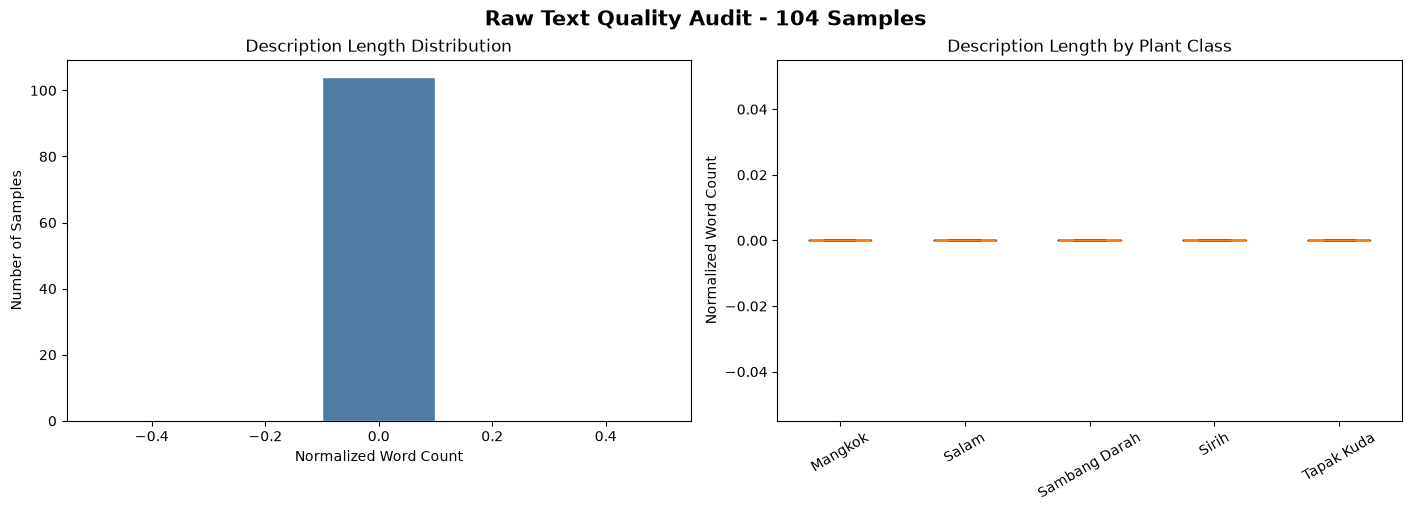

[SAVED] 201_raw_text_quality_audit.png


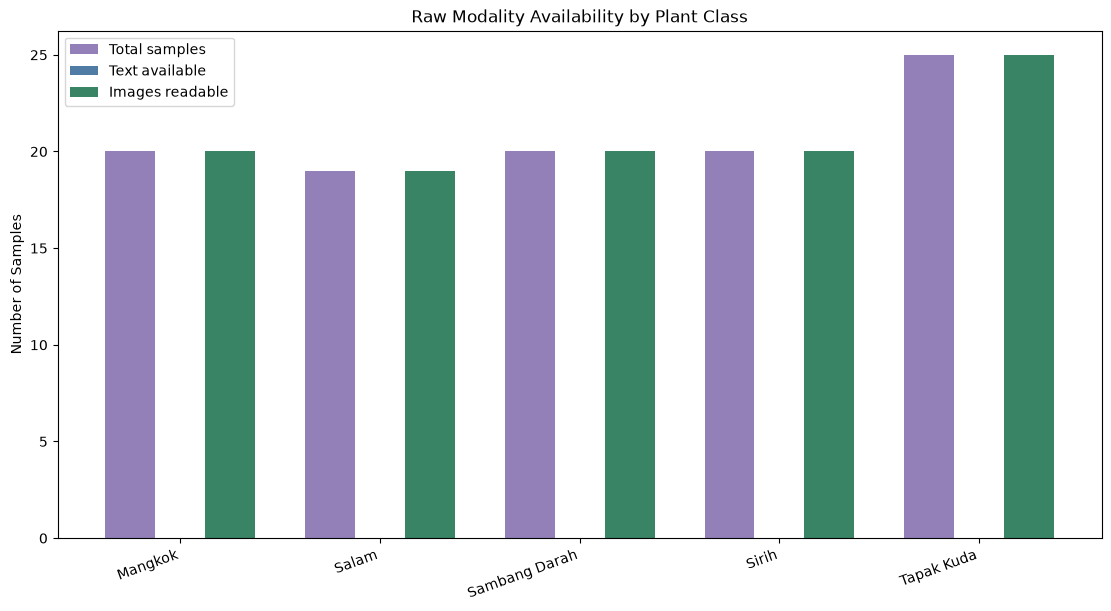

[SAVED] 202_raw_modality_availability.png

12. SAVING AUDIT REPORTS
---------------------------------------------------------------------------
[SAVED] 606_raw_text_column_inventory.csv
[SAVED] 607_raw_text_leakage_audit.csv
[SAVED] 608_raw_image_audit.csv
[SAVED] 609_raw_class_data_quality.csv
[SAVED] 610_raw_duplicate_findings.csv
[SAVED] 611_raw_near_duplicate_image_pairs.csv
[SAVED] 612_provisional_split_groups.csv
[SAVED] 613_leakage_risk_assessment.csv
[SAVED] 614_split_readiness.csv
[SAVED] 615_raw_audit_validation.csv
[SAVED] 616_raw_audit_overview.csv
[SAVED] 617_raw_image_column_inventory.csv
[SAVED] 618_raw_group_column_inventory.csv
[SAVED] 619_raw_data_audit_handoff.json

CELL 2 - RAW DATA AUDIT COMPLETED SUCCESSFULLY

DATA INVENTORY
---------------------------------------------------------------------------
Samples             : 104
Plant classes       : 5
Raw text column     : None
Raw image column    : processed_image_path
Group column        : None

TEXT AUDIT
--------

In [2]:
# ============================================================
# CELL 2 - RAW DATA AUDIT & LEAKAGE DETECTION
# Notebook: 06_multimodal_retrieval_evaluation.ipynb
# ============================================================

import re
import json
import hashlib
import unicodedata

from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageOps
from IPython.display import display


print("NOTEBOOK 06 - RAW DATA AUDIT & LEAKAGE DETECTION")
print("=" * 75)

EVAL06_RAW_DATA_AUDIT_COMPLETED = False
EVAL06_READY_FOR_SPLIT_PLANNING = False
EVAL06_LEAKAGE_SAFE_CONFIRMED = False


# ============================================================
# 1. VALIDATE PREVIOUS CELL
# ============================================================

assert globals().get(
    "EVAL06_SETUP_COMPLETED",
    False
) is True, (
    "Run Notebook 06 Cell 1 first."
)

assert EVAL06_SETUP_VALIDATION_DF[
    "passed"
].all()

EVAL06_AUDIT_IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".webp",
    ".bmp", ".tif", ".tiff"
}

EVAL06_NEAR_DUPLICATE_DHASH_THRESHOLD = 4

EVAL06_AUDIT_RECORDS = []
EVAL06_AUDIT_FIGURES = []


def eval06_audit_check(category, name, passed):

    EVAL06_AUDIT_RECORDS.append({
        "category": category,
        "validation_check": name,
        "passed": bool(passed),
        "status": (
            "Passed" if passed else "Failed"
        )
    })


def eval06_audit_save_figure(fig, filename):

    path = (
        EVAL06_FIGURES_DIR / filename
    )

    fig.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    EVAL06_AUDIT_FIGURES.append(path)

    plt.show()
    plt.close(fig)

    print("[SAVED]", filename)


# ============================================================
# 2. PREPARE RAW METADATA
# ============================================================

# Join by sample_id, never by an assumed row order.

index_df = EVAL06_GALLERY_INDEX_DF[
    [
        "matrix_row_index",
        "sample_id",
        "class_label"
    ]
].copy()

metadata_df = (
    EVAL06_GALLERY_METADATA_DF
    .copy()
)

metadata_df["sample_id"] = (
    metadata_df["sample_id"]
    .astype(str)
)

assert metadata_df[
    "sample_id"
].is_unique

# Avoid duplicate labels and row-index fields
# overriding the authoritative gallery index.

metadata_fields = metadata_df.drop(
    columns=[
        "matrix_row_index",
        "class_label"
    ],
    errors="ignore"
)

EVAL06_AUDIT_DATA_DF = index_df.merge(
    metadata_fields,
    on="sample_id",
    how="left",
    sort=False,
    validate="one_to_one",
    indicator=True
)

assert len(EVAL06_AUDIT_DATA_DF) == 104

assert EVAL06_AUDIT_DATA_DF[
    "_merge"
].eq("both").all()

EVAL06_AUDIT_DATA_DF = (
    EVAL06_AUDIT_DATA_DF
    .drop(columns="_merge")
    .sort_values("matrix_row_index")
    .reset_index(drop=True)
)

assert np.array_equal(
    EVAL06_AUDIT_DATA_DF[
        "sample_id"
    ].to_numpy(dtype=str),

    EVAL06_SAMPLE_IDS
)

eval06_audit_check(
    "Alignment",
    "All 104 metadata rows matched by sample_id",
    len(EVAL06_AUDIT_DATA_DF) == 104
)

eval06_audit_check(
    "Alignment",
    "Original gallery index order preserved",
    np.array_equal(
        EVAL06_AUDIT_DATA_DF[
            "matrix_row_index"
        ].to_numpy(),
        np.arange(104)
    )
)

print("\n1. RAW METADATA INVENTORY")
print("-" * 75)

print(
    "Dataset shape:",
    EVAL06_AUDIT_DATA_DF.shape
)

print(
    "Available columns:",
    EVAL06_AUDIT_DATA_DF.columns.tolist()
)

display(
    EVAL06_AUDIT_DATA_DF.head(5)
)


# ============================================================
# 3. DEFINE TEXT NORMALIZATION
# ============================================================

# This normalization is for audit comparisons only.
# It does NOT replace the text preprocessing
# pipeline that will be fitted in later cells.

def eval06_normalize_audit_text(value):

    if pd.isna(value):
        return ""

    text = str(value)

    text = unicodedata.normalize(
        "NFKC",
        text
    )

    text = text.casefold()

    text = re.sub(
        r"[^\w\s]",
        " ",
        text,
        flags=re.UNICODE
    )

    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    if text in {
        "",
        "nan",
        "none",
        "null",
        "na",
        "n a",
        "tidak ada",
        "unknown",
        "kosong"
    }:
        return ""

    return text


def eval06_text_hash(text):

    if not text:
        return ""

    return hashlib.sha256(
        text.encode("utf-8")
    ).hexdigest()


# ============================================================
# 4. DETECT POSSIBLE RAW TEXT COLUMNS
# ============================================================

text_candidates = list(
    EVAL06_TEXT_COLUMN_CANDIDATES
) + [
    "description_id",
    "description_en",
    "description_indonesia",
    "description_english",
    "deskripsi_indonesia",
    "deskripsi_inggris",
    "leaf_text",
    "text_content",
    "metadata_text",
    "caption",
    "deskripsi_ciri_daun",
    "karakteristik_daun",
]

available_column_map = {
    str(column).casefold(): column
    for column in EVAL06_AUDIT_DATA_DF.columns
}

available_text_columns = []

for candidate in text_candidates:

    matched = available_column_map.get(
        candidate.casefold()
    )

    if (
        matched is not None
        and matched not in available_text_columns
    ):
        available_text_columns.append(
            matched
        )


# Optional manual override:
#
# EVAL06_TEXT_COLUMN_OVERRIDE = "description"
#
# Define this variable before running Cell 2
# if your raw text is stored in another column.

text_override = globals().get(
    "EVAL06_TEXT_COLUMN_OVERRIDE",
    None
)

if text_override is not None:

    if text_override not in EVAL06_AUDIT_DATA_DF.columns:

        raise ValueError(
            "EVAL06_TEXT_COLUMN_OVERRIDE "
            f"does not exist: {text_override}"
        )


text_column_records = []

for column in available_text_columns:

    values = (
        EVAL06_AUDIT_DATA_DF[column]
        .map(eval06_normalize_audit_text)
    )

    lengths = values.map(
        lambda text: len(text.split())
    )

    valid = lengths.gt(0)

    text_column_records.append({
        "column": column,

        "nonempty_count": int(
            valid.sum()
        ),

        "coverage_percent": float(
            100 * valid.mean()
        ),

        "median_word_count": float(
            lengths[valid].median()
            if valid.any()
            else 0
        ),

        "unique_nonempty_texts": int(
            values[valid].nunique()
        )
    })


EVAL06_TEXT_COLUMN_INVENTORY_DF = pd.DataFrame(
    text_column_records,
    columns=[
        "column",
        "nonempty_count",
        "coverage_percent",
        "median_word_count",
        "unique_nonempty_texts"
    ]
)

if text_override is not None:

    EVAL06_TEXT_COLUMN = text_override

elif not EVAL06_TEXT_COLUMN_INVENTORY_DF.empty:

    # Select a likely text-description field
    # using actual coverage and text length.
    #
    # The selection is preliminary and must be
    # reviewed if multiple text fields exist.

    ranked_text_columns = (
        EVAL06_TEXT_COLUMN_INVENTORY_DF
        .sort_values(
            [
                "coverage_percent",
                "median_word_count",
                "unique_nonempty_texts"
            ],
            ascending=False,
            kind="stable"
        )
    )

    EVAL06_TEXT_COLUMN = (
        ranked_text_columns.iloc[0]["column"]
        if ranked_text_columns.iloc[0][
            "nonempty_count"
        ] > 0
        else None
    )

else:

    EVAL06_TEXT_COLUMN = None


print("\n2. RAW TEXT SOURCE AUDIT")
print("-" * 75)

print(
    "Selected text column:",
    EVAL06_TEXT_COLUMN
)

display(
    EVAL06_TEXT_COLUMN_INVENTORY_DF
)


# ============================================================
# 5. AUDIT TEXT QUALITY AND LABEL LEAKAGE
# ============================================================

text_audit_rows = []

for _, row in EVAL06_AUDIT_DATA_DF.iterrows():

    sample_id = str(
        row["sample_id"]
    )

    class_name = str(
        row["class_label"]
    )

    raw_text = (
        row[EVAL06_TEXT_COLUMN]
        if EVAL06_TEXT_COLUMN is not None
        else ""
    )

    normalized = eval06_normalize_audit_text(
        raw_text
    )

    label_normalized = (
        eval06_normalize_audit_text(
            class_name
        )
    )

    # Whole-word / full-phrase detection.
    #
    # A description explicitly naming its
    # plant class may leak the target label.

    label_mentioned = (
        bool(label_normalized)
        and (
            f" {label_normalized} "
            in f" {normalized} "
        )
    )

    word_count = len(
        normalized.split()
    )

    text_audit_rows.append({
        "matrix_row_index":
            int(row["matrix_row_index"]),

        "sample_id": sample_id,

        "class_label": class_name,

        "text_available":
            bool(normalized),

        "word_count": word_count,

        "character_count":
            len(normalized),

        "normalized_text":
            normalized,

        "text_sha256":
            eval06_text_hash(normalized),

        "own_class_name_mentioned":
            bool(label_mentioned),

        "very_short_text":
            bool(
                normalized and word_count < 4
            )
    })


EVAL06_TEXT_AUDIT_DF = pd.DataFrame(
    text_audit_rows
)

# Count repeated descriptions across all samples.

text_counts = (
    EVAL06_TEXT_AUDIT_DF.loc[
        EVAL06_TEXT_AUDIT_DF[
            "text_available"
        ],
        "text_sha256"
    ]
    .value_counts()
)

EVAL06_TEXT_AUDIT_DF[
    "duplicate_text_count"
] = (
    EVAL06_TEXT_AUDIT_DF[
        "text_sha256"
    ]
    .map(text_counts)
    .fillna(0)
    .astype(int)
)

EVAL06_TEXT_AUDIT_DF[
    "repeated_description"
] = (
    EVAL06_TEXT_AUDIT_DF[
        "duplicate_text_count"
    ] > 1
)

# Detect descriptions shared across classes.

cross_class_text_hashes = set()

for text_hash, subset in (
    EVAL06_TEXT_AUDIT_DF.loc[
        EVAL06_TEXT_AUDIT_DF[
            "text_available"
        ]
    ]
    .groupby("text_sha256")
):

    if subset["class_label"].nunique() > 1:

        cross_class_text_hashes.add(
            text_hash
        )

EVAL06_TEXT_AUDIT_DF[
    "description_shared_across_classes"
] = (
    EVAL06_TEXT_AUDIT_DF[
        "text_sha256"
    ]
    .isin(cross_class_text_hashes)
)

# Per-class text uniqueness.

class_text_records = []

for class_name, subset in (
    EVAL06_TEXT_AUDIT_DF.groupby(
        "class_label"
    )
):

    valid = subset.loc[
        subset["text_available"]
    ]

    unique_descriptions = int(
        valid["text_sha256"].nunique()
    )

    class_text_records.append({
        "class_name": class_name,

        "sample_count": len(subset),

        "text_available_count":
            len(valid),

        "unique_descriptions":
            unique_descriptions,

        "repeated_text_samples": int(
            subset[
                "repeated_description"
            ].sum()
        ),

        "label_mention_count": int(
            subset[
                "own_class_name_mentioned"
            ].sum()
        ),

        "class_level_template_suspected": bool(
            len(valid) > 1
            and unique_descriptions == 1
        )
    })


EVAL06_CLASS_TEXT_AUDIT_DF = pd.DataFrame(
    class_text_records
)

EVAL06_TEXT_MISSING_COUNT = int(
    (
        ~EVAL06_TEXT_AUDIT_DF[
            "text_available"
        ]
    ).sum()
)

EVAL06_TEXT_DUPLICATE_COUNT = int(
    EVAL06_TEXT_AUDIT_DF[
        "repeated_description"
    ].sum()
)

EVAL06_LABEL_MENTION_COUNT = int(
    EVAL06_TEXT_AUDIT_DF[
        "own_class_name_mentioned"
    ].sum()
)

EVAL06_CLASS_TEMPLATE_COUNT = int(
    EVAL06_CLASS_TEXT_AUDIT_DF[
        "class_level_template_suspected"
    ].sum()
)

print("\n3. TEXT LEAKAGE DIAGNOSTICS")
print("-" * 75)

print("Missing descriptions :", EVAL06_TEXT_MISSING_COUNT)
print("Repeated-text samples:", EVAL06_TEXT_DUPLICATE_COUNT)
print("Class-name mentions  :", EVAL06_LABEL_MENTION_COUNT)
print("Suspected class templates:", EVAL06_CLASS_TEMPLATE_COUNT)

display(
    EVAL06_CLASS_TEXT_AUDIT_DF
)


# ============================================================
# 6. DEFINE IMAGE PATH SEARCH ROOTS
# ============================================================

image_roots = []


def eval06_add_image_root(value):

    if value is None:
        return

    try:
        path = Path(value).expanduser()

    except (TypeError, ValueError):
        return

    if path not in image_roots:
        image_roots.append(path)


base = Path(
    EVAL06_PROJECT_ROOT
)

for path in [
    base,
    base / "data",
    base / "data" / "raw",
    base / "data" / "processed",
    base / "data" / "images",
    base / "data" / "processed_images",
    base / "images",
    base / "processed_images",
    base / "dataset",
    base / "dataset" / "images",
    base / "uploads",
]:

    eval06_add_image_root(path)


# Optional additional roots:
#
# EVAL06_IMAGE_SEARCH_ROOTS = [
#     r"D:\Project\Multimodal_Leaf_Retrieval\data\images"
# ]

for path in globals().get(
    "EVAL06_IMAGE_SEARCH_ROOTS",
    []
):

    eval06_add_image_root(path)


# ============================================================
# 7. DETECT AVAILABLE IMAGE PATH COLUMNS
# ============================================================

image_candidates = list(
    EVAL06_IMAGE_COLUMN_CANDIDATES
) + [
    "image_file",
    "image_filename",
    "original_image_path",
    "relative_path",
    "gambar",
    "nama_gambar",
]

available_image_columns = []

for candidate in image_candidates:

    matched = available_column_map.get(
        candidate.casefold()
    )

    if (
        matched is not None
        and matched not in available_image_columns
    ):

        available_image_columns.append(
            matched
        )


def eval06_resolve_image(value, class_name):

    if pd.isna(value):
        return None

    raw = str(value).strip()

    if not raw:
        return None

    if raw.lower().startswith((
        "http://",
        "https://"
    )):
        return None

    raw = raw.replace("\\", "/")

    candidate = Path(raw).expanduser()

    if candidate.suffix.lower() not in (
        EVAL06_AUDIT_IMAGE_EXTENSIONS
    ):
        return None

    possibilities = [candidate]

    class_variants = {
        str(class_name),
        str(class_name).lower(),
        str(class_name).replace(" ", "_"),
        str(class_name).replace(" ", "-"),
        str(class_name).lower().replace(" ", "_"),
    }

    for root in image_roots:

        possibilities.append(
            root / candidate
        )

        if len(candidate.parts) == 1:

            for folder in class_variants:

                possibilities.append(
                    root / folder / candidate
                )

    for path in possibilities:

        if path.is_file():

            return path.resolve()

    return None


image_column_records = []

for column in available_image_columns:

    nonempty = 0
    files_found = 0

    for _, row in EVAL06_AUDIT_DATA_DF.iterrows():

        value = row[column]

        if (
            pd.notna(value)
            and str(value).strip()
        ):
            nonempty += 1

        resolved = eval06_resolve_image(
            value,
            row["class_label"]
        )

        if resolved is not None:
            files_found += 1

    image_column_records.append({
        "column": column,
        "nonempty_count": nonempty,
        "files_found": files_found,
        "coverage_percent": float(
            100 * files_found / 104
        )
    })


EVAL06_IMAGE_COLUMN_INVENTORY_DF = pd.DataFrame(
    image_column_records,
    columns=[
        "column",
        "nonempty_count",
        "files_found",
        "coverage_percent"
    ]
)

image_override = globals().get(
    "EVAL06_IMAGE_COLUMN_OVERRIDE",
    None
)

if image_override is not None:

    if image_override not in (
        EVAL06_AUDIT_DATA_DF.columns
    ):

        raise ValueError(
            "Unknown image column override: "
            f"{image_override}"
        )

    EVAL06_IMAGE_COLUMN = (
        image_override
    )

elif not EVAL06_IMAGE_COLUMN_INVENTORY_DF.empty:

    ranked_image_columns = (
        EVAL06_IMAGE_COLUMN_INVENTORY_DF
        .sort_values(
            [
                "files_found",
                "nonempty_count"
            ],
            ascending=False,
            kind="stable"
        )
    )

    EVAL06_IMAGE_COLUMN = (
        ranked_image_columns.iloc[0][
            "column"
        ]
    )

else:

    EVAL06_IMAGE_COLUMN = None


print("\n4. RAW IMAGE SOURCE AUDIT")
print("-" * 75)

print(
    "Selected image column:",
    EVAL06_IMAGE_COLUMN
)

display(
    EVAL06_IMAGE_COLUMN_INVENTORY_DF
)


# ============================================================
# 8. IMAGE HASHING FUNCTIONS
# ============================================================

def eval06_file_sha256(path):

    digest = hashlib.sha256()

    with open(path, "rb") as file:

        for chunk in iter(
            lambda: file.read(
                1024 * 1024
            ),
            b""
        ):

            digest.update(chunk)

    return digest.hexdigest()


def eval06_image_dhash(image):
    """
    64-bit difference hash.

    Used only to flag possible near duplicates,
    not to automatically declare duplicates.
    """

    small = image.convert("L").resize(
        (9, 8),
        Image.Resampling.LANCZOS
    )

    pixels = np.asarray(
        small,
        dtype=np.int16
    )

    bits = (
        pixels[:, 1:]
        >
        pixels[:, :-1]
    ).ravel()

    result = 0

    for bit in bits:

        result = (
            (result << 1)
            | int(bit)
        )

    return result


# ============================================================
# 9. AUDIT IMAGE EXISTENCE AND CONTENT
# ============================================================

image_audit_rows = []

image_hash_ints = {}

for _, row in EVAL06_AUDIT_DATA_DF.iterrows():

    sample_id = str(
        row["sample_id"]
    )

    class_name = str(
        row["class_label"]
    )

    raw_value = (
        row[EVAL06_IMAGE_COLUMN]
        if EVAL06_IMAGE_COLUMN is not None
        else ""
    )

    resolved = eval06_resolve_image(
        raw_value,
        class_name
    )

    exists = resolved is not None

    readable = False

    file_hash = ""
    pixel_hash = ""
    dhash = None
    width = np.nan
    height = np.nan
    read_error = ""

    if exists:

        try:

            file_hash = eval06_file_sha256(
                resolved
            )

            with Image.open(resolved) as source:

                image = ImageOps.exif_transpose(
                    source
                ).convert("RGB")

                width, height = image.size

                pixel_digest = hashlib.sha256()

                pixel_digest.update(
                    f"{width}x{height}|".encode()
                )

                pixel_digest.update(
                    image.tobytes()
                )

                pixel_hash = (
                    pixel_digest.hexdigest()
                )

                dhash = eval06_image_dhash(
                    image
                )

                readable = True

                image_hash_ints[
                    sample_id
                ] = dhash

        except (
            OSError,
            ValueError,
            RuntimeError
        ) as error:

            read_error = str(error)

    image_audit_rows.append({
        "matrix_row_index":
            int(row["matrix_row_index"]),

        "sample_id":
            sample_id,

        "class_label":
            class_name,

        "raw_image_value":
            (
                ""
                if pd.isna(raw_value)
                else str(raw_value)
            ),

        "resolved_image_path":
            str(resolved) if exists else "",

        "image_found":
            exists,

        "image_readable":
            readable,

        "width":
            width,

        "height":
            height,

        "file_sha256":
            file_hash,

        "decoded_pixel_sha256":
            pixel_hash,

        "dhash_hex":
            (
                f"{dhash:016x}"
                if dhash is not None
                else ""
            ),

        "read_error":
            read_error
    })


EVAL06_IMAGE_AUDIT_DF = pd.DataFrame(
    image_audit_rows
)

EVAL06_IMAGES_FOUND = int(
    EVAL06_IMAGE_AUDIT_DF[
        "image_found"
    ].sum()
)

EVAL06_IMAGES_READABLE = int(
    EVAL06_IMAGE_AUDIT_DF[
        "image_readable"
    ].sum()
)

print("\n5. IMAGE AVAILABILITY AND CONTENT")
print("-" * 75)

print("Images found   :", EVAL06_IMAGES_FOUND)
print("Images readable:", EVAL06_IMAGES_READABLE)
print("Missing images :", 104 - EVAL06_IMAGES_FOUND)

display(
    EVAL06_IMAGE_AUDIT_DF[
        [
            "sample_id",
            "class_label",
            "image_found",
            "image_readable",
            "width",
            "height"
        ]
    ].head(10)
)


# ============================================================
# 10. DETECT EXACT DUPLICATE GROUPS
# ============================================================

duplicate_records = []


def eval06_collect_duplicate_groups(
    dataframe,
    value_column,
    duplicate_type
):

    valid = dataframe.loc[
        dataframe[value_column].astype(str).ne("")
    ]

    for value, group in valid.groupby(
        value_column
    ):

        if len(group) <= 1:
            continue

        duplicate_records.append({
            "duplicate_type":
                duplicate_type,

            "duplicate_key":
                str(value),

            "sample_count":
                len(group),

            "class_count":
                group["class_label"].nunique(),

            "class_labels":
                " | ".join(
                    sorted(
                        group[
                            "class_label"
                        ].unique()
                    )
                ),

            "sample_ids":
                " | ".join(
                    group["sample_id"].astype(str)
                ),

            "cross_class_collision":
                group[
                    "class_label"
                ].nunique() > 1
        })


eval06_collect_duplicate_groups(
    EVAL06_TEXT_AUDIT_DF,
    "text_sha256",
    "exact_normalized_text"
)

eval06_collect_duplicate_groups(
    EVAL06_IMAGE_AUDIT_DF,
    "file_sha256",
    "exact_image_file"
)

eval06_collect_duplicate_groups(
    EVAL06_IMAGE_AUDIT_DF,
    "decoded_pixel_sha256",
    "exact_decoded_pixels"
)

eval06_collect_duplicate_groups(
    EVAL06_IMAGE_AUDIT_DF,
    "resolved_image_path",
    "reused_image_path"
)

EVAL06_DUPLICATE_FINDINGS_DF = pd.DataFrame(
    duplicate_records,
    columns=[
        "duplicate_type",
        "duplicate_key",
        "sample_count",
        "class_count",
        "class_labels",
        "sample_ids",
        "cross_class_collision"
    ]
)


# ============================================================
# 11. DETECT POSSIBLE NEAR-DUPLICATE IMAGES
# ============================================================

# Near duplicates are warnings for manual review.
#
# Similar-looking leaves can legitimately produce
# similar perceptual hashes. Therefore, this code
# does not automatically merge them into split groups.

near_duplicate_records = []

readable_rows = (
    EVAL06_IMAGE_AUDIT_DF.loc[
        EVAL06_IMAGE_AUDIT_DF[
            "image_readable"
        ]
    ]
    .reset_index(drop=True)
)

for i in range(
    len(readable_rows)
):

    for j in range(
        i + 1,
        len(readable_rows)
    ):

        first = readable_rows.iloc[i]
        second = readable_rows.iloc[j]

        first_id = str(
            first["sample_id"]
        )

        second_id = str(
            second["sample_id"]
        )

        distance = (
            image_hash_ints[first_id]
            ^
            image_hash_ints[second_id]
        ).bit_count()

        if (
            distance
            <= EVAL06_NEAR_DUPLICATE_DHASH_THRESHOLD
        ):

            same_pixels = bool(
                first["decoded_pixel_sha256"]
                ==
                second["decoded_pixel_sha256"]
            )

            # Already identical files/pixels need
            # no separate near-duplicate warning.

            if same_pixels:
                continue

            near_duplicate_records.append({
                "sample_id_i": first_id,

                "sample_id_j": second_id,

                "class_i":
                    first["class_label"],

                "class_j":
                    second["class_label"],

                "same_class":
                    first["class_label"]
                    == second["class_label"],

                "dhash_hamming_distance":
                    int(distance),

                "manual_review_required":
                    True
            })


EVAL06_NEAR_DUPLICATE_DF = pd.DataFrame(
    near_duplicate_records,
    columns=[
        "sample_id_i",
        "sample_id_j",
        "class_i",
        "class_j",
        "same_class",
        "dhash_hamming_distance",
        "manual_review_required"
    ]
)

print("\n6. DUPLICATE AND NEAR-DUPLICATE FINDINGS")
print("-" * 75)

print(
    "Exact duplicate groups:",
    len(EVAL06_DUPLICATE_FINDINGS_DF)
)

print(
    "Potential near-duplicate image pairs:",
    len(EVAL06_NEAR_DUPLICATE_DF)
)

display(
    EVAL06_DUPLICATE_FINDINGS_DF.head(15)
)

display(
    EVAL06_NEAR_DUPLICATE_DF.head(15)
)


# ============================================================
# 12. AUDIT AVAILABLE GROUP IDENTIFIERS
# ============================================================

group_candidates = list(
    EVAL06_GROUP_COLUMN_CANDIDATES
) + [
    "specimen_id",
    "leaf_id",
    "capture_id",
    "photo_session_id",
    "original_photo_id"
]

available_group_columns = []

for candidate in group_candidates:

    matched = available_column_map.get(
        candidate.casefold()
    )

    if (
        matched is not None
        and matched not in available_group_columns
    ):

        available_group_columns.append(
            matched
        )


group_override = globals().get(
    "EVAL06_GROUP_COLUMN_OVERRIDE",
    None
)

if group_override is not None:

    if group_override not in (
        EVAL06_AUDIT_DATA_DF.columns
    ):

        raise ValueError(
            "Unknown group column override: "
            f"{group_override}"
        )

    EVAL06_GROUP_COLUMN = (
        group_override
    )

elif available_group_columns:

    EVAL06_GROUP_COLUMN = (
        available_group_columns[0]
    )

else:

    EVAL06_GROUP_COLUMN = None


def eval06_group_value(value):

    if pd.isna(value):
        return ""

    value = str(value).strip()

    if value.casefold() in {
        "", "nan", "none", "null"
    }:

        return ""

    return value


if EVAL06_GROUP_COLUMN is not None:

    declared_groups = (
        EVAL06_AUDIT_DATA_DF[
            EVAL06_GROUP_COLUMN
        ]
        .map(eval06_group_value)
    )

else:

    declared_groups = pd.Series(
        [""] * 104
    )


group_column_records = []

for column in available_group_columns:

    values = (
        EVAL06_AUDIT_DATA_DF[column]
        .map(eval06_group_value)
    )

    group_column_records.append({
        "column": column,

        "nonempty_count":
            int(values.ne("").sum()),

        "unique_group_count":
            int(
                values.loc[
                    values.ne("")
                ].nunique()
            )
    })


EVAL06_GROUP_COLUMN_INVENTORY_DF = pd.DataFrame(
    group_column_records,
    columns=[
        "column",
        "nonempty_count",
        "unique_group_count"
    ]
)

# A credible grouping field should provide
# multiple independent group IDs within each
# class. A class label disguised as a group ID
# is not suitable for three-way splitting.

if EVAL06_GROUP_COLUMN is not None:

    group_probe = pd.DataFrame({
        "class_label":
            EVAL06_LABELS,

        "declared_group":
            declared_groups.to_numpy()
    })

    groups_per_class = (
        group_probe.loc[
            group_probe[
                "declared_group"
            ].ne("")
        ]
        .groupby("class_label")[
            "declared_group"
        ]
        .nunique()
        .reindex(
            EVAL06_CLASSES,
            fill_value=0
        )
    )

    EVAL06_DECLARED_GROUP_PLAUSIBLE = bool(
        groups_per_class.ge(3).all()
    )

else:

    EVAL06_DECLARED_GROUP_PLAUSIBLE = False


print("\n7. GROUP IDENTIFIER AUDIT")
print("-" * 75)

print(
    "Selected group column:",
    EVAL06_GROUP_COLUMN
)

print(
    "Usable for provisional grouping:",
    EVAL06_DECLARED_GROUP_PLAUSIBLE
)

display(
    EVAL06_GROUP_COLUMN_INVENTORY_DF
)


# ============================================================
# 13. BUILD PROVISIONAL NON-LEAKING SPLIT GROUPS
# ============================================================

# Union-find groups samples that definitely
# refer to the same raw image, based on:
#
# 1. exact file hashes
# 2. exact decoded pixel hashes
# 3. credible specimen/capture IDs, if available
#
# Repeated text is NOT used for automatic grouping:
# identical class descriptions may be templates
# rather than duplicated physical observations.

parent = list(
    range(104)
)


def eval06_find_group(x):

    while parent[x] != x:

        parent[x] = parent[
            parent[x]
        ]

        x = parent[x]

    return x


def eval06_union_group(a, b):

    ra = eval06_find_group(a)
    rb = eval06_find_group(b)

    if ra != rb:

        parent[max(ra, rb)] = min(
            ra,
            rb
        )


def eval06_union_matching_values(
    values
):

    seen = {}

    for index, value in enumerate(values):

        if (
            pd.isna(value)
            or str(value).strip() == ""
        ):
            continue

        value = str(value)

        if value in seen:

            eval06_union_group(
                index,
                seen[value]
            )

        else:

            seen[value] = index


eval06_union_matching_values(
    EVAL06_IMAGE_AUDIT_DF[
        "file_sha256"
    ]
)

eval06_union_matching_values(
    EVAL06_IMAGE_AUDIT_DF[
        "decoded_pixel_sha256"
    ]
)

if EVAL06_DECLARED_GROUP_PLAUSIBLE:

    eval06_union_matching_values(
        declared_groups
    )


# Normalize group labels to stable IDs.

group_roots = [
    eval06_find_group(i)
    for i in range(104)
]

unique_roots = sorted(
    set(group_roots)
)

root_to_group_id = {
    root: f"group_{i:03d}"
    for i, root in enumerate(
        unique_roots
    )
}

EVAL06_PROVISIONAL_GROUP_IDS = [
    root_to_group_id[root]
    for root in group_roots
]

EVAL06_SPLIT_GROUPS_DF = pd.DataFrame({
    "matrix_row_index":
        np.arange(104),

    "sample_id":
        EVAL06_SAMPLE_IDS,

    "class_label":
        EVAL06_LABELS,

    "provisional_group_id":
        EVAL06_PROVISIONAL_GROUP_IDS,

    "declared_group_id":
        declared_groups.to_numpy()
})

group_sizes = (
    EVAL06_SPLIT_GROUPS_DF[
        "provisional_group_id"
    ]
    .value_counts()
)

EVAL06_SPLIT_GROUPS_DF[
    "provisional_group_size"
] = (
    EVAL06_SPLIT_GROUPS_DF[
        "provisional_group_id"
    ]
    .map(group_sizes)
)

group_counts_per_class = (
    EVAL06_SPLIT_GROUPS_DF
    .groupby("class_label")[
        "provisional_group_id"
    ]
    .nunique()
)

EVAL06_SPLIT_GROUP_FEASIBLE = bool(
    group_counts_per_class.ge(3).all()
)

print("\n8. PROVISIONAL SPLIT GROUPS")
print("-" * 75)

print(
    "Total provisional groups:",
    len(unique_roots)
)

print(
    "Samples in multi-sample groups:",
    int(
        EVAL06_SPLIT_GROUPS_DF[
            "provisional_group_size"
        ].gt(1).sum()
    )
)

print(
    "At least three groups per class:",
    EVAL06_SPLIT_GROUP_FEASIBLE
)

display(
    EVAL06_SPLIT_GROUPS_DF.head(12)
)


# ============================================================
# 14. BUILD PER-CLASS DATA QUALITY SUMMARY
# ============================================================

class_quality_rows = []

for class_name in EVAL06_CLASSES:

    text_part = (
        EVAL06_TEXT_AUDIT_DF.loc[
            EVAL06_TEXT_AUDIT_DF[
                "class_label"
            ] == class_name
        ]
    )

    image_part = (
        EVAL06_IMAGE_AUDIT_DF.loc[
            EVAL06_IMAGE_AUDIT_DF[
                "class_label"
            ] == class_name
        ]
    )

    class_quality_rows.append({
        "class_name": class_name,

        "sample_count":
            len(text_part),

        "text_available":
            int(
                text_part[
                    "text_available"
                ].sum()
            ),

        "unique_text_descriptions":
            int(
                text_part.loc[
                    text_part[
                        "text_available"
                    ],
                    "text_sha256"
                ].nunique()
            ),

        "class_name_mentioned_in_text":
            int(
                text_part[
                    "own_class_name_mentioned"
                ].sum()
            ),

        "images_found":
            int(
                image_part[
                    "image_found"
                ].sum()
            ),

        "images_readable":
            int(
                image_part[
                    "image_readable"
                ].sum()
            ),

        "provisional_split_groups":
            int(
                group_counts_per_class[
                    class_name
                ]
            )
    })


EVAL06_CLASS_DATA_QUALITY_DF = pd.DataFrame(
    class_quality_rows
)

print("\n9. PER-CLASS DATA QUALITY")
print("-" * 75)

display(
    EVAL06_CLASS_DATA_QUALITY_DF
)


# ============================================================
# 15. ASSESS LEAKAGE RISKS
# ============================================================

EVAL06_CROSS_CLASS_TEXT_COLLISIONS = int(
    EVAL06_TEXT_AUDIT_DF[
        "description_shared_across_classes"
    ].sum()
)

image_collision_df = (
    EVAL06_DUPLICATE_FINDINGS_DF.loc[
        EVAL06_DUPLICATE_FINDINGS_DF[
            "duplicate_type"
        ].isin([
            "exact_image_file",
            "exact_decoded_pixels",
            "reused_image_path"
        ])
        &
        EVAL06_DUPLICATE_FINDINGS_DF[
            "cross_class_collision"
        ]
    ]
)

EVAL06_CROSS_CLASS_IMAGE_COLLISIONS = len(
    image_collision_df
)

EVAL06_NEAR_DUPLICATE_PAIR_COUNT = len(
    EVAL06_NEAR_DUPLICATE_DF
)

risk_records = [
    {
        "risk": "Missing raw text descriptions",
        "severity": "High",
        "finding_count": EVAL06_TEXT_MISSING_COUNT,
        "requires_review": EVAL06_TEXT_MISSING_COUNT > 0,
        "recommended_action":
            "Locate complete raw text before splitting."
    },
    {
        "risk": "Missing/unreadable image files",
        "severity": "High",
        "finding_count": 104 - EVAL06_IMAGES_READABLE,
        "requires_review": EVAL06_IMAGES_READABLE < 104,
        "recommended_action":
            "Repair raw image paths and unreadable files."
    },
    {
        "risk": "Target class name inside description",
        "severity": "High",
        "finding_count": EVAL06_LABEL_MENTION_COUNT,
        "requires_review": EVAL06_LABEL_MENTION_COUNT > 0,
        "recommended_action":
            "Review and exclude direct class-name clues."
    },
    {
        "risk": "Single repeated description within class",
        "severity": "High",
        "finding_count": EVAL06_CLASS_TEMPLATE_COUNT,
        "requires_review": EVAL06_CLASS_TEMPLATE_COUNT > 0,
        "recommended_action":
            "Review whether text is class-template metadata rather than sample-specific information."
    },
    {
        "risk": "Exact text shared across different classes",
        "severity": "Medium",
        "finding_count": EVAL06_CROSS_CLASS_TEXT_COLLISIONS,
        "requires_review": EVAL06_CROSS_CLASS_TEXT_COLLISIONS > 0,
        "recommended_action":
            "Review ambiguous or copied descriptions."
    },
    {
        "risk": "Identical image associated with different classes",
        "severity": "High",
        "finding_count": EVAL06_CROSS_CLASS_IMAGE_COLLISIONS,
        "requires_review": EVAL06_CROSS_CLASS_IMAGE_COLLISIONS > 0,
        "recommended_action":
            "Resolve image-label conflicts."
    },
    {
        "risk": "Possible near-duplicate images",
        "severity": "Medium",
        "finding_count": EVAL06_NEAR_DUPLICATE_PAIR_COUNT,
        "requires_review": EVAL06_NEAR_DUPLICATE_PAIR_COUNT > 0,
        "recommended_action":
            "Manually review perceptual-hash matches before splitting."
    },
    {
        "risk": "Insufficient split groups per class",
        "severity": "High",
        "finding_count": int(
            (
                group_counts_per_class < 3
            ).sum()
        ),
        "requires_review": not EVAL06_SPLIT_GROUP_FEASIBLE,
        "recommended_action":
            "Reconsider split ratios or gather independent groups."
    }
]

EVAL06_LEAKAGE_FINDINGS_DF = pd.DataFrame(
    risk_records
)


# ============================================================
# 16. DETERMINE SPLIT READINESS
# ============================================================

raw_text_complete = (
    EVAL06_TEXT_COLUMN is not None
    and EVAL06_TEXT_MISSING_COUNT == 0
)

raw_images_complete = (
    EVAL06_IMAGES_READABLE == 104
)

critical_text_risk = (
    EVAL06_LABEL_MENTION_COUNT > 0
    or EVAL06_CLASS_TEMPLATE_COUNT > 0
)

critical_image_risk = (
    EVAL06_CROSS_CLASS_IMAGE_COLLISIONS > 0
)

near_duplicates_need_review = (
    EVAL06_NEAR_DUPLICATE_PAIR_COUNT > 0
)

EVAL06_READY_FOR_SPLIT_PLANNING = bool(
    raw_text_complete
    and raw_images_complete
    and not critical_text_risk
    and not critical_image_risk
    and not near_duplicates_need_review
    and EVAL06_SPLIT_GROUP_FEASIBLE
)

# Metadata-level checks alone cannot certify
# that all upstream preprocessing is leakage-free.
# This requires examining fitting procedures
# in the feature extraction notebooks.

EVAL06_LEAKAGE_SAFE_CONFIRMED = False

if EVAL06_READY_FOR_SPLIT_PLANNING:

    EVAL06_SPLIT_READINESS_STATUS = (
        "READY_FOR_SPLIT_PLANNING"
    )

else:

    EVAL06_SPLIT_READINESS_STATUS = (
        "REQUIRES_DATA_OR_LEAKAGE_REVIEW"
    )


EVAL06_READINESS_DF = pd.DataFrame([
    (
        "Raw text complete",
        raw_text_complete
    ),
    (
        "All images readable",
        raw_images_complete
    ),
    (
        "No explicit target label detected",
        EVAL06_LABEL_MENTION_COUNT == 0
    ),
    (
        "No class-level text template detected",
        EVAL06_CLASS_TEMPLATE_COUNT == 0
    ),
    (
        "No cross-class identical image conflict",
        EVAL06_CROSS_CLASS_IMAGE_COLLISIONS == 0
    ),
    (
        "No outstanding near-duplicate image pairs",
        not near_duplicates_need_review
    ),
    (
        "At least three provisional groups per class",
        EVAL06_SPLIT_GROUP_FEASIBLE
    ),
    (
        "Ready for split planning",
        EVAL06_READY_FOR_SPLIT_PLANNING
    ),
    (
        "Upstream preprocessing leakage-free confirmed",
        EVAL06_LEAKAGE_SAFE_CONFIRMED
    )
], columns=[
    "criterion",
    "passed"
])


print("\n10. LEAKAGE RISK ASSESSMENT")
print("-" * 75)

display(
    EVAL06_LEAKAGE_FINDINGS_DF
)

print("\n11. SPLIT READINESS")
print("-" * 75)

display(
    EVAL06_READINESS_DF
)

print(
    "Status:",
    EVAL06_SPLIT_READINESS_STATUS
)


# ============================================================
# 17. VALIDATE AUDIT CALCULATIONS
# ============================================================

eval06_audit_check(
    "Text",
    "104 text audit records",
    len(EVAL06_TEXT_AUDIT_DF) == 104
)

eval06_audit_check(
    "Images",
    "104 image audit records",
    len(EVAL06_IMAGE_AUDIT_DF) == 104
)

eval06_audit_check(
    "Grouping",
    "104 provisional group assignments",
    len(EVAL06_SPLIT_GROUPS_DF) == 104
)

eval06_audit_check(
    "Grouping",
    "Every sample assigned one group",
    EVAL06_SPLIT_GROUPS_DF[
        "provisional_group_id"
    ].notna().all()
)

eval06_audit_check(
    "Classes",
    "Five class-level audit records",
    len(EVAL06_CLASS_DATA_QUALITY_DF) == 5
)

eval06_audit_check(
    "Integrity",
    "Text audit preserves sample order",
    np.array_equal(
        EVAL06_TEXT_AUDIT_DF[
            "sample_id"
        ].to_numpy(dtype=str),

        EVAL06_SAMPLE_IDS
    )
)

eval06_audit_check(
    "Integrity",
    "Image audit preserves sample order",
    np.array_equal(
        EVAL06_IMAGE_AUDIT_DF[
            "sample_id"
        ].to_numpy(dtype=str),

        EVAL06_SAMPLE_IDS
    )
)

# Confirm exact-image duplicates receive
# the same provisional split group.

hash_group_consistent = True

for hash_col in [
    "file_sha256",
    "decoded_pixel_sha256"
]:

    probe = (
        EVAL06_IMAGE_AUDIT_DF[
            ["sample_id", hash_col]
        ]
        .merge(
            EVAL06_SPLIT_GROUPS_DF[
                [
                    "sample_id",
                    "provisional_group_id"
                ]
            ],
            on="sample_id",
            validate="one_to_one"
        )
    )

    probe = probe.loc[
        probe[hash_col].ne("")
    ]

    if (
        probe.groupby(hash_col)[
            "provisional_group_id"
        ].nunique() > 1
    ).any():

        hash_group_consistent = False

eval06_audit_check(
    "Grouping",
    "Identical images share the same split group",
    hash_group_consistent
)

# Do not treat missing source files or detected
# leakage as calculation errors.
#
# Those findings determine readiness, not
# whether the audit itself executed correctly.


# ============================================================
# 18. FIGURE 201 - TEXT LENGTH DISTRIBUTION
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    constrained_layout=True
)

word_counts = (
    EVAL06_TEXT_AUDIT_DF[
        "word_count"
    ].to_numpy()
)

axes[0].hist(
    word_counts,
    bins=min(
        20,
        max(
            5,
            len(np.unique(word_counts))
        )
    ),
    color="#507BA5",
    edgecolor="white"
)

axes[0].set_title(
    "Description Length Distribution"
)

axes[0].set_xlabel(
    "Normalized Word Count"
)

axes[0].set_ylabel(
    "Number of Samples"
)

box_data = [
    EVAL06_TEXT_AUDIT_DF.loc[
        EVAL06_TEXT_AUDIT_DF[
            "class_label"
        ] == class_name,

        "word_count"
    ].to_numpy()

    for class_name in EVAL06_CLASSES
]

axes[1].boxplot(
    box_data,
    tick_labels=EVAL06_CLASSES,
    patch_artist=False
)

axes[1].set_title(
    "Description Length by Plant Class"
)

axes[1].set_ylabel(
    "Normalized Word Count"
)

axes[1].tick_params(
    axis="x",
    labelrotation=30
)

fig.suptitle(
    "Raw Text Quality Audit - 104 Samples",
    fontsize=15,
    fontweight="bold"
)

eval06_audit_save_figure(
    fig,
    "201_raw_text_quality_audit.png"
)


# ============================================================
# 19. FIGURE 202 - PER-CLASS DATA AVAILABILITY
# ============================================================

fig, ax = plt.subplots(
    figsize=(11, 6),
    constrained_layout=True
)

positions = np.arange(
    len(EVAL06_CLASSES)
)

width = 0.25

class_quality_plot = (
    EVAL06_CLASS_DATA_QUALITY_DF
    .set_index("class_name")
    .loc[EVAL06_CLASSES]
)

for offset, column, label, color in [
    (
        -width,
        "sample_count",
        "Total samples",
        "#9480B8"
    ),
    (
        0,
        "text_available",
        "Text available",
        "#507BA5"
    ),
    (
        width,
        "images_readable",
        "Images readable",
        "#398464"
    )
]:

    ax.bar(
        positions + offset,
        class_quality_plot[column],
        width=width,
        color=color,
        label=label
    )

ax.set_xticks(
    positions
)

ax.set_xticklabels(
    EVAL06_CLASSES,
    rotation=20,
    ha="right"
)

ax.set_ylabel(
    "Number of Samples"
)

ax.set_title(
    "Raw Modality Availability by Plant Class"
)

ax.legend()

eval06_audit_save_figure(
    fig,
    "202_raw_modality_availability.png"
)


# ============================================================
# 20. CREATE FINAL AUDIT OVERVIEW
# ============================================================

EVAL06_RAW_AUDIT_OVERVIEW_DF = pd.DataFrame([
    ("Dataset samples", 104),
    ("Plant classes", 5),
    ("Selected text column", EVAL06_TEXT_COLUMN),
    ("Selected image column", EVAL06_IMAGE_COLUMN),
    ("Selected group column", EVAL06_GROUP_COLUMN),
    ("Missing descriptions", EVAL06_TEXT_MISSING_COUNT),
    ("Repeated-text samples", EVAL06_TEXT_DUPLICATE_COUNT),
    ("Explicit class-name mentions", EVAL06_LABEL_MENTION_COUNT),
    ("Suspected class-level text templates", EVAL06_CLASS_TEMPLATE_COUNT),
    ("Images found", EVAL06_IMAGES_FOUND),
    ("Images readable", EVAL06_IMAGES_READABLE),
    ("Exact duplicate groups", len(EVAL06_DUPLICATE_FINDINGS_DF)),
    ("Possible near-duplicate pairs", EVAL06_NEAR_DUPLICATE_PAIR_COUNT),
    ("Provisional split groups", len(unique_roots)),
    ("Group-aware split appears feasible", EVAL06_SPLIT_GROUP_FEASIBLE),
    ("Ready for split planning", EVAL06_READY_FOR_SPLIT_PLANNING),
    ("Upstream leakage safety confirmed", False),
    ("Readiness status", EVAL06_SPLIT_READINESS_STATUS),
], columns=[
    "indicator",
    "result"
])


# ============================================================
# 21. SAVE AUDIT REPORTS
# ============================================================

EVAL06_AUDIT_VALIDATION_DF = pd.DataFrame(
    EVAL06_AUDIT_RECORDS
)

audit_reports = {
    "606_raw_text_column_inventory.csv":
        EVAL06_TEXT_COLUMN_INVENTORY_DF,

    "607_raw_text_leakage_audit.csv":
        EVAL06_TEXT_AUDIT_DF,

    "608_raw_image_audit.csv":
        EVAL06_IMAGE_AUDIT_DF,

    "609_raw_class_data_quality.csv":
        EVAL06_CLASS_DATA_QUALITY_DF,

    "610_raw_duplicate_findings.csv":
        EVAL06_DUPLICATE_FINDINGS_DF,

    "611_raw_near_duplicate_image_pairs.csv":
        EVAL06_NEAR_DUPLICATE_DF,

    "612_provisional_split_groups.csv":
        EVAL06_SPLIT_GROUPS_DF,

    "613_leakage_risk_assessment.csv":
        EVAL06_LEAKAGE_FINDINGS_DF,

    "614_split_readiness.csv":
        EVAL06_READINESS_DF,

    "615_raw_audit_validation.csv":
        EVAL06_AUDIT_VALIDATION_DF,

    "616_raw_audit_overview.csv":
        EVAL06_RAW_AUDIT_OVERVIEW_DF,

    "617_raw_image_column_inventory.csv":
        EVAL06_IMAGE_COLUMN_INVENTORY_DF,

    "618_raw_group_column_inventory.csv":
        EVAL06_GROUP_COLUMN_INVENTORY_DF,
}

print("\n12. SAVING AUDIT REPORTS")
print("-" * 75)

for filename, dataframe in audit_reports.items():

    path = EVAL06_METRICS_DIR / filename

    dataframe.to_csv(
        path,
        index=False,
        encoding="utf-8-sig"
    )

    print("[SAVED]", filename)


# ============================================================
# 22. SAVE AUDIT HANDOFF JSON
# ============================================================

EVAL06_AUDIT_HANDOFF = {
    "notebook":
        "06_multimodal_retrieval_evaluation.ipynb",

    "cell":
        2,

    "sample_count":
        104,

    "class_count":
        5,

    "text_column":
        EVAL06_TEXT_COLUMN,

    "image_column":
        EVAL06_IMAGE_COLUMN,

    "group_column":
        EVAL06_GROUP_COLUMN,

    "text_missing_count":
        EVAL06_TEXT_MISSING_COUNT,

    "images_readable_count":
        EVAL06_IMAGES_READABLE,

    "target_label_mention_count":
        EVAL06_LABEL_MENTION_COUNT,

    "suspected_class_template_count":
        EVAL06_CLASS_TEMPLATE_COUNT,

    "exact_duplicate_group_count":
        len(EVAL06_DUPLICATE_FINDINGS_DF),

    "potential_near_duplicate_pair_count":
        EVAL06_NEAR_DUPLICATE_PAIR_COUNT,

    "provisional_group_count":
        len(unique_roots),

    "ready_for_split_planning":
        EVAL06_READY_FOR_SPLIT_PLANNING,

    "upstream_leakage_safe_confirmed":
        False,

    "readiness_status":
        EVAL06_SPLIT_READINESS_STATUS,

    "important_policy": (
        "Do not use full-gallery TF-IDF or "
        "globally fitted visual scaling "
        "for independent test evaluation."
    ),

    "next_cell":
        "Cell 3 - Group-Aware Dataset Splitting"
}

EVAL06_AUDIT_HANDOFF_PATH = (
    EVAL06_METRICS_DIR
    / "619_raw_data_audit_handoff.json"
)

EVAL06_AUDIT_HANDOFF_PATH.write_text(
    json.dumps(
        EVAL06_AUDIT_HANDOFF,
        ensure_ascii=False,
        indent=2,
        allow_nan=False
    ),
    encoding="utf-8"
)

print(
    "[SAVED]",
    EVAL06_AUDIT_HANDOFF_PATH.name
)


# ============================================================
# 23. FINAL COMPLETION CHECKS
# ============================================================

assert EVAL06_AUDIT_VALIDATION_DF[
    "passed"
].all(), (
    EVAL06_AUDIT_VALIDATION_DF.loc[
        ~EVAL06_AUDIT_VALIDATION_DF[
            "passed"
        ]
    ].to_string(index=False)
)

assert len(EVAL06_AUDIT_FIGURES) == 2

assert all(
    path.is_file()
    and path.stat().st_size > 0
    for path in EVAL06_AUDIT_FIGURES
)

assert all(
    (EVAL06_METRICS_DIR / filename).is_file()
    for filename in audit_reports
)

assert EVAL06_AUDIT_HANDOFF_PATH.is_file()

EVAL06_RAW_DATA_AUDIT_COMPLETED = True


# ============================================================
# 24. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 75)

print("CELL 2 - RAW DATA AUDIT COMPLETED SUCCESSFULLY")

print("=" * 75)

print("\nDATA INVENTORY")
print("-" * 75)

print("Samples             :", 104)
print("Plant classes       :", 5)
print("Raw text column     :", EVAL06_TEXT_COLUMN)
print("Raw image column    :", EVAL06_IMAGE_COLUMN)
print("Group column        :", EVAL06_GROUP_COLUMN)

print("\nTEXT AUDIT")
print("-" * 75)

print("Missing descriptions:", EVAL06_TEXT_MISSING_COUNT)
print("Repeated text rows  :", EVAL06_TEXT_DUPLICATE_COUNT)
print("Label mentions      :", EVAL06_LABEL_MENTION_COUNT)
print("Class-level templates:", EVAL06_CLASS_TEMPLATE_COUNT)

print("\nIMAGE AUDIT")
print("-" * 75)

print("Images found        :", EVAL06_IMAGES_FOUND)
print("Images readable     :", EVAL06_IMAGES_READABLE)
print("Near-duplicate pairs:", EVAL06_NEAR_DUPLICATE_PAIR_COUNT)

print("\nSPLIT READINESS")
print("-" * 75)

print(
    "Provisional groups  :",
    len(unique_roots)
)

print(
    "Ready for planning :",
    EVAL06_READY_FOR_SPLIT_PLANNING
)

print(
    "Readiness status   :",
    EVAL06_SPLIT_READINESS_STATUS
)

print("\nOUTPUTS")
print("-" * 75)

print("CSV reports         :", len(audit_reports))
print("Figures             :", len(EVAL06_AUDIT_FIGURES))
print("JSON handoff        : 1")

print(
    "Technical checks    :",
    f"{int(EVAL06_AUDIT_VALIDATION_DF['passed'].sum())}/"
    f"{len(EVAL06_AUDIT_VALIDATION_DF)}"
)

print("\n[PASS] Dataset sample alignment checked.")
print("[PASS] Raw text availability audited.")
print("[PASS] Explicit label clues examined.")
print("[PASS] Repeated class descriptions examined.")
print("[PASS] Image file integrity audited.")
print("[PASS] Exact and near-duplicate images examined.")
print("[PASS] Provisional split groups created.")
print("[PASS] Leakage risk report generated.")

if not EVAL06_READY_FOR_SPLIT_PLANNING:

    print(
        "\n[WARNING] Review detected data or leakage "
        "issues before committing a dataset split."
    )

else:

    print(
        "\n[INFO] Data appears suitable for "
        "split planning, pending upstream "
        "preprocessing verification."
    )

print(
    "\n[INFO] No gallery/validation/test split "
    "has been created."
)

print(
    "[INFO] No independent evaluation "
    "has been performed."
)

print("\n" + "=" * 75)

print("NOTEBOOK 06 - CELL 2 COMPLETED")

print("=" * 75)

print(
    "\nNext cell: "
    "Cell 3 - Group-Aware Dataset Splitting"
)

NOTEBOOK 06 - GROUP-AWARE DATASET SPLITTING

1. INPUT DATA
------------------------------------------------------------------------
Samples: 104
Classes: 5
Requested ratios: {'gallery': 0.6, 'validation': 0.2, 'test': 0.2}

2. ATOMIC GROUP INVENTORY
------------------------------------------------------------------------
Total groups: 104
Largest group size: 1
Mixed-label groups: 0

3. SPLIT CLASS DISTRIBUTION
------------------------------------------------------------------------


split,gallery,validation,test,total
class_label,,,,
Mangkok,12,4,4,20
Salam,11,4,4,19
Sambang Darah,12,4,4,20
Sirih,12,4,4,20
Tapak Kuda,15,5,5,25



4. TARGET VS ACTUAL SPLIT RATIOS
------------------------------------------------------------------------


,split,target_ratio,target_sample_count,actual_sample_count,actual_ratio,ratio_deviation
0,gallery,0.6,62.4,62,0.5962,-0.0038
1,validation,0.2,20.8,21,0.2019,0.0019
2,test,0.2,20.8,21,0.2019,0.0019



5. SAMPLE PARTITION INVENTORY
------------------------------------------------------------------------
gallery     : 62 samples
validation  : 21 samples
test        : 21 samples

6. SPLIT VALIDATION
------------------------------------------------------------------------


,category,validation_check,passed
0,Structure,All 104 samples assigned,True
1,Structure,Sample IDs remain unique and aligned,True
2,Structure,All three splits are nonempty,True
3,Structure,Atomic groups never cross splits,True
4,Structure,Partitions are collectively exhaustive,True
5,Structure,"Gallery, validation and test are disjoint",True
6,Structure,Every plant class appears in each split,True
7,Structure,Each validation/test class exists in gallery,True
8,Methodology,No retrieval score used for split selection,True
9,Structure,No exact duplicate image crosses splits,True



7. LEAKAGE REVIEW STATUS
------------------------------------------------------------------------
Technical validity: True
Review required: True
Approved for independent evaluation: False
Current status: PROVISIONAL_REVIEW_REQUIRED


,issue
0,Cell 2 readiness audit requires review.
1,Possible near-duplicate images cross partition...


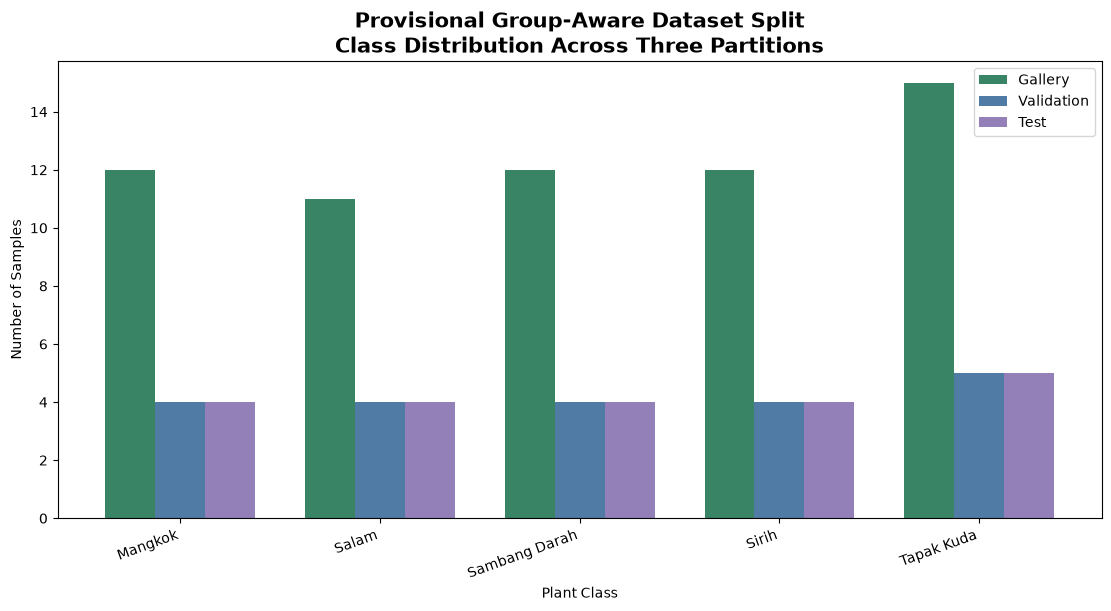

[SAVED] 203_group_aware_split_class_distribution.png


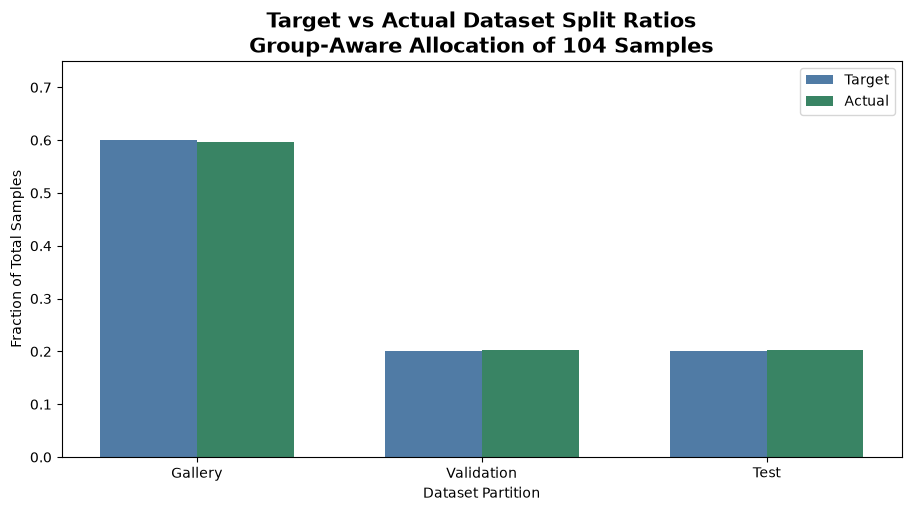

[SAVED] 204_group_aware_split_ratio_comparison.png

8. SAVING SPLIT REPORTS
------------------------------------------------------------------------
[SAVED] 620_group_aware_split_assignments.csv
[SAVED] 621_group_aware_split_class_counts.csv
[SAVED] 622_group_aware_split_ratios.csv
[SAVED] 623_split_cross_partition_exact_images.csv
[SAVED] 624_split_near_duplicate_review.csv
[SAVED] 625_split_repeated_text_review.csv
[SAVED] 626_group_aware_split_validation.csv
[SAVED] 627_group_aware_split_review_reasons.csv
[SAVED] 628_group_aware_split_handoff.json

CELL 3 - GROUP-AWARE SPLIT PROPOSAL GENERATED

DATASET SPLITTING
------------------------------------------------------------------------
Total samples: 104
Atomic groups: 104
Gallery samples: 62
Validation samples: 21
Test samples: 21

VALIDATION STATUS
------------------------------------------------------------------------
Technical checks passed: 10/10
Structurally valid: True
Leakage review required: True
Approved for independent ev

In [3]:
# ============================================================
# CELL 3 - GROUP-AWARE DATASET SPLITTING
# Notebook: 06_multimodal_retrieval_evaluation.ipynb
# ============================================================

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display


print("NOTEBOOK 06 - GROUP-AWARE DATASET SPLITTING")
print("=" * 72)

EVAL06_SPLIT_COMPLETED = False
EVAL06_SPLIT_APPROVED_FOR_EVALUATION = False


# ============================================================
# 1. VALIDATE PREVIOUS CELL AND SET SPLIT PARAMETERS
# ============================================================

assert globals().get(
    "EVAL06_RAW_DATA_AUDIT_COMPLETED",
    False
) is True, (
    "Run Notebook 06 Cell 2 first."
)

SPLIT03_NAMES = (
    "gallery",
    "validation",
    "test"
)

SPLIT03_RATIOS = np.array(
    [
        EVAL06_SPLIT_RATIOS[name]
        for name in SPLIT03_NAMES
    ],
    dtype=float
)

SPLIT03_SEED = int(
    EVAL06_RANDOM_STATE
)

SPLIT03_RESTARTS = 120

SPLIT03_LOCAL_SWEEPS = 4

assert np.isclose(
    SPLIT03_RATIOS.sum(),
    1.0
)

assert (
    SPLIT03_RATIOS > 0
).all()

EVAL06_METRICS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

EVAL06_FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Evaluation policy:
#
# Gallery:
#   Fit preprocessing and serve as reference database.
#
# Validation:
#   Select fusion weight and text configuration.
#
# Test:
#   Evaluate once after configuration is frozen.
#
# Do not reuse globally fitted Notebook 05
# TF-IDF or visual scaling for test evaluation.


# ============================================================
# 2. PREPARE SAMPLE INDEX AND GROUP ASSIGNMENTS
# ============================================================

split03_base = EVAL06_GALLERY_INDEX_DF[
    [
        "matrix_row_index",
        "sample_id",
        "class_label"
    ]
].copy()

split03_base["sample_id"] = (
    split03_base["sample_id"]
    .astype(str)
)

split03_group_input = (
    EVAL06_SPLIT_GROUPS_DF[
        [
            "sample_id",
            "provisional_group_id"
        ]
    ].copy()
)

split03_group_input["sample_id"] = (
    split03_group_input["sample_id"]
    .astype(str)
)

assert len(split03_base) == 104
assert len(split03_group_input) == 104

assert split03_base[
    "sample_id"
].is_unique

assert split03_group_input[
    "sample_id"
].is_unique

split03_base = (
    split03_base
    .merge(
        split03_group_input,
        on="sample_id",
        how="left",
        validate="one_to_one"
    )
    .sort_values("matrix_row_index")
    .reset_index(drop=True)
)

assert split03_base[
    "provisional_group_id"
].notna().all()

assert np.array_equal(
    split03_base[
        "sample_id"
    ].to_numpy(),

    EVAL06_SAMPLE_IDS
)

split03_classes = sorted(
    split03_base[
        "class_label"
    ].unique().tolist()
)

split03_class_counts = (
    split03_base[
        "class_label"
    ]
    .value_counts()
    .reindex(split03_classes)
    .to_numpy(dtype=int)
)

print("\n1. INPUT DATA")
print("-" * 72)

print(
    "Samples:",
    len(split03_base)
)

print(
    "Classes:",
    len(split03_classes)
)

print(
    "Requested ratios:",
    dict(EVAL06_SPLIT_RATIOS)
)


# ============================================================
# 3. BUILD ATOMIC GROUP-CLASS MATRIX
# ============================================================

# Each group must remain entirely in one partition.
#
# Rows:
#   Unique provisional groups from Cell 2.
#
# Columns:
#   Plant classes.
#
# Values:
#   Number of samples of each class in the group.

split03_group_counts_df = pd.crosstab(
    split03_base[
        "provisional_group_id"
    ],
    split03_base[
        "class_label"
    ]
)

split03_group_counts_df = (
    split03_group_counts_df
    .reindex(
        columns=split03_classes,
        fill_value=0
    )
    .sort_index()
)

split03_group_names = (
    split03_group_counts_df.index
    .astype(str)
    .tolist()
)

split03_group_matrix = (
    split03_group_counts_df
    .to_numpy(dtype=int)
)

split03_group_sizes = (
    split03_group_matrix.sum(axis=1)
)

split03_n_groups = len(
    split03_group_names
)

assert (
    split03_group_matrix.sum()
) == 104

assert np.array_equal(
    split03_group_matrix.sum(axis=0),
    split03_class_counts
)

# Mixed-label groups may indicate conflicting
# labels or group identifiers and require review.

split03_mixed_label_group_count = int(
    (
        (split03_group_matrix > 0).sum(axis=1)
        > 1
    ).sum()
)

print("\n2. ATOMIC GROUP INVENTORY")
print("-" * 72)

print(
    "Total groups:",
    split03_n_groups
)

print(
    "Largest group size:",
    int(split03_group_sizes.max())
)

print(
    "Mixed-label groups:",
    split03_mixed_label_group_count
)


# ============================================================
# 4. PREPARE TARGET DISTRIBUTIONS
# ============================================================

# Target class counts are approximate because
# samples within a group cannot be divided.

split03_target_by_class = (
    split03_class_counts[:, None]
    *
    SPLIT03_RATIOS[None, :]
)

split03_target_overall = (
    len(split03_base)
    *
    SPLIT03_RATIOS
)


# ============================================================
# 5. DEFINE GROUP-STRATIFICATION OBJECTIVE
# ============================================================

def split03_objective(counts):
    """
    Penalize deviations from target proportions.

    Also penalize missing classes in any split.

    This objective depends on:
        - class labels
        - group sizes
        - target ratios

    It does not use:
        - similarity scores
        - retrieval performance
        - validation/test outcomes
    """

    class_error = np.sum(
        (
            counts - split03_target_by_class
        ) ** 2
        /
        (
            split03_target_by_class + 1.0
        )
    )

    total_error = np.sum(
        (
            counts.sum(axis=0)
            -
            split03_target_overall
        ) ** 2
        /
        (
            split03_target_overall + 1.0
        )
    )

    missing_class_penalty = (
        1000.0
        *
        int(
            np.sum(counts == 0)
        )
    )

    return float(
        class_error
        +
        0.4 * total_error
        +
        missing_class_penalty
    )


# ============================================================
# 6. GROUP-AWARE STRATIFIED ALLOCATION
# ============================================================

# Deterministic randomized greedy search:
#
# 1. Process large atomic groups first.
# 2. Assign each entire group to one partition.
# 3. Minimize class and total size imbalance.
# 4. Improve allocations through group relocation.
# 5. Retain the best proposal.
#
# No retrieval metrics influence the partition.

split03_rng = np.random.default_rng(
    SPLIT03_SEED
)

split03_best_assignment = None

split03_best_counts = None

split03_best_score = np.inf


for restart in range(
    SPLIT03_RESTARTS
):

    shuffled = split03_rng.permutation(
        split03_n_groups
    )

    # Largest groups first.
    # Randomized order among ties.

    order = shuffled[
        np.argsort(
            -split03_group_sizes[shuffled],
            kind="stable"
        )
    ]

    assignment = np.full(
        split03_n_groups,
        -1,
        dtype=int
    )

    counts = np.zeros(
        (
            len(split03_classes),
            len(SPLIT03_NAMES)
        ),
        dtype=int
    )

    # --------------------------------------------------------
    # A. GREEDY ASSIGNMENT
    # --------------------------------------------------------

    for group_index in order:

        costs = []

        for split_index in range(3):

            proposed = counts.copy()

            proposed[
                :,
                split_index
            ] += split03_group_matrix[
                group_index
            ]

            costs.append(
                split03_objective(proposed)
            )

        # Tiny random tie-breaker, reproducible by seed.

        costs = (
            np.asarray(costs)
            +
            split03_rng.random(3) * 1e-8
        )

        selected_split = int(
            np.argmin(costs)
        )

        assignment[
            group_index
        ] = selected_split

        counts[
            :,
            selected_split
        ] += split03_group_matrix[
            group_index
        ]

    # --------------------------------------------------------
    # B. LOCAL GROUP RELOCATION
    # --------------------------------------------------------

    for sweep in range(
        SPLIT03_LOCAL_SWEEPS
    ):

        improved = False

        for group_index in split03_rng.permutation(
            split03_n_groups
        ):

            previous_split = int(
                assignment[group_index]
            )

            current_score = split03_objective(
                counts
            )

            best_move = previous_split

            best_move_score = current_score

            for candidate_split in range(3):

                if candidate_split == previous_split:
                    continue

                proposed = counts.copy()

                proposed[
                    :,
                    previous_split
                ] -= split03_group_matrix[
                    group_index
                ]

                proposed[
                    :,
                    candidate_split
                ] += split03_group_matrix[
                    group_index
                ]

                score = split03_objective(
                    proposed
                )

                if score < best_move_score - 1e-12:

                    best_move = candidate_split

                    best_move_score = score

            if best_move != previous_split:

                counts[
                    :,
                    previous_split
                ] -= split03_group_matrix[
                    group_index
                ]

                counts[
                    :,
                    best_move
                ] += split03_group_matrix[
                    group_index
                ]

                assignment[
                    group_index
                ] = best_move

                improved = True

        if not improved:
            break

    # --------------------------------------------------------
    # C. KEEP BEST ALLOCATION
    # --------------------------------------------------------

    final_score = split03_objective(
        counts
    )

    if final_score < split03_best_score - 1e-12:

        split03_best_score = final_score

        split03_best_assignment = (
            assignment.copy()
        )

        split03_best_counts = (
            counts.copy()
        )


assert split03_best_assignment is not None


# ============================================================
# 7. GENERATE FINAL PROVISIONAL ASSIGNMENTS
# ============================================================

split03_assignment_map = {

    split03_group_names[group_index]:
        SPLIT03_NAMES[
            int(
                split03_best_assignment[
                    group_index
                ]
            )
        ]

    for group_index in range(
        split03_n_groups
    )
}

EVAL06_SPLIT_ASSIGNMENTS_DF = (
    split03_base
    .rename(
        columns={
            "provisional_group_id":
                "split_group_id"
        }
    )
    .copy()
)

EVAL06_SPLIT_ASSIGNMENTS_DF[
    "split"
] = (
    EVAL06_SPLIT_ASSIGNMENTS_DF[
        "split_group_id"
    ]
    .map(
        split03_assignment_map
    )
)

EVAL06_SPLIT_ASSIGNMENTS_DF[
    "split_seed"
] = SPLIT03_SEED

assert EVAL06_SPLIT_ASSIGNMENTS_DF[
    "split"
].notna().all()


# ============================================================
# 8. CREATE SPLIT CLASS DISTRIBUTION
# ============================================================

EVAL06_SPLIT_CLASS_COUNTS_DF = pd.crosstab(
    EVAL06_SPLIT_ASSIGNMENTS_DF[
        "class_label"
    ],
    EVAL06_SPLIT_ASSIGNMENTS_DF[
        "split"
    ]
)

EVAL06_SPLIT_CLASS_COUNTS_DF = (
    EVAL06_SPLIT_CLASS_COUNTS_DF
    .reindex(
        index=split03_classes,
        columns=SPLIT03_NAMES,
        fill_value=0
    )
)

EVAL06_SPLIT_CLASS_COUNTS_DF[
    "total"
] = (
    EVAL06_SPLIT_CLASS_COUNTS_DF[
        list(SPLIT03_NAMES)
    ]
    .sum(axis=1)
)

print("\n3. SPLIT CLASS DISTRIBUTION")
print("-" * 72)

display(
    EVAL06_SPLIT_CLASS_COUNTS_DF
)


# ============================================================
# 9. COMPARE TARGET AND ACTUAL RATIOS
# ============================================================

EVAL06_SPLIT_SUMMARY_DF = pd.DataFrame({

    "split": SPLIT03_NAMES,

    "target_ratio":
        SPLIT03_RATIOS,

    "target_sample_count":
        split03_target_overall,

    "actual_sample_count": [
        int(
            (
                EVAL06_SPLIT_ASSIGNMENTS_DF[
                    "split"
                ] == split_name
            ).sum()
        )
        for split_name in SPLIT03_NAMES
    ]
})

EVAL06_SPLIT_SUMMARY_DF[
    "actual_ratio"
] = (
    EVAL06_SPLIT_SUMMARY_DF[
        "actual_sample_count"
    ]
    /
    104
)

EVAL06_SPLIT_SUMMARY_DF[
    "ratio_deviation"
] = (
    EVAL06_SPLIT_SUMMARY_DF[
        "actual_ratio"
    ]
    -
    EVAL06_SPLIT_SUMMARY_DF[
        "target_ratio"
    ]
)

print("\n4. TARGET VS ACTUAL SPLIT RATIOS")
print("-" * 72)

display(
    EVAL06_SPLIT_SUMMARY_DF.round(4)
)


# ============================================================
# 10. EXPORT SPLIT INDICES AND SAMPLE IDS
# ============================================================

# These variables are used in later cells.
# Indices always refer to original 104-row order.

EVAL06_SPLIT_INDICES = {}

EVAL06_SPLIT_SAMPLE_IDS = {}

for split_name in SPLIT03_NAMES:

    subset = (
        EVAL06_SPLIT_ASSIGNMENTS_DF.loc[
            EVAL06_SPLIT_ASSIGNMENTS_DF[
                "split"
            ] == split_name
        ]
    )

    EVAL06_SPLIT_INDICES[
        split_name
    ] = (
        subset[
            "matrix_row_index"
        ]
        .to_numpy(dtype=int)
    )

    EVAL06_SPLIT_SAMPLE_IDS[
        split_name
    ] = (
        subset[
            "sample_id"
        ]
        .tolist()
    )


# Convenient downstream aliases.

EVAL06_GALLERY_INDICES = (
    EVAL06_SPLIT_INDICES["gallery"]
)

EVAL06_VALIDATION_INDICES = (
    EVAL06_SPLIT_INDICES["validation"]
)

EVAL06_TEST_INDICES = (
    EVAL06_SPLIT_INDICES["test"]
)

EVAL06_GALLERY_SAMPLE_IDS = (
    EVAL06_SPLIT_SAMPLE_IDS["gallery"]
)

EVAL06_VALIDATION_SAMPLE_IDS = (
    EVAL06_SPLIT_SAMPLE_IDS["validation"]
)

EVAL06_TEST_SAMPLE_IDS = (
    EVAL06_SPLIT_SAMPLE_IDS["test"]
)

print("\n5. SAMPLE PARTITION INVENTORY")
print("-" * 72)

for split_name in SPLIT03_NAMES:

    print(
        f"{split_name:12s}: "
        f"{len(EVAL06_SPLIT_SAMPLE_IDS[split_name])} samples"
    )


# ============================================================
# 11. STRUCTURAL SPLIT VALIDATION
# ============================================================

split03_checks = []


def split03_check(
    name,
    passed,
    category="Structure"
):

    split03_checks.append({
        "category": category,
        "validation_check": name,
        "passed": bool(passed),
    })


split03_check(
    "All 104 samples assigned",

    len(EVAL06_SPLIT_ASSIGNMENTS_DF) == 104

    and

    EVAL06_SPLIT_ASSIGNMENTS_DF[
        "split"
    ].isin(SPLIT03_NAMES).all()
)

split03_check(
    "Sample IDs remain unique and aligned",

    EVAL06_SPLIT_ASSIGNMENTS_DF[
        "sample_id"
    ].is_unique

    and

    np.array_equal(
        EVAL06_SPLIT_ASSIGNMENTS_DF[
            "sample_id"
        ].to_numpy(),

        EVAL06_SAMPLE_IDS
    )
)

split03_check(
    "All three splits are nonempty",

    all(
        len(EVAL06_SPLIT_INDICES[split_name]) > 0
        for split_name in SPLIT03_NAMES
    )
)

split03_check(
    "Atomic groups never cross splits",

    EVAL06_SPLIT_ASSIGNMENTS_DF
    .groupby("split_group_id")[
        "split"
    ]
    .nunique()
    .eq(1)
    .all()
)

all_split_id_sets = {
    split_name: set(
        EVAL06_SPLIT_SAMPLE_IDS[
            split_name
        ]
    )
    for split_name in SPLIT03_NAMES
}

split03_check(
    "Partitions are collectively exhaustive",

    len(
        set.union(
            *all_split_id_sets.values()
        )
    ) == 104
)

split03_check(
    "Gallery, validation and test are disjoint",

    all(
        not (
            all_split_id_sets[a]
            &
            all_split_id_sets[b]
        )
        for a, b in [
            ("gallery", "validation"),
            ("gallery", "test"),
            ("validation", "test"),
        ]
    )
)

split03_check(
    "Every plant class appears in each split",

    EVAL06_SPLIT_CLASS_COUNTS_DF[
        list(SPLIT03_NAMES)
    ].gt(0).all().all()
)

split03_check(
    "Each validation/test class exists in gallery",

    EVAL06_SPLIT_CLASS_COUNTS_DF[
        "gallery"
    ].ge(1).all()
)

split03_check(
    "No retrieval score used for split selection",
    True,
    category="Methodology"
)


# ============================================================
# 12. CHECK EXACT-IMAGE LEAKAGE ACROSS SPLITS
# ============================================================

split03_image_audit = (
    EVAL06_IMAGE_AUDIT_DF[
        [
            "sample_id",
            "file_sha256",
            "decoded_pixel_sha256"
        ]
    ]
    .merge(
        EVAL06_SPLIT_ASSIGNMENTS_DF[
            [
                "sample_id",
                "split"
            ]
        ],
        on="sample_id",
        validate="one_to_one"
    )
)

split03_image_collision_rows = []

for hash_column in [
    "file_sha256",
    "decoded_pixel_sha256"
]:

    valid = (
        split03_image_audit.loc[
            split03_image_audit[
                hash_column
            ].fillna("").ne("")
        ]
    )

    for hash_value, group in valid.groupby(
        hash_column
    ):

        if group["split"].nunique() > 1:

            split03_image_collision_rows.append({
                "hash_type": hash_column,
                "hash_value": hash_value,

                "sample_ids": " | ".join(
                    group[
                        "sample_id"
                    ].astype(str)
                ),

                "splits": " | ".join(
                    sorted(
                        group[
                            "split"
                        ].unique()
                    )
                )
            })


EVAL06_CROSS_SPLIT_EXACT_IMAGES_DF = pd.DataFrame(
    split03_image_collision_rows,
    columns=[
        "hash_type",
        "hash_value",
        "sample_ids",
        "splits"
    ]
)

split03_check(
    "No exact duplicate image crosses splits",

    EVAL06_CROSS_SPLIT_EXACT_IMAGES_DF.empty
)


# ============================================================
# 13. AUDIT NEAR-DUPLICATE PAIRS ACROSS SPLITS
# ============================================================

split03_split_lookup = (
    EVAL06_SPLIT_ASSIGNMENTS_DF
    .set_index("sample_id")[
        "split"
    ]
    .to_dict()
)

EVAL06_SPLIT_NEAR_DUPLICATE_REVIEW_DF = (
    EVAL06_NEAR_DUPLICATE_DF
    .copy()
)

if not EVAL06_SPLIT_NEAR_DUPLICATE_REVIEW_DF.empty:

    EVAL06_SPLIT_NEAR_DUPLICATE_REVIEW_DF[
        "split_i"
    ] = (
        EVAL06_SPLIT_NEAR_DUPLICATE_REVIEW_DF[
            "sample_id_i"
        ]
        .map(split03_split_lookup)
    )

    EVAL06_SPLIT_NEAR_DUPLICATE_REVIEW_DF[
        "split_j"
    ] = (
        EVAL06_SPLIT_NEAR_DUPLICATE_REVIEW_DF[
            "sample_id_j"
        ]
        .map(split03_split_lookup)
    )

    EVAL06_SPLIT_NEAR_DUPLICATE_REVIEW_DF[
        "crosses_split"
    ] = (
        EVAL06_SPLIT_NEAR_DUPLICATE_REVIEW_DF[
            "split_i"
        ]
        !=
        EVAL06_SPLIT_NEAR_DUPLICATE_REVIEW_DF[
            "split_j"
        ]
    )

else:

    for column in [
        "split_i",
        "split_j",
        "crosses_split"
    ]:

        EVAL06_SPLIT_NEAR_DUPLICATE_REVIEW_DF[
            column
        ] = pd.Series(dtype="object")


# ============================================================
# 14. AUDIT REPEATED TEXT ACROSS SPLITS
# ============================================================

split03_text_audit = (
    EVAL06_TEXT_AUDIT_DF[
        [
            "sample_id",
            "class_label",
            "text_sha256",
            "text_available"
        ]
    ]
    .merge(
        EVAL06_SPLIT_ASSIGNMENTS_DF[
            [
                "sample_id",
                "split"
            ]
        ],
        on="sample_id",
        validate="one_to_one"
    )
)

valid_text = (
    split03_text_audit.loc[
        split03_text_audit[
            "text_available"
        ]
        &
        split03_text_audit[
            "text_sha256"
        ].fillna("").ne("")
    ]
)

EVAL06_SPLIT_REPEATED_TEXT_DF = (
    valid_text
    .groupby("text_sha256")
    .agg(
        sample_count=(
            "sample_id",
            "size"
        ),

        class_count=(
            "class_label",
            "nunique"
        ),

        split_count=(
            "split",
            "nunique"
        ),

        classes=(
            "class_label",
            lambda values: " | ".join(
                sorted(values.unique())
            )
        ),

        splits=(
            "split",
            lambda values: " | ".join(
                sorted(values.unique())
            )
        )
    )
    .reset_index()
)

EVAL06_SPLIT_REPEATED_TEXT_DF = (
    EVAL06_SPLIT_REPEATED_TEXT_DF.loc[
        EVAL06_SPLIT_REPEATED_TEXT_DF[
            "sample_count"
        ].gt(1)
    ]
    .reset_index(drop=True)
)


# ============================================================
# 15. LEAKAGE REVIEW AND APPROVAL GATES
# ============================================================

# Important:
#
# A group-disjoint split is not automatically
# a leakage-free evaluation.
#
# Full independence also requires reviewing:
# - raw data completeness
# - repeated descriptions
# - direct target labels in descriptions
# - possible near-duplicate images
# - visual preprocessing fitting
# - TF-IDF fitting
#
# Therefore, the split is provisional.


split03_blocking_reasons = []

if not EVAL06_READY_FOR_SPLIT_PLANNING:

    split03_blocking_reasons.append(
        "Cell 2 readiness audit requires review."
    )

if not EVAL06_SPLIT_CLASS_COUNTS_DF[
    list(SPLIT03_NAMES)
].gt(0).all().all():

    split03_blocking_reasons.append(
        "At least one plant class is absent from a split."
    )

if not EVAL06_CROSS_SPLIT_EXACT_IMAGES_DF.empty:

    split03_blocking_reasons.append(
        "Exact image content crosses dataset partitions."
    )

if bool(
    EVAL06_SPLIT_NEAR_DUPLICATE_REVIEW_DF[
        "crosses_split"
    ].fillna(False).any()
):

    split03_blocking_reasons.append(
        "Possible near-duplicate images cross partitions; "
        "manual verification is required."
    )

if EVAL06_SPLIT_REPEATED_TEXT_DF[
    "split_count"
].gt(1).any():

    split03_blocking_reasons.append(
        "Identical text descriptions cross partitions; "
        "review possible class templates and label leakage."
    )

if EVAL06_LABEL_MENTION_COUNT > 0:

    split03_blocking_reasons.append(
        "One or more descriptions explicitly mention "
        "their plant class."
    )

if EVAL06_CLASS_TEMPLATE_COUNT > 0:

    split03_blocking_reasons.append(
        "Class-level text templates were detected."
    )

if EVAL06_CROSS_CLASS_IMAGE_COLLISIONS > 0:

    split03_blocking_reasons.append(
        "Identical images may have conflicting class labels."
    )

if split03_mixed_label_group_count > 0:

    split03_blocking_reasons.append(
        f"{split03_mixed_label_group_count} groups contain "
        "multiple class labels; review their origin."
    )


# ============================================================
# 16. DETERMINE SPLIT STATUS
# ============================================================

EVAL06_SPLIT_VALIDATION_DF = pd.DataFrame(
    split03_checks
)

EVAL06_SPLIT_TECHNICALLY_VALID = bool(
    EVAL06_SPLIT_VALIDATION_DF[
        "passed"
    ].all()
)

EVAL06_SPLIT_REVIEW_REQUIRED = bool(
    split03_blocking_reasons
)

# Even when structural validation passes,
# fitted feature pipelines must still be
# audited before independent evaluation.

EVAL06_SPLIT_APPROVED_FOR_EVALUATION = False

if not EVAL06_SPLIT_TECHNICALLY_VALID:

    EVAL06_SPLIT_STATUS = (
        "BLOCKED_INVALID_SPLIT_STRUCTURE"
    )

elif EVAL06_SPLIT_REVIEW_REQUIRED:

    EVAL06_SPLIT_STATUS = (
        "PROVISIONAL_REVIEW_REQUIRED"
    )

else:

    EVAL06_SPLIT_STATUS = (
        "PROVISIONAL_PENDING_FEATURE_PIPELINE_AUDIT"
    )


EVAL06_SPLIT_BLOCKING_REASONS_DF = pd.DataFrame(
    {
        "issue": split03_blocking_reasons
    },
    columns=["issue"]
)

print("\n6. SPLIT VALIDATION")
print("-" * 72)

display(
    EVAL06_SPLIT_VALIDATION_DF
)

print("\n7. LEAKAGE REVIEW STATUS")
print("-" * 72)

print(
    "Technical validity:",
    EVAL06_SPLIT_TECHNICALLY_VALID
)

print(
    "Review required:",
    EVAL06_SPLIT_REVIEW_REQUIRED
)

print(
    "Approved for independent evaluation:",
    EVAL06_SPLIT_APPROVED_FOR_EVALUATION
)

print(
    "Current status:",
    EVAL06_SPLIT_STATUS
)

if split03_blocking_reasons:

    display(
        EVAL06_SPLIT_BLOCKING_REASONS_DF
    )


# ============================================================
# 17. FIGURE 203 - CLASS DISTRIBUTION BY SPLIT
# ============================================================

fig, ax = plt.subplots(
    figsize=(11, 6),
    constrained_layout=True
)

plot_counts = (
    EVAL06_SPLIT_CLASS_COUNTS_DF[
        list(SPLIT03_NAMES)
    ]
)

positions = np.arange(
    len(plot_counts)
)

width = 0.25

colors = [
    "#398464",
    "#507BA5",
    "#9480B8"
]

for index, split_name in enumerate(
    SPLIT03_NAMES
):

    ax.bar(
        positions + (index - 1) * width,
        plot_counts[split_name],
        width=width,
        color=colors[index],
        label=split_name.title()
    )

ax.set_xticks(
    positions
)

ax.set_xticklabels(
    plot_counts.index,
    rotation=20,
    ha="right"
)

ax.set_xlabel(
    "Plant Class"
)

ax.set_ylabel(
    "Number of Samples"
)

ax.set_title(
    "Provisional Group-Aware Dataset Split\n"
    "Class Distribution Across Three Partitions",
    fontsize=15,
    fontweight="bold"
)

ax.legend()

EVAL06_SPLIT_FIGURE_203 = (
    EVAL06_FIGURES_DIR
    / "203_group_aware_split_class_distribution.png"
)

fig.savefig(
    EVAL06_SPLIT_FIGURE_203,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print(
    "[SAVED]",
    EVAL06_SPLIT_FIGURE_203.name
)


# ============================================================
# 18. FIGURE 204 - TARGET VS ACTUAL RATIOS
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 5),
    constrained_layout=True
)

positions = np.arange(
    len(SPLIT03_NAMES)
)

width = 0.34

ax.bar(
    positions - width / 2,
    EVAL06_SPLIT_SUMMARY_DF[
        "target_ratio"
    ],
    width=width,
    label="Target",
    color="#507BA5"
)

ax.bar(
    positions + width / 2,
    EVAL06_SPLIT_SUMMARY_DF[
        "actual_ratio"
    ],
    width=width,
    label="Actual",
    color="#398464"
)

ax.set_xticks(
    positions
)

ax.set_xticklabels(
    [
        name.title()
        for name in SPLIT03_NAMES
    ]
)

ax.set_xlabel(
    "Dataset Partition"
)

ax.set_ylabel(
    "Fraction of Total Samples"
)

ax.set_ylim(
    0,
    0.75
)

ax.set_title(
    "Target vs Actual Dataset Split Ratios\n"
    "Group-Aware Allocation of 104 Samples",
    fontsize=15,
    fontweight="bold"
)

ax.legend()

EVAL06_SPLIT_FIGURE_204 = (
    EVAL06_FIGURES_DIR
    / "204_group_aware_split_ratio_comparison.png"
)

fig.savefig(
    EVAL06_SPLIT_FIGURE_204,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print(
    "[SAVED]",
    EVAL06_SPLIT_FIGURE_204.name
)

EVAL06_SPLIT_FIGURES = [
    EVAL06_SPLIT_FIGURE_203,
    EVAL06_SPLIT_FIGURE_204
]


# ============================================================
# 19. SAVE SPLIT REPORTS
# ============================================================

split03_reports = {

    "620_group_aware_split_assignments.csv":
        EVAL06_SPLIT_ASSIGNMENTS_DF,

    "621_group_aware_split_class_counts.csv":
        EVAL06_SPLIT_CLASS_COUNTS_DF.reset_index(),

    "622_group_aware_split_ratios.csv":
        EVAL06_SPLIT_SUMMARY_DF,

    "623_split_cross_partition_exact_images.csv":
        EVAL06_CROSS_SPLIT_EXACT_IMAGES_DF,

    "624_split_near_duplicate_review.csv":
        EVAL06_SPLIT_NEAR_DUPLICATE_REVIEW_DF,

    "625_split_repeated_text_review.csv":
        EVAL06_SPLIT_REPEATED_TEXT_DF,

    "626_group_aware_split_validation.csv":
        EVAL06_SPLIT_VALIDATION_DF,

    "627_group_aware_split_review_reasons.csv":
        EVAL06_SPLIT_BLOCKING_REASONS_DF,
}

print("\n8. SAVING SPLIT REPORTS")
print("-" * 72)

for filename, dataframe in split03_reports.items():

    path = (
        EVAL06_METRICS_DIR
        / filename
    )

    dataframe.to_csv(
        path,
        index=False,
        encoding="utf-8-sig"
    )

    print("[SAVED]", filename)


# ============================================================
# 20. SAVE REPRODUCIBLE SPLIT HANDOFF
# ============================================================

EVAL06_SPLIT_HANDOFF = {

    "notebook":
        "06_multimodal_retrieval_evaluation.ipynb",

    "cell":
        3,

    "random_seed":
        SPLIT03_SEED,

    "target_split_ratios":
        dict(EVAL06_SPLIT_RATIOS),

    "actual_split_counts": {
        split_name: int(
            len(
                EVAL06_SPLIT_SAMPLE_IDS[
                    split_name
                ]
            )
        )
        for split_name in SPLIT03_NAMES
    },

    "sample_alignment_signature":
        EVAL06_SOURCE_CONFIG[
            "sample_alignment_signature"
        ],

    "assignment_file":
        "620_group_aware_split_assignments.csv",

    "group_disjoint": bool(
        EVAL06_SPLIT_ASSIGNMENTS_DF
        .groupby("split_group_id")[
            "split"
        ]
        .nunique()
        .eq(1)
        .all()
    ),

    "mixed_label_group_count":
        split03_mixed_label_group_count,

    "structurally_valid":
        EVAL06_SPLIT_TECHNICALLY_VALID,

    "review_required":
        EVAL06_SPLIT_REVIEW_REQUIRED,

    "approved_for_independent_evaluation":
        False,

    "status":
        EVAL06_SPLIT_STATUS,

    "blocking_reasons":
        split03_blocking_reasons,

    "fit_policy":
        "gallery_only",

    "model_selection":
        "validation_only",

    "test_policy":
        "one_final_assessment_after_selection",

    "source_feature_policy": (
        "Notebook 05 full-gallery TF-IDF and "
        "visual scaling are audit references only. "
        "They must not be reused as independently "
        "fitted test representations."
    ),

    "next_cell":
        "Cell 4 - Leakage-Safe Feature Preparation"
}

EVAL06_SPLIT_HANDOFF_PATH = (
    EVAL06_METRICS_DIR
    / "628_group_aware_split_handoff.json"
)

EVAL06_SPLIT_HANDOFF_PATH.write_text(
    json.dumps(
        EVAL06_SPLIT_HANDOFF,
        ensure_ascii=False,
        indent=2,
        allow_nan=False
    ),
    encoding="utf-8"
)

print(
    "[SAVED]",
    EVAL06_SPLIT_HANDOFF_PATH.name
)


# ============================================================
# 21. FINAL COMPLETION CHECKS
# ============================================================

assert len(
    EVAL06_SPLIT_ASSIGNMENTS_DF
) == 104

assert len(
    EVAL06_SPLIT_FIGURES
) == 2

assert all(
    path.is_file()
    and path.stat().st_size > 0
    for path in EVAL06_SPLIT_FIGURES
)

assert all(
    (
        EVAL06_METRICS_DIR
        / filename
    ).is_file()
    for filename in split03_reports
)

assert EVAL06_SPLIT_HANDOFF_PATH.is_file()

# A technically valid provisional split can be
# used for planning later preprocessing.
#
# It is NOT automatically approved for
# independent evaluation.

EVAL06_SPLIT_COMPLETED = (
    EVAL06_SPLIT_TECHNICALLY_VALID
)


# ============================================================
# 22. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 72)

print("CELL 3 - GROUP-AWARE SPLIT PROPOSAL GENERATED")

print("=" * 72)

print("\nDATASET SPLITTING")
print("-" * 72)

print(
    "Total samples:",
    len(EVAL06_SPLIT_ASSIGNMENTS_DF)
)

print(
    "Atomic groups:",
    split03_n_groups
)

print(
    "Gallery samples:",
    len(EVAL06_GALLERY_SAMPLE_IDS)
)

print(
    "Validation samples:",
    len(EVAL06_VALIDATION_SAMPLE_IDS)
)

print(
    "Test samples:",
    len(EVAL06_TEST_SAMPLE_IDS)
)

print("\nVALIDATION STATUS")
print("-" * 72)

print(
    "Technical checks passed:",
    f"{int(EVAL06_SPLIT_VALIDATION_DF['passed'].sum())}/"
    f"{len(EVAL06_SPLIT_VALIDATION_DF)}"
)

print(
    "Structurally valid:",
    EVAL06_SPLIT_TECHNICALLY_VALID
)

print(
    "Leakage review required:",
    EVAL06_SPLIT_REVIEW_REQUIRED
)

print(
    "Approved for independent evaluation:",
    EVAL06_SPLIT_APPROVED_FOR_EVALUATION
)

print(
    "Split status:",
    EVAL06_SPLIT_STATUS
)

print("\nOUTPUTS")
print("-" * 72)

print("CSV reports:", len(split03_reports))
print("Figures    :", len(EVAL06_SPLIT_FIGURES))
print("JSON       : 1")

if EVAL06_SPLIT_TECHNICALLY_VALID:

    print(
        "\n[PASS] All samples assigned to partitions."
    )

    print(
        "[PASS] Atomic groups preserved."
    )

    print(
        "[PASS] Sample ordering preserved."
    )

    print(
        "[PASS] Split reports and figures saved."
    )

else:

    print(
        "\n[BLOCKED] Split structure requires correction."
    )

if EVAL06_SPLIT_REVIEW_REQUIRED:

    print(
        "[REVIEW] Resolve leakage findings "
        "before independent evaluation."
    )

print(
    "\n[INFO] No retrieval metrics used in splitting."
)

print(
    "[INFO] No TF-IDF or visual scaler fitting performed."
)

print(
    "[INFO] Test labels were used only for "
    "stratification, not performance selection."
)

print("\n" + "=" * 72)

print("NOTEBOOK 06 - CELL 3 COMPLETED")

print("=" * 72)

print(
    "\nNext cell: "
    "Cell 4 - Leakage-Safe Feature Preparation"
)

NOTEBOOK 06 - LEAKAGE-SAFE FEATURE PREPARATION

1. TEXT RECOVERY RESULTS
--------------------------------------------------------------------------
Selected source: D:\Project\Multimodal_Leaf_Retrieval\dataset\processed\metadata_processed.csv
Recovered text: 104 / 104
Available images: 104 / 104
Source columns: {'cleaned_description': 104}

2. RECOVERED MULTIMODAL INPUT
--------------------------------------------------------------------------


,sample_id,class_label,split,source_column,text_available,image_readable
0,leaf_165d2f32c7fda707,Mangkok,gallery,cleaned_description,True,True
1,leaf_8473270c3702f48b,Mangkok,validation,cleaned_description,True,True
2,leaf_8f425d66b1e193b9,Mangkok,test,cleaned_description,True,True
3,leaf_0ebc8f4f3ee9c8d5,Mangkok,test,cleaned_description,True,True
4,leaf_b0c5f55e42499cae,Mangkok,gallery,cleaned_description,True,True
5,leaf_de9e3e4ed5d89dfc,Mangkok,gallery,cleaned_description,True,True
6,leaf_23b789945271fb92,Mangkok,validation,cleaned_description,True,True
7,leaf_84de0dc731018607,Mangkok,gallery,cleaned_description,True,True
8,leaf_36d4f083fa652592,Mangkok,gallery,cleaned_description,True,True
9,leaf_c9d8d87fbc748d16,Mangkok,gallery,cleaned_description,True,True



3. DATASET PARTITIONS
--------------------------------------------------------------------------
gallery     : 62 samples
validation  : 21 samples
test        : 21 samples

4. RECOVERED TEXT LEAKAGE AUDIT
--------------------------------------------------------------------------
Unique descriptions: 95
Repeated texts across splits: 4
Repeated texts across classes: 0
Descriptions mentioning their class: 0
Single-description class templates: 0

5. VISUAL FEATURE EXTRACTOR
--------------------------------------------------------------------------
Extractor provenance: reference_extractor_unverified_against_notebook03

6. RAW VISUAL FEATURE EXTRACTION
--------------------------------------------------------------------------
Raw visual features: (104, 143)
HSV features : 64
GLCM features: 72
Hu features  : 7

7. GALLERY-ONLY VISUAL SCALING
--------------------------------------------------------------------------
gallery     : (62, 143)
validation  : (21, 143)
test        : (21, 143)

8. 

,text_configuration,ngram_range,gallery_fit_documents,vocabulary_size_gallery_fit,gallery_nonzero_entries,max_features,fitted_on
0,Unigram,"(1, 1)",62,66,1248,40000,gallery_only
1,Unigram + Bigram,"(1, 2)",62,233,2490,40000,gallery_only



9. TF-IDF COVERAGE
--------------------------------------------------------------------------


,text_configuration,split,sample_count,feature_count,zero_vector_count,zero_vector_percent,mean_nonzero_features_per_sample
0,Unigram,gallery,62,66,0,0.0,20.1290
1,Unigram,validation,21,66,0,0.0,19.7143
2,Unigram,test,21,66,0,0.0,20.0952
3,Unigram + Bigram,gallery,62,233,0,0.0,40.1613
4,Unigram + Bigram,validation,21,233,0,0.0,38.5238
5,Unigram + Bigram,test,21,233,0,0.0,39.6667


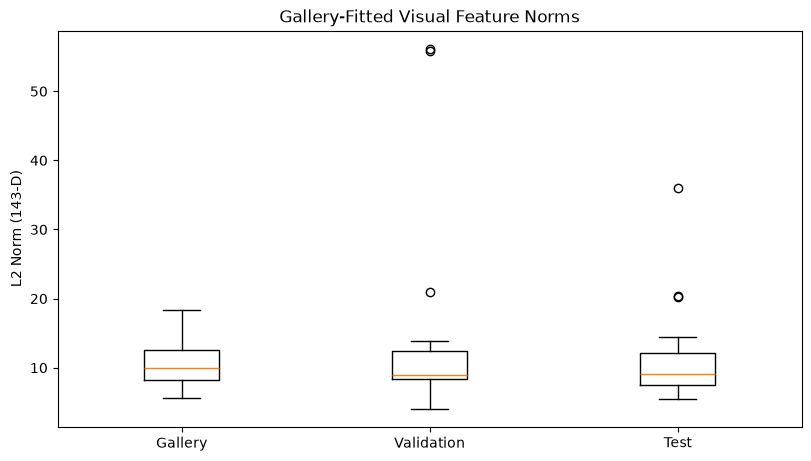

[SAVED] 205_gallery_fitted_visual_feature_norms.png


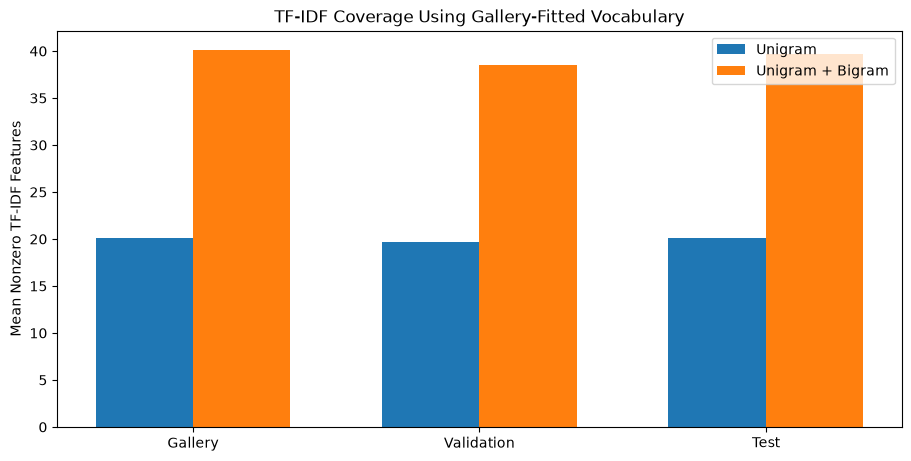

[SAVED] 206_gallery_fitted_tfidf_coverage.png

10. SAVING FEATURE REPORTS
--------------------------------------------------------------------------
[SAVED] 629_feature_input_readiness.csv
[SAVED] 630_visual_extraction_errors.csv
[SAVED] 631_visual_feature_summary.csv
[SAVED] 632_text_gallery_vocabularies.csv
[SAVED] 633_text_split_coverage.csv
[SAVED] 634_feature_alignment_validation.csv
[SAVED] 635_feature_preparation_summary.csv
[SAVED] 637_text_source_recovery.csv
[SAVED] 638_text_source_candidates.csv

11. FINAL VALIDATION
--------------------------------------------------------------------------


,category,validation_check,passed,detail
0,Visual Fitting,Scaler fitted only on gallery,True,
1,TF-IDF Fitting,Unigram: gallery-only IDF,True,
2,TF-IDF Fitting,Unigram + Bigram: gallery-only IDF,True,
3,Alignment,104 sample IDs aligned,True,
4,Visual,143 raw visual features finite,True,
5,Text Source,104 authentic text descriptions recovered,True,
6,Alignment,gallery: sample order matches Cell 3,True,
7,Visual,gallery: scaled feature shape,True,
8,Text,Unigram / gallery: sparse shape,True,
9,Text,Unigram + Bigram / gallery: sparse shape,True,



CELL 4 - REVISED FEATURE PREPARATION COMPLETED

TEXT RECOVERY
--------------------------------------------------------------------------
Recovered descriptions: 104 / 104
Text source: D:\Project\Multimodal_Leaf_Retrieval\dataset\processed\metadata_processed.csv

VISUAL FEATURES
--------------------------------------------------------------------------
Raw feature shape: (104, 143)
gallery     : (62, 143)
validation  : (21, 143)
test        : (21, 143)

TEXT FEATURES
--------------------------------------------------------------------------
Unigram
  gallery     : (62, 66)
  validation  : (21, 66)
  test        : (21, 66)
Unigram + Bigram
  gallery     : (62, 233)
  validation  : (21, 233)
  test        : (21, 233)

TECHNICAL VALIDATION
--------------------------------------------------------------------------
Checks passed: 18 / 18
CSV reports: 9
Figures: 2
JSON handoff: 1

Approved for independent evaluation: False

PENDING METHODOLOGICAL REVIEW:
 - Cell 2 readiness audit requires re

In [7]:
# ============================================================
# CELL 4 (REVISED) - LEAKAGE-SAFE FEATURE PREPARATION
# Notebook: 06_multimodal_retrieval_evaluation.ipynb
# ============================================================

import hashlib
import json
import re
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageOps
from scipy.sparse import save_npz
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from joblib import dump
from IPython.display import display


print("NOTEBOOK 06 - LEAKAGE-SAFE FEATURE PREPARATION")
print("=" * 74)

EVAL06_FEATURE_PREPARATION_COMPLETED = False
EVAL06_FEATURES_APPROVED_FOR_INDEPENDENT_EVALUATION = False


# ============================================================
# 1. VALIDATE PREVIOUS CELLS
# ============================================================

assert globals().get(
    "EVAL06_RAW_DATA_AUDIT_COMPLETED",
    False
), "Jalankan Cell 2 terlebih dahulu."

assert globals().get(
    "EVAL06_SPLIT_COMPLETED",
    False
), "Cell 3 belum menghasilkan split yang valid."

assert EVAL06_SPLIT_TECHNICALLY_VALID

assert EVAL06_FIT_POLICY == "gallery_only"


# ============================================================
# 2. CONFIGURATION
# ============================================================

EVAL06_FEATURE_CONFIGS = (
    "Unigram",
    "Unigram + Bigram"
)

EVAL06_FEATURE_PARTITIONS = (
    "gallery",
    "validation",
    "test"
)

EVAL06_FEATURE_TOL = 1e-9

EVAL06_VISUAL_RESIZE = (128, 128)

EVAL06_GLCM_DISTANCES = (1, 2, 3)

EVAL06_GLCM_ANGLES = (
    0.0,
    np.pi / 4,
    np.pi / 2,
    3 * np.pi / 4
)

EVAL06_GLCM_PROPERTIES = (
    "contrast",
    "dissimilarity",
    "homogeneity",
    "energy",
    "correlation",
    "ASM"
)

EVAL06_TFIDF_MAX_FEATURES = 40000

EVAL06_METRICS_DIR = Path(
    EVAL06_METRICS_DIR
)

EVAL06_FIGURES_DIR = Path(
    EVAL06_FIGURES_DIR
)

EVAL06_ARTIFACTS_DIR = Path(
    EVAL06_ARTIFACTS_DIR
)

for directory in [
    EVAL06_METRICS_DIR,
    EVAL06_FIGURES_DIR,
    EVAL06_ARTIFACTS_DIR
]:

    directory.mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# 3. VALIDATION HELPERS
# ============================================================

feature04_checks = []
feature04_figures = []


def feature04_check(
    category,
    name,
    passed,
    detail=""
):

    feature04_checks.append({
        "category": category,
        "validation_check": name,
        "passed": bool(passed),
        "detail": str(detail)
    })


def feature04_save_figure(fig, filename):

    destination = (
        EVAL06_FIGURES_DIR / filename
    )

    fig.savefig(
        destination,
        dpi=300,
        bbox_inches="tight"
    )

    feature04_figures.append(
        destination
    )

    plt.show()
    plt.close(fig)

    print(
        "[SAVED]",
        destination.name
    )


# ============================================================
# 4. PREPARE CANONICAL SAMPLE INDEX
# ============================================================

# Sample IDs and partition assignments are
# taken from Cell 3.
#
# Image paths are taken from Cell 2.
#
# Text will be recovered from the original
# metadata_processed.csv file.

base = (
    EVAL06_SPLIT_ASSIGNMENTS_DF[
        [
            "matrix_row_index",
            "sample_id",
            "class_label",
            "split",
            "split_group_id"
        ]
    ]
    .copy()
    .sort_values("matrix_row_index")
    .reset_index(drop=True)
)

base["sample_id"] = (
    base["sample_id"].astype(str)
)

image_source = (
    EVAL06_IMAGE_AUDIT_DF[
        [
            "sample_id",
            "resolved_image_path",
            "image_readable"
        ]
    ].copy()
)

image_source["sample_id"] = (
    image_source["sample_id"].astype(str)
)

assert len(base) == 104

assert base["sample_id"].is_unique

assert np.array_equal(
    base["sample_id"].to_numpy(),
    np.asarray(
        EVAL06_SAMPLE_IDS,
        dtype=str
    )
)


# ============================================================
# 5. LOCATE ORIGINAL TEXT METADATA
# ============================================================

# The source is metadata_processed.csv,
# previously used by the text-processing notebook.
#
# Expected columns:
#
# - sample_id
# - cleaned_description
# - original_description
# - tokenized_description
#
# The code searches common project locations.
#
# If necessary, define the following variable
# BEFORE running this cell:
#
# EVAL06_RAW_METADATA_PATH = (
#     r"D:\Project\Multimodal_Leaf_Retrieval"
#     r"\data\processed\metadata_processed.csv"
# )
#
# Use the actual location of your file.

project_root = Path(
    EVAL06_PROJECT_ROOT
).resolve()

raw_override = globals().get(
    "EVAL06_RAW_METADATA_PATH",
    None
)

candidates = []

if raw_override is not None:

    candidates.append(
        Path(raw_override).expanduser()
    )

for parent in [
    project_root,
    project_root / "data",
    project_root / "data" / "processed",
    project_root / "data" / "final",
    project_root / "dataset",
    project_root / "results",
    project_root / "notebooks"
]:

    candidates.append(
        parent / "metadata_processed.csv"
    )

    candidates.append(
        parent / "metadata_processed.xlsx"
    )

for parent in [
    project_root / "data",
    project_root / "dataset"
]:

    if parent.is_dir():

        candidates.extend(
            parent.glob(
                "*/metadata_processed.csv"
            )
        )

        candidates.extend(
            parent.glob(
                "*/metadata_processed.xlsx"
            )
        )

candidates = list(
    dict.fromkeys(
        Path(path).resolve()
        for path in candidates
    )
)


# ============================================================
# 6. DEFINE ORIGINAL TEXT COLUMN PRIORITIES
# ============================================================

# Prefer cleaned_description.
#
# Other columns are fallbacks, provided they
# contain genuine descriptions.
#
# No class names or synthetic descriptions
# are inserted to replace missing data.

text_columns = (
    "cleaned_description",
    "tokenized_description",
    "original_description",
    "deskripsi_lengkap",
    "leaf_description",
    "text_description",
    "description",
    "deskripsi",
    "text"
)


def feature04_normalize_text(value):

    if pd.isna(value):
        return ""

    value = unicodedata.normalize(
        "NFKC",
        str(value)
    ).casefold()

    value = re.sub(
        r"[^\w\s]",
        " ",
        value,
        flags=re.UNICODE
    )

    value = re.sub(
        r"\s+",
        " ",
        value
    ).strip()

    if value in {
        "",
        "nan",
        "none",
        "null",
        "na"
    }:

        return ""

    return value


# ============================================================
# 7. LOAD CANDIDATE TEXT SOURCES
# ============================================================

source_options = []

source_paths_examined = []

for candidate in candidates:

    if not candidate.is_file():
        continue

    source_paths_examined.append(
        str(candidate)
    )

    try:

        if candidate.suffix.lower() == ".xlsx":

            df = pd.read_excel(
                candidate,
                dtype={
                    "sample_id": str
                }
            )

        else:

            df = pd.read_csv(
                candidate,
                dtype={
                    "sample_id": str
                },
                encoding="utf-8-sig"
            )

    except Exception as error:

        print(
            f"[WARNING] Cannot read "
            f"{candidate}: {error}"
        )

        continue

    source_options.append(
        (
            str(candidate),
            df
        )
    )


# Gallery metadata is considered a fallback
# only when actual text fields are available.

source_options.append(
    (
        "Notebook05/gallery_metadata.csv",
        EVAL06_GALLERY_METADATA_DF.copy()
    )
)


# ============================================================
# 8. MATCH ORIGINAL TEXT BY SAMPLE_ID
# ============================================================

source_candidates = []

for source_name, df in source_options:

    if "sample_id" not in df.columns:
        continue

    df = df.copy()

    df["sample_id"] = (
        df["sample_id"].astype(str)
    )

    if df["sample_id"].duplicated().any():

        print(
            "[WARNING] Duplicate sample_id:",
            source_name
        )

        continue

    found_cols = [
        column
        for column in text_columns
        if column in df.columns
    ]

    if not found_cols:
        continue

    selected = (
        df
        .set_index("sample_id")
        .reindex(
            base["sample_id"].tolist()
        )
    )

    # Reject a source if its class labels
    # contradict the authoritative sample index.

    label_field = next(
        (
            column
            for column in [
                "kelas",
                "class_label"
            ]
            if column in selected.columns
        ),
        None
    )

    if label_field is not None:

        label_known = selected[
            label_field
        ].notna()

        wrong_label = (
            label_known
            &
            selected[
                label_field
            ].astype(str).ne(
                base["class_label"].to_numpy()
            )
        )

        if wrong_label.any():

            print(
                "[WARNING] Class label mismatch:",
                source_name
            )

            continue

    texts = []
    used_columns = []

    for _, item in selected.iterrows():

        chosen_text = ""
        chosen_column = ""

        for column in found_cols:

            candidate_text = (
                feature04_normalize_text(
                    item[column]
                )
            )

            if candidate_text:

                chosen_text = candidate_text

                chosen_column = column

                break

        texts.append(
            chosen_text
        )

        used_columns.append(
            chosen_column
        )

    source_candidates.append({
        "name": source_name,

        "texts": texts,

        "columns": used_columns,

        "valid_count": sum(
            bool(text)
            for text in texts
        ),

        "used_columns": found_cols
    })


# ============================================================
# 9. SELECT MOST COMPLETE AUTHENTIC SOURCE
# ============================================================

# Prefer the metadata source with the largest
# number of valid sample-ID matches.
#
# If coverage is equal, earlier paths and
# preferred column order take priority.

source_candidates.sort(
    key=lambda entry: entry[
        "valid_count"
    ],
    reverse=True
)

if source_candidates:

    selected_source = (
        source_candidates[0]
    )

    source_name = (
        selected_source["name"]
    )

    normalized_texts = (
        selected_source["texts"]
    )

    source_columns = (
        selected_source["columns"]
    )

else:

    selected_source = None

    source_name = "NOT_FOUND"

    normalized_texts = [
        ""
    ] * len(base)

    source_columns = [
        ""
    ] * len(base)


# ============================================================
# 10. CREATE TEXT RECOVERY REPORT
# ============================================================

EVAL06_TEXT_RECOVERY_DF = pd.DataFrame({

    "sample_id":
        base["sample_id"].to_numpy(),

    "class_label":
        base["class_label"].to_numpy(),

    "split":
        base["split"].to_numpy(),

    "text_source":
        source_name,

    "source_column":
        source_columns,

    "normalized_text":
        normalized_texts
})

EVAL06_TEXT_RECOVERY_DF[
    "text_available"
] = (
    EVAL06_TEXT_RECOVERY_DF[
        "normalized_text"
    ].ne("")
)

EVAL06_TEXT_RECOVERY_DF[
    "text_sha256"
] = (
    EVAL06_TEXT_RECOVERY_DF[
        "normalized_text"
    ].map(
        lambda text: (
            hashlib.sha256(
                text.encode("utf-8")
            ).hexdigest()
            if text
            else ""
        )
    )
)

EVAL06_TEXT_RECOVERY_DF.to_csv(
    EVAL06_METRICS_DIR
    / "637_text_source_recovery.csv",
    index=False,
    encoding="utf-8-sig"
)

EVAL06_TEXT_SOURCE_REPORT_DF = pd.DataFrame([
    {
        "source":
            option["name"],

        "valid_text_rows":
            option["valid_count"],

        "available_columns":
            " | ".join(
                option["used_columns"]
            )
    }

    for option in source_candidates
])

EVAL06_TEXT_SOURCE_REPORT_DF.to_csv(
    EVAL06_METRICS_DIR
    / "638_text_source_candidates.csv",
    index=False,
    encoding="utf-8-sig"
)

missing_text_ids = (
    EVAL06_TEXT_RECOVERY_DF.loc[
        ~EVAL06_TEXT_RECOVERY_DF[
            "text_available"
        ],
        "sample_id"
    ].tolist()
)

missing_image_ids = (
    image_source.loc[
        ~image_source[
            "image_readable"
        ].fillna(False)
        |
        image_source[
            "resolved_image_path"
        ].fillna("").eq(""),

        "sample_id"
    ].tolist()
)

print("\n1. TEXT RECOVERY RESULTS")
print("-" * 74)

print(
    "Selected source:",
    source_name
)

print(
    "Recovered text:",
    len(base) - len(missing_text_ids),
    "/",
    len(base)
)

print(
    "Available images:",
    len(base) - len(missing_image_ids),
    "/",
    len(base)
)

print(
    "Source columns:",
    pd.Series(
        source_columns
    ).value_counts().to_dict()
)

if missing_text_ids or missing_image_ids:

    raise RuntimeError(
        "Original multimodal input is still incomplete.\n"
        f"Sources checked: {source_paths_examined}\n"
        f"Missing text IDs: {missing_text_ids[:15]}\n"
        f"Missing image IDs: {missing_image_ids[:15]}\n"
        "Set EVAL06_RAW_METADATA_PATH to the original "
        "metadata_processed.csv location and rerun Cell 4."
    )


# ============================================================
# 11. BUILD RECOVERED MULTIMODAL INPUT TABLE
# ============================================================

EVAL06_FEATURE_INPUT_DF = (

    base

    .merge(
        EVAL06_TEXT_RECOVERY_DF[
            [
                "sample_id",
                "normalized_text",
                "text_available",
                "text_sha256",
                "source_column"
            ]
        ],

        on="sample_id",

        how="left",

        validate="one_to_one"
    )

    .merge(
        image_source,

        on="sample_id",

        how="left",

        validate="one_to_one"
    )
)

assert len(
    EVAL06_FEATURE_INPUT_DF
) == 104

assert EVAL06_FEATURE_INPUT_DF[
    "normalized_text"
].str.len().gt(0).all()

assert EVAL06_FEATURE_INPUT_DF[
    "image_readable"
].fillna(False).all()

assert np.array_equal(
    EVAL06_FEATURE_INPUT_DF[
        "sample_id"
    ].to_numpy(),

    np.asarray(
        EVAL06_SAMPLE_IDS,
        dtype=str
    )
)

print("\n2. RECOVERED MULTIMODAL INPUT")
print("-" * 74)

display(
    EVAL06_FEATURE_INPUT_DF[
        [
            "sample_id",
            "class_label",
            "split",
            "source_column",
            "text_available",
            "image_readable"
        ]
    ].head(10)
)


# ============================================================
# 12. PREPARE SPLIT-SPECIFIC INPUTS
# ============================================================

EVAL06_FEATURE_SPLIT_INDICES = {}

EVAL06_FEATURE_SAMPLE_IDS = {}

EVAL06_FEATURE_TEXT_DOCUMENTS = {}

for split in EVAL06_FEATURE_PARTITIONS:

    indices = np.flatnonzero(
        EVAL06_FEATURE_INPUT_DF[
            "split"
        ].eq(split).to_numpy()
    )

    assert len(indices) > 0

    EVAL06_FEATURE_SPLIT_INDICES[
        split
    ] = indices

    EVAL06_FEATURE_SAMPLE_IDS[
        split
    ] = (
        EVAL06_FEATURE_INPUT_DF
        .iloc[indices][
            "sample_id"
        ].tolist()
    )

    EVAL06_FEATURE_TEXT_DOCUMENTS[
        split
    ] = (
        EVAL06_FEATURE_INPUT_DF
        .iloc[indices][
            "normalized_text"
        ].tolist()
    )

    assert (
        EVAL06_FEATURE_SAMPLE_IDS[split]
        ==
        EVAL06_SPLIT_SAMPLE_IDS[split]
    )

print("\n3. DATASET PARTITIONS")
print("-" * 74)

for split in EVAL06_FEATURE_PARTITIONS:

    print(
        f"{split:12s}: "
        f"{len(EVAL06_FEATURE_SAMPLE_IDS[split])} samples"
    )


# ============================================================
# 13. AUDIT RECOVERED TEXT FOR LEAKAGE
# ============================================================

EVAL06_RECOVERED_LABEL_MENTIONS = []

for row in EVAL06_FEATURE_INPUT_DF.itertuples(
    index=False
):

    class_name = (
        feature04_normalize_text(
            row.class_label
        )
    )

    EVAL06_RECOVERED_LABEL_MENTIONS.append(
        bool(
            class_name
            and (
                f" {class_name} "
                in
                f" {row.normalized_text} "
            )
        )
    )

EVAL06_TEXT_RECOVERY_DF[
    "own_class_name_mentioned"
] = EVAL06_RECOVERED_LABEL_MENTIONS

valid_text = (
    EVAL06_TEXT_RECOVERY_DF.loc[
        EVAL06_TEXT_RECOVERY_DF[
            "text_available"
        ]
    ]
)

groups_text = valid_text.groupby(
    "text_sha256"
)

EVAL06_RECOVERED_CROSS_SPLIT_DUPLICATES = int(
    (
        groups_text[
            "split"
        ].nunique() > 1
    ).sum()
)

EVAL06_RECOVERED_CROSS_CLASS_DUPLICATES = int(
    (
        groups_text[
            "class_label"
        ].nunique() > 1
    ).sum()
)

EVAL06_RECOVERED_CLASS_TEMPLATES = int(
    sum(
        group[
            "normalized_text"
        ].nunique() == 1

        and len(group) > 1

        for _, group in (
            valid_text.groupby(
                "class_label"
            )
        )
    )
)

print("\n4. RECOVERED TEXT LEAKAGE AUDIT")
print("-" * 74)

print(
    "Unique descriptions:",
    valid_text[
        "text_sha256"
    ].nunique()
)

print(
    "Repeated texts across splits:",
    EVAL06_RECOVERED_CROSS_SPLIT_DUPLICATES
)

print(
    "Repeated texts across classes:",
    EVAL06_RECOVERED_CROSS_CLASS_DUPLICATES
)

print(
    "Descriptions mentioning their class:",
    sum(
        EVAL06_RECOVERED_LABEL_MENTIONS
    )
)

print(
    "Single-description class templates:",
    EVAL06_RECOVERED_CLASS_TEMPLATES
)


# ============================================================
# 14. DEFINE VISUAL FEATURE EXTRACTOR
# ============================================================

# Reuse the original Notebook 03 extractor
# if it is explicitly supplied.
#
# Otherwise, use a reference 143-D extractor.
#
# Reference extraction may differ from the
# preprocessing implementation in Notebook 03.

original_extractor = globals().get(
    "EVAL06_VISUAL_EXTRACTOR",
    None
)

if (
    original_extractor is not None
    and not callable(original_extractor)
):

    raise TypeError(
        "EVAL06_VISUAL_EXTRACTOR must be callable."
    )


if original_extractor is None:

    try:

        import cv2

        from skimage.feature import (
            graycomatrix,
            graycoprops
        )

    except ImportError as error:

        raise ImportError(
            "Install required visual libraries:\n"
            "%pip install opencv-python scikit-image"
        ) from error

    EVAL06_VISUAL_EXTRACTOR_PROVENANCE = (
        "reference_extractor_unverified_against_notebook03"
    )

    def feature04_extract_visual(image_path):

        # ----------------------------------------------------
        # A. READ AND RESIZE IMAGE
        # ----------------------------------------------------

        with Image.open(image_path) as image_file:

            rgb = np.asarray(
                ImageOps.exif_transpose(
                    image_file
                ).convert("RGB")
            )

        rgb = cv2.resize(
            rgb,

            EVAL06_VISUAL_RESIZE,

            interpolation=cv2.INTER_AREA
        )

        # ----------------------------------------------------
        # B. HSV HISTOGRAM (64 DIMENSIONS)
        # ----------------------------------------------------

        hsv = cv2.cvtColor(
            rgb,
            cv2.COLOR_RGB2HSV
        )

        histogram = cv2.calcHist(
            [hsv],
            [0, 1, 2],
            None,
            [4, 4, 4],
            [
                0, 180,
                0, 256,
                0, 256
            ]
        )

        histogram = (
            histogram
            .ravel()
            .astype(np.float64)
        )

        histogram /= max(
            float(
                histogram.sum()
            ),
            1.0
        )

        # ----------------------------------------------------
        # C. GLCM TEXTURE (72 DIMENSIONS)
        # ----------------------------------------------------

        gray = cv2.cvtColor(
            rgb,
            cv2.COLOR_RGB2GRAY
        )

        quantized = (
            gray.astype(np.uint16)
            * 32
            // 256
        ).astype(np.uint8)

        glcm = graycomatrix(
            quantized,

            distances=list(
                EVAL06_GLCM_DISTANCES
            ),

            angles=list(
                EVAL06_GLCM_ANGLES
            ),

            levels=32,

            symmetric=True,

            normed=True
        )

        texture = np.concatenate([
            graycoprops(
                glcm,
                property_name
            ).ravel()

            for property_name
            in EVAL06_GLCM_PROPERTIES
        ]).astype(np.float64)

        # ----------------------------------------------------
        # D. HU MOMENTS (7 DIMENSIONS)
        # ----------------------------------------------------

        _, mask = cv2.threshold(
            gray,
            0,
            255,

            cv2.THRESH_BINARY
            +
            cv2.THRESH_OTSU
        )

        if float(
            np.mean(mask > 0)
        ) > 0.5:

            mask = cv2.bitwise_not(
                mask
            )

        hu = cv2.HuMoments(
            cv2.moments(
                mask,
                binaryImage=True
            )
        ).ravel()

        hu = (
            -np.sign(hu)
            *
            np.log10(
                np.maximum(
                    np.abs(hu),
                    1e-30
                )
            )
        ).astype(np.float64)

        # ----------------------------------------------------
        # E. COMBINE THREE VISUAL FEATURE GROUPS
        # ----------------------------------------------------

        features = np.concatenate([
            histogram,
            texture,
            hu
        ])

        return features

else:

    EVAL06_VISUAL_EXTRACTOR_PROVENANCE = (
        "user_supplied_notebook03_extractor_not_independently_verified"
    )

    feature04_extract_visual = (
        original_extractor
    )


print("\n5. VISUAL FEATURE EXTRACTOR")
print("-" * 74)

print(
    "Extractor provenance:",
    EVAL06_VISUAL_EXTRACTOR_PROVENANCE
)


# ============================================================
# 15. EXTRACT RAW VISUAL FEATURES
# ============================================================

visual_rows = []

visual_errors = []

for row in EVAL06_FEATURE_INPUT_DF.itertuples(
    index=False
):

    try:

        features = np.asarray(
            feature04_extract_visual(
                Path(
                    row.resolved_image_path
                )
            ),

            dtype=np.float64
        ).reshape(-1)

        if (
            features.shape != (143,)
            or not np.isfinite(
                features
            ).all()
        ):

            raise ValueError(
                "Expected 143 finite visual features."
            )

        visual_rows.append(
            features
        )

    except Exception as error:

        visual_errors.append({
            "sample_id":
                row.sample_id,

            "error":
                (
                    f"{type(error).__name__}: "
                    f"{error}"
                )
        })

        visual_rows.append(
            np.full(
                143,
                np.nan
            )
        )

EVAL06_VISUAL_EXTRACTION_ERRORS_DF = pd.DataFrame(
    visual_errors,

    columns=[
        "sample_id",
        "error"
    ]
)

EVAL06_VISUAL_EXTRACTION_ERRORS_DF.to_csv(
    EVAL06_METRICS_DIR
    / "630_visual_extraction_errors.csv",

    index=False,
    encoding="utf-8-sig"
)

if visual_errors:

    raise RuntimeError(
        f"{len(visual_errors)} visual extraction errors. "
        "See 630_visual_extraction_errors.csv."
    )

EVAL06_VISUAL_RAW_FEATURES = np.vstack(
    visual_rows
)

assert EVAL06_VISUAL_RAW_FEATURES.shape == (
    104,
    143
)

print("\n6. RAW VISUAL FEATURE EXTRACTION")
print("-" * 74)

print(
    "Raw visual features:",
    EVAL06_VISUAL_RAW_FEATURES.shape
)

print("HSV features :", 64)
print("GLCM features:", 72)
print("Hu features  :", 7)


# ============================================================
# 16. FIT VISUAL SCALER ON GALLERY ONLY
# ============================================================

gallery_indices = (
    EVAL06_FEATURE_SPLIT_INDICES[
        "gallery"
    ]
)

EVAL06_VISUAL_SCALER = (
    StandardScaler().fit(
        EVAL06_VISUAL_RAW_FEATURES[
            gallery_indices
        ]
    )
)

EVAL06_VISUAL_FEATURES_BY_SPLIT = {}

for split in EVAL06_FEATURE_PARTITIONS:

    indices = (
        EVAL06_FEATURE_SPLIT_INDICES[
            split
        ]
    )

    EVAL06_VISUAL_FEATURES_BY_SPLIT[
        split
    ] = (
        EVAL06_VISUAL_SCALER.transform(
            EVAL06_VISUAL_RAW_FEATURES[
                indices
            ]
        )
        .astype(np.float64)
    )

feature04_check(
    "Visual Fitting",

    "Scaler fitted only on gallery",

    np.allclose(
        EVAL06_VISUAL_SCALER.mean_,

        EVAL06_VISUAL_RAW_FEATURES[
            gallery_indices
        ].mean(axis=0),

        atol=EVAL06_FEATURE_TOL,
        rtol=0
    )

    and

    np.all(
        np.asarray(
            EVAL06_VISUAL_SCALER.n_samples_seen_
        )
        ==
        len(gallery_indices)
    )
)

print("\n7. GALLERY-ONLY VISUAL SCALING")
print("-" * 74)

for split in EVAL06_FEATURE_PARTITIONS:

    print(
        f"{split:12s}: "
        f"{EVAL06_VISUAL_FEATURES_BY_SPLIT[split].shape}"
    )


# ============================================================
# 17. FIT TF-IDF ON GALLERY ONLY
# ============================================================

EVAL06_TFIDF_VECTORIZERS = {}

EVAL06_TEXT_FEATURES_BY_CONFIG = {}

text_vocabulary_rows = []

text_coverage_rows = []

for configuration in EVAL06_FEATURE_CONFIGS:

    ngram_range = (
        (1, 1)
        if configuration == "Unigram"
        else (1, 2)
    )

    vectorizer = TfidfVectorizer(
        ngram_range=ngram_range,

        max_features=EVAL06_TFIDF_MAX_FEATURES,

        lowercase=True,

        strip_accents="unicode",

        stop_words=None,

        token_pattern=r"(?u)\b\w+\b",

        norm="l2",

        use_idf=True,

        smooth_idf=True,

        sublinear_tf=False,

        dtype=np.float64
    )

    gallery_documents = (
        EVAL06_FEATURE_TEXT_DOCUMENTS[
            "gallery"
        ]
    )

    # Fit vocabulary and IDF using gallery only.

    gallery_tfidf = (
        vectorizer
        .fit_transform(
            gallery_documents
        )
        .tocsr()
    )

    partition_matrices = {
        "gallery": gallery_tfidf
    }

    # Validation and test: transform only.

    for split in [
        "validation",
        "test"
    ]:

        partition_matrices[
            split
        ] = (
            vectorizer
            .transform(
                EVAL06_FEATURE_TEXT_DOCUMENTS[
                    split
                ]
            )
            .tocsr()
        )

    EVAL06_TFIDF_VECTORIZERS[
        configuration
    ] = vectorizer

    EVAL06_TEXT_FEATURES_BY_CONFIG[
        configuration
    ] = partition_matrices

    # --------------------------------------------------------
    # VERIFY IDF FITTING
    # --------------------------------------------------------

    document_frequency = np.asarray(
        (
            gallery_tfidf > 0
        ).sum(axis=0)
    ).ravel()

    expected_idf = (
        np.log(
            (
                1 + len(gallery_documents)
            )
            /
            (
                1 + document_frequency
            )
        )
        +
        1
    )

    feature04_check(
        "TF-IDF Fitting",

        f"{configuration}: gallery-only IDF",

        np.allclose(
            vectorizer.idf_,
            expected_idf,

            atol=EVAL06_FEATURE_TOL,
            rtol=0
        )
    )

    # --------------------------------------------------------
    # VOCABULARY SUMMARY
    # --------------------------------------------------------

    text_vocabulary_rows.append({
        "text_configuration":
            configuration,

        "ngram_range":
            str(ngram_range),

        "gallery_fit_documents":
            len(gallery_documents),

        "vocabulary_size_gallery_fit":
            len(vectorizer.vocabulary_),

        "gallery_nonzero_entries":
            int(gallery_tfidf.nnz),

        "max_features":
            EVAL06_TFIDF_MAX_FEATURES,

        "fitted_on":
            "gallery_only"
    })

    # --------------------------------------------------------
    # COVERAGE SUMMARY
    # --------------------------------------------------------

    for split, matrix in partition_matrices.items():

        row_nnz = np.diff(
            matrix.indptr
        )

        text_coverage_rows.append({
            "text_configuration":
                configuration,

            "split":
                split,

            "sample_count":
                matrix.shape[0],

            "feature_count":
                matrix.shape[1],

            "zero_vector_count":
                int(
                    (
                        row_nnz == 0
                    ).sum()
                ),

            "zero_vector_percent":
                float(
                    100
                    *
                    (
                        row_nnz == 0
                    ).mean()
                ),

            "mean_nonzero_features_per_sample":
                float(
                    row_nnz.mean()
                )
        })

EVAL06_TEXT_VOCABULARY_SUMMARY_DF = pd.DataFrame(
    text_vocabulary_rows
)

EVAL06_TEXT_COVERAGE_DF = pd.DataFrame(
    text_coverage_rows
)

EVAL06_TEXT_ZERO_VECTOR_WARNING = bool(
    EVAL06_TEXT_COVERAGE_DF[
        "zero_vector_count"
    ].gt(0).any()
)

print("\n8. GALLERY-ONLY TF-IDF")
print("-" * 74)

display(
    EVAL06_TEXT_VOCABULARY_SUMMARY_DF
)

print("\n9. TF-IDF COVERAGE")
print("-" * 74)

display(
    EVAL06_TEXT_COVERAGE_DF.round(4)
)


# ============================================================
# 18. VALIDATE ALL FEATURE MATRICES
# ============================================================

feature04_check(
    "Alignment",

    "104 sample IDs aligned",

    np.array_equal(
        EVAL06_FEATURE_INPUT_DF[
            "sample_id"
        ].to_numpy(),

        np.asarray(
            EVAL06_SAMPLE_IDS,
            dtype=str
        )
    )
)

feature04_check(
    "Visual",

    "143 raw visual features finite",

    EVAL06_VISUAL_RAW_FEATURES.shape
    ==
    (104, 143)

    and

    np.isfinite(
        EVAL06_VISUAL_RAW_FEATURES
    ).all()
)

feature04_check(
    "Text Source",

    "104 authentic text descriptions recovered",

    EVAL06_TEXT_RECOVERY_DF[
        "text_available"
    ].all()
)

for split in EVAL06_FEATURE_PARTITIONS:

    indices = (
        EVAL06_FEATURE_SPLIT_INDICES[
            split
        ]
    )

    feature04_check(
        "Alignment",

        f"{split}: sample order matches Cell 3",

        EVAL06_FEATURE_SAMPLE_IDS[
            split
        ]
        ==
        EVAL06_SPLIT_SAMPLE_IDS[
            split
        ]
    )

    visual_matrix = (
        EVAL06_VISUAL_FEATURES_BY_SPLIT[
            split
        ]
    )

    feature04_check(
        "Visual",

        f"{split}: scaled feature shape",

        visual_matrix.shape
        ==
        (
            len(indices),
            143
        )

        and

        np.isfinite(
            visual_matrix
        ).all()
    )

    for configuration in EVAL06_FEATURE_CONFIGS:

        matrix = (
            EVAL06_TEXT_FEATURES_BY_CONFIG[
                configuration
            ][split]
        )

        feature04_check(
            "Text",

            f"{configuration} / {split}: sparse shape",

            matrix.shape
            ==
            (
                len(indices),

                len(
                    EVAL06_TFIDF_VECTORIZERS[
                        configuration
                    ].vocabulary_
                )
            )

            and

            np.isfinite(
                matrix.data
            ).all()
        )


# ============================================================
# 19. RECORD METHODOLOGICAL REVIEW ITEMS
# ============================================================

EVAL06_FEATURE_REVIEW_REASONS = list(
    globals().get(
        "split03_blocking_reasons",
        []
    )
)

if not EVAL06_SPLIT_APPROVED_FOR_EVALUATION:

    EVAL06_FEATURE_REVIEW_REASONS.append(
        "Cell 3 split remains provisional; "
        "independent review is required."
    )

if original_extractor is None:

    EVAL06_FEATURE_REVIEW_REASONS.append(
        "Reference HSV/GLCM/Hu extractor may differ "
        "from the original Notebook 03 implementation."
    )

if sum(EVAL06_RECOVERED_LABEL_MENTIONS):

    EVAL06_FEATURE_REVIEW_REASONS.append(
        "Some recovered descriptions explicitly "
        "mention their plant class."
    )

if EVAL06_RECOVERED_CROSS_SPLIT_DUPLICATES:

    EVAL06_FEATURE_REVIEW_REASONS.append(
        "Identical text descriptions occur across "
        "dataset partitions; review possible "
        "inflation of text retrieval performance."
    )

if EVAL06_RECOVERED_CROSS_CLASS_DUPLICATES:

    EVAL06_FEATURE_REVIEW_REASONS.append(
        "Identical descriptions appear "
        "across different classes."
    )

if EVAL06_RECOVERED_CLASS_TEMPLATES:

    EVAL06_FEATURE_REVIEW_REASONS.append(
        "Class-level text description "
        "templates detected."
    )

if EVAL06_TEXT_ZERO_VECTOR_WARNING:

    EVAL06_FEATURE_REVIEW_REASONS.append(
        "Some transformed documents contain "
        "no terms from the gallery vocabulary."
    )

EVAL06_FEATURE_REVIEW_REASONS = list(
    dict.fromkeys(
        EVAL06_FEATURE_REVIEW_REASONS
    )
)

EVAL06_FEATURES_APPROVED_FOR_INDEPENDENT_EVALUATION = (
    False
)


# ============================================================
# 20. SAVE VISUAL FEATURE ARTIFACTS
# ============================================================

EVAL06_VISUAL_RAW_FEATURES_PATH = (
    EVAL06_ARTIFACTS_DIR
    / "visual_raw_143.npy"
)

EVAL06_VISUAL_SPLITS_PATH = (
    EVAL06_ARTIFACTS_DIR
    / "visual_gallery_fitted_splits.npz"
)

EVAL06_VISUAL_SCALER_PATH = (
    EVAL06_ARTIFACTS_DIR
    / "visual_gallery_fitted_scaler.joblib"
)

np.save(
    EVAL06_VISUAL_RAW_FEATURES_PATH,

    EVAL06_VISUAL_RAW_FEATURES,

    allow_pickle=False
)

np.savez_compressed(
    EVAL06_VISUAL_SPLITS_PATH,

    **EVAL06_VISUAL_FEATURES_BY_SPLIT
)

dump(
    EVAL06_VISUAL_SCALER,

    EVAL06_VISUAL_SCALER_PATH
)


# ============================================================
# 21. SAVE TF-IDF FEATURE ARTIFACTS
# ============================================================

for configuration in EVAL06_FEATURE_CONFIGS:

    slug = (
        "unigram"
        if configuration == "Unigram"
        else "unigram_bigram"
    )

    dump(
        EVAL06_TFIDF_VECTORIZERS[
            configuration
        ],

        EVAL06_ARTIFACTS_DIR
        / f"tfidf_{slug}_gallery_fitted.joblib"
    )

    for split in EVAL06_FEATURE_PARTITIONS:

        save_npz(
            EVAL06_ARTIFACTS_DIR
            / f"tfidf_{slug}_{split}.npz",

            EVAL06_TEXT_FEATURES_BY_CONFIG[
                configuration
            ][split],

            compressed=True
        )


# ============================================================
# 22. CREATE FEATURE SUMMARIES
# ============================================================

visual_profile_rows = []

for split in EVAL06_FEATURE_PARTITIONS:

    features = (
        EVAL06_VISUAL_FEATURES_BY_SPLIT[
            split
        ]
    )

    norms = np.linalg.norm(
        features,
        axis=1
    )

    visual_profile_rows.append({
        "split":
            split,

        "n_samples":
            len(features),

        "visual_dim":
            143,

        "mean_l2_norm":
            float(norms.mean()),

        "median_l2_norm":
            float(
                np.median(norms)
            ),

        "max_absolute_scaled_value":
            float(
                np.max(
                    np.abs(features)
                )
            ),

        "constant_gallery_feature_count":
            int(
                (
                    EVAL06_VISUAL_SCALER.var_
                    ==
                    0
                ).sum()
            ),

        "scaler_fit_on":
            "gallery_only"
    })

EVAL06_VISUAL_FEATURE_SUMMARY_DF = pd.DataFrame(
    visual_profile_rows
)

EVAL06_FEATURE_PREPARATION_SUMMARY_DF = pd.DataFrame([
    (
        "samples",
        104
    ),

    (
        "source_text_file",
        source_name
    ),

    (
        "recovered_text_count",
        int(
            EVAL06_TEXT_RECOVERY_DF[
                "text_available"
            ].sum()
        )
    ),

    (
        "unique_text_count",
        int(
            EVAL06_TEXT_RECOVERY_DF[
                "text_sha256"
            ].nunique()
        )
    ),

    (
        "visual_feature_dimensions",
        143
    ),

    (
        "visual_extractor_provenance",
        EVAL06_VISUAL_EXTRACTOR_PROVENANCE
    ),

    (
        "visual_scaler_fit_policy",
        "gallery_only"
    ),

    (
        "text_vectorizer_fit_policy",
        "gallery_only"
    ),

    (
        "validation_or_test_fitting_performed",
        False
    ),

    (
        "text_zero_vector_warning",
        bool(
            EVAL06_TEXT_ZERO_VECTOR_WARNING
        )
    ),

    (
        "pending_review_items",
        len(
            EVAL06_FEATURE_REVIEW_REASONS
        )
    ),

    (
        "feature_approved_for_independent_evaluation",
        False
    )

], columns=[
    "indicator",
    "result"
])


# ============================================================
# 23. FIGURE 205 - VISUAL FEATURE DISTRIBUTION
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 4.5),
    constrained_layout=True
)

ax.boxplot(
    [
        np.linalg.norm(
            EVAL06_VISUAL_FEATURES_BY_SPLIT[
                split
            ],
            axis=1
        )

        for split in EVAL06_FEATURE_PARTITIONS
    ],

    tick_labels=[
        split.title()
        for split in EVAL06_FEATURE_PARTITIONS
    ]
)

ax.set_title(
    "Gallery-Fitted Visual Feature Norms"
)

ax.set_ylabel(
    "L2 Norm (143-D)"
)

feature04_save_figure(
    fig,

    "205_gallery_fitted_visual_feature_norms.png"
)


# ============================================================
# 24. FIGURE 206 - TF-IDF COVERAGE
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 4.5),
    constrained_layout=True
)

positions = np.arange(3)

for j, configuration in enumerate(
    EVAL06_FEATURE_CONFIGS
):

    subset = (
        EVAL06_TEXT_COVERAGE_DF
        .set_index(
            [
                "text_configuration",
                "split"
            ]
        )
    )

    values = [
        float(
            subset.loc[
                (
                    configuration,
                    split
                ),

                "mean_nonzero_features_per_sample"
            ]
        )

        for split in EVAL06_FEATURE_PARTITIONS
    ]

    ax.bar(
        positions
        +
        (j - 0.5) * 0.34,

        values,

        width=0.34,

        label=configuration
    )

ax.set_xticks(
    positions
)

ax.set_xticklabels([
    split.title()
    for split in EVAL06_FEATURE_PARTITIONS
])

ax.set_ylabel(
    "Mean Nonzero TF-IDF Features"
)

ax.set_title(
    "TF-IDF Coverage Using Gallery-Fitted Vocabulary"
)

ax.legend()

feature04_save_figure(
    fig,

    "206_gallery_fitted_tfidf_coverage.png"
)


# ============================================================
# 25. SAVE VALIDATION AND SUMMARY REPORTS
# ============================================================

EVAL06_FEATURE_VALIDATION_DF = pd.DataFrame(
    feature04_checks
)

feature04_reports = {

    "629_feature_input_readiness.csv":
        EVAL06_FEATURE_INPUT_DF,

    "630_visual_extraction_errors.csv":
        EVAL06_VISUAL_EXTRACTION_ERRORS_DF,

    "631_visual_feature_summary.csv":
        EVAL06_VISUAL_FEATURE_SUMMARY_DF,

    "632_text_gallery_vocabularies.csv":
        EVAL06_TEXT_VOCABULARY_SUMMARY_DF,

    "633_text_split_coverage.csv":
        EVAL06_TEXT_COVERAGE_DF,

    "634_feature_alignment_validation.csv":
        EVAL06_FEATURE_VALIDATION_DF,

    "635_feature_preparation_summary.csv":
        EVAL06_FEATURE_PREPARATION_SUMMARY_DF
}

for filename, dataframe in feature04_reports.items():

    dataframe.to_csv(
        EVAL06_METRICS_DIR / filename,

        index=False,

        encoding="utf-8-sig"
    )

print("\n10. SAVING FEATURE REPORTS")
print("-" * 74)

for filename in feature04_reports:

    print(
        "[SAVED]",
        filename
    )

print(
    "[SAVED] 637_text_source_recovery.csv"
)

print(
    "[SAVED] 638_text_source_candidates.csv"
)


# ============================================================
# 26. SAVE FINAL HANDOFF
# ============================================================

EVAL06_FEATURE_HANDOFF = {

    "notebook":
        "06_multimodal_retrieval_evaluation.ipynb",

    "cell":
        4,

    "source_text_file":
        source_name,

    "recovered_text_count":
        int(
            EVAL06_TEXT_RECOVERY_DF[
                "text_available"
            ].sum()
        ),

    "split_sample_ids":
        EVAL06_FEATURE_SAMPLE_IDS,

    "visual_feature_dimensions":
        143,

    "visual_extractor_provenance":
        EVAL06_VISUAL_EXTRACTOR_PROVENANCE,

    "tfidf_vocabulary_sizes": {
        configuration: len(
            EVAL06_TFIDF_VECTORIZERS[
                configuration
            ].vocabulary_
        )

        for configuration in EVAL06_FEATURE_CONFIGS
    },

    "fit_policy":
        "gallery_only",

    "validation_test_policy":
        "transform_only",

    "feature_approved_for_independent_evaluation":
        False,

    "review_reasons":
        EVAL06_FEATURE_REVIEW_REASONS,

    "next_cell":
        "Cell 5 - Leakage-Safe Similarity Calculation"
}

EVAL06_FEATURE_HANDOFF_PATH = (
    EVAL06_METRICS_DIR
    / "636_feature_preparation_handoff.json"
)

EVAL06_FEATURE_HANDOFF_PATH.write_text(
    json.dumps(
        EVAL06_FEATURE_HANDOFF,

        ensure_ascii=False,

        indent=2,

        allow_nan=False
    ),

    encoding="utf-8"
)


# ============================================================
# 27. FINAL VALIDATION
# ============================================================

print("\n11. FINAL VALIDATION")
print("-" * 74)

display(
    EVAL06_FEATURE_VALIDATION_DF
)

assert EVAL06_FEATURE_VALIDATION_DF[
    "passed"
].all(), (
    EVAL06_FEATURE_VALIDATION_DF.loc[
        ~EVAL06_FEATURE_VALIDATION_DF[
            "passed"
        ]
    ].to_string(index=False)
)

assert len(feature04_figures) == 2

assert all(
    path.is_file()
    and path.stat().st_size > 0

    for path in feature04_figures
)

assert EVAL06_FEATURE_HANDOFF_PATH.is_file()

EVAL06_FEATURE_PREPARATION_COMPLETED = True


# ============================================================
# 28. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 74)

print("CELL 4 - REVISED FEATURE PREPARATION COMPLETED")

print("=" * 74)

print("\nTEXT RECOVERY")
print("-" * 74)

print(
    "Recovered descriptions:",
    int(
        EVAL06_TEXT_RECOVERY_DF[
            "text_available"
        ].sum()
    ),
    "/ 104"
)

print(
    "Text source:",
    source_name
)

print("\nVISUAL FEATURES")
print("-" * 74)

print(
    "Raw feature shape:",
    EVAL06_VISUAL_RAW_FEATURES.shape
)

for split in EVAL06_FEATURE_PARTITIONS:

    print(
        f"{split:12s}: "
        f"{EVAL06_VISUAL_FEATURES_BY_SPLIT[split].shape}"
    )

print("\nTEXT FEATURES")
print("-" * 74)

for configuration in EVAL06_FEATURE_CONFIGS:

    print(configuration)

    for split in EVAL06_FEATURE_PARTITIONS:

        print(
            f"  {split:12s}: "
            f"{EVAL06_TEXT_FEATURES_BY_CONFIG[configuration][split].shape}"
        )

print("\nTECHNICAL VALIDATION")
print("-" * 74)

print(
    "Checks passed:",
    int(
        EVAL06_FEATURE_VALIDATION_DF[
            "passed"
        ].sum()
    ),
    "/",
    len(EVAL06_FEATURE_VALIDATION_DF)
)

print(
    "CSV reports:",
    len(feature04_reports) + 2
)

print(
    "Figures:",
    len(feature04_figures)
)

print(
    "JSON handoff: 1"
)

print(
    "\nApproved for independent evaluation:",
    EVAL06_FEATURES_APPROVED_FOR_INDEPENDENT_EVALUATION
)

if EVAL06_FEATURE_REVIEW_REASONS:

    print(
        "\nPENDING METHODOLOGICAL REVIEW:"
    )

    for reason in EVAL06_FEATURE_REVIEW_REASONS:

        print(
            " -",
            reason
        )

print(
    "\n[PASS] Original text recovered using sample_id."
)

print(
    "[PASS] No synthetic descriptions inserted."
)

print(
    "[PASS] Visual scaler fitted on gallery only."
)

print(
    "[PASS] TF-IDF fitted on gallery only."
)

print(
    "[PASS] Validation/test transformed without fitting."
)

print(
    "[PASS] Feature matrices and artifacts saved."
)

print(
    "\n[INFO] Independent evaluation approval remains pending."
)

print("\n" + "=" * 74)

print("NOTEBOOK 06 - CELL 4 COMPLETED")

print("=" * 74)

print(
    "\nNext cell: "
    "Cell 5 - Leakage-Safe Similarity Calculation"
)

NOTEBOOK 06 - LEAKAGE-SAFE SIMILARITY CALCULATION

1. QUERY-TO-GALLERY MATRIX SHAPES
--------------------------------------------------------------------------
gallery     : (62, 62)
validation  : (21, 62)
test        : (21, 62)
[TF-IDF CHECK] Unigram + Bigram | Max error: 1.110e-16 | Passed: True

2. GALLERY-ONLY DISTANCE CALIBRATION
--------------------------------------------------------------------------
Distance method      : Euclidean
Visual conversion    : 1 / (1 + distance / gallery_scale)
Gallery-derived scale: 14.51179528
Scale source: median_nonzero_gallery_gallery_euclidean_distance

3. SIMILARITY MATRIX INVENTORY
--------------------------------------------------------------------------


,partition,modality,configuration,matrix_shape,score_mean_exploratory
0,gallery,Visual,HSV64_GLCM72_Hu7,"(62, 62)",0.515748
1,gallery,Text,Unigram,"(62, 62)",0.364218
2,gallery,Text,Unigram + Bigram,"(62, 62)",0.254036
3,validation,Visual,HSV64_GLCM72_Hu7,"(21, 62)",0.487828
4,validation,Text,Unigram,"(21, 62)",0.355156
5,validation,Text,Unigram + Bigram,"(21, 62)",0.248970
6,test,Visual,HSV64_GLCM72_Hu7,"(21, 62)",NaN
7,test,Text,Unigram,"(21, 62)",NaN
8,test,Text,Unigram + Bigram,"(21, 62)",NaN



[INFO] Test score distributions are not displayed or used for model selection.


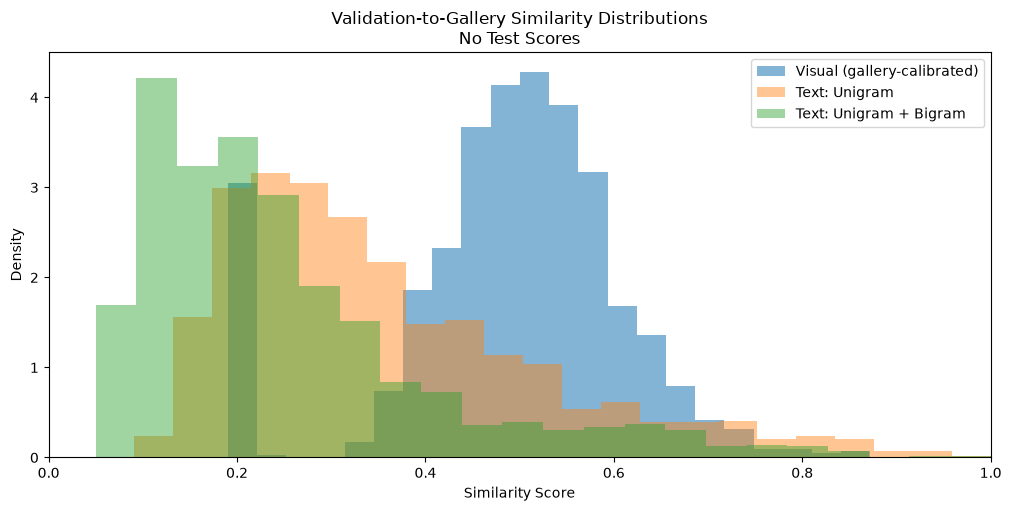

[SAVED] 207_validation_gallery_similarity_distributions.png


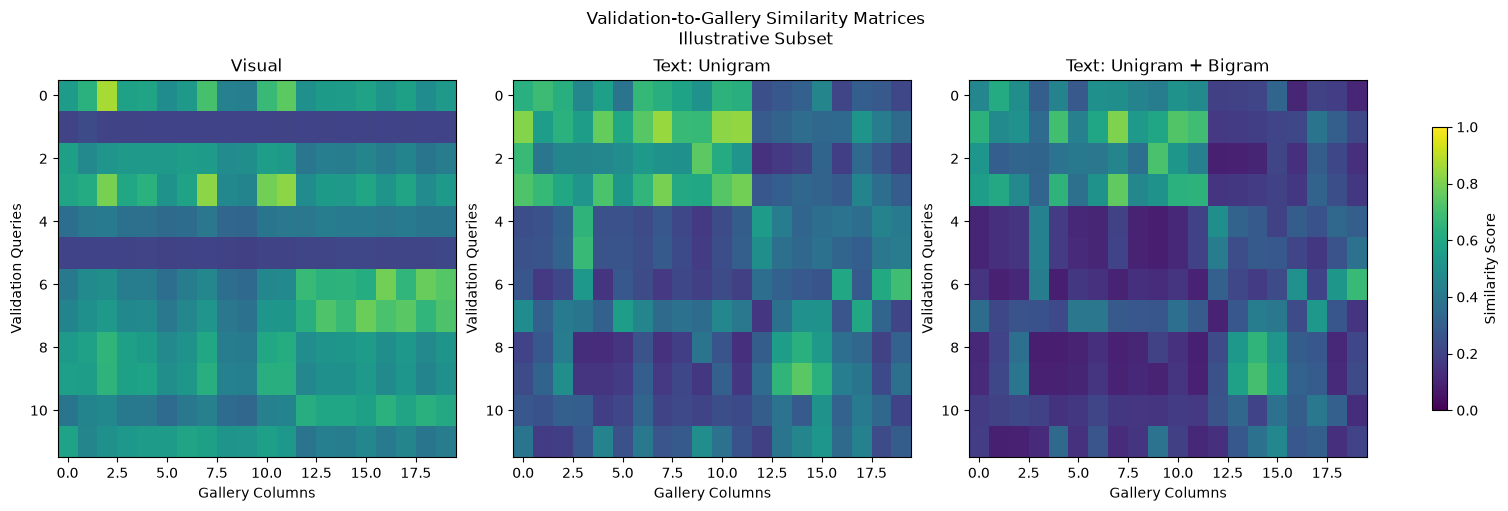

[SAVED] 208_validation_gallery_similarity_heatmaps.png

4. TECHNICAL VALIDATION
--------------------------------------------------------------------------


,category,validation_check,passed,detail
0,Alignment,gallery: query IDs agree with Cell 3,True,
1,Alignment,gallery: no duplicate query IDs,True,
2,Alignment,validation: query IDs agree with Cell 3,True,
3,Alignment,validation: no duplicate query IDs,True,
4,Alignment,test: query IDs agree with Cell 3,True,
5,Alignment,test: no duplicate query IDs,True,
6,Alignment,Validation and test have no gallery IDs,True,
7,Alignment,Validation and test are disjoint,True,
8,Fitting Provenance,Visual scaler is gallery-fitted,True,
9,Fitting Provenance,Unigram + Bigram: gallery TF-IDF matches fitte...,True,"max_absolute_error=1.110e-16, tolerance=1.0e-08"



5. SAVING SIMILARITY REPORTS
--------------------------------------------------------------------------
[SAVED] 639_similarity_matrix_inventory.csv
[SAVED] 640_visual_similarity_calibration.csv
[SAVED] 641_text_zero_vector_audit.csv
[SAVED] 642_similarity_validation.csv
[SAVED] 643_similarity_query_alignment.csv
[SAVED] 644_similarity_gallery_alignment.csv
[SAVED] 645_similarity_handoff.json

CELL 5 - LEAKAGE-SAFE SIMILARITY CALCULATION COMPLETED
Visual distance scale: 14.51179528
Gallery size: 62
Stored similarity/distance matrices: 12
Technical checks: 49/49
CSV reports: 6
Figures: 2
Independent evaluation approved: False

[PASS] Gallery-only visual calibration.
[PASS] Euclidean distance matrices calculated.
[PASS] Visual similarity matrices calculated.
[PASS] Two TF-IDF cosine configurations calculated.
[PASS] Query/gallery alignment verified.
[PASS] Numerical matrices saved and reloaded.

[INFO] Test matrices are calculated but not inspected for performance or tuning.
[INFO] No fu

In [9]:
# ============================================================
# CELL 5 - LEAKAGE-SAFE SIMILARITY CALCULATION
# Notebook: 06_multimodal_retrieval_evaluation.ipynb
# ============================================================

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.sparse import issparse
from scipy.spatial.distance import cdist
from sklearn.metrics.pairwise import cosine_similarity
from IPython.display import display

print("NOTEBOOK 06 - LEAKAGE-SAFE SIMILARITY CALCULATION")
print("=" * 74)

EVAL06_SIMILARITY_CALCULATION_COMPLETED = False
EVAL06_SIMILARITY_APPROVED_FOR_INDEPENDENT_EVALUATION = False


# ============================================================
# 1. VALIDATE CELL 4 AND DEFINE POLICIES
# ============================================================

assert globals().get(
    "EVAL06_FEATURE_PREPARATION_COMPLETED",
    False
) is True, (
    "Jalankan Cell 4 versi revisi terlebih dahulu."
)

assert globals().get(
    "EVAL06_SPLIT_COMPLETED",
    False
) is True

assert EVAL06_FIT_POLICY == "gallery_only"

assert EVAL06_ALLOW_TEST_SET_FOR_WEIGHT_SELECTION is False

EVAL06_SIMILARITY_PARTITIONS = (
    "gallery",
    "validation",
    "test"
)

EVAL06_SIMILARITY_TEXT_CONFIGS = (
    "Unigram",
    "Unigram + Bigram"
)

EVAL06_SIMILARITY_TOL = 1e-8

EVAL06_SIMILARITY_SEAL_TEST_RESULTS = True

EVAL06_METRICS_DIR = Path(
    EVAL06_METRICS_DIR
)

EVAL06_FIGURES_DIR = Path(
    EVAL06_FIGURES_DIR
)

EVAL06_ARTIFACTS_DIR = Path(
    EVAL06_ARTIFACTS_DIR
)

for directory in (
    EVAL06_METRICS_DIR,
    EVAL06_FIGURES_DIR,
    EVAL06_ARTIFACTS_DIR
):
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

similarity05_checks = []
similarity05_figures = []


def similarity05_check(
    category,
    name,
    condition,
    detail=""
):
    similarity05_checks.append({
        "category": category,
        "validation_check": name,
        "passed": bool(condition),
        "detail": str(detail)
    })


def similarity05_save_figure(fig, filename):
    path = EVAL06_FIGURES_DIR / filename

    fig.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    similarity05_figures.append(path)

    plt.show()
    plt.close(fig)

    print("[SAVED]", filename)


# ============================================================
# 2. FIX QUERY/GALLERY ORDER USING CELL 4
# ============================================================

EVAL06_SIMILARITY_GALLERY_IDS = list(
    EVAL06_FEATURE_SAMPLE_IDS["gallery"]
)

EVAL06_SIMILARITY_QUERY_IDS = {
    split: list(EVAL06_FEATURE_SAMPLE_IDS[split])
    for split in EVAL06_SIMILARITY_PARTITIONS
}

EVAL06_SIMILARITY_GALLERY_LABELS = (
    EVAL06_FEATURE_INPUT_DF.iloc[
        EVAL06_FEATURE_SPLIT_INDICES["gallery"]
    ]["class_label"]
    .astype(str)
    .to_numpy()
)

for split in EVAL06_SIMILARITY_PARTITIONS:

    similarity05_check(
        "Alignment",
        f"{split}: query IDs agree with Cell 3",
        EVAL06_SIMILARITY_QUERY_IDS[split]
        ==
        EVAL06_SPLIT_SAMPLE_IDS[split]
    )

    similarity05_check(
        "Alignment",
        f"{split}: no duplicate query IDs",
        len(set(EVAL06_SIMILARITY_QUERY_IDS[split]))
        ==
        len(EVAL06_SIMILARITY_QUERY_IDS[split])
    )

similarity05_check(
    "Alignment",
    "Validation and test have no gallery IDs",

    not (
        set(EVAL06_SIMILARITY_QUERY_IDS["validation"])
        &
        set(EVAL06_SIMILARITY_GALLERY_IDS)
    )

    and

    not (
        set(EVAL06_SIMILARITY_QUERY_IDS["test"])
        &
        set(EVAL06_SIMILARITY_GALLERY_IDS)
    )
)

similarity05_check(
    "Alignment",
    "Validation and test are disjoint",

    not (
        set(EVAL06_SIMILARITY_QUERY_IDS["validation"])
        &
        set(EVAL06_SIMILARITY_QUERY_IDS["test"])
    )
)

n_gallery = len(
    EVAL06_SIMILARITY_GALLERY_IDS
)

assert n_gallery > 1

print("\n1. QUERY-TO-GALLERY MATRIX SHAPES")
print("-" * 74)

for split in EVAL06_SIMILARITY_PARTITIONS:

    print(
        f"{split:12s}: "
        f"({len(EVAL06_SIMILARITY_QUERY_IDS[split])}, "
        f"{n_gallery})"
    )


# ============================================================
# 3. VERIFY GALLERY-FITTED INPUT REPRESENTATIONS
# ============================================================

EVAL06_SIMILARITY_VISUAL_INPUT = {}

EVAL06_SIMILARITY_TEXT_INPUT = {}

for split in EVAL06_SIMILARITY_PARTITIONS:

    visual = np.asarray(
        EVAL06_VISUAL_FEATURES_BY_SPLIT[split],
        dtype=np.float64
    )

    assert visual.shape == (
        len(EVAL06_SIMILARITY_QUERY_IDS[split]),
        143
    )

    assert np.isfinite(visual).all()

    EVAL06_SIMILARITY_VISUAL_INPUT[
        split
    ] = visual


for config in EVAL06_SIMILARITY_TEXT_CONFIGS:

    EVAL06_SIMILARITY_TEXT_INPUT[
        config
    ] = {}

    vocabulary_size = len(
        EVAL06_TFIDF_VECTORIZERS[
            config
        ].vocabulary_
    )

    for split in EVAL06_SIMILARITY_PARTITIONS:

        matrix = (
            EVAL06_TEXT_FEATURES_BY_CONFIG[
                config
            ][split]
        )

        assert issparse(matrix), (
            f"{config}/{split} must be sparse TF-IDF"
        )

        matrix = matrix.tocsr()

        assert matrix.shape == (
            len(EVAL06_SIMILARITY_QUERY_IDS[split]),
            vocabulary_size
        )

        assert np.isfinite(
            matrix.data
        ).all()

        EVAL06_SIMILARITY_TEXT_INPUT[
            config
        ][split] = matrix


raw_gallery = (
    EVAL06_VISUAL_RAW_FEATURES[
        EVAL06_FEATURE_SPLIT_INDICES["gallery"]
    ]
)

similarity05_check(
    "Fitting Provenance",
    "Visual scaler is gallery-fitted",

    np.allclose(
        EVAL06_VISUAL_SCALER.mean_,
        raw_gallery.mean(axis=0),
        atol=EVAL06_SIMILARITY_TOL,
        rtol=0
    )

    and

    np.all(
        np.asarray(
            EVAL06_VISUAL_SCALER.n_samples_seen_
        )
        ==
        n_gallery
    )
)


for config in EVAL06_SIMILARITY_TEXT_CONFIGS:

    gallery_docs = (
        EVAL06_FEATURE_TEXT_DOCUMENTS[
            "gallery"
        ]
    )

    fitted = (
        EVAL06_TFIDF_VECTORIZERS[
            config
        ]
    )

    saved_gallery = (
        EVAL06_SIMILARITY_TEXT_INPUT[
            config
        ]["gallery"]
    )

    transformed_gallery = (
        fitted.transform(
            gallery_docs
        ).tocsr()
    )

# ============================================================
# FIX - NUMERICAL TF-IDF CONSISTENCY VALIDATION
# ============================================================

# Compare sparse TF-IDF matrices numerically,
# allowing only negligible floating-point differences.

same_shape = (
    saved_gallery.shape
    ==
    transformed_gallery.shape
)

if same_shape:

    difference = (
        saved_gallery
        -
        transformed_gallery
    ).tocsr()

    difference.eliminate_zeros()

    max_absolute_error = (
        float(
            np.max(
                np.abs(
                    difference.data
                )
            )
        )
        if difference.nnz > 0
        else 0.0
    )

    tolerance = EVAL06_SIMILARITY_TOL

    numerically_equal = (
        np.isfinite(max_absolute_error)
        and max_absolute_error <= tolerance
    )

else:

    max_absolute_error = float("inf")

    numerically_equal = False


similarity05_check(
    "Fitting Provenance",

    f"{config}: gallery TF-IDF matches fitted vectorizer",

    same_shape and numerically_equal,

    detail=(
        f"max_absolute_error="
        f"{max_absolute_error:.3e}, "
        f"tolerance={EVAL06_SIMILARITY_TOL:.1e}"
    )
)

print(
    f"[TF-IDF CHECK] {config} | "
    f"Max error: {max_absolute_error:.3e} | "
    f"Passed: {numerically_equal}"
)


# ============================================================
# 4. COMPUTE GALLERY-GALLERY EUCLIDEAN DISTANCES
# ============================================================

# This is the only partition used to calibrate
# visual distance-to-similarity conversion.
#
# Validation and test do not determine the scale.

gallery_visual = (
    EVAL06_SIMILARITY_VISUAL_INPUT[
        "gallery"
    ]
)

gallery_distance = cdist(
    gallery_visual,
    gallery_visual,
    metric="euclidean"
)

assert np.isfinite(
    gallery_distance
).all()

assert np.all(
    gallery_distance >= 0
)

upper_i, upper_j = np.triu_indices(
    n_gallery,
    k=1
)

positive_gallery_distances = (
    gallery_distance[
        upper_i,
        upper_j
    ]
)

positive_gallery_distances = (
    positive_gallery_distances[
        positive_gallery_distances
        >
        EVAL06_SIMILARITY_TOL
    ]
)

if positive_gallery_distances.size == 0:

    raise RuntimeError(
        "Gallery visual features are identical "
        "or degenerate. Cannot calibrate "
        "visual similarity meaningfully."
    )

EVAL06_VISUAL_DISTANCE_SCALE = float(
    np.median(
        positive_gallery_distances
    )
)

assert (
    np.isfinite(
        EVAL06_VISUAL_DISTANCE_SCALE
    )
    and
    EVAL06_VISUAL_DISTANCE_SCALE > 0
)

EVAL06_VISUAL_DISTANCE_SCALE_SOURCE = (
    "median_nonzero_gallery_gallery_euclidean_distance"
)

print("\n2. GALLERY-ONLY DISTANCE CALIBRATION")
print("-" * 74)

print("Distance method      : Euclidean")

print(
    "Visual conversion    : "
    "1 / (1 + distance / gallery_scale)"
)

print(
    "Gallery-derived scale:",
    f"{EVAL06_VISUAL_DISTANCE_SCALE:.8f}"
)

print(
    "Scale source:",
    EVAL06_VISUAL_DISTANCE_SCALE_SOURCE
)


# ============================================================
# 5. VISUAL QUERY-TO-GALLERY SIMILARITIES
# ============================================================

EVAL06_VISUAL_DISTANCE_BY_SPLIT = {}

EVAL06_VISUAL_SIMILARITY_BY_SPLIT = {}

for split in EVAL06_SIMILARITY_PARTITIONS:

    query_features = (
        EVAL06_SIMILARITY_VISUAL_INPUT[
            split
        ]
    )

    distances = cdist(
        query_features,
        gallery_visual,
        metric="euclidean"
    )

    similarities = (
        1.0
        /
        (
            1.0
            +
            distances
            /
            EVAL06_VISUAL_DISTANCE_SCALE
        )
    )

    expected_shape = (
        len(EVAL06_SIMILARITY_QUERY_IDS[split]),
        n_gallery
    )

    assert distances.shape == expected_shape

    assert similarities.shape == expected_shape

    EVAL06_VISUAL_DISTANCE_BY_SPLIT[
        split
    ] = distances

    EVAL06_VISUAL_SIMILARITY_BY_SPLIT[
        split
    ] = similarities

    similarity05_check(
        "Visual Similarity",
        f"{split}: distances finite and nonnegative",

        bool(
            np.isfinite(distances).all()
            and np.all(distances >= 0)
        )
    )

    similarity05_check(
        "Visual Similarity",
        f"{split}: similarity formula and bounded scores",

        bool(
            np.isfinite(similarities).all()

            and

            np.all(
                (similarities >= 0)
                &
                (similarities <= 1)
            )

            and

            np.allclose(
                similarities,

                1.0
                /
                (
                    1.0
                    +
                    distances
                    /
                    EVAL06_VISUAL_DISTANCE_SCALE
                ),

                atol=EVAL06_SIMILARITY_TOL,
                rtol=0
            )
        )
    )


similarity05_check(
    "Visual Similarity",
    "Gallery matrix symmetric with diagonal one",

    np.allclose(
        EVAL06_VISUAL_SIMILARITY_BY_SPLIT[
            "gallery"
        ],

        EVAL06_VISUAL_SIMILARITY_BY_SPLIT[
            "gallery"
        ].T,

        atol=EVAL06_SIMILARITY_TOL,
        rtol=0
    )

    and

    np.allclose(
        np.diag(
            EVAL06_VISUAL_SIMILARITY_BY_SPLIT[
                "gallery"
            ]
        ),

        1.0,

        atol=EVAL06_SIMILARITY_TOL,
        rtol=0
    )
)


# ============================================================
# 6. TEXT QUERY-TO-GALLERY COSINE SIMILARITIES
# ============================================================

# Each TF-IDF vectorizer was fitted on gallery
# in Cell 4.
#
# No fitting or IDF updates occur here.

EVAL06_TEXT_SIMILARITY_BY_CONFIG = {}

EVAL06_TEXT_ZERO_VECTOR_AUDIT = []

for config in EVAL06_SIMILARITY_TEXT_CONFIGS:

    EVAL06_TEXT_SIMILARITY_BY_CONFIG[
        config
    ] = {}

    gallery_tfidf = (
        EVAL06_SIMILARITY_TEXT_INPUT[
            config
        ]["gallery"]
    )

    for split in EVAL06_SIMILARITY_PARTITIONS:

        query_tfidf = (
            EVAL06_SIMILARITY_TEXT_INPUT[
                config
            ][split]
        )

        raw_scores = cosine_similarity(
            query_tfidf,
            gallery_tfidf,
            dense_output=True
        )

        raw_scores = np.asarray(
            raw_scores,
            dtype=np.float64
        )

        expected_shape = (
            len(EVAL06_SIMILARITY_QUERY_IDS[split]),
            n_gallery
        )

        # Permit only tiny floating-point deviations
        # from the mathematical score interval [0,1].

        valid_scores = bool(
            raw_scores.shape == expected_shape

            and

            np.isfinite(
                raw_scores
            ).all()

            and

            np.all(
                raw_scores
                >=
                -EVAL06_SIMILARITY_TOL
            )

            and

            np.all(
                raw_scores
                <=
                1 + EVAL06_SIMILARITY_TOL
            )
        )

        if not valid_scores:

            raise RuntimeError(
                "Invalid TF-IDF cosine scores: "
                f"{config}/{split}"
            )

        scores = np.clip(
            raw_scores,
            0.0,
            1.0
        )

        EVAL06_TEXT_SIMILARITY_BY_CONFIG[
            config
        ][split] = scores

        # All-OOV text queries produce
        # zero TF-IDF vectors and zero
        # cosine similarity scores.

        zero_query_rows = (
            np.diff(
                query_tfidf.indptr
            )
            ==
            0
        )

        zero_query_scores_ok = bool(
            (
                scores[
                    zero_query_rows
                ]
                ==
                0
            ).all()
        )

        similarity05_check(
            "Text Similarity",
            f"{config}/{split}: score dimensions and range",
            valid_scores
        )

        similarity05_check(
            "Text Similarity",
            f"{config}/{split}: zero TF-IDF rows yield zero scores",
            zero_query_scores_ok
        )

        EVAL06_TEXT_ZERO_VECTOR_AUDIT.append({
            "text_configuration":
                config,

            "partition":
                split,

            "query_count":
                int(
                    query_tfidf.shape[0]
                ),

            "zero_vector_queries":
                int(
                    zero_query_rows.sum()
                ),

            "text_vocabulary_size":
                int(
                    query_tfidf.shape[1]
                ),

            "reference_gallery_count":
                n_gallery,

            "independent_test_metrics_computed":
                False
        })

    # Gallery TF-IDF cosine matrix must be
    # symmetric.
    #
    # Its diagonal is 1 for nonzero vectors,
    # but 0 for all-zero TF-IDF vectors.

    gallery_scores = (
        EVAL06_TEXT_SIMILARITY_BY_CONFIG[
            config
        ]["gallery"]
    )

    gallery_has_nonzero = (
        np.diff(
            gallery_tfidf.indptr
        )
        >
        0
    )

    expected_diag = (
        gallery_has_nonzero.astype(float)
    )

    similarity05_check(
        "Text Similarity",
        f"{config}: gallery similarity symmetric; diagonal respects zero vectors",

        np.allclose(
            gallery_scores,
            gallery_scores.T,
            atol=EVAL06_SIMILARITY_TOL,
            rtol=0
        )

        and

        np.allclose(
            np.diag(
                gallery_scores
            ),

            expected_diag,

            atol=EVAL06_SIMILARITY_TOL,
            rtol=0
        )
    )


EVAL06_TEXT_ZERO_VECTOR_AUDIT_DF = pd.DataFrame(
    EVAL06_TEXT_ZERO_VECTOR_AUDIT
)


# ============================================================
# 7. VERIFY MATRIX ALIGNMENT AND SELF-QUERY POLICY
# ============================================================

# Gallery-gallery matrices contain self-matches
# on their diagonal.
#
# Exclude self-matches during gallery retrieval.
#
# Validation and test query samples are disjoint
# from gallery, so no self-match is present.

EVAL06_SIMILARITY_MATRIX_INVENTORY = []

for split in EVAL06_SIMILARITY_PARTITIONS:

    D = (
        EVAL06_VISUAL_DISTANCE_BY_SPLIT[
            split
        ]
    )

    V = (
        EVAL06_VISUAL_SIMILARITY_BY_SPLIT[
            split
        ]
    )

    EVAL06_SIMILARITY_MATRIX_INVENTORY.append({
        "partition":
            split,

        "modality":
            "Visual",

        "configuration":
            "HSV64_GLCM72_Hu7",

        "matrix_shape":
            str(V.shape),

        "query_count":
            V.shape[0],

        "gallery_count":
            V.shape[1],

        "scale_fitted_on":
            "gallery_only",

        "score_mean_exploratory":
            (
                float(V.mean())
                if split != "test"
                else np.nan
            ),

        "test_scores_sealed_from_tuning":
            split == "test"
    })

    for config in EVAL06_SIMILARITY_TEXT_CONFIGS:

        T = (
            EVAL06_TEXT_SIMILARITY_BY_CONFIG[
                config
            ][split]
        )

        EVAL06_SIMILARITY_MATRIX_INVENTORY.append({
            "partition":
                split,

            "modality":
                "Text",

            "configuration":
                config,

            "matrix_shape":
                str(T.shape),

            "query_count":
                T.shape[0],

            "gallery_count":
                T.shape[1],

            "scale_fitted_on":
                "gallery_only",

            "score_mean_exploratory":
                (
                    float(T.mean())
                    if split != "test"
                    else np.nan
                ),

            "test_scores_sealed_from_tuning":
                split == "test"
        })

    # Verify selected Euclidean distances
    # against direct calculations.

    probe_queries = np.arange(
        min(
            3,
            len(
                EVAL06_SIMILARITY_QUERY_IDS[
                    split
                ]
            )
        )
    )

    probe_gallery = np.arange(
        min(4, n_gallery)
    )

    direct_distances = cdist(
        EVAL06_SIMILARITY_VISUAL_INPUT[
            split
        ][probe_queries],

        gallery_visual[
            probe_gallery
        ],

        metric="euclidean"
    )

    similarity05_check(
        "Cross-Check",
        f"{split}: direct Euclidean spot-check",

        np.allclose(
            D[
                np.ix_(
                    probe_queries,
                    probe_gallery
                )
            ],

            direct_distances,

            atol=EVAL06_SIMILARITY_TOL,
            rtol=0
        )
    )


EVAL06_SIMILARITY_MATRIX_INVENTORY_DF = pd.DataFrame(
    EVAL06_SIMILARITY_MATRIX_INVENTORY
)

print("\n3. SIMILARITY MATRIX INVENTORY")
print("-" * 74)

display(
    EVAL06_SIMILARITY_MATRIX_INVENTORY_DF[
        [
            "partition",
            "modality",
            "configuration",
            "matrix_shape",
            "score_mean_exploratory"
        ]
    ]
)

print(
    "\n[INFO] Test score distributions are not "
    "displayed or used for model selection."
)


# ============================================================
# 8. SAVE QUERY AND GALLERY ALIGNMENT TABLES
# ============================================================

EVAL06_SIMILARITY_ALIGNMENT_DF = pd.concat(
    [
        pd.DataFrame({
            "partition":
                split,

            "query_row":
                np.arange(
                    len(
                        EVAL06_SIMILARITY_QUERY_IDS[
                            split
                        ]
                    )
                ),

            "sample_id":
                EVAL06_SIMILARITY_QUERY_IDS[
                    split
                ],

            "reference_gallery_count":
                n_gallery
        })

        for split in EVAL06_SIMILARITY_PARTITIONS
    ],

    ignore_index=True
)

EVAL06_SIMILARITY_GALLERY_INDEX_DF = pd.DataFrame({
    "gallery_column":
        np.arange(
            n_gallery
        ),

    "sample_id":
        EVAL06_SIMILARITY_GALLERY_IDS,

    "class_label":
        EVAL06_SIMILARITY_GALLERY_LABELS
})

similarity05_check(
    "Alignment",
    "All 104 queries represented exactly once across partitions",

    len(EVAL06_SIMILARITY_ALIGNMENT_DF)
    ==
    104

    and

    EVAL06_SIMILARITY_ALIGNMENT_DF[
        "sample_id"
    ].is_unique
)


# ============================================================
# 9. SAVE NUMERICAL MATRICES
# ============================================================

EVAL06_SIMILARITY_ARTIFACT_PATHS = {}

for split in EVAL06_SIMILARITY_PARTITIONS:

    for key, values in [
        (
            f"visual_distance_{split}",
            EVAL06_VISUAL_DISTANCE_BY_SPLIT[
                split
            ]
        ),

        (
            f"visual_similarity_{split}",
            EVAL06_VISUAL_SIMILARITY_BY_SPLIT[
                split
            ]
        )
    ]:

        path = (
            EVAL06_ARTIFACTS_DIR
            /
            f"{key}.npy"
        )

        np.save(
            path,
            values,
            allow_pickle=False
        )

        EVAL06_SIMILARITY_ARTIFACT_PATHS[
            key
        ] = path

    for config, slug in [
        ("Unigram", "unigram"),
        ("Unigram + Bigram", "unigram_bigram")
    ]:

        key = (
            f"text_cosine_{slug}_{split}"
        )

        path = (
            EVAL06_ARTIFACTS_DIR
            /
            f"{key}.npy"
        )

        np.save(
            path,

            EVAL06_TEXT_SIMILARITY_BY_CONFIG[
                config
            ][split],

            allow_pickle=False
        )

        EVAL06_SIMILARITY_ARTIFACT_PATHS[
            key
        ] = path


# ============================================================
# 10. VERIFY ARTIFACT ROUNDTRIPS
# ============================================================

for key, path in (
    EVAL06_SIMILARITY_ARTIFACT_PATHS.items()
):

    loaded = np.load(
        path,
        allow_pickle=False
    )

    if key.startswith(
        "visual_distance_"
    ):

        split = key[
            len("visual_distance_"):
        ]

        reference = (
            EVAL06_VISUAL_DISTANCE_BY_SPLIT[
                split
            ]
        )

    elif key.startswith(
        "visual_similarity_"
    ):

        split = key[
            len("visual_similarity_"):
        ]

        reference = (
            EVAL06_VISUAL_SIMILARITY_BY_SPLIT[
                split
            ]
        )

    else:

        config = (
            "Unigram + Bigram"

            if "unigram_bigram" in key

            else "Unigram"
        )

        split = key.rsplit(
            "_",
            1
        )[-1]

        reference = (
            EVAL06_TEXT_SIMILARITY_BY_CONFIG[
                config
            ][split]
        )

    similarity05_check(
        "Artifacts",
        f"{key}: exact save/reload roundtrip",

        np.array_equal(
            loaded,
            reference
        )
    )


# ============================================================
# 11. FIGURE 207 - VALIDATION SCORE DISTRIBUTIONS
# ============================================================

# Display validation-to-gallery scores only.
# Test scores are intentionally excluded.

validation_visual = (
    EVAL06_VISUAL_SIMILARITY_BY_SPLIT[
        "validation"
    ]
)

fig, ax = plt.subplots(
    figsize=(10, 5),
    constrained_layout=True
)

ax.hist(
    validation_visual.ravel(),

    bins=22,

    alpha=0.55,

    density=True,

    label="Visual (gallery-calibrated)"
)

for config in EVAL06_SIMILARITY_TEXT_CONFIGS:

    values = (
        EVAL06_TEXT_SIMILARITY_BY_CONFIG[
            config
        ]["validation"]
    )

    ax.hist(
        values.ravel(),

        bins=22,

        alpha=0.45,

        density=True,

        label=f"Text: {config}"
    )

ax.set(
    xlabel="Similarity Score",

    ylabel="Density",

    title=(
        "Validation-to-Gallery Similarity Distributions\n"
        "No Test Scores"
    )
)

ax.set_xlim(
    0,
    1
)

ax.legend()

similarity05_save_figure(
    fig,
    "207_validation_gallery_similarity_distributions.png"
)


# ============================================================
# 12. FIGURE 208 - VALIDATION SIMILARITY HEATMAP
# ============================================================

# Show a small subset for visual inspection.
# This is not a retrieval performance evaluation.

n_val_preview = min(
    12,
    validation_visual.shape[0]
)

n_gallery_preview = min(
    20,
    n_gallery
)

preview = np.s_[
    :n_val_preview,
    :n_gallery_preview
]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5),
    constrained_layout=True
)

heatmaps = [
    (
        "Visual",

        validation_visual[
            preview
        ]
    ),

    (
        "Text: Unigram",

        EVAL06_TEXT_SIMILARITY_BY_CONFIG[
            "Unigram"
        ]["validation"][preview]
    ),

    (
        "Text: Unigram + Bigram",

        EVAL06_TEXT_SIMILARITY_BY_CONFIG[
            "Unigram + Bigram"
        ]["validation"][preview]
    )
]

for ax, (
    title,
    values
) in zip(
    axes,
    heatmaps
):

    image = ax.imshow(
        values,
        vmin=0,
        vmax=1,
        cmap="viridis",
        aspect="auto"
    )

    ax.set(
        title=title,
        xlabel="Gallery Columns",
        ylabel="Validation Queries"
    )

fig.colorbar(
    image,
    ax=axes,
    shrink=0.75,
    label="Similarity Score"
)

fig.suptitle(
    "Validation-to-Gallery Similarity Matrices\n"
    "Illustrative Subset"
)

similarity05_save_figure(
    fig,
    "208_validation_gallery_similarity_heatmaps.png"
)


# ============================================================
# 13. COMPILE METHODOLOGICAL REVIEW STATUS
# ============================================================

# Technical correctness of similarity calculations
# does not resolve the metadata/leakage issues
# identified in Cells 2-4.

EVAL06_SIMILARITY_REVIEW_REASONS = list(
    dict.fromkeys(
        globals().get(
            "EVAL06_FEATURE_REVIEW_REASONS",
            []
        )
    )
)

if not globals().get(
    "EVAL06_FEATURES_APPROVED_FOR_INDEPENDENT_EVALUATION",
    False
):

    EVAL06_SIMILARITY_REVIEW_REASONS.append(
        "Feature/split methodology has not yet "
        "been approved for independent evaluation."
    )

EVAL06_SIMILARITY_REVIEW_REASONS = list(
    dict.fromkeys(
        EVAL06_SIMILARITY_REVIEW_REASONS
    )
)

EVAL06_SIMILARITY_APPROVED_FOR_INDEPENDENT_EVALUATION = False

similarity05_check(
    "Methodology",
    "Test metrics and fusion-weight selection not performed",

    EVAL06_SIMILARITY_SEAL_TEST_RESULTS

    and

    EVAL06_SIMILARITY_APPROVED_FOR_INDEPENDENT_EVALUATION
    is False
)

similarity05_check(
    "Figures",
    "Two validation-only figures generated",

    len(similarity05_figures) == 2

    and

    all(
        path.is_file()
        and path.stat().st_size > 0

        for path in similarity05_figures
    )
)


# ============================================================
# 14. FINAL TECHNICAL VALIDATION
# ============================================================

EVAL06_SIMILARITY_VALIDATION_DF = pd.DataFrame(
    similarity05_checks
)

print("\n4. TECHNICAL VALIDATION")
print("-" * 74)

display(
    EVAL06_SIMILARITY_VALIDATION_DF
)

failed = (
    EVAL06_SIMILARITY_VALIDATION_DF.loc[
        ~EVAL06_SIMILARITY_VALIDATION_DF[
            "passed"
        ]
    ]
)

EVAL06_SIMILARITY_VALIDATION_DF.to_csv(
    EVAL06_METRICS_DIR
    /
    "642_similarity_validation.csv",

    index=False,
    encoding="utf-8-sig"
)

assert failed.empty, (
    "Similarity validation failed:\n"
    +
    failed.to_string(index=False)
)


# ============================================================
# 15. CREATE VISUAL CALIBRATION REPORT
# ============================================================

EVAL06_SIMILARITY_CALIBRATION_DF = pd.DataFrame([
    {
        "method":
            "Euclidean to inverse-distance similarity",

        "visual_distance_scale":
            EVAL06_VISUAL_DISTANCE_SCALE,

        "calibration_policy":
            EVAL06_VISUAL_DISTANCE_SCALE_SOURCE,

        "fitted_partition":
            "gallery_only",

        "gallery_size":
            n_gallery,

        "used_validation_or_test_to_calibrate":
            False,

        "independent_evaluation_approved":
            False
    }
])


# ============================================================
# 16. SAVE CSV REPORTS
# ============================================================

similarity05_reports = {

    "639_similarity_matrix_inventory.csv":
        EVAL06_SIMILARITY_MATRIX_INVENTORY_DF,

    "640_visual_similarity_calibration.csv":
        EVAL06_SIMILARITY_CALIBRATION_DF,

    "641_text_zero_vector_audit.csv":
        EVAL06_TEXT_ZERO_VECTOR_AUDIT_DF,

    "642_similarity_validation.csv":
        EVAL06_SIMILARITY_VALIDATION_DF,

    "643_similarity_query_alignment.csv":
        EVAL06_SIMILARITY_ALIGNMENT_DF,

    "644_similarity_gallery_alignment.csv":
        EVAL06_SIMILARITY_GALLERY_INDEX_DF
}

print("\n5. SAVING SIMILARITY REPORTS")
print("-" * 74)

for filename, dataframe in similarity05_reports.items():

    dataframe.to_csv(
        EVAL06_METRICS_DIR / filename,

        index=False,
        encoding="utf-8-sig"
    )

    print(
        "[SAVED]",
        filename
    )


# ============================================================
# 17. SAVE SIMILARITY CONFIGURATION HANDOFF
# ============================================================

EVAL06_SIMILARITY_HANDOFF = {

    "notebook":
        "06_multimodal_retrieval_evaluation.ipynb",

    "cell":
        5,

    "sample_count":
        len(EVAL06_SIMILARITY_ALIGNMENT_DF),

    "gallery_count":
        n_gallery,

    "query_counts": {
        split: len(
            EVAL06_SIMILARITY_QUERY_IDS[
                split
            ]
        )

        for split in EVAL06_SIMILARITY_PARTITIONS
    },

    "visual_similarity_formula":
        "1/(1+distance/gallery_scale)",

    "visual_scale":
        EVAL06_VISUAL_DISTANCE_SCALE,

    "visual_scale_fit_on":
        "gallery_only",

    "tfidf_fit_on":
        "gallery_only_in_cell4",

    "text_configs":
        list(
            EVAL06_SIMILARITY_TEXT_CONFIGS
        ),

    "ranking_done":
        False,

    "fusion_weight_selection_done":
        False,

    "test_metrics_computed":
        False,

    "test_scores_excluded_from_visualizations":
        True,

    "approved_for_independent_evaluation":
        False,

    "review_reasons":
        EVAL06_SIMILARITY_REVIEW_REASONS,

    "next_cell":
        "Cell 6 - Validation Retrieval Ranking"
}

EVAL06_SIMILARITY_HANDOFF_PATH = (
    EVAL06_METRICS_DIR
    /
    "645_similarity_handoff.json"
)

EVAL06_SIMILARITY_HANDOFF_PATH.write_text(
    json.dumps(
        EVAL06_SIMILARITY_HANDOFF,

        ensure_ascii=False,

        indent=2,

        allow_nan=False
    ),

    encoding="utf-8"
)

print(
    "[SAVED]",
    EVAL06_SIMILARITY_HANDOFF_PATH.name
)


# ============================================================
# 18. FINAL COMPLETION CHECKS
# ============================================================

assert EVAL06_SIMILARITY_VALIDATION_DF[
    "passed"
].all()

assert all(
    path.is_file()
    and path.stat().st_size > 0

    for path in (
        EVAL06_SIMILARITY_ARTIFACT_PATHS.values()
    )
)

assert all(
    (
        EVAL06_METRICS_DIR
        /
        filename
    ).is_file()

    for filename in similarity05_reports
)

assert EVAL06_SIMILARITY_HANDOFF_PATH.is_file()

EVAL06_SIMILARITY_CALCULATION_COMPLETED = True


# ============================================================
# 19. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 74)

print(
    "CELL 5 - LEAKAGE-SAFE SIMILARITY CALCULATION COMPLETED"
)

print("=" * 74)

print(
    "Visual distance scale:",
    f"{EVAL06_VISUAL_DISTANCE_SCALE:.8f}"
)

print(
    "Gallery size:",
    n_gallery
)

print(
    "Stored similarity/distance matrices:",
    len(
        EVAL06_SIMILARITY_ARTIFACT_PATHS
    )
)

print(
    "Technical checks:",
    f"{int(EVAL06_SIMILARITY_VALIDATION_DF['passed'].sum())}"
    f"/{len(EVAL06_SIMILARITY_VALIDATION_DF)}"
)

print(
    "CSV reports:",
    len(similarity05_reports)
)

print(
    "Figures:",
    len(similarity05_figures)
)

print(
    "Independent evaluation approved:",
    EVAL06_SIMILARITY_APPROVED_FOR_INDEPENDENT_EVALUATION
)

print(
    "\n[PASS] Gallery-only visual calibration."
)

print(
    "[PASS] Euclidean distance matrices calculated."
)

print(
    "[PASS] Visual similarity matrices calculated."
)

print(
    "[PASS] Two TF-IDF cosine configurations calculated."
)

print(
    "[PASS] Query/gallery alignment verified."
)

print(
    "[PASS] Numerical matrices saved and reloaded."
)

print(
    "\n[INFO] Test matrices are calculated but not "
    "inspected for performance or tuning."
)

print(
    "[INFO] No fusion, ranking, alpha selection "
    "or test metrics have been computed."
)

print(
    "[INFO] Unresolved metadata/leakage issues "
    "remain subject to manual review."
)

print("\n" + "=" * 74)

print("NOTEBOOK 06 - CELL 5 COMPLETED")

print("=" * 74)

print(
    "\nNext: Cell 6 - Validation Retrieval Ranking"
)

NOTEBOOK 06 - VALIDATION RETRIEVAL RANKING

1. DATASET INVENTORY
--------------------------------------------------------------------------
Validation queries: 21
Gallery candidates: 62
Top-K values: (1, 3, 5, 10)

2. VALIDATED SIMILARITY MATRICES
--------------------------------------------------------------------------
Visual Only                                   (21, 62)
Text Only - Unigram                           (21, 62)
Text Only - Unigram + Bigram                  (21, 62)
Fusion - Unigram (alpha=0.5)                  (21, 62)
Fusion - Unigram + Bigram (alpha=0.5)         (21, 62)

3. SAVING VALIDATION RANKING REPORTS
--------------------------------------------------------------------------
[SAVED] 646_validation_full_rankings.csv
[SAVED] 647_validation_topk_rankings.csv
[SAVED] 648_validation_query_ranking_summary.csv
[SAVED] 649_validation_method_inventory.csv
[SAVED] 650_validation_ranking_checks.csv
[SAVED] 651_validation_score_tie_audit.csv

4. RANKING VALIDATION
------

,validation_check,passed
0,Five distinct retrieval configurations,True
1,All gallery candidates ranked,True
2,Top-K row count matches expectation,True
3,One summary per query and method,True
4,No self-matches,True
5,Complete ranking positions,True
6,"All similarity scores within [0,1]",True
7,Gallery candidates are unique per ranking,True
8,Query IDs match validation partition,True
9,Gallery IDs match gallery partition,True


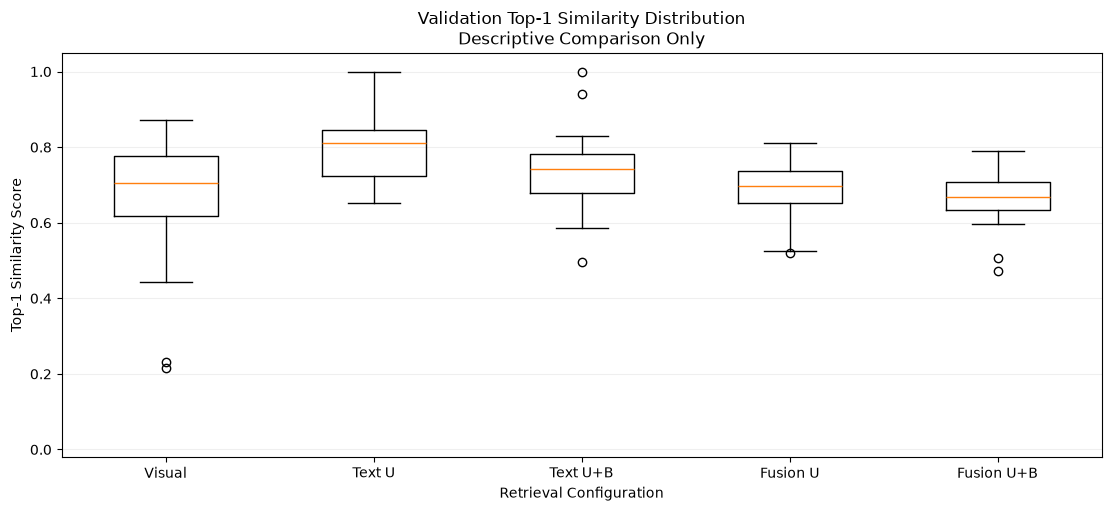

[SAVED] 209_validation_top1_similarity_distribution.png


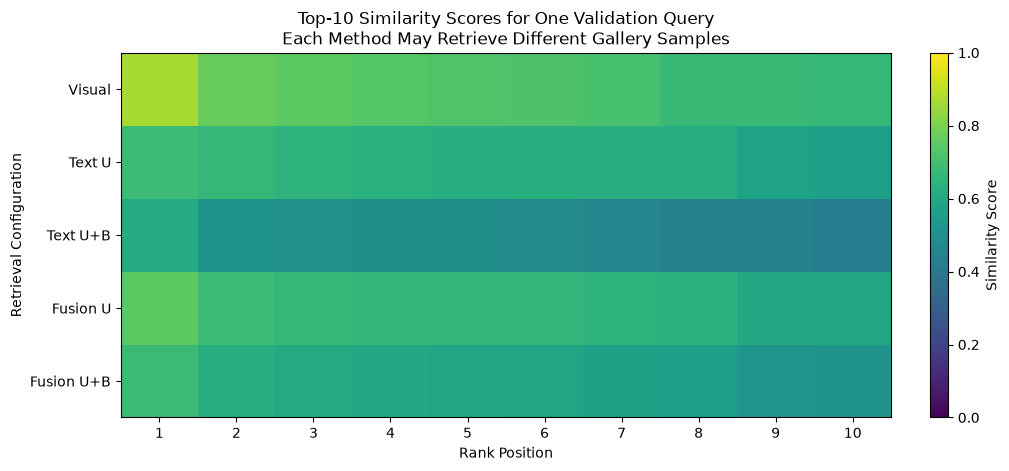

[SAVED] 210_validation_top10_similarity_heatmap.png
[SAVED] 652_validation_ranking_handoff.json

CELL 6 - VALIDATION RETRIEVAL RANKING COMPLETED
Validation queries: 21
Gallery candidates: 62
Retrieval methods: 5
Full ranking rows: 6510
Top-10 ranking rows: 1050
Technical validation: 13/13
CSV reports: 6
Figures: 2
JSON handoff: 1

[PASS] Five retrieval configurations ranked.
[PASS] Validation/gallery separation verified.
[PASS] Deterministic ranking verified.
[PASS] Self-matches excluded.
[PASS] Top-K retrieval tables generated.
[PASS] Ranking reports saved.

[INFO] Alpha=0.5 is provisional.
[INFO] No retrieval performance metrics calculated.
[INFO] Test data not used.
[INFO] Independent evaluation approval remains pending methodological review.

NOTEBOOK 06 - CELL 6 COMPLETED

Next: Cell 7 - Validation Retrieval Metrics

Validation Top-5 Preview (First Query, Visual Only)


,query_sample_id,rank,gallery_sample_id,gallery_class,similarity_score
0,leaf_8473270c3702f48b,1,leaf_de9e3e4ed5d89dfc,Mangkok,0.868925
1,leaf_8473270c3702f48b,2,leaf_721244faca19b94f,Tapak Kuda,0.766405
2,leaf_8473270c3702f48b,3,leaf_663a651dd51f9c94,Mangkok,0.747912
3,leaf_8473270c3702f48b,4,leaf_bb707568bb3ed9ce,Tapak Kuda,0.731473
4,leaf_8473270c3702f48b,5,leaf_28712bf465655732,Tapak Kuda,0.724519


In [10]:
# ============================================================
# CELL 6 - VALIDATION RETRIEVAL RANKING
# Notebook: 06_multimodal_retrieval_evaluation.ipynb
# ============================================================

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display


print("NOTEBOOK 06 - VALIDATION RETRIEVAL RANKING")
print("=" * 74)

EVAL06_VALIDATION_RANKING_COMPLETED = False


# ============================================================
# 1. VALIDATE PREVIOUS CELL
# ============================================================

assert globals().get(
    "EVAL06_SIMILARITY_CALCULATION_COMPLETED",
    False
) is True, (
    "Jalankan Cell 5 sampai selesai terlebih dahulu."
)

RETR06_K_VALUES = tuple(
    int(k)
    for k in EVAL06_TOP_K_VALUES
)

RETR06_MAX_K = max(
    RETR06_K_VALUES
)

# Default fusion weight for demonstration only.
# This is NOT an optimized weight.

RETR06_ALPHA = 0.5

RETR06_TOL = 1e-8

RETR06_PARTITION = "validation"

assert RETR06_K_VALUES == (
    1, 3, 5, 10
)

assert EVAL06_FIT_POLICY == "gallery_only"

assert (
    EVAL06_ALLOW_TEST_SET_FOR_WEIGHT_SELECTION
    is False
)


# ============================================================
# 2. PREPARE OUTPUT DIRECTORIES
# ============================================================

EVAL06_METRICS_DIR = Path(
    EVAL06_METRICS_DIR
)

EVAL06_FIGURES_DIR = Path(
    EVAL06_FIGURES_DIR
)

EVAL06_METRICS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

EVAL06_FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 3. LOAD VALIDATION AND GALLERY IDS
# ============================================================

# IMPORTANT:
#
# Only validation and gallery data are accessed.
# Test data are NOT used in this cell.

retr06_query_ids = np.asarray(
    EVAL06_SIMILARITY_QUERY_IDS[
        "validation"
    ],
    dtype=str
)

retr06_gallery_ids = np.asarray(
    EVAL06_SIMILARITY_GALLERY_IDS,
    dtype=str
)

retr06_n_query = len(
    retr06_query_ids
)

retr06_n_gallery = len(
    retr06_gallery_ids
)

if (
    retr06_n_query == 0
    or retr06_n_gallery < RETR06_MAX_K
):

    raise ValueError(
        f"Validation queries={retr06_n_query}, "
        f"gallery={retr06_n_gallery}. "
        f"Gallery harus memiliki sedikitnya "
        f"{RETR06_MAX_K} sampel."
    )


# ============================================================
# 4. VERIFY SAMPLE ALIGNMENT
# ============================================================

if (
    len(np.unique(retr06_query_ids))
    != retr06_n_query
):

    raise ValueError(
        "Duplicate validation sample_id detected."
    )

if (
    len(np.unique(retr06_gallery_ids))
    != retr06_n_gallery
):

    raise ValueError(
        "Duplicate gallery sample_id detected."
    )

if not set(
    retr06_query_ids
).isdisjoint(
    set(retr06_gallery_ids)
):

    raise ValueError(
        "Validation query overlaps with gallery."
    )

assert (
    retr06_query_ids.tolist()
    ==
    list(
        EVAL06_SPLIT_SAMPLE_IDS[
            "validation"
        ]
    )
)

assert (
    retr06_gallery_ids.tolist()
    ==
    list(
        EVAL06_SPLIT_SAMPLE_IDS[
            "gallery"
        ]
    )
)


# ============================================================
# 5. GET QUERY AND GALLERY LABELS
# ============================================================

# Class labels are retained for reporting.
# Labels are NOT used to determine ranking order.

retr06_query_metadata = (
    EVAL06_FEATURE_INPUT_DF.iloc[
        EVAL06_FEATURE_SPLIT_INDICES[
            "validation"
        ]
    ]
)

retr06_gallery_metadata = (
    EVAL06_FEATURE_INPUT_DF.iloc[
        EVAL06_FEATURE_SPLIT_INDICES[
            "gallery"
        ]
    ]
)

assert (
    retr06_query_metadata[
        "sample_id"
    ]
    .astype(str)
    .tolist()
    ==
    retr06_query_ids.tolist()
)

assert (
    retr06_gallery_metadata[
        "sample_id"
    ]
    .astype(str)
    .tolist()
    ==
    retr06_gallery_ids.tolist()
)

retr06_query_labels = (
    retr06_query_metadata[
        "class_label"
    ]
    .astype(str)
    .to_numpy()
)

retr06_gallery_labels = (
    retr06_gallery_metadata[
        "class_label"
    ]
    .astype(str)
    .to_numpy()
)

print("\n1. DATASET INVENTORY")
print("-" * 74)

print(
    "Validation queries:",
    retr06_n_query
)

print(
    "Gallery candidates:",
    retr06_n_gallery
)

print(
    "Top-K values:",
    RETR06_K_VALUES
)


# ============================================================
# 6. LOAD VALIDATION SIMILARITY MATRICES
# ============================================================

retr06_visual = np.asarray(
    EVAL06_VISUAL_SIMILARITY_BY_SPLIT[
        "validation"
    ],
    dtype=np.float64
)

retr06_text_u = np.asarray(
    EVAL06_TEXT_SIMILARITY_BY_CONFIG[
        "Unigram"
    ]["validation"],
    dtype=np.float64
)

retr06_text_ub = np.asarray(
    EVAL06_TEXT_SIMILARITY_BY_CONFIG[
        "Unigram + Bigram"
    ]["validation"],
    dtype=np.float64
)


# ============================================================
# 7. DEFINE FIVE RETRIEVAL CONFIGURATIONS
# ============================================================

EVAL06_VALIDATION_SIMILARITIES_BY_METHOD = {

    "Visual Only":
        retr06_visual,

    "Text Only - Unigram":
        retr06_text_u,

    "Text Only - Unigram + Bigram":
        retr06_text_ub,

    "Fusion - Unigram (alpha=0.5)":
        (
            RETR06_ALPHA
            *
            retr06_visual
            +
            (1 - RETR06_ALPHA)
            *
            retr06_text_u
        ),

    "Fusion - Unigram + Bigram (alpha=0.5)":
        (
            RETR06_ALPHA
            *
            retr06_visual
            +
            (1 - RETR06_ALPHA)
            *
            retr06_text_ub
        )
}

retr06_method_specs = [

    (
        "Visual Only",
        "Visual",
        "N/A",
        1.0
    ),

    (
        "Text Only - Unigram",
        "Text",
        "Unigram",
        0.0
    ),

    (
        "Text Only - Unigram + Bigram",
        "Text",
        "Unigram + Bigram",
        0.0
    ),

    (
        "Fusion - Unigram (alpha=0.5)",
        "Weighted Fusion",
        "Unigram",
        0.5
    ),

    (
        "Fusion - Unigram + Bigram (alpha=0.5)",
        "Weighted Fusion",
        "Unigram + Bigram",
        0.5
    )
]


# ============================================================
# 8. VALIDATE SIMILARITY MATRICES
# ============================================================

expected_shape = (
    retr06_n_query,
    retr06_n_gallery
)

for method_name, matrix in (
    EVAL06_VALIDATION_SIMILARITIES_BY_METHOD.items()
):

    if matrix.shape != expected_shape:

        raise ValueError(
            f"Invalid matrix shape: "
            f"{method_name} -> {matrix.shape}. "
            f"Expected: {expected_shape}"
        )

    if not np.isfinite(
        matrix
    ).all():

        raise ValueError(
            f"NaN or infinity in similarity: "
            f"{method_name}"
        )

    if (
        matrix.min() < -RETR06_TOL
        or matrix.max() > 1 + RETR06_TOL
    ):

        raise ValueError(
            f"Similarity outside [0,1]: "
            f"{method_name}"
        )

    # Only correct negligible numerical rounding.

    EVAL06_VALIDATION_SIMILARITIES_BY_METHOD[
        method_name
    ] = np.clip(
        matrix,
        0.0,
        1.0
    )

print("\n2. VALIDATED SIMILARITY MATRICES")
print("-" * 74)

for method_name, matrix in (
    EVAL06_VALIDATION_SIMILARITIES_BY_METHOD.items()
):

    print(
        f"{method_name:45s} "
        f"{matrix.shape}"
    )


# ============================================================
# 9. DEFINE DETERMINISTIC RANKING FUNCTION
# ============================================================

def retr06_rank_indices(scores):
    """
    Sort gallery candidates by:

    1. Similarity descending.
    2. sample_id ascending for exact ties.

    Returns gallery column indices.
    """

    score_array = np.asarray(
        scores,
        dtype=np.float64
    ).reshape(-1)

    if (
        score_array.size
        != retr06_n_gallery
    ):

        raise ValueError(
            "Ranking score length "
            "does not match gallery size."
        )

    if not np.isfinite(
        score_array
    ).all():

        raise ValueError(
            "Nonfinite similarity score."
        )

    return np.lexsort(
        (
            retr06_gallery_ids,
            -score_array
        )
    )


# ============================================================
# 10. GENERATE ALL VALIDATION RETRIEVAL RANKINGS
# ============================================================

rank_rows = []

query_rows = []

tie_rows = []

for (
    method_name,
    modality,
    configuration,
    alpha
) in retr06_method_specs:

    matrix = (
        EVAL06_VALIDATION_SIMILARITIES_BY_METHOD[
            method_name
        ]
    )

    for query_index in range(
        retr06_n_query
    ):

        query_id = (
            retr06_query_ids[
                query_index
            ]
        )

        query_class = (
            retr06_query_labels[
                query_index
            ]
        )

        scores = matrix[
            query_index
        ]

        ordered_indices = (
            retr06_rank_indices(
                scores
            )
        )

        ordered_scores = (
            scores[
                ordered_indices
            ]
        )

        # --------------------------------------------
        # A. VALIDATE SORTING
        # --------------------------------------------

        assert len(
            ordered_indices
        ) == retr06_n_gallery

        assert (
            len(
                set(
                    ordered_indices.tolist()
                )
            )
            ==
            retr06_n_gallery
        )

        assert np.all(
            ordered_scores[:-1]
            >=
            ordered_scores[1:] - 1e-14
        )

        assert (
            query_id not in
            retr06_gallery_ids[
                ordered_indices
            ]
        )

        # --------------------------------------------
        # B. AUDIT EXACT SCORE TIES
        # --------------------------------------------

        unique_scores, counts = np.unique(
            scores,
            return_counts=True
        )

        tied_groups = int(
            np.count_nonzero(
                counts > 1
            )
        )

        tied_candidates = int(
            np.sum(
                counts[
                    counts > 1
                ]
            )
        )

        top_score_ties = int(
            np.sum(
                scores
                ==
                ordered_scores[0]
            )
        )

        tie_rows.append({

            "method":
                method_name,

            "query_sample_id":
                query_id,

            "tied_score_groups":
                tied_groups,

            "candidates_in_ties":
                tied_candidates,

            "top_score_tie_count":
                top_score_ties,

            "tie_policy":
                "score_desc_then_sample_id_asc"
        })

        # --------------------------------------------
        # C. QUERY-LEVEL RANKING SUMMARY
        # --------------------------------------------

        first_gallery_index = int(
            ordered_indices[0]
        )

        query_rows.append({

            "method":
                method_name,

            "modality":
                modality,

            "text_configuration":
                configuration,

            "visual_weight_alpha":
                float(alpha),

            "query_sample_id":
                query_id,

            "query_class":
                query_class,

            "gallery_size":
                retr06_n_gallery,

            "top1_sample_id":
                retr06_gallery_ids[
                    first_gallery_index
                ],

            "top1_similarity":
                float(
                    ordered_scores[0]
                ),

            "top1_class":
                retr06_gallery_labels[
                    first_gallery_index
                ],

            "top10_min_similarity":
                float(
                    ordered_scores[
                        RETR06_MAX_K - 1
                    ]
                ),

            "score_tie_groups":
                tied_groups,

            "is_validation_only":
                True
        })

        # --------------------------------------------
        # D. SAVE COMPLETE RANKING
        # --------------------------------------------

        for rank, gallery_index in enumerate(
            ordered_indices,
            start=1
        ):

            gallery_id = (
                retr06_gallery_ids[
                    gallery_index
                ]
            )

            gallery_class = (
                retr06_gallery_labels[
                    gallery_index
                ]
            )

            similarity = float(
                scores[
                    gallery_index
                ]
            )

            rank_rows.append({

                "method":
                    method_name,

                "modality":
                    modality,

                "text_configuration":
                    configuration,

                "visual_weight_alpha":
                    float(alpha),

                "query_partition":
                    "validation",

                "query_sample_id":
                    query_id,

                "query_class":
                    query_class,

                "rank":
                    int(rank),

                "gallery_sample_id":
                    gallery_id,

                "gallery_class":
                    gallery_class,

                "similarity_score":
                    similarity,

                "same_class_relevance":
                    bool(
                        query_class
                        ==
                        gallery_class
                    ),

                "self_match":
                    False
            })


# ============================================================
# 11. CONSOLIDATE RANKING DATAFRAMES
# ============================================================

EVAL06_VALIDATION_RANKING_ALL_DF = (
    pd.DataFrame(
        rank_rows
    )
)

EVAL06_VALIDATION_QUERY_SUMMARY_DF = (
    pd.DataFrame(
        query_rows
    )
)

EVAL06_VALIDATION_TIE_AUDIT_DF = (
    pd.DataFrame(
        tie_rows
    )
)


# ============================================================
# 12. EXTRACT TOP-K RESULTS
# ============================================================

EVAL06_VALIDATION_TOPK_DF = (
    EVAL06_VALIDATION_RANKING_ALL_DF.loc[
        EVAL06_VALIDATION_RANKING_ALL_DF[
            "rank"
        ]
        <=
        RETR06_MAX_K
    ]
    .copy()
    .reset_index(drop=True)
)

for k in RETR06_K_VALUES:

    EVAL06_VALIDATION_TOPK_DF[
        f"within_top{k}"
    ] = (
        EVAL06_VALIDATION_TOPK_DF[
            "rank"
        ]
        <= k
    )


# ============================================================
# 13. CREATE METHOD INVENTORY
# ============================================================

EVAL06_VALIDATION_METHOD_INVENTORY_DF = (
    pd.DataFrame([

        {

            "method":
                method_name,

            "modality":
                modality,

            "text_configuration":
                configuration,

            "visual_weight_alpha":
                float(alpha),

            "query_count":
                retr06_n_query,

            "gallery_count":
                retr06_n_gallery,

            "ranked_pairs":
                (
                    retr06_n_query
                    *
                    retr06_n_gallery
                ),

            "ranking_partition":
                "validation",

            "used_test_scores":
                False,

            "selection_performed":
                False
        }

        for (
            method_name,
            modality,
            configuration,
            alpha
        ) in retr06_method_specs
    ])
)


# ============================================================
# 14. TECHNICAL VALIDATION
# ============================================================

retr06_checks = []


def retr06_check(name, condition):

    retr06_checks.append({
        "validation_check":
            name,

        "passed":
            bool(condition)
    })


expected_full_rows = (
    len(retr06_method_specs)
    *
    retr06_n_query
    *
    retr06_n_gallery
)

expected_topk_rows = (
    len(retr06_method_specs)
    *
    retr06_n_query
    *
    RETR06_MAX_K
)

retr06_check(
    "Five distinct retrieval configurations",

    len(
        retr06_method_specs
    ) == 5
)

retr06_check(
    "All gallery candidates ranked",

    len(
        EVAL06_VALIDATION_RANKING_ALL_DF
    )
    ==
    expected_full_rows
)

retr06_check(
    "Top-K row count matches expectation",

    len(
        EVAL06_VALIDATION_TOPK_DF
    )
    ==
    expected_topk_rows
)

retr06_check(
    "One summary per query and method",

    len(
        EVAL06_VALIDATION_QUERY_SUMMARY_DF
    )
    ==
    (
        len(retr06_method_specs)
        *
        retr06_n_query
    )
)

retr06_check(
    "No self-matches",

    not EVAL06_VALIDATION_RANKING_ALL_DF[
        "self_match"
    ].any()

    and

    not (
        EVAL06_VALIDATION_RANKING_ALL_DF[
            "query_sample_id"
        ]
        ==
        EVAL06_VALIDATION_RANKING_ALL_DF[
            "gallery_sample_id"
        ]
    ).any()
)

retr06_check(
    "Complete ranking positions",

    EVAL06_VALIDATION_RANKING_ALL_DF
    .groupby([
        "method",
        "query_sample_id"
    ])["rank"]

    .agg(
        lambda series:
        np.array_equal(
            np.sort(
                series.to_numpy()
            ),

            np.arange(
                1,
                retr06_n_gallery + 1
            )
        )
    )

    .all()
)

retr06_check(
    "All similarity scores within [0,1]",

    EVAL06_VALIDATION_RANKING_ALL_DF[
        "similarity_score"
    ].between(
        0, 1
    ).all()
)

retr06_check(
    "Gallery candidates are unique per ranking",

    EVAL06_VALIDATION_RANKING_ALL_DF
    .groupby([
        "method",
        "query_sample_id"
    ])["gallery_sample_id"]

    .nunique()

    .eq(
        retr06_n_gallery
    )

    .all()
)

retr06_check(
    "Query IDs match validation partition",

    set(
        EVAL06_VALIDATION_RANKING_ALL_DF[
            "query_sample_id"
        ]
    )
    ==
    set(retr06_query_ids)
)

retr06_check(
    "Gallery IDs match gallery partition",

    set(
        EVAL06_VALIDATION_RANKING_ALL_DF[
            "gallery_sample_id"
        ]
    )
    ==
    set(retr06_gallery_ids)
)

retr06_check(
    "No test partition used",

    EVAL06_VALIDATION_RANKING_ALL_DF[
        "query_partition"
    ].eq(
        "validation"
    ).all()
)

retr06_check(
    "Fusion formula verified",

    np.allclose(
        EVAL06_VALIDATION_SIMILARITIES_BY_METHOD[
            "Fusion - Unigram (alpha=0.5)"
        ],

        0.5 * retr06_visual
        +
        0.5 * retr06_text_u,

        atol=RETR06_TOL,
        rtol=0
    )

    and

    np.allclose(
        EVAL06_VALIDATION_SIMILARITIES_BY_METHOD[
            "Fusion - Unigram + Bigram (alpha=0.5)"
        ],

        0.5 * retr06_visual
        +
        0.5 * retr06_text_ub,

        atol=RETR06_TOL,
        rtol=0
    )
)


# ============================================================
# 15. VERIFY DETERMINISTIC TIE-BREAKING
# ============================================================

rank_order_verified = True

for (
    method_name,
    _,
    _,
    _
) in retr06_method_specs:

    matrix = (
        EVAL06_VALIDATION_SIMILARITIES_BY_METHOD[
            method_name
        ]
    )

    method_rows = (
        EVAL06_VALIDATION_RANKING_ALL_DF.loc[
            EVAL06_VALIDATION_RANKING_ALL_DF[
                "method"
            ]
            ==
            method_name
        ]
    )

    for query_index, query_id in enumerate(
        retr06_query_ids
    ):

        recorded = (
            method_rows.loc[
                method_rows[
                    "query_sample_id"
                ]
                ==
                query_id,

                "gallery_sample_id"
            ]
            .to_numpy(dtype=str)
        )

        expected = (
            retr06_gallery_ids[
                retr06_rank_indices(
                    matrix[
                        query_index
                    ]
                )
            ]
        )

        if not np.array_equal(
            recorded,
            expected
        ):

            rank_order_verified = False

            break

    if not rank_order_verified:
        break

retr06_check(
    "Deterministic ranking order verified",

    rank_order_verified
)

EVAL06_VALIDATION_RANKING_VALIDATION_DF = (
    pd.DataFrame(
        retr06_checks
    )
)


# ============================================================
# 16. SAVE RANKING REPORTS
# ============================================================

retr06_reports = {

    "646_validation_full_rankings.csv":
        EVAL06_VALIDATION_RANKING_ALL_DF,

    "647_validation_topk_rankings.csv":
        EVAL06_VALIDATION_TOPK_DF,

    "648_validation_query_ranking_summary.csv":
        EVAL06_VALIDATION_QUERY_SUMMARY_DF,

    "649_validation_method_inventory.csv":
        EVAL06_VALIDATION_METHOD_INVENTORY_DF,

    "650_validation_ranking_checks.csv":
        EVAL06_VALIDATION_RANKING_VALIDATION_DF,

    "651_validation_score_tie_audit.csv":
        EVAL06_VALIDATION_TIE_AUDIT_DF
}

print("\n3. SAVING VALIDATION RANKING REPORTS")
print("-" * 74)

for filename, dataframe in (
    retr06_reports.items()
):

    dataframe.to_csv(
        EVAL06_METRICS_DIR / filename,

        index=False,

        encoding="utf-8-sig"
    )

    print(
        "[SAVED]",
        filename
    )


# ============================================================
# 17. VALIDATE ALL RESULTS
# ============================================================

failed_checks = (
    EVAL06_VALIDATION_RANKING_VALIDATION_DF.loc[
        ~EVAL06_VALIDATION_RANKING_VALIDATION_DF[
            "passed"
        ]
    ]
)

print("\n4. RANKING VALIDATION")
print("-" * 74)

display(
    EVAL06_VALIDATION_RANKING_VALIDATION_DF
)

if not failed_checks.empty:

    raise AssertionError(
        "Ranking validation failed:\n"
        +
        failed_checks.to_string(
            index=False
        )
    )


# ============================================================
# 18. FIGURE 209 - TOP-1 SIMILARITY DISTRIBUTION
# ============================================================

method_order = [
    item[0]
    for item in retr06_method_specs
]

fig, ax = plt.subplots(
    figsize=(11, 5),
    constrained_layout=True
)

plot_values = [

    EVAL06_VALIDATION_QUERY_SUMMARY_DF.loc[
        EVAL06_VALIDATION_QUERY_SUMMARY_DF[
            "method"
        ]
        ==
        method_name,

        "top1_similarity"
    ].to_numpy(dtype=float)

    for method_name in method_order
]

ax.boxplot(
    plot_values,

    tick_labels=[
        "Visual",
        "Text U",
        "Text U+B",
        "Fusion U",
        "Fusion U+B"
    ]
)

ax.set_ylim(
    -0.02,
    1.05
)

ax.set_xlabel(
    "Retrieval Configuration"
)

ax.set_ylabel(
    "Top-1 Similarity Score"
)

ax.set_title(
    "Validation Top-1 Similarity Distribution\n"
    "Descriptive Comparison Only"
)

ax.grid(
    axis="y",
    alpha=0.2
)

figure_209 = (
    EVAL06_FIGURES_DIR
    /
    "209_validation_top1_similarity_distribution.png"
)

fig.savefig(
    figure_209,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print(
    "[SAVED]",
    figure_209.name
)


# ============================================================
# 19. FIGURE 210 - TOP-10 RANKING SCORE HEATMAP
# ============================================================

first_query_id = (
    retr06_query_ids[0]
)

score_rows = []

for method_name in method_order:

    subset = (
        EVAL06_VALIDATION_TOPK_DF.loc[
            (
                EVAL06_VALIDATION_TOPK_DF[
                    "method"
                ]
                ==
                method_name
            )

            &

            (
                EVAL06_VALIDATION_TOPK_DF[
                    "query_sample_id"
                ]
                ==
                first_query_id
            )
        ]
        .sort_values("rank")
    )

    score_rows.append(
        subset[
            "similarity_score"
        ].to_numpy(dtype=float)
    )

heatmap = np.vstack(
    score_rows
)

fig, ax = plt.subplots(
    figsize=(10, 4.6),
    constrained_layout=True
)

image = ax.imshow(
    heatmap,

    aspect="auto",

    vmin=0,

    vmax=1,

    cmap="viridis"
)

ax.set_yticks(
    np.arange(
        len(method_order)
    ),

    labels=[
        "Visual",
        "Text U",
        "Text U+B",
        "Fusion U",
        "Fusion U+B"
    ]
)

ax.set_xticks(
    np.arange(
        RETR06_MAX_K
    ),

    labels=np.arange(
        1,
        RETR06_MAX_K + 1
    )
)

ax.set_xlabel(
    "Rank Position"
)

ax.set_ylabel(
    "Retrieval Configuration"
)

ax.set_title(
    "Top-10 Similarity Scores for One Validation Query\n"
    "Each Method May Retrieve Different Gallery Samples"
)

fig.colorbar(
    image,
    ax=ax,
    label="Similarity Score"
)

figure_210 = (
    EVAL06_FIGURES_DIR
    /
    "210_validation_top10_similarity_heatmap.png"
)

fig.savefig(
    figure_210,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print(
    "[SAVED]",
    figure_210.name
)


# ============================================================
# 20. SAVE REPRODUCIBLE RANKING HANDOFF
# ============================================================

EVAL06_VALIDATION_RANKING_REVIEW_REASONS = list(
    dict.fromkeys(
        globals().get(
            "EVAL06_SIMILARITY_REVIEW_REASONS",
            []
        )
    )
)

EVAL06_VALIDATION_RANKING_HANDOFF = {

    "notebook":
        "06_multimodal_retrieval_evaluation.ipynb",

    "cell":
        6,

    "query_partition":
        "validation",

    "gallery_count":
        int(retr06_n_gallery),

    "validation_query_count":
        int(retr06_n_query),

    "method_count":
        len(method_order),

    "methods":
        method_order,

    "top_k_values":
        list(RETR06_K_VALUES),

    "example_fusion_alpha":
        RETR06_ALPHA,

    "fusion_alpha_selected_by_validation":
        False,

    "independent_test_evaluated":
        False,

    "ranking_policy":
        "similarity_descending_then_sample_id_ascending",

    "gallery_fitted_features":
        True,

    "metric_evaluation_performed":
        False,

    "pending_methodological_review":
        EVAL06_VALIDATION_RANKING_REVIEW_REASONS,

    "next_cell":
        "Cell 7 - Validation Retrieval Metrics"
}

EVAL06_VALIDATION_RANKING_HANDOFF_PATH = (
    EVAL06_METRICS_DIR
    /
    "652_validation_ranking_handoff.json"
)

EVAL06_VALIDATION_RANKING_HANDOFF_PATH.write_text(
    json.dumps(
        EVAL06_VALIDATION_RANKING_HANDOFF,

        ensure_ascii=False,

        indent=2
    ),

    encoding="utf-8"
)

print(
    "[SAVED]",
    EVAL06_VALIDATION_RANKING_HANDOFF_PATH.name
)


# ============================================================
# 21. FINAL OUTPUT VALIDATION
# ============================================================

assert all(
    (
        EVAL06_METRICS_DIR
        /
        filename
    ).is_file()

    for filename in retr06_reports
)

assert (
    figure_209.is_file()
    and figure_209.stat().st_size > 0
)

assert (
    figure_210.is_file()
    and figure_210.stat().st_size > 0
)

assert (
    EVAL06_VALIDATION_RANKING_HANDOFF_PATH
    .is_file()
)

EVAL06_VALIDATION_RANKING_COMPLETED = True


# ============================================================
# 22. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 74)

print("CELL 6 - VALIDATION RETRIEVAL RANKING COMPLETED")

print("=" * 74)

print(
    "Validation queries:",
    retr06_n_query
)

print(
    "Gallery candidates:",
    retr06_n_gallery
)

print(
    "Retrieval methods:",
    len(method_order)
)

print(
    "Full ranking rows:",
    len(
        EVAL06_VALIDATION_RANKING_ALL_DF
    )
)

print(
    "Top-10 ranking rows:",
    len(
        EVAL06_VALIDATION_TOPK_DF
    )
)

print(
    "Technical validation:",
    f"{int(EVAL06_VALIDATION_RANKING_VALIDATION_DF['passed'].sum())}"
    f"/{len(EVAL06_VALIDATION_RANKING_VALIDATION_DF)}"
)

print(
    "CSV reports:",
    len(retr06_reports)
)

print("Figures: 2")

print("JSON handoff: 1")

print(
    "\n[PASS] Five retrieval configurations ranked."
)

print(
    "[PASS] Validation/gallery separation verified."
)

print(
    "[PASS] Deterministic ranking verified."
)

print(
    "[PASS] Self-matches excluded."
)

print(
    "[PASS] Top-K retrieval tables generated."
)

print(
    "[PASS] Ranking reports saved."
)

print(
    "\n[INFO] Alpha=0.5 is provisional."
)

print(
    "[INFO] No retrieval performance metrics calculated."
)

print(
    "[INFO] Test data not used."
)

print(
    "[INFO] Independent evaluation approval "
    "remains pending methodological review."
)

print("\n" + "=" * 74)

print("NOTEBOOK 06 - CELL 6 COMPLETED")

print("=" * 74)

print(
    "\nNext: Cell 7 - Validation Retrieval Metrics"
)


# ============================================================
# 23. DISPLAY TOP-5 EXAMPLE
# ============================================================

print(
    "\nValidation Top-5 Preview "
    "(First Query, Visual Only)"
)

display(
    EVAL06_VALIDATION_TOPK_DF.loc[
        (
            EVAL06_VALIDATION_TOPK_DF[
                "method"
            ]
            ==
            "Visual Only"
        )

        &

        (
            EVAL06_VALIDATION_TOPK_DF[
                "query_sample_id"
            ]
            ==
            first_query_id
        )
    ]
    .head(5)[
        [
            "query_sample_id",
            "rank",
            "gallery_sample_id",
            "gallery_class",
            "similarity_score"
        ]
    ]
)

NOTEBOOK 06 - VALIDATION RETRIEVAL METRICS

1. METRIC FORMULA UNIT TESTS
------------------------------------------------------------------------
[PASS] Precision, Recall, MRR, AP, nDCG formula checks prepared.

1. RELEVANCE DENOMINATORS
------------------------------------------------------------------------


,query_sample_id,query_class,relevant_gallery_count,gallery_count,relevant_gallery_fraction
0,leaf_8473270c3702f48b,Mangkok,12,62,0.193548
1,leaf_23b789945271fb92,Mangkok,12,62,0.193548
2,leaf_ef0854556175e2b0,Mangkok,12,62,0.193548
3,leaf_de455d31a4df8c43,Mangkok,12,62,0.193548
4,leaf_8809ccde35d4b945,Salam,11,62,0.177419
5,leaf_68b0c81b496519cd,Salam,11,62,0.177419
6,leaf_a838808299383884,Salam,11,62,0.177419
7,leaf_d12754f94f5ff7fc,Salam,11,62,0.177419
8,leaf_ad660412d798bd65,Sambang Darah,12,62,0.193548
9,leaf_b230b822f6a38f1c,Sambang Darah,12,62,0.193548



2. VALIDATION MACRO METRICS
------------------------------------------------------------------------


,method,k,validation_queries,mean_precision_at_k,mean_recall_at_k,mean_mrr_at_k,map_at_k,mean_ndcg_at_k
0,Visual Only,1,21,0.7143,0.0574,0.7143,0.7143,0.7143
1,Visual Only,3,21,0.5873,0.1418,0.7619,0.5556,0.6161
2,Visual Only,5,21,0.5238,0.2107,0.7833,0.4552,0.5648
3,Visual Only,10,21,0.4095,0.3328,0.7913,0.3178,0.4701
4,Text Only - Unigram,1,21,0.6667,0.0532,0.6667,0.6667,0.6667
5,Text Only - Unigram,3,21,0.7460,0.1766,0.7619,0.6878,0.7284
6,Text Only - Unigram,5,21,0.6952,0.2748,0.7738,0.6246,0.6988
7,Text Only - Unigram,10,21,0.6381,0.5054,0.7897,0.5401,0.6598
8,Text Only - Unigram + Bigram,1,21,0.7619,0.0615,0.7619,0.7619,0.7619
9,Text Only - Unigram + Bigram,3,21,0.7778,0.1852,0.8254,0.7249,0.7702



3. METHOD COMPARISON AT K=5
------------------------------------------------------------------------


,method,validation_queries,mean_precision_at_k,mean_recall_at_k,mean_mrr_at_k,map_at_k,mean_ndcg_at_k
0,Visual Only,21,0.5238,0.2107,0.7833,0.4552,0.5648
1,Text Only - Unigram,21,0.6952,0.2748,0.7738,0.6246,0.6988
2,Text Only - Unigram + Bigram,21,0.7619,0.3037,0.8492,0.6911,0.7623
3,Fusion - Unigram (alpha=0.5),21,0.7143,0.2838,0.8905,0.6735,0.7469
4,Fusion - Unigram + Bigram (alpha=0.5),21,0.7619,0.3029,0.9325,0.7079,0.7853


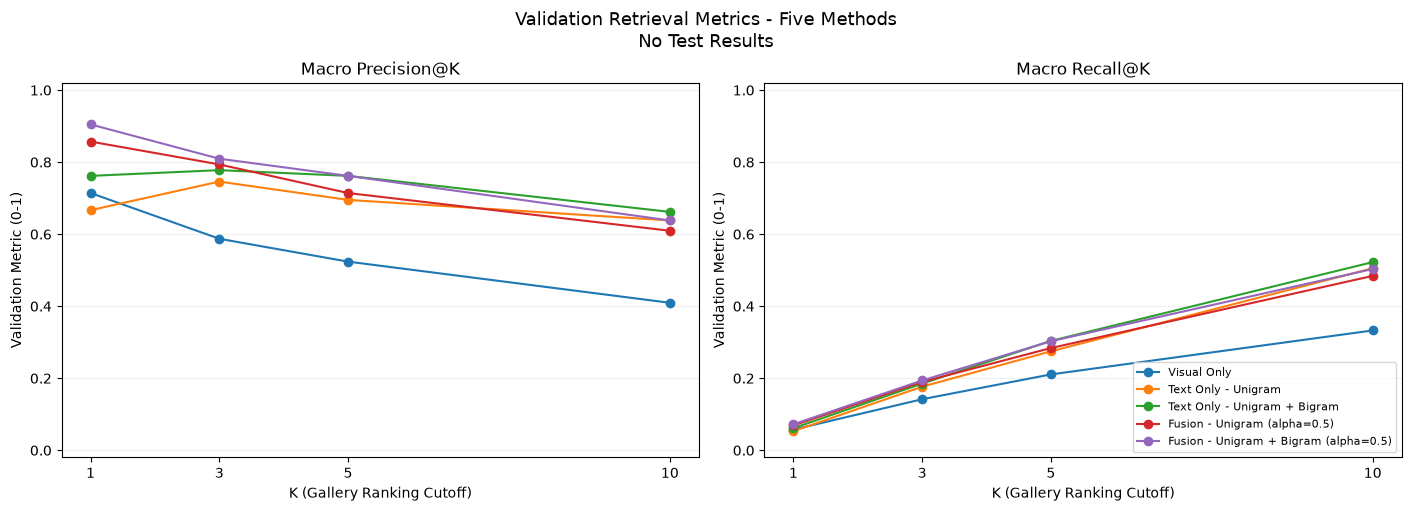

[SAVED] 211_validation_precision_recall_at_k.png


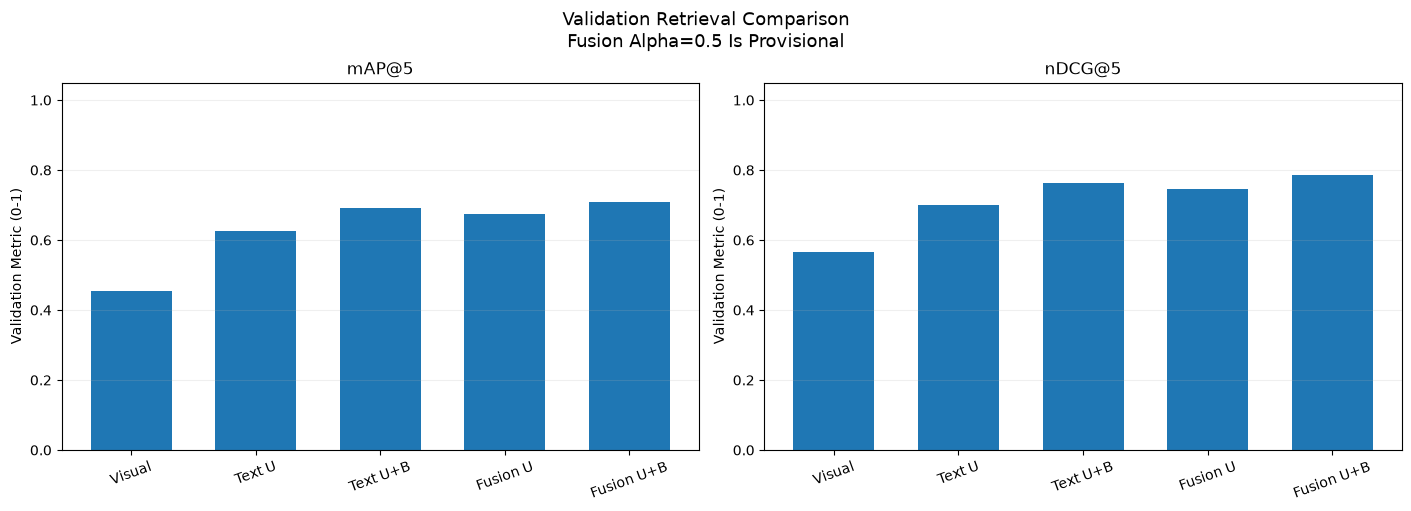

[SAVED] 212_validation_map_ndcg_at_5.png

4. SAVING VALIDATION METRIC REPORTS
------------------------------------------------------------------------
[SAVED] 653_validation_per_query_metrics.csv
[SAVED] 654_validation_macro_metric_summary.csv
[SAVED] 655_validation_per_class_metrics.csv
[SAVED] 656_validation_relevance_denominators.csv
[SAVED] 657_validation_metric_checks.csv
[SAVED] 658_validation_method_comparison_at_5.csv
[SAVED] 659_validation_metric_protocol.csv
[SAVED] 660_validation_metric_handoff.json

CELL 7 - VALIDATION RETRIEVAL METRICS COMPLETED
Gallery / Validation queries: 62 / 21
Metric calculations: 420
Method x K summaries: 20
Validation checks: 19 / 19
CSV reports: 7
Figures: 2
JSON handoff: 1

[PASS] All five retrieval metrics calculated.
[PASS] Gallery relevance denominators verified.
[PASS] Per-query metrics generated.
[PASS] Macro-averaged metrics generated.
[PASS] Per-class metrics generated.
[PASS] Validation metric comparisons generated.
[PASS] No test metrics

In [11]:
# ============================================================
# CELL 7 - VALIDATION RETRIEVAL METRICS
# Notebook: 06_multimodal_retrieval_evaluation.ipynb
# ============================================================

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display


print("NOTEBOOK 06 - VALIDATION RETRIEVAL METRICS")
print("=" * 72)

EVAL06_VALIDATION_METRICS_COMPLETED = False


# ============================================================
# 1. VALIDATE PREVIOUS CELL
# ============================================================

if globals().get(
    "EVAL06_VALIDATION_RANKING_COMPLETED",
    False
) is not True:

    raise RuntimeError(
        "Jalankan Cell 6 sampai selesai terlebih dahulu."
    )


METRIC07_K_VALUES = tuple(
    sorted({
        int(k)
        for k in EVAL06_TOP_K_VALUES
    })
)

METRIC07_METHODS = [
    item[0]
    for item in retr06_method_specs
]

METRIC07_MAX_K = max(
    METRIC07_K_VALUES
)

METRIC07_N_QUERY = len(
    retr06_query_ids
)

METRIC07_N_GALLERY = len(
    retr06_gallery_ids
)

METRIC07_TOL = 1e-10


EVAL06_METRICS_DIR = Path(
    EVAL06_METRICS_DIR
)

EVAL06_FIGURES_DIR = Path(
    EVAL06_FIGURES_DIR
)

EVAL06_METRICS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

EVAL06_FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)


if METRIC07_MAX_K > METRIC07_N_GALLERY:

    raise ValueError(
        "Top-K melebihi jumlah kandidat gallery."
    )


if (
    len(METRIC07_METHODS) != 5
    or
    len(set(METRIC07_METHODS)) != 5
):

    raise ValueError(
        "Harus ada lima konfigurasi retrieval "
        "unik dari Cell 6."
    )


if len(
    set(retr06_query_ids)
    &
    set(retr06_gallery_ids)
):

    raise ValueError(
        "Query validation tumpang tindih "
        "dengan gallery."
    )


# ============================================================
# 2. DEFINE EVALUATION METRIC PROTOCOL
# ============================================================

EVAL06_VALIDATION_METRIC_DEFINITIONS = {

    "relevance":
        "binary: query class equals gallery class",

    "precision_at_k":
        "relevant candidates in top K / K",

    "recall_at_k":
        "relevant candidates in top K / "
        "all relevant gallery candidates",

    "mrr_at_k":
        "reciprocal of rank of first relevant "
        "candidate within top K, or 0",

    "ap_at_k":
        "sum(precision at relevant ranks <= K) "
        "/ min(total relevant gallery, K)",

    "map_at_k":
        "arithmetic mean of AP@K across "
        "validation queries (macro query average)",

    "ndcg_at_k":
        "DCG@K / IDCG@K with binary relevance "
        "and log2 discount",

    "undefined_relevance":
        "blocked: every validation class must have "
        "at least one relevant gallery item",

    "ranking_ties":
        "similarity descending; sample_id ascending",

    "evaluation_partition":
        "validation only",

    "fusion_weight":
        "alpha=0.5 for demonstration; "
        "no parameter selection here",

    "methodological_approval":
        "pending upstream data/leakage review"
}


# ============================================================
# 3. DEFINE RETRIEVAL METRIC FUNCTIONS
# ============================================================

def metric07_calculate_at_k(
    ranked_relevance,
    gallery_relevant_count,
    k
):
    """
    Calculate five retrieval metrics for
    one query at one cutoff K.

    Parameters
    ----------
    ranked_relevance:
        Binary relevance vector ordered
        from highest similarity to lowest.

    gallery_relevant_count:
        Total number of relevant samples
        available in the reference gallery.

    k:
        Retrieval cutoff.

    Returns
    -------
    Dictionary containing:
        Precision@K
        Recall@K
        MRR@K
        AP@K
        nDCG@K

    Notes
    -----
    AP@K is normalized by min(R, K).

    This is a declared truncated-AP convention,
    rather than full-list average precision.
    """

    rel = np.asarray(
        ranked_relevance,
        dtype=np.int64
    ).reshape(-1)

    R = int(
        gallery_relevant_count
    )

    k = int(k)

    if R <= 0:

        raise ValueError(
            "Query tidak mempunyai item "
            "relevan di gallery."
        )

    if k < 1 or k > len(rel):

        raise ValueError(
            "Nilai K di luar rentang ranking."
        )

    if not np.isin(
        rel,
        (0, 1)
    ).all():

        raise ValueError(
            "Relevansi harus berupa 0/1."
        )

    if int(
        rel.sum()
    ) != R:

        raise ValueError(
            "Jumlah relevansi ranking tidak "
            "sama dengan gallery."
        )

    # --------------------------------------------------------
    # A. TOP-K RELEVANCE
    # --------------------------------------------------------

    top = rel[:k]

    positions = np.arange(
        1,
        k + 1,
        dtype=np.float64
    )

    hits = int(
        top.sum()
    )

    cumulative_hits = np.cumsum(
        top
    )

    # --------------------------------------------------------
    # B. PRECISION@K
    # --------------------------------------------------------

    precision = hits / k

    # --------------------------------------------------------
    # C. RECALL@K
    # --------------------------------------------------------

    recall = hits / R

    # --------------------------------------------------------
    # D. MRR@K
    # --------------------------------------------------------

    hit_positions = np.flatnonzero(
        top
    )

    if hit_positions.size:

        mrr = 1.0 / (
            int(hit_positions[0]) + 1
        )

    else:

        mrr = 0.0

    # --------------------------------------------------------
    # E. AP@K
    # --------------------------------------------------------

    precision_per_rank = (
        cumulative_hits / positions
    )

    ap = float(
        (
            precision_per_rank * top
        ).sum()
        /
        min(R, k)
    )

    # --------------------------------------------------------
    # F. nDCG@K
    # --------------------------------------------------------

    discounts = (
        1.0
        /
        np.log2(
            positions + 1.0
        )
    )

    dcg = float(
        np.dot(
            top,
            discounts
        )
    )

    ideal_hits = min(
        R,
        k
    )

    idcg = float(
        discounts[:ideal_hits].sum()
    )

    ndcg = (
        dcg / idcg
    )

    return {

        "relevant_in_top_k":
            hits,

        "gallery_relevant_count":
            R,

        "precision_at_k":
            float(precision),

        "recall_at_k":
            float(recall),

        "mrr_at_k":
            float(mrr),

        "ap_at_k":
            float(ap),

        "ndcg_at_k":
            float(ndcg)
    }


# ============================================================
# 4. INITIALIZE VALIDATION RECORDS
# ============================================================

metric07_checks = []


def metric07_check(
    category,
    test,
    passed,
    details=""
):

    metric07_checks.append({

        "category":
            category,

        "validation_check":
            test,

        "passed":
            bool(passed),

        "details":
            str(details)
    })


# ============================================================
# 5. UNIT TESTS - VERIFY METRIC FORMULAS
# ============================================================

# Example ranking:
#
# Rank:       1  2  3  4  5
# Relevant:   1  0  1  0  1
#
# Total relevant gallery items: 3

unit_a = metric07_calculate_at_k(
    [1, 0, 1, 0, 1],
    3,
    3
)


metric07_check(
    "Unit Tests",
    "Precision@3 = 2/3",

    np.isclose(
        unit_a["precision_at_k"],
        2 / 3
    )
)


metric07_check(
    "Unit Tests",
    "Recall@3 = 2/3",

    np.isclose(
        unit_a["recall_at_k"],
        2 / 3
    )
)


metric07_check(
    "Unit Tests",
    "MRR@3 = 1",

    np.isclose(
        unit_a["mrr_at_k"],
        1.0
    )
)


metric07_check(
    "Unit Tests",
    "AP@3 = (1 + 2/3) / 3",

    np.isclose(
        unit_a["ap_at_k"],
        (1 + 2 / 3) / 3
    )
)


ideal_3 = (
    1
    +
    1 / np.log2(3)
    +
    1 / np.log2(4)
)


metric07_check(
    "Unit Tests",
    "nDCG@3 uses binary relevance discount",

    np.isclose(
        unit_a["ndcg_at_k"],

        (
            1
            +
            1 / np.log2(4)
        )
        /
        ideal_3
    )
)


# Example with no relevant result within Top-2.

unit_b = metric07_calculate_at_k(
    [0, 0, 1, 0],
    1,
    2
)


metric07_check(
    "Unit Tests",
    "No relevant Top-2 produces all zeros",

    all(
        np.isclose(
            unit_b[metric],
            0
        )

        for metric in (
            "precision_at_k",
            "recall_at_k",
            "mrr_at_k",
            "ap_at_k",
            "ndcg_at_k"
        )
    )
)


# First relevant result at rank 3.

unit_c = metric07_calculate_at_k(
    [0, 0, 1, 0],
    1,
    3
)


metric07_check(
    "Unit Tests",
    "First relevant at rank 3 yields MRR=1/3",

    np.isclose(
        unit_c["mrr_at_k"],
        1 / 3
    )
)


print("\n1. METRIC FORMULA UNIT TESTS")
print("-" * 72)

print(
    "[PASS] Precision, Recall, MRR, AP, nDCG "
    "formula checks prepared."
)


# ============================================================
# 6. PREPARE AUTHORITATIVE LABEL MAPPINGS
# ============================================================

query_map = dict(
    zip(
        map(str, retr06_query_ids),
        map(str, retr06_query_labels)
    )
)

gallery_map = dict(
    zip(
        map(str, retr06_gallery_ids),
        map(str, retr06_gallery_labels)
    )
)


if (
    len(query_map) != METRIC07_N_QUERY
    or
    len(gallery_map) != METRIC07_N_GALLERY
):

    raise ValueError(
        "sample_id duplikat pada query "
        "atau gallery."
    )


# ============================================================
# 7. CALCULATE RELEVANT GALLERY DENOMINATORS
# ============================================================

# Recall@K requires the total number of
# relevant samples in the gallery.
#
# Calculate once per validation query,
# independently from retrieval ranking.

relevance_rows = []

for query_id in map(
    str,
    retr06_query_ids
):

    label = query_map[
        query_id
    ]

    relevant_gallery_ids = [

        gallery_id

        for gallery_id, gallery_class
        in gallery_map.items()

        if gallery_class == label
    ]

    relevance_rows.append({

        "query_sample_id":
            query_id,

        "query_class":
            label,

        "relevant_gallery_count":
            len(
                relevant_gallery_ids
            ),

        "gallery_count":
            METRIC07_N_GALLERY,

        "relevant_gallery_fraction":
            (
                len(relevant_gallery_ids)
                /
                METRIC07_N_GALLERY
            )
    })


EVAL06_VALIDATION_RELEVANCE_COUNTS_DF = (
    pd.DataFrame(
        relevance_rows
    )
)


missing_relevance = (
    EVAL06_VALIDATION_RELEVANCE_COUNTS_DF.loc[
        EVAL06_VALIDATION_RELEVANCE_COUNTS_DF[
            "relevant_gallery_count"
        ].eq(0)
    ]
)


if not missing_relevance.empty:

    raise ValueError(
        "Ada kelas query validation tanpa "
        "item relevan di gallery:\n"

        +

        missing_relevance.to_string(
            index=False
        )
    )


metric07_check(
    "Relevance",
    "All validation queries have relevant gallery items",

    missing_relevance.empty
)


# ============================================================
# 8. VALIDATE CELL 6 RANKING DATA
# ============================================================

rankings = (
    EVAL06_VALIDATION_RANKING_ALL_DF
    .copy()
)


required_columns = {

    "method",
    "query_partition",
    "query_sample_id",
    "query_class",
    "gallery_sample_id",
    "gallery_class",
    "rank",
    "similarity_score",
    "same_class_relevance"
}


if not required_columns.issubset(
    rankings.columns
):

    raise ValueError(
        "Missing columns in Cell 6 rankings: "

        +

        str(
            sorted(
                required_columns
                -
                set(rankings.columns)
            )
        )
    )


expected_rows = (
    len(METRIC07_METHODS)
    *
    METRIC07_N_QUERY
    *
    METRIC07_N_GALLERY
)


if len(rankings) != expected_rows:

    raise ValueError(
        f"Ranking rows={len(rankings)}; "
        f"expected={expected_rows}"
    )


if not rankings[
    "query_partition"
].eq("validation").all():

    raise ValueError(
        "Cell 7 hanya menerima "
        "ranking validation."
    )


if rankings.duplicated(
    [
        "method",
        "query_sample_id",
        "rank"
    ]
).any():

    raise ValueError(
        "Duplicate rank positions "
        "in Cell 6 output."
    )


if rankings.duplicated(
    [
        "method",
        "query_sample_id",
        "gallery_sample_id"
    ]
).any():

    raise ValueError(
        "Duplicate gallery candidates "
        "in query ranking."
    )


if not rankings[
    "method"
].isin(
    METRIC07_METHODS
).all():

    raise ValueError(
        "Unexpected retrieval method "
        "in Cell 6 rankings."
    )


if not rankings[
    "query_sample_id"
].astype(str).isin(
    query_map
).all():

    raise ValueError(
        "Unexpected validation query ID."
    )


if not rankings[
    "gallery_sample_id"
].astype(str).isin(
    gallery_map
).all():

    raise ValueError(
        "Unexpected gallery sample ID."
    )


if not np.isfinite(
    rankings[
        "similarity_score"
    ].to_numpy(dtype=float)
).all():

    raise ValueError(
        "Nonfinite similarity score."
    )


# ============================================================
# 9. VERIFY QUERY AND GALLERY LABEL CONSISTENCY
# ============================================================

rankings[
    "query_sample_id"
] = (
    rankings[
        "query_sample_id"
    ].astype(str)
)

rankings[
    "gallery_sample_id"
] = (
    rankings[
        "gallery_sample_id"
    ].astype(str)
)

rankings[
    "rank"
] = (
    rankings["rank"]
    .astype(int)
)

rankings[
    "query_class"
] = (
    rankings[
        "query_class"
    ].astype(str)
)

rankings[
    "gallery_class"
] = (
    rankings[
        "gallery_class"
    ].astype(str)
)


if not rankings[
    "query_class"
].eq(
    rankings[
        "query_sample_id"
    ].map(query_map)
).all():

    raise ValueError(
        "Ranking query labels disagree "
        "with authoritative query labels."
    )


if not rankings[
    "gallery_class"
].eq(
    rankings[
        "gallery_sample_id"
    ].map(gallery_map)
).all():

    raise ValueError(
        "Ranking gallery labels disagree "
        "with authoritative gallery labels."
    )


if not rankings[
    "same_class_relevance"
].astype(bool).eq(

    rankings[
        "query_class"
    ].eq(
        rankings[
            "gallery_class"
        ]
    )

).all():

    raise ValueError(
        "Cell 6 relevance indicators "
        "disagree with actual class labels."
    )


# ============================================================
# 10. COMPUTE PER-QUERY METRICS
# ============================================================

metric07_rows = []


for (
    method,
    query_id
), group in rankings.groupby(
    [
        "method",
        "query_sample_id"
    ],
    sort=False
):

    group = group.sort_values(
        "rank",
        kind="stable"
    )

    positions = (
        group["rank"]
        .to_numpy(dtype=int)
    )

    expected_positions = np.arange(
        1,
        METRIC07_N_GALLERY + 1
    )

    if not np.array_equal(
        positions,
        expected_positions
    ):

        raise ValueError(
            "Incomplete ranking positions for "
            f"{method}, query={query_id}"
        )

    if len(group) != METRIC07_N_GALLERY:

        raise ValueError(
            "Incomplete gallery for "
            f"query={query_id}"
        )

    relevance = (
        group[
            "same_class_relevance"
        ]
        .astype(int)
        .to_numpy()
    )

    query_class = (
        query_map[
            query_id
        ]
    )

    R = int(
        (
            np.asarray(
                retr06_gallery_labels,
                dtype=str
            )
            ==
            query_class
        ).sum()
    )

    # --------------------------------------------------------
    # CALCULATE METRICS FOR EACH K
    # --------------------------------------------------------

    for k in METRIC07_K_VALUES:

        metrics = metric07_calculate_at_k(
            ranked_relevance=relevance,

            gallery_relevant_count=R,

            k=k
        )

        metric07_rows.append({

            "method":
                method,

            "query_partition":
                "validation",

            "query_sample_id":
                query_id,

            "query_class":
                query_class,

            "k":
                int(k),

            **metrics,

            "independent_test_evaluation":
                False
        })


EVAL06_VALIDATION_PER_QUERY_METRICS_DF = (
    pd.DataFrame(
        metric07_rows
    )
)


# ============================================================
# 11. CALCULATE MACRO METRICS
# ============================================================

# Macro averaging:
#
# Each validation query has equal weight.
#
# This avoids giving more weight to queries
# simply because their gallery class contains
# more relevant candidates.

metric_cols = [

    "precision_at_k",
    "recall_at_k",
    "mrr_at_k",
    "ap_at_k",
    "ndcg_at_k"
]


summary_rows = []


for method in METRIC07_METHODS:

    for k in METRIC07_K_VALUES:

        subset = (
            EVAL06_VALIDATION_PER_QUERY_METRICS_DF.loc[
                (
                    EVAL06_VALIDATION_PER_QUERY_METRICS_DF[
                        "method"
                    ].eq(method)
                )

                &

                (
                    EVAL06_VALIDATION_PER_QUERY_METRICS_DF[
                        "k"
                    ].eq(k)
                )
            ]
        )

        if len(subset) != METRIC07_N_QUERY:

            raise ValueError(
                "Wrong query count for "
                f"{method}, K={k}"
            )

        row = {

            "method":
                method,

            "k":
                k,

            "validation_queries":
                len(subset)
        }

        for column in metric_cols:

            # AP@K becomes mAP@K after
            # averaging across queries.

            prefix = (
                "map_at_k"

                if column == "ap_at_k"

                else f"mean_{column}"
            )

            row[prefix] = float(
                subset[column].mean()
            )

            row[
                f"std_{column}"
            ] = float(
                subset[column].std(
                    ddof=1
                )
            ) if len(subset) > 1 else 0.0

        row[
            "independent_test_evaluation"
        ] = False

        summary_rows.append(
            row
        )


EVAL06_VALIDATION_METRIC_SUMMARY_DF = (
    pd.DataFrame(
        summary_rows
    )
)


# ============================================================
# 12. CALCULATE PER-CLASS VALIDATION METRICS
# ============================================================

class_rows = []


for (
    method,
    query_class,
    k
), subset in (
    EVAL06_VALIDATION_PER_QUERY_METRICS_DF
    .groupby(
        [
            "method",
            "query_class",
            "k"
        ],
        sort=False
    )
):

    row = {

        "method":
            method,

        "query_class":
            query_class,

        "k":
            int(k),

        "query_count":
            len(subset)
    }

    for column in metric_cols:

        row[
            "mean_" + column
        ] = float(
            subset[column].mean()
        )

    row[
        "map_at_k"
    ] = row[
        "mean_ap_at_k"
    ]

    class_rows.append(
        row
    )


EVAL06_VALIDATION_CLASS_METRICS_DF = (
    pd.DataFrame(
        class_rows
    )
)


# ============================================================
# 13. COMPARE METHODS AT K=5
# ============================================================

# This is a descriptive comparison.
#
# Do not select a winning alpha or final
# model configuration in this cell.

EVAL06_VALIDATION_METHOD_COMPARISON_DF = (

    EVAL06_VALIDATION_METRIC_SUMMARY_DF.loc[
        EVAL06_VALIDATION_METRIC_SUMMARY_DF[
            "k"
        ].eq(5),

        [
            "method",
            "validation_queries",
            "mean_precision_at_k",
            "mean_recall_at_k",
            "mean_mrr_at_k",
            "map_at_k",
            "mean_ndcg_at_k"
        ]
    ]

    .copy()
)


EVAL06_VALIDATION_METHOD_COMPARISON_DF[
    "method"
] = pd.Categorical(

    EVAL06_VALIDATION_METHOD_COMPARISON_DF[
        "method"
    ],

    categories=METRIC07_METHODS,

    ordered=True
)


EVAL06_VALIDATION_METHOD_COMPARISON_DF = (

    EVAL06_VALIDATION_METHOD_COMPARISON_DF

    .sort_values(
        "method"
    )

    .reset_index(
        drop=True
    )
)


EVAL06_VALIDATION_METHOD_COMPARISON_DF[
    "method"
] = (

    EVAL06_VALIDATION_METHOD_COMPARISON_DF[
        "method"
    ]

    .astype(str)
)


# ============================================================
# 14. VALIDATE METRIC COUNTS
# ============================================================

expected_per_query = (
    len(METRIC07_METHODS)
    *
    METRIC07_N_QUERY
    *
    len(METRIC07_K_VALUES)
)


metric07_check(
    "Shape",
    "Per-query metric row count",

    len(
        EVAL06_VALIDATION_PER_QUERY_METRICS_DF
    )
    ==
    expected_per_query
)


metric07_check(
    "Shape",
    "Twenty method-by-K macro rows",

    len(
        EVAL06_VALIDATION_METRIC_SUMMARY_DF
    )

    ==

    len(METRIC07_METHODS)
    *
    len(METRIC07_K_VALUES)
)


metric07_check(
    "Shape",
    "One comparison row for each of five methods",

    len(
        EVAL06_VALIDATION_METHOD_COMPARISON_DF
    )

    ==

    len(METRIC07_METHODS)
)


# ============================================================
# 15. VALIDATE METRIC VALUES
# ============================================================

metric07_check(
    "Numerics",
    "All five per-query metrics bounded by [0,1]",

    bool(
        EVAL06_VALIDATION_PER_QUERY_METRICS_DF[
            metric_cols
        ]

        .apply(
            lambda column:
                column.between(
                    -METRIC07_TOL,
                    1 + METRIC07_TOL
                ).all()
        )

        .all()
    )
)


metric07_check(
    "Numerics",
    "All five per-query metrics are finite",

    bool(
        np.isfinite(
            EVAL06_VALIDATION_PER_QUERY_METRICS_DF[
                metric_cols
            ].to_numpy(dtype=float)
        ).all()
    )
)


# ============================================================
# 16. RECONCILE PRECISION AND RECALL
# ============================================================

metric07_check(
    "Definitions",
    "Precision and recall match retrieved relevant counts",

    bool(

        np.allclose(

            EVAL06_VALIDATION_PER_QUERY_METRICS_DF[
                "precision_at_k"
            ].to_numpy()

            *

            EVAL06_VALIDATION_PER_QUERY_METRICS_DF[
                "k"
            ].to_numpy(),

            EVAL06_VALIDATION_PER_QUERY_METRICS_DF[
                "relevant_in_top_k"
            ].to_numpy(),

            atol=METRIC07_TOL,
            rtol=0
        )

        and

        np.allclose(

            EVAL06_VALIDATION_PER_QUERY_METRICS_DF[
                "recall_at_k"
            ].to_numpy()

            *

            EVAL06_VALIDATION_PER_QUERY_METRICS_DF[
                "gallery_relevant_count"
            ].to_numpy(),

            EVAL06_VALIDATION_PER_QUERY_METRICS_DF[
                "relevant_in_top_k"
            ].to_numpy(),

            atol=METRIC07_TOL,
            rtol=0
        )
    )
)


metric07_check(
    "Relevance",
    "Relevance denominator invariant across methods",

    bool(

        EVAL06_VALIDATION_PER_QUERY_METRICS_DF

        .groupby(
            "query_sample_id"
        )[
            "gallery_relevant_count"
        ]

        .nunique()

        .eq(1)

        .all()
    )
)


metric07_check(
    "Relevance",
    "Every query has positive relevant gallery count",

    bool(
        EVAL06_VALIDATION_PER_QUERY_METRICS_DF[
            "gallery_relevant_count"
        ].gt(0).all()
    )
)


# ============================================================
# 17. VALIDATE MONOTONIC RECALL AND MRR
# ============================================================

# Recall@K and MRR@K must not decrease
# as K increases for the same query.
#
# Precision and nDCG are not required
# to be monotonic.

monotonic = True

for _, group in (
    EVAL06_VALIDATION_PER_QUERY_METRICS_DF
    .groupby(
        [
            "method",
            "query_sample_id"
        ]
    )
):

    group = (
        group.sort_values(
            "k"
        )
    )

    recall_values = (
        group[
            "recall_at_k"
        ].to_numpy()
    )

    mrr_values = (
        group[
            "mrr_at_k"
        ].to_numpy()
    )

    if (

        (
            np.diff(
                recall_values
            )
            <
            -METRIC07_TOL
        ).any()

        or

        (
            np.diff(
                mrr_values
            )
            <
            -METRIC07_TOL
        ).any()
    ):

        monotonic = False

        break


metric07_check(
    "Numerics",
    "Recall@K and MRR@K are nondecreasing with K",
    monotonic
)


# ============================================================
# 18. VERIFY VALIDATION-ONLY POLICY
# ============================================================

metric07_check(
    "Partition",
    "All rows use validation queries only",

    bool(
        EVAL06_VALIDATION_PER_QUERY_METRICS_DF[
            "query_partition"
        ].eq(
            "validation"
        ).all()
    )
)


metric07_check(
    "Methodology",
    "No test evaluation or alpha optimization performed",

    bool(
        not EVAL06_VALIDATION_PER_QUERY_METRICS_DF[
            "independent_test_evaluation"
        ].any()
    )
)


# ============================================================
# 19. FINAL METRIC VALIDATION
# ============================================================

EVAL06_VALIDATION_METRIC_CHECKS_DF = (
    pd.DataFrame(
        metric07_checks
    )
)


failed = (
    EVAL06_VALIDATION_METRIC_CHECKS_DF.loc[
        ~EVAL06_VALIDATION_METRIC_CHECKS_DF[
            "passed"
        ]
    ]
)


if not failed.empty:

    raise AssertionError(
        "Cell 7 metric checks failed:\n"

        +

        failed.to_string(
            index=False
        )
    )


print("\n1. RELEVANCE DENOMINATORS")
print("-" * 72)

display(
    EVAL06_VALIDATION_RELEVANCE_COUNTS_DF
    .head(10)
)


print("\n2. VALIDATION MACRO METRICS")
print("-" * 72)

display(
    EVAL06_VALIDATION_METRIC_SUMMARY_DF[
        [
            "method",
            "k",
            "validation_queries",
            "mean_precision_at_k",
            "mean_recall_at_k",
            "mean_mrr_at_k",
            "map_at_k",
            "mean_ndcg_at_k"
        ]
    ].round(4)
)


print("\n3. METHOD COMPARISON AT K=5")
print("-" * 72)

display(
    EVAL06_VALIDATION_METHOD_COMPARISON_DF
    .round(4)
)


# ============================================================
# 20. FIGURE 211 - PRECISION AND RECALL AT K
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
    constrained_layout=True
)


for method in METRIC07_METHODS:

    subset = (
        EVAL06_VALIDATION_METRIC_SUMMARY_DF.loc[
            EVAL06_VALIDATION_METRIC_SUMMARY_DF[
                "method"
            ].eq(method)
        ]

        .sort_values(
            "k"
        )
    )

    axes[0].plot(
        subset["k"],

        subset[
            "mean_precision_at_k"
        ],

        marker="o",

        label=method
    )

    axes[1].plot(
        subset["k"],

        subset[
            "mean_recall_at_k"
        ],

        marker="o",

        label=method
    )


for axis, title in zip(
    axes,

    [
        "Macro Precision@K",
        "Macro Recall@K"
    ]
):

    axis.set_xticks(
        METRIC07_K_VALUES
    )

    axis.set_ylim(
        -0.02,
        1.02
    )

    axis.set_xlabel(
        "K (Gallery Ranking Cutoff)"
    )

    axis.set_ylabel(
        "Validation Metric (0-1)"
    )

    axis.set_title(
        title
    )

    axis.grid(
        axis="y",
        alpha=0.2
    )


axes[1].legend(
    loc="lower right",
    fontsize=8
)


fig.suptitle(
    "Validation Retrieval Metrics - Five Methods\n"
    "No Test Results",
    fontsize=13
)


EVAL06_METRIC_FIGURE_211 = (
    EVAL06_FIGURES_DIR
    /
    "211_validation_precision_recall_at_k.png"
)


fig.savefig(
    EVAL06_METRIC_FIGURE_211,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print(
    "[SAVED]",
    EVAL06_METRIC_FIGURE_211.name
)


# ============================================================
# 21. FIGURE 212 - MAP@5 AND NDCG@5
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
    constrained_layout=True
)


labels = [
    "Visual",
    "Text U",
    "Text U+B",
    "Fusion U",
    "Fusion U+B"
]


positions = np.arange(
    len(labels)
)


for axis, metric_name, title in zip(

    axes,

    [
        "map_at_k",
        "mean_ndcg_at_k"
    ],

    [
        "mAP@5",
        "nDCG@5"
    ]
):

    values = (
        EVAL06_VALIDATION_METHOD_COMPARISON_DF[
            metric_name
        ].to_numpy(dtype=float)
    )

    axis.bar(
        positions,
        values,
        width=0.65
    )

    axis.set_xticks(
        positions,

        labels=labels,

        rotation=20
    )

    axis.set_ylim(
        0,
        1.05
    )

    axis.set_ylabel(
        "Validation Metric (0-1)"
    )

    axis.set_title(
        title
    )

    axis.grid(
        axis="y",
        alpha=0.2
    )


fig.suptitle(
    "Validation Retrieval Comparison\n"
    "Fusion Alpha=0.5 Is Provisional",
    fontsize=13
)


EVAL06_METRIC_FIGURE_212 = (
    EVAL06_FIGURES_DIR
    /
    "212_validation_map_ndcg_at_5.png"
)


fig.savefig(
    EVAL06_METRIC_FIGURE_212,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print(
    "[SAVED]",
    EVAL06_METRIC_FIGURE_212.name
)


# ============================================================
# 22. CREATE METRIC PROTOCOL REPORT
# ============================================================

EVAL06_VALIDATION_METRIC_PROTOCOL_DF = (
    pd.DataFrame([

        {
            "parameter":
                key,

            "definition":
                value
        }

        for key, value in (
            EVAL06_VALIDATION_METRIC_DEFINITIONS.items()
        )
    ])
)


# ============================================================
# 23. SAVE CSV REPORTS
# ============================================================

metric07_reports = {

    "653_validation_per_query_metrics.csv":
        EVAL06_VALIDATION_PER_QUERY_METRICS_DF,

    "654_validation_macro_metric_summary.csv":
        EVAL06_VALIDATION_METRIC_SUMMARY_DF,

    "655_validation_per_class_metrics.csv":
        EVAL06_VALIDATION_CLASS_METRICS_DF,

    "656_validation_relevance_denominators.csv":
        EVAL06_VALIDATION_RELEVANCE_COUNTS_DF,

    "657_validation_metric_checks.csv":
        EVAL06_VALIDATION_METRIC_CHECKS_DF,

    "658_validation_method_comparison_at_5.csv":
        EVAL06_VALIDATION_METHOD_COMPARISON_DF,

    "659_validation_metric_protocol.csv":
        EVAL06_VALIDATION_METRIC_PROTOCOL_DF
}


print("\n4. SAVING VALIDATION METRIC REPORTS")
print("-" * 72)


for filename, dataframe in (
    metric07_reports.items()
):

    path = (
        EVAL06_METRICS_DIR
        /
        filename
    )

    dataframe.to_csv(
        path,
        index=False,
        encoding="utf-8-sig"
    )

    print(
        "[SAVED]",
        filename
    )


# ============================================================
# 24. SAVE JSON HANDOFF
# ============================================================

EVAL06_VALIDATION_METRIC_HANDOFF = {

    "notebook":
        "06_multimodal_retrieval_evaluation.ipynb",

    "cell":
        7,

    "partition":
        "validation",

    "gallery_count":
        METRIC07_N_GALLERY,

    "query_count":
        METRIC07_N_QUERY,

    "methods":
        METRIC07_METHODS,

    "top_k_values":
        list(
            METRIC07_K_VALUES
        ),

    "primary_selection_metric":
        EVAL06_PRIMARY_SELECTION_METRIC,

    "metric_definitions":
        EVAL06_VALIDATION_METRIC_DEFINITIONS,

    "default_alpha_for_comparison":
        0.5,

    "alpha_optimized":
        False,

    "test_evaluated":
        False,

    "independent_evaluation_approved":
        False,

    "methodological_review_reasons":
        list(
            dict.fromkeys(
                globals().get(
                    "EVAL06_VALIDATION_RANKING_REVIEW_REASONS",
                    []
                )
            )
        ),

    "next_cell":
        "Cell 8 - Fusion Alpha Sensitivity on Validation"
}


EVAL06_VALIDATION_METRIC_HANDOFF_PATH = (
    EVAL06_METRICS_DIR
    /
    "660_validation_metric_handoff.json"
)


EVAL06_VALIDATION_METRIC_HANDOFF_PATH.write_text(

    json.dumps(
        EVAL06_VALIDATION_METRIC_HANDOFF,

        indent=2,

        ensure_ascii=False,

        allow_nan=False
    ),

    encoding="utf-8"
)


print(
    "[SAVED]",
    EVAL06_VALIDATION_METRIC_HANDOFF_PATH.name
)


# ============================================================
# 25. FINAL ARTIFACT VALIDATION
# ============================================================

assert all(

    (
        EVAL06_METRICS_DIR
        /
        filename
    ).is_file()

    for filename in metric07_reports
)


assert (
    EVAL06_VALIDATION_METRIC_HANDOFF_PATH
    .is_file()
)


assert all(

    path.is_file()
    and path.stat().st_size > 0

    for path in (

        EVAL06_METRIC_FIGURE_211,
        EVAL06_METRIC_FIGURE_212
    )
)


EVAL06_VALIDATION_METRICS_COMPLETED = True


# ============================================================
# 26. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 72)

print("CELL 7 - VALIDATION RETRIEVAL METRICS COMPLETED")

print("=" * 72)


print(
    "Gallery / Validation queries:",
    METRIC07_N_GALLERY,
    "/",
    METRIC07_N_QUERY
)


print(
    "Metric calculations:",
    len(
        EVAL06_VALIDATION_PER_QUERY_METRICS_DF
    )
)


print(
    "Method x K summaries:",
    len(
        EVAL06_VALIDATION_METRIC_SUMMARY_DF
    )
)


print(
    "Validation checks:",
    int(
        EVAL06_VALIDATION_METRIC_CHECKS_DF[
            "passed"
        ].sum()
    ),
    "/",
    len(
        EVAL06_VALIDATION_METRIC_CHECKS_DF
    )
)


print(
    "CSV reports:",
    len(metric07_reports)
)


print(
    "Figures: 2"
)

print(
    "JSON handoff: 1"
)


print(
    "\n[PASS] All five retrieval metrics calculated."
)

print(
    "[PASS] Gallery relevance denominators verified."
)

print(
    "[PASS] Per-query metrics generated."
)

print(
    "[PASS] Macro-averaged metrics generated."
)

print(
    "[PASS] Per-class metrics generated."
)

print(
    "[PASS] Validation metric comparisons generated."
)

print(
    "[PASS] No test metrics or alpha selection performed."
)


print(
    "\n[INFO] Interpretation remains subject "
    "to earlier leakage review."
)


print("\n" + "=" * 72)

print("NOTEBOOK 06 - CELL 7 COMPLETED")

print("=" * 72)


print(
    "\nNext: Cell 8 - Fusion Alpha Sensitivity on Validation"
)

NOTEBOOK 06 - FUSION ALPHA SENSITIVITY (VALIDATION)

1. ALPHA EXPERIMENT INVENTORY
--------------------------------------------------------------------------
Configurations: 22
Per-query metric rows: 1848
Top-10 ranking rows: 4620

2. FUSION ALPHA SENSITIVITY AT K=5
--------------------------------------------------------------------------


,text_configuration,alpha_index,alpha,validation_queries,mean_precision_at_k,mean_recall_at_k,mean_mrr_at_k,map_at_k,mean_ndcg_at_k
0,Unigram,0,0.0,21,0.6952,0.2748,0.7738,0.6246,0.6988
1,Unigram,1,0.1,21,0.6952,0.2748,0.7857,0.6270,0.7020
2,Unigram,2,0.2,21,0.7048,0.2788,0.8095,0.6448,0.7175
3,Unigram,3,0.3,21,0.7143,0.2831,0.8429,0.6595,0.7343
4,Unigram,4,0.4,21,0.7238,0.2874,0.8429,0.6629,0.7399
5,Unigram,5,0.5,21,0.7143,0.2838,0.8905,0.6735,0.7469
6,Unigram,6,0.6,21,0.7048,0.2791,0.9143,0.6773,0.7516
7,Unigram,7,0.7,21,0.6952,0.2751,0.9143,0.6687,0.7460
8,Unigram,8,0.8,21,0.6762,0.2687,0.9000,0.6359,0.7224
9,Unigram,9,0.9,21,0.5810,0.2314,0.8667,0.5337,0.6358



3. CELL 7 ANCHOR VERIFICATION
--------------------------------------------------------------------------
Passed: 24 / 24
Maximum absolute metric difference: 0.000e+00


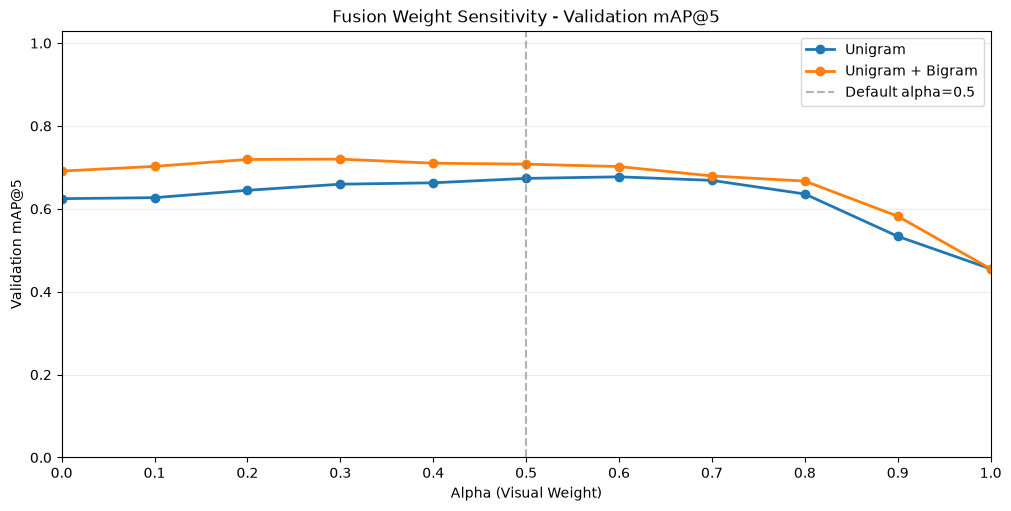

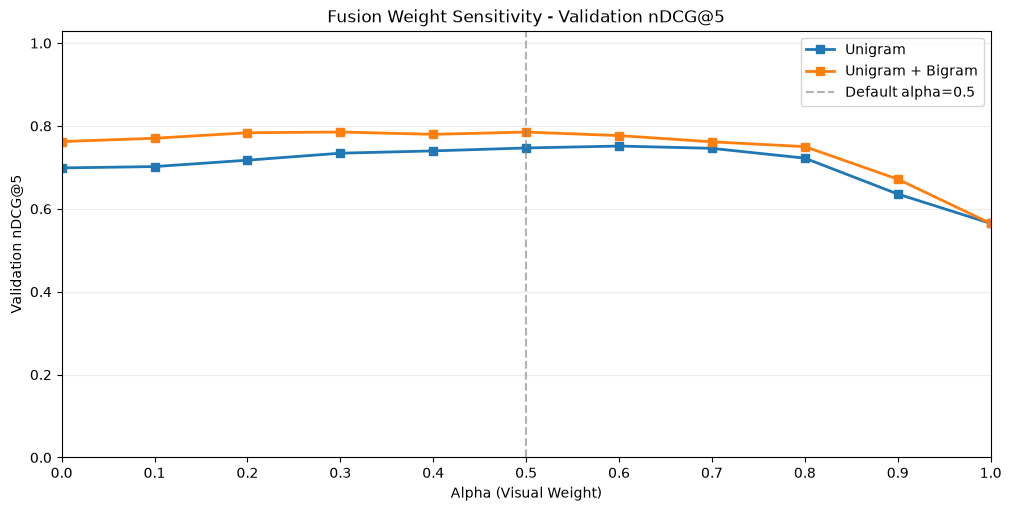


4. SAVING ALPHA SENSITIVITY REPORTS
--------------------------------------------------------------------------
[SAVED] 661_validation_alpha_grid.csv
[SAVED] 662_validation_alpha_per_query_metrics.csv
[SAVED] 663_validation_alpha_macro_metrics.csv
[SAVED] 664_validation_alpha_per_class_metrics.csv
[SAVED] 665_validation_alpha_top10_rankings.csv
[SAVED] 666_validation_alpha_technical_checks.csv
[SAVED] 667_validation_alpha_sensitivity_at_5.csv
[SAVED] 668_validation_alpha_cell7_anchor_checks.csv
[SAVED] 669_validation_alpha_tie_audit.csv

CELL 8 - FUSION ALPHA SENSITIVITY COMPLETED
Alpha/text combinations: 22
Validation queries: 21
Gallery samples: 62
Per-query metric rows: 1848
Macro summary rows: 88
Technical checks passed: 20/20
CSV reports: 9
Figures: 2
JSON handoff: 1

[PASS] Validation-only alpha sensitivity computed.
[PASS] Alpha 0, 0.5 and 1 reconciled with Cell 7.
[INFO] No alpha/configuration selected yet.
[INFO] No test performance calculated or inspected.
[INFO] Methodologic

In [12]:
# ============================================================
# CELL 8 - FUSION ALPHA SENSITIVITY ON VALIDATION
# Notebook: 06_multimodal_retrieval_evaluation.ipynb
# ============================================================

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

print("NOTEBOOK 06 - FUSION ALPHA SENSITIVITY (VALIDATION)")
print("=" * 74)

EVAL06_ALPHA_SENSITIVITY_COMPLETED = False
EVAL06_ALPHA_SELECTED = False

# ============================================================
# 1. DEPENDENCY CHECKS AND CONFIGURATION
# ============================================================

if not globals().get(
    "EVAL06_VALIDATION_METRICS_COMPLETED", False
):
    raise RuntimeError(
        "Jalankan Cell 7 hingga selesai sebelum Cell 8."
    )

if not globals().get(
    "EVAL06_SIMILARITY_CALCULATION_COMPLETED", False
):
    raise RuntimeError(
        "Output similarity Cell 5 belum tersedia."
    )

ALPHA08_GRID = np.round(
    np.linspace(0.0, 1.0, 11), 1
)

ALPHA08_TEXT_CONFIGS = (
    "Unigram",
    "Unigram + Bigram"
)

ALPHA08_K_VALUES = tuple(
    sorted(set(int(k) for k in EVAL06_TOP_K_VALUES))
)

ALPHA08_MAX_K = max(ALPHA08_K_VALUES)
ALPHA08_TOL = 1e-8

ALPHA08_METRIC_COLUMNS = (
    "precision_at_k",
    "recall_at_k",
    "mrr_at_k",
    "ap_at_k",
    "ndcg_at_k"
)

ALPHA08_MEAN_COLUMNS = {
    "precision_at_k": "mean_precision_at_k",
    "recall_at_k": "mean_recall_at_k",
    "mrr_at_k": "mean_mrr_at_k",
    "ap_at_k": "map_at_k",
    "ndcg_at_k": "mean_ndcg_at_k"
}

assert np.allclose(
    ALPHA08_GRID,
    np.asarray(EVAL06_ALPHA_GRID, dtype=float)
)

assert ALPHA08_K_VALUES == (1, 3, 5, 10)
assert callable(metric07_calculate_at_k)
assert EVAL06_FIT_POLICY == "gallery_only"
assert EVAL06_ALLOW_TEST_SET_FOR_WEIGHT_SELECTION is False

EVAL06_METRICS_DIR = Path(EVAL06_METRICS_DIR)
EVAL06_FIGURES_DIR = Path(EVAL06_FIGURES_DIR)

EVAL06_METRICS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

EVAL06_FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

alpha08_checks = []


def alpha08_check(category, name, condition, detail=""):
    alpha08_checks.append({
        "category": category,
        "validation_check": name,
        "passed": bool(condition),
        "detail": str(detail)
    })


# ============================================================
# 2. LOAD VALIDATION QUERY AND GALLERY IDENTITIES
# ============================================================

alpha08_query_ids = np.asarray(
    EVAL06_SIMILARITY_QUERY_IDS["validation"],
    dtype=str
)

alpha08_gallery_ids = np.asarray(
    EVAL06_SIMILARITY_GALLERY_IDS,
    dtype=str
)

alpha08_query_labels = np.asarray(
    retr06_query_labels,
    dtype=str
)

alpha08_gallery_labels = np.asarray(
    retr06_gallery_labels,
    dtype=str
)

n_queries = len(alpha08_query_ids)
n_gallery = len(alpha08_gallery_ids)

if not (
    n_queries > 0
    and n_gallery >= ALPHA08_MAX_K
):
    raise ValueError(
        "Validation query/gallery tidak cukup untuk Top-K."
    )

if not (
    len(alpha08_query_labels) == n_queries
    and len(alpha08_gallery_labels) == n_gallery
):
    raise ValueError(
        "Jumlah label dan sample ID tidak sejajar."
    )

if len(set(alpha08_query_ids)) != n_queries:
    raise ValueError(
        "Terdapat duplikat sample_id validation."
    )

if len(set(alpha08_gallery_ids)) != n_gallery:
    raise ValueError(
        "Terdapat duplikat sample_id gallery."
    )

if not set(alpha08_query_ids).isdisjoint(
    set(alpha08_gallery_ids)
):
    raise ValueError(
        "Validation query dan gallery saling tumpang tindih."
    )

if alpha08_query_ids.tolist() != list(
    EVAL06_SPLIT_SAMPLE_IDS["validation"]
):
    raise ValueError(
        "Urutan query berbeda dari Cell 3."
    )

if alpha08_gallery_ids.tolist() != list(
    EVAL06_SPLIT_SAMPLE_IDS["gallery"]
):
    raise ValueError(
        "Urutan gallery berbeda dari Cell 3."
    )

alpha08_check(
    "Alignment",
    "Validation/gallery IDs disjoint and ordered",
    True
)

alpha08_relevant_mask = (
    alpha08_query_labels[:, None]
    ==
    alpha08_gallery_labels[None, :]
)

alpha08_R = (
    alpha08_relevant_mask.sum(axis=1).astype(int)
)

if np.any(alpha08_R <= 0):
    missing = alpha08_query_ids[
        alpha08_R <= 0
    ].tolist()

    raise ValueError(
        f"Query tanpa kandidat relevan di gallery: {missing}"
    )

alpha08_check(
    "Relevance",
    "Each query has relevant gallery samples",
    True
)


# ============================================================
# 3. LOAD VALIDATION SIMILARITY MATRICES
# ============================================================

alpha08_visual = np.asarray(
    EVAL06_VISUAL_SIMILARITY_BY_SPLIT["validation"],
    dtype=float
)

alpha08_text_matrices = {
    cfg: np.asarray(
        EVAL06_TEXT_SIMILARITY_BY_CONFIG[
            cfg
        ]["validation"],
        dtype=float
    )
    for cfg in ALPHA08_TEXT_CONFIGS
}

expected_shape = (
    n_queries,
    n_gallery
)

for name, matrix in [
    ("Visual", alpha08_visual),
    *alpha08_text_matrices.items()
]:
    if (
        matrix.shape != expected_shape
        or not np.isfinite(matrix).all()
    ):
        raise ValueError(
            f"Matriks {name} tidak valid: {matrix.shape}"
        )

    if (
        np.any(matrix < -ALPHA08_TOL)
        or np.any(matrix > 1 + ALPHA08_TOL)
    ):
        raise ValueError(
            f"Similarity {name} di luar [0,1]."
        )

alpha08_visual = np.clip(
    alpha08_visual,
    0.0,
    1.0
)

alpha08_text_matrices = {
    cfg: np.clip(
        matrix,
        0.0,
        1.0
    )
    for cfg, matrix in alpha08_text_matrices.items()
}

alpha08_check(
    "Similarity",
    "All source matrices finite and in [0,1]",
    True
)


# ============================================================
# 4. CALCULATE FUSION AND VALIDATION RANKINGS
# ============================================================

alpha08_query_rows = []
alpha08_top10_rows = []
alpha08_tie_rows = []
alpha08_grid_rows = []

for cfg in ALPHA08_TEXT_CONFIGS:

    text_scores = alpha08_text_matrices[cfg]

    for alpha_index, alpha in enumerate(ALPHA08_GRID):

        alpha = float(alpha)

        fused = np.clip(
            (
                alpha * alpha08_visual
                +
                (1.0 - alpha) * text_scores
            ),
            0.0,
            1.0
        )

        alpha08_grid_rows.append({
            "text_configuration": cfg,
            "alpha_index": alpha_index,
            "alpha": alpha,
            "visual_weight": alpha,
            "text_weight": float(
                np.round(1.0 - alpha, 10)
            ),
            "validation_queries": n_queries,
            "gallery_size": n_gallery,
            "used_test": False
        })

        for qi in range(n_queries):

            scores = fused[qi]

            # Deterministic ranking:
            # 1. Similarity descending
            # 2. sample_id ascending

            ordered = np.lexsort(
                (
                    alpha08_gallery_ids,
                    -scores
                )
            )

            relevance = alpha08_relevant_mask[
                qi,
                ordered
            ].astype(int)

            total_relevant = int(alpha08_R[qi])

            if (
                ordered.size != n_gallery
                or np.unique(ordered).size != n_gallery
            ):
                raise RuntimeError(
                    "Ranking gallery tidak lengkap "
                    "atau mengandung duplikat."
                )

            if relevance.sum() != total_relevant:
                raise RuntimeError(
                    "Jumlah relevansi tidak cocok "
                    "dengan gallery."
                )

            if np.any(
                np.diff(scores[ordered]) > ALPHA08_TOL
            ):
                raise RuntimeError(
                    "Ranking similarity tidak terurut menurun."
                )

            # ----------------------------------------
            # SCORE TIE AUDIT
            # ----------------------------------------

            score_counts = np.unique(
                scores,
                return_counts=True
            )[1]

            alpha08_tie_rows.append({
                "text_configuration": cfg,
                "alpha_index": alpha_index,
                "alpha": alpha,
                "query_sample_id": str(
                    alpha08_query_ids[qi]
                ),
                "top_score_tie_count": int(
                    np.sum(
                        scores == scores[ordered[0]]
                    )
                ),
                "tied_gallery_candidates": int(
                    score_counts[
                        score_counts > 1
                    ].sum()
                )
            })

            # ----------------------------------------
            # SAVE TOP-10 RANKING
            # ----------------------------------------

            for rank, gallery_index in enumerate(
                ordered[:ALPHA08_MAX_K],
                start=1
            ):
                alpha08_top10_rows.append({
                    "text_configuration": cfg,
                    "alpha_index": alpha_index,
                    "alpha": alpha,
                    "query_partition": "validation",
                    "query_sample_id": str(
                        alpha08_query_ids[qi]
                    ),
                    "query_class": str(
                        alpha08_query_labels[qi]
                    ),
                    "rank": rank,
                    "gallery_sample_id": str(
                        alpha08_gallery_ids[gallery_index]
                    ),
                    "gallery_class": str(
                        alpha08_gallery_labels[gallery_index]
                    ),
                    "similarity_score": float(
                        scores[gallery_index]
                    ),
                    "same_class_relevance": bool(
                        alpha08_relevant_mask[
                            qi,
                            gallery_index
                        ]
                    )
                })

            # ----------------------------------------
            # CALCULATE METRICS FOR EACH K
            # ----------------------------------------

            for k in ALPHA08_K_VALUES:

                metrics = metric07_calculate_at_k(
                    ranked_relevance=relevance,
                    gallery_relevant_count=total_relevant,
                    k=k
                )

                alpha08_query_rows.append({
                    "text_configuration": cfg,
                    "alpha_index": alpha_index,
                    "alpha": alpha,
                    "query_partition": "validation",
                    "query_sample_id": str(
                        alpha08_query_ids[qi]
                    ),
                    "query_class": str(
                        alpha08_query_labels[qi]
                    ),
                    "k": int(k),
                    **metrics,
                    "test_evaluated": False
                })


# ============================================================
# 5. CREATE EXPERIMENT DATAFRAMES
# ============================================================

EVAL06_ALPHA_GRID_DF = pd.DataFrame(
    alpha08_grid_rows
)

EVAL06_ALPHA_PER_QUERY_METRICS_DF = pd.DataFrame(
    alpha08_query_rows
)

EVAL06_ALPHA_TOP10_RANKINGS_DF = pd.DataFrame(
    alpha08_top10_rows
)

EVAL06_ALPHA_TIE_AUDIT_DF = pd.DataFrame(
    alpha08_tie_rows
)

print("\n1. ALPHA EXPERIMENT INVENTORY")
print("-" * 74)

print(
    "Configurations:",
    len(EVAL06_ALPHA_GRID_DF)
)

print(
    "Per-query metric rows:",
    len(EVAL06_ALPHA_PER_QUERY_METRICS_DF)
)

print(
    "Top-10 ranking rows:",
    len(EVAL06_ALPHA_TOP10_RANKINGS_DF)
)


# ============================================================
# 6. MACRO-AVERAGE METRICS
# ============================================================

# Each validation query receives equal weight.

group_cols = [
    "text_configuration",
    "alpha_index",
    "alpha",
    "k"
]

summary_rows = []

for (
    cfg,
    alpha_index,
    alpha,
    k
), subset in EVAL06_ALPHA_PER_QUERY_METRICS_DF.groupby(
    group_cols,
    sort=True
):

    if len(subset) != n_queries:
        raise RuntimeError(
            f"Query count tidak lengkap: "
            f"{cfg}, alpha={alpha}, k={k}"
        )

    row = {
        "text_configuration": str(cfg),
        "alpha_index": int(alpha_index),
        "alpha": float(alpha),
        "k": int(k),
        "validation_queries": len(subset),
        "gallery_size": n_gallery,
        "test_evaluated": False
    }

    for metric_name, mean_column in (
        ALPHA08_MEAN_COLUMNS.items()
    ):

        values = subset[
            metric_name
        ].to_numpy(dtype=float)

        row[mean_column] = float(
            values.mean()
        )

        row[
            "std_" + metric_name
        ] = (
            float(values.std(ddof=1))
            if len(values) > 1
            else 0.0
        )

    summary_rows.append(row)

EVAL06_ALPHA_MACRO_METRICS_DF = pd.DataFrame(
    summary_rows
)


# ============================================================
# 7. CLASS-LEVEL METRICS
# ============================================================

class_rows = []

class_group_cols = [
    "text_configuration",
    "alpha_index",
    "alpha",
    "k",
    "query_class"
]

for key, subset in (
    EVAL06_ALPHA_PER_QUERY_METRICS_DF.groupby(
        class_group_cols,
        sort=True
    )
):

    cfg, alpha_index, alpha, k, cls = key

    class_rows.append({
        "text_configuration": str(cfg),
        "alpha_index": int(alpha_index),
        "alpha": float(alpha),
        "k": int(k),
        "query_class": str(cls),
        "query_count": len(subset),

        **{
            ALPHA08_MEAN_COLUMNS[metric]: float(
                subset[metric].mean()
            )
            for metric in ALPHA08_METRIC_COLUMNS
        }
    })

EVAL06_ALPHA_PER_CLASS_METRICS_DF = pd.DataFrame(
    class_rows
)


# ============================================================
# 8. CREATE K=5 SENSITIVITY TABLE
# ============================================================

# Descriptive comparison only.
# No winning alpha is selected here.

EVAL06_ALPHA_SENSITIVITY_AT5_DF = (
    EVAL06_ALPHA_MACRO_METRICS_DF.loc[
        EVAL06_ALPHA_MACRO_METRICS_DF[
            "k"
        ].eq(5),

        [
            "text_configuration",
            "alpha_index",
            "alpha",
            "validation_queries",
            "mean_precision_at_k",
            "mean_recall_at_k",
            "mean_mrr_at_k",
            "map_at_k",
            "mean_ndcg_at_k"
        ]
    ]

    .sort_values(
        [
            "text_configuration",
            "alpha_index"
        ],
        kind="stable"
    )

    .reset_index(drop=True)
)

print("\n2. FUSION ALPHA SENSITIVITY AT K=5")
print("-" * 74)

display(
    EVAL06_ALPHA_SENSITIVITY_AT5_DF.round(4)
)


# ============================================================
# 9. VERIFY ALPHA ANCHORS AGAINST CELL 7
# ============================================================

# Alpha = 0.0 should equal Text Only.
# Alpha = 1.0 should equal Visual Only.
# Alpha = 0.5 should equal default Fusion.
#
# Verify all five metrics for each K.

anchor_mapping = [
    (
        "Unigram",
        0.0,
        "Text Only - Unigram"
    ),
    (
        "Unigram + Bigram",
        0.0,
        "Text Only - Unigram + Bigram"
    ),
    (
        "Unigram",
        0.5,
        "Fusion - Unigram (alpha=0.5)"
    ),
    (
        "Unigram + Bigram",
        0.5,
        "Fusion - Unigram + Bigram (alpha=0.5)"
    ),
    (
        "Unigram",
        1.0,
        "Visual Only"
    ),
    (
        "Unigram + Bigram",
        1.0,
        "Visual Only"
    )
]

alpha08_anchor_rows = []

cell7_summary = (
    EVAL06_VALIDATION_METRIC_SUMMARY_DF
)

for cfg, alpha, cell7_method in anchor_mapping:

    for k in ALPHA08_K_VALUES:

        current = (
            EVAL06_ALPHA_MACRO_METRICS_DF.loc[
                (
                    EVAL06_ALPHA_MACRO_METRICS_DF[
                        "text_configuration"
                    ] == cfg
                )

                &

                np.isclose(
                    EVAL06_ALPHA_MACRO_METRICS_DF[
                        "alpha"
                    ],
                    alpha
                )

                &

                (
                    EVAL06_ALPHA_MACRO_METRICS_DF[
                        "k"
                    ] == k
                )
            ]
        )

        previous = cell7_summary.loc[
            (
                cell7_summary[
                    "method"
                ] == cell7_method
            )

            &

            (
                cell7_summary[
                    "k"
                ] == k
            )
        ]

        if (
            len(current) != 1
            or len(previous) != 1
        ):
            raise RuntimeError(
                "Landmark Cell 7 tidak tersedia "
                f"atau duplikat: {cfg}, "
                f"alpha={alpha}, K={k}"
            )

        errors = [
            abs(
                float(
                    current.iloc[0][col]
                )
                -
                float(
                    previous.iloc[0][col]
                )
            )

            for col in (
                ALPHA08_MEAN_COLUMNS.values()
            )
        ]

        max_error = float(
            max(errors)
        )

        alpha08_anchor_rows.append({
            "text_configuration": cfg,
            "alpha": alpha,
            "k": k,
            "cell7_method": cell7_method,
            "max_absolute_metric_difference":
                max_error,
            "passed": bool(
                max_error <= ALPHA08_TOL
            )
        })

EVAL06_ALPHA_CELL7_ANCHOR_CHECKS_DF = (
    pd.DataFrame(
        alpha08_anchor_rows
    )
)


# ============================================================
# 10. TECHNICAL VALIDATION
# ============================================================

expected_combinations = (
    len(ALPHA08_TEXT_CONFIGS)
    *
    len(ALPHA08_GRID)
)

expected_per_query = (
    expected_combinations
    *
    n_queries
    *
    len(ALPHA08_K_VALUES)
)

expected_top10 = (
    expected_combinations
    *
    n_queries
    *
    ALPHA08_MAX_K
)

expected_macro = (
    expected_combinations
    *
    len(ALPHA08_K_VALUES)
)

alpha08_check(
    "Structure",
    "Exactly 22 alpha/text combinations",
    len(EVAL06_ALPHA_GRID_DF) == 22
)

alpha08_check(
    "Structure",
    "Per-query metric rows complete",
    len(EVAL06_ALPHA_PER_QUERY_METRICS_DF)
    ==
    expected_per_query
)

alpha08_check(
    "Structure",
    "Top-10 ranking rows complete",
    len(EVAL06_ALPHA_TOP10_RANKINGS_DF)
    ==
    expected_top10
)

alpha08_check(
    "Structure",
    "Macro summary contains 88 rows",
    len(EVAL06_ALPHA_MACRO_METRICS_DF)
    ==
    expected_macro
)

alpha08_check(
    "Structure",
    "K=5 sensitivity contains 22 rows",
    len(EVAL06_ALPHA_SENSITIVITY_AT5_DF)
    ==
    expected_combinations
)

alpha08_check(
    "Structure",
    "All alpha weights in [0,1]",
    EVAL06_ALPHA_GRID_DF[
        "alpha"
    ].between(0, 1).all()
)

alpha08_check(
    "Structure",
    "Visual and text weights sum to one",

    np.allclose(
        EVAL06_ALPHA_GRID_DF[
            "visual_weight"
        ]

        +

        EVAL06_ALPHA_GRID_DF[
            "text_weight"
        ],

        1.0
    )
)

alpha08_check(
    "Numerics",
    "All per-query metrics finite",

    np.isfinite(
        EVAL06_ALPHA_PER_QUERY_METRICS_DF[
            list(ALPHA08_METRIC_COLUMNS)
        ].to_numpy(dtype=float)
    ).all()
)

alpha08_check(
    "Numerics",
    "All per-query metrics bounded by [0,1]",

    (
        EVAL06_ALPHA_PER_QUERY_METRICS_DF[
            list(ALPHA08_METRIC_COLUMNS)
        ]
        .ge(-ALPHA08_TOL)
        .all()
        .all()
    )

    and

    (
        EVAL06_ALPHA_PER_QUERY_METRICS_DF[
            list(ALPHA08_METRIC_COLUMNS)
        ]
        .le(1 + ALPHA08_TOL)
        .all()
        .all()
    )
)

alpha08_check(
    "Ranking",
    "All Top-10 scores within [0,1]",

    EVAL06_ALPHA_TOP10_RANKINGS_DF[
        "similarity_score"
    ].between(0, 1).all()
)

alpha08_check(
    "Ranking",
    "Every query/alpha has exactly 10 Top-10 ranks",

    EVAL06_ALPHA_TOP10_RANKINGS_DF
    .groupby(
        [
            "text_configuration",
            "alpha_index",
            "query_sample_id"
        ]
    )["rank"]

    .nunique()

    .eq(ALPHA08_MAX_K)

    .all()
)

alpha08_check(
    "Ranking",
    "Gallery items in Top-10 are unique",

    EVAL06_ALPHA_TOP10_RANKINGS_DF
    .groupby(
        [
            "text_configuration",
            "alpha_index",
            "query_sample_id"
        ]
    )["gallery_sample_id"]

    .nunique()

    .eq(ALPHA08_MAX_K)

    .all()
)

alpha08_check(
    "Alignment",
    "No validation query appears in gallery Top-10",

    not (
        EVAL06_ALPHA_TOP10_RANKINGS_DF[
            "query_sample_id"
        ]

        ==

        EVAL06_ALPHA_TOP10_RANKINGS_DF[
            "gallery_sample_id"
        ]
    ).any()
)

alpha08_check(
    "Relevance",
    "Gallery relevant counts match class totals",

    np.array_equal(
        alpha08_R,

        np.array([
            (
                alpha08_gallery_labels
                ==
                label
            ).sum()

            for label in alpha08_query_labels
        ])
    )
)

alpha08_check(
    "Cross-Cell",
    "All 24 Cell-7 landmark checks pass",

    len(
        EVAL06_ALPHA_CELL7_ANCHOR_CHECKS_DF
    ) == 24

    and

    EVAL06_ALPHA_CELL7_ANCHOR_CHECKS_DF[
        "passed"
    ].all()
)

alpha08_check(
    "Methodology",
    "Only validation queries evaluated",

    EVAL06_ALPHA_PER_QUERY_METRICS_DF[
        "query_partition"
    ].eq("validation").all()

    and

    EVAL06_ALPHA_TOP10_RANKINGS_DF[
        "query_partition"
    ].eq("validation").all()
)

alpha08_check(
    "Methodology",
    "No test metrics computed or alpha selected",

    not EVAL06_ALPHA_PER_QUERY_METRICS_DF[
        "test_evaluated"
    ].any()

    and

    EVAL06_ALPHA_SELECTED is False
)

EVAL06_ALPHA_VALIDATION_CHECKS_DF = (
    pd.DataFrame(
        alpha08_checks
    )
)

failed_checks = (
    EVAL06_ALPHA_VALIDATION_CHECKS_DF.loc[
        ~EVAL06_ALPHA_VALIDATION_CHECKS_DF[
            "passed"
        ]
    ]
)

if not failed_checks.empty:

    print("\nFAILED CHECKS:")
    display(failed_checks)

    print("\nCELL 7 ANCHOR DIAGNOSTICS:")

    display(
        EVAL06_ALPHA_CELL7_ANCHOR_CHECKS_DF.loc[
            ~EVAL06_ALPHA_CELL7_ANCHOR_CHECKS_DF[
                "passed"
            ]
        ]
    )

    raise AssertionError(
        "Cell 8 verification failed. "
        "Perbaiki ketidaksesuaian sebelum "
        "menggunakan hasil."
    )

print("\n3. CELL 7 ANCHOR VERIFICATION")
print("-" * 74)

print(
    "Passed:",
    int(
        EVAL06_ALPHA_CELL7_ANCHOR_CHECKS_DF[
            "passed"
        ].sum()
    ),
    "/",
    len(EVAL06_ALPHA_CELL7_ANCHOR_CHECKS_DF)
)

print(
    "Maximum absolute metric difference:",
    f"{EVAL06_ALPHA_CELL7_ANCHOR_CHECKS_DF['max_absolute_metric_difference'].max():.3e}"
)


# ============================================================
# 11. FIGURE 213 - ALPHA SENSITIVITY MAP@5
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 5),
    constrained_layout=True
)

for cfg in ALPHA08_TEXT_CONFIGS:

    sub = (
        EVAL06_ALPHA_SENSITIVITY_AT5_DF.loc[
            EVAL06_ALPHA_SENSITIVITY_AT5_DF[
                "text_configuration"
            ] == cfg
        ]

        .sort_values("alpha")
    )

    ax.plot(
        sub["alpha"],
        sub["map_at_k"],
        marker="o",
        linewidth=2,
        label=cfg
    )

ax.axvline(
    0.5,
    color="gray",
    linestyle="--",
    alpha=0.6,
    label="Default alpha=0.5"
)

ax.set(
    xlabel="Alpha (Visual Weight)",
    ylabel="Validation mAP@5",
    title=(
        "Fusion Weight Sensitivity "
        "- Validation mAP@5"
    )
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.03)
ax.set_xticks(ALPHA08_GRID)
ax.grid(axis="y", alpha=0.25)
ax.legend()

EVAL06_ALPHA_FIGURE_213 = (
    EVAL06_FIGURES_DIR
    /
    "213_validation_alpha_sensitivity_map_at_5.png"
)

fig.savefig(
    EVAL06_ALPHA_FIGURE_213,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 12. FIGURE 214 - ALPHA SENSITIVITY NDCG@5
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 5),
    constrained_layout=True
)

for cfg in ALPHA08_TEXT_CONFIGS:

    sub = (
        EVAL06_ALPHA_SENSITIVITY_AT5_DF.loc[
            EVAL06_ALPHA_SENSITIVITY_AT5_DF[
                "text_configuration"
            ] == cfg
        ]

        .sort_values("alpha")
    )

    ax.plot(
        sub["alpha"],
        sub["mean_ndcg_at_k"],
        marker="s",
        linewidth=2,
        label=cfg
    )

ax.axvline(
    0.5,
    color="gray",
    linestyle="--",
    alpha=0.6,
    label="Default alpha=0.5"
)

ax.set(
    xlabel="Alpha (Visual Weight)",
    ylabel="Validation nDCG@5",
    title=(
        "Fusion Weight Sensitivity "
        "- Validation nDCG@5"
    )
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.03)
ax.set_xticks(ALPHA08_GRID)
ax.grid(axis="y", alpha=0.25)
ax.legend()

EVAL06_ALPHA_FIGURE_214 = (
    EVAL06_FIGURES_DIR
    /
    "214_validation_alpha_sensitivity_ndcg_at_5.png"
)

fig.savefig(
    EVAL06_ALPHA_FIGURE_214,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 13. SAVE REPORTS
# ============================================================

alpha08_reports = {

    "661_validation_alpha_grid.csv":
        EVAL06_ALPHA_GRID_DF,

    "662_validation_alpha_per_query_metrics.csv":
        EVAL06_ALPHA_PER_QUERY_METRICS_DF,

    "663_validation_alpha_macro_metrics.csv":
        EVAL06_ALPHA_MACRO_METRICS_DF,

    "664_validation_alpha_per_class_metrics.csv":
        EVAL06_ALPHA_PER_CLASS_METRICS_DF,

    "665_validation_alpha_top10_rankings.csv":
        EVAL06_ALPHA_TOP10_RANKINGS_DF,

    "666_validation_alpha_technical_checks.csv":
        EVAL06_ALPHA_VALIDATION_CHECKS_DF,

    "667_validation_alpha_sensitivity_at_5.csv":
        EVAL06_ALPHA_SENSITIVITY_AT5_DF,

    "668_validation_alpha_cell7_anchor_checks.csv":
        EVAL06_ALPHA_CELL7_ANCHOR_CHECKS_DF,

    "669_validation_alpha_tie_audit.csv":
        EVAL06_ALPHA_TIE_AUDIT_DF
}

print("\n4. SAVING ALPHA SENSITIVITY REPORTS")
print("-" * 74)

for filename, dataframe in alpha08_reports.items():

    path = (
        EVAL06_METRICS_DIR
        /
        filename
    )

    dataframe.to_csv(
        path,
        index=False,
        encoding="utf-8-sig"
    )

    print("[SAVED]", filename)


# ============================================================
# 14. SAVE HANDOFF
# ============================================================

EVAL06_ALPHA_SENSITIVITY_HANDOFF = {

    "notebook":
        "06_multimodal_retrieval_evaluation.ipynb",

    "cell":
        8,

    "partition":
        "validation",

    "visual_weight_definition":
        "alpha",

    "text_weight_definition":
        "1-alpha",

    "alpha_grid":
        ALPHA08_GRID.tolist(),

    "text_configurations":
        list(ALPHA08_TEXT_CONFIGS),

    "top_k_values":
        list(ALPHA08_K_VALUES),

    "primary_selection_metric":
        EVAL06_PRIMARY_SELECTION_METRIC,

    "ap_at_k_denominator":
        "min(relevant_gallery_count, K)",

    "validation_queries":
        n_queries,

    "gallery_count":
        n_gallery,

    "alpha_selected":
        False,

    "test_evaluated":
        False,

    "independent_evaluation_approved":
        False,

    "pending_review":
        list(
            dict.fromkeys(
                globals().get(
                    "EVAL06_FEATURE_REVIEW_REASONS",
                    []
                )
            )
        ),

    "next_cell":
        "Cell 9 - Validation-Only Fusion Weight Selection"
}

EVAL06_ALPHA_SENSITIVITY_HANDOFF_PATH = (
    EVAL06_METRICS_DIR
    /
    "670_validation_alpha_sensitivity_handoff.json"
)

EVAL06_ALPHA_SENSITIVITY_HANDOFF_PATH.write_text(
    json.dumps(
        EVAL06_ALPHA_SENSITIVITY_HANDOFF,
        indent=2,
        ensure_ascii=False,
        allow_nan=False
    ),
    encoding="utf-8"
)


# ============================================================
# 15. FINAL ARTIFACT CHECKS
# ============================================================

assert all(
    (
        EVAL06_METRICS_DIR / filename
    ).is_file()

    for filename in alpha08_reports
)

assert EVAL06_ALPHA_SENSITIVITY_HANDOFF_PATH.is_file()

assert (
    EVAL06_ALPHA_FIGURE_213.is_file()
    and EVAL06_ALPHA_FIGURE_213.stat().st_size > 0
)

assert (
    EVAL06_ALPHA_FIGURE_214.is_file()
    and EVAL06_ALPHA_FIGURE_214.stat().st_size > 0
)

EVAL06_ALPHA_SENSITIVITY_COMPLETED = True


# ============================================================
# 16. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 74)

print("CELL 8 - FUSION ALPHA SENSITIVITY COMPLETED")

print("=" * 74)

print(
    "Alpha/text combinations:",
    expected_combinations
)

print(
    "Validation queries:",
    n_queries
)

print(
    "Gallery samples:",
    n_gallery
)

print(
    "Per-query metric rows:",
    len(EVAL06_ALPHA_PER_QUERY_METRICS_DF)
)

print(
    "Macro summary rows:",
    len(EVAL06_ALPHA_MACRO_METRICS_DF)
)

print(
    "Technical checks passed:",
    f"{int(EVAL06_ALPHA_VALIDATION_CHECKS_DF['passed'].sum())}"
    f"/{len(EVAL06_ALPHA_VALIDATION_CHECKS_DF)}"
)

print(
    "CSV reports:",
    len(alpha08_reports)
)

print("Figures: 2")
print("JSON handoff: 1")

print(
    "\n[PASS] Validation-only alpha sensitivity computed."
)

print(
    "[PASS] Alpha 0, 0.5 and 1 reconciled with Cell 7."
)

print(
    "[INFO] No alpha/configuration selected yet."
)

print(
    "[INFO] No test performance calculated or inspected."
)

print(
    "[INFO] Methodological leakage audit "
    "still requires review."
)

print(
    "\nNext: Cell 9 - Validation-Only Fusion Weight Selection"
)

NOTEBOOK 06 - VALIDATION-ONLY FUSION WEIGHT SELECTION

1. SELECTED CONFIGURATION
--------------------------------------------------------------------------
Text configuration: Unigram + Bigram
Selected alpha: 0.3
Method: Weighted Late Fusion
Validation mAP@5: 0.72

2. COMPARISON
--------------------------------------------------------------------------


,comparison,text_configuration,alpha,map_at_5,ndcg_at_5,mrr_at_5,is_genuine_fusion
0,Selected across full 22-candidate grid,Unigram + Bigram,0.3,0.72000,0.78543,0.85317,True
1,Default alpha=0.5 with selected text configura...,Unigram + Bigram,0.5,0.70794,0.78527,0.93254,True
2,Best genuine fusion (descriptive; not selected),Unigram + Bigram,0.3,0.72000,0.78543,0.85317,True


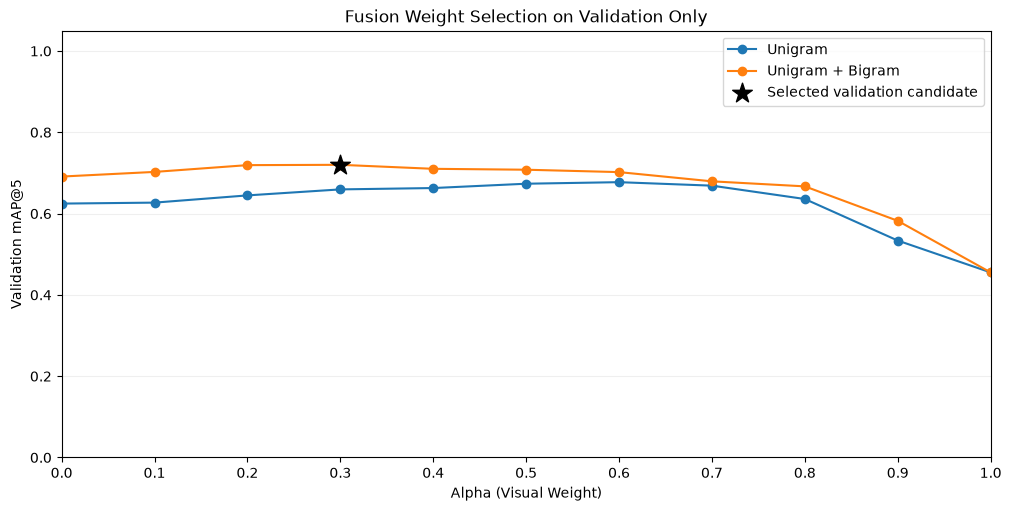

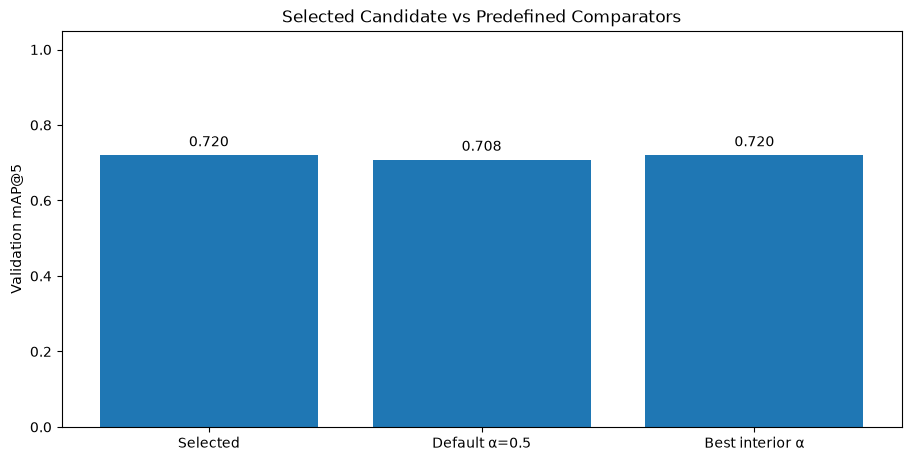


3. SAVING SELECTION REPORTS
--------------------------------------------------------------------------
[SAVED] 671_validation_fusion_candidate_scores.csv
[SAVED] 672_selected_fusion_metrics_by_k.csv
[SAVED] 673_selected_fusion_per_query_metrics.csv
[SAVED] 674_selected_fusion_top10_validation.csv
[SAVED] 675_selected_vs_default_fusion.csv
[SAVED] 676_fusion_selection_validation_checks.csv
[SAVED] 678_validation_fusion_selection_lock.json

CELL 9 - VALIDATION-ONLY FUSION SELECTION COMPLETED
Selected text config : Unigram + Bigram
Selected alpha       : 0.3
Selected method      : Weighted Late Fusion
Validation mAP@5     : 0.72000
Validation nDCG@5    : 0.78543
Technical checks     : 14/14
CSV / figures / lock : 6 / 2 / 1
Review status        : LOCKED_PROVISIONAL_REVIEW_REQUIRED

[PASS] Configuration selected using validation only.
[PASS] Primary metric mAP@5 applied.
[PASS] Deterministic tie-breaking verified.
[PASS] Configuration and evidence fingerprint saved.
[INFO] Test metrics wer

,comparison,text_configuration,alpha,map_at_5,ndcg_at_5,mrr_at_5,is_genuine_fusion
0,Selected across full 22-candidate grid,Unigram + Bigram,0.3,0.72000,0.78543,0.85317,True
1,Default alpha=0.5 with selected text configura...,Unigram + Bigram,0.5,0.70794,0.78527,0.93254,True
2,Best genuine fusion (descriptive; not selected),Unigram + Bigram,0.3,0.72000,0.78543,0.85317,True


In [14]:
# ============================================================
# CELL 9 - VALIDATION-ONLY FUSION WEIGHT SELECTION
# Notebook: 06_multimodal_retrieval_evaluation.ipynb
# ============================================================

import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display


print("NOTEBOOK 06 - VALIDATION-ONLY FUSION WEIGHT SELECTION")
print("=" * 74)

EVAL06_FUSION_SELECTION_COMPLETED = False
EVAL06_FUSION_SELECTION_LOCKED = False
EVAL06_ALPHA_SELECTED = False


# ============================================================
# 1. CHECK DEPENDENCIES AND DEFINE SELECTION RULES
# ============================================================

if not globals().get(
    "EVAL06_ALPHA_SENSITIVITY_COMPLETED",
    False
):
    raise RuntimeError(
        "Jalankan Cell 8 sampai selesai terlebih dahulu."
    )

if not globals().get(
    "EVAL06_VALIDATION_METRICS_COMPLETED",
    False
):
    raise RuntimeError(
        "Cell 7 belum selesai."
    )

if not bool(
    EVAL06_ALPHA_CELL7_ANCHOR_CHECKS_DF[
        "passed"
    ].all()
):
    raise RuntimeError(
        "Pemeriksaan Cell 8 terhadap Cell 7 belum lulus."
    )

if str(
    EVAL06_PRIMARY_SELECTION_METRIC
).strip().lower() != "map@5":
    raise ValueError(
        "Cell 9 mengharapkan metrik utama mAP@5."
    )


# Selection priority:
#
# 1. Highest validation mAP@5
# 2. Highest validation nDCG@5
# 3. Highest validation MRR@5
# 4. Alpha closest to 0.5
# 5. Prefer simpler Unigram configuration
# 6. Prefer smaller alpha
#
# Tolerance is only for numerical ties.
#
# Alpha=0 and alpha=1 remain valid candidates,
# but represent single-modality retrieval.

SEL09_TOL = 1e-10

SEL09_K = 5

SEL09_CONFIGS = (
    "Unigram",
    "Unigram + Bigram"
)

SEL09_ALPHA_GRID = np.round(
    np.linspace(0, 1, 11),
    1
)

SEL09_CONFIG_PRIORITY = {
    "Unigram": 0,
    "Unigram + Bigram": 1
}

EVAL06_METRICS_DIR = Path(
    EVAL06_METRICS_DIR
)

EVAL06_FIGURES_DIR = Path(
    EVAL06_FIGURES_DIR
)

EVAL06_METRICS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

EVAL06_FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)


sel09_checks = []


def sel09_check(category, name, passed):

    sel09_checks.append({
        "category": category,
        "validation_check": name,
        "passed": bool(passed)
    })


# ============================================================
# 2. VALIDATE EXACT CANDIDATE GRID
# ============================================================

required_columns = {
    "text_configuration",
    "alpha_index",
    "alpha",
    "k",
    "validation_queries",
    "gallery_size",
    "map_at_k",
    "mean_ndcg_at_k",
    "mean_mrr_at_k",
    "mean_precision_at_k",
    "mean_recall_at_k",
    "test_evaluated"
}

source = (
    EVAL06_ALPHA_MACRO_METRICS_DF
    .copy()
)

missing = sorted(
    required_columns
    -
    set(source.columns)
)

if missing:

    raise ValueError(
        f"Kolom Cell 8 tidak lengkap: {missing}"
    )


if source[
    "test_evaluated"
].fillna(True).astype(bool).any():

    raise RuntimeError(
        "Terdeteksi data yang menggunakan test."
    )


candidates = (
    source.loc[
        source["k"].eq(SEL09_K)
    ].copy()
)

candidates["alpha_index"] = (
    candidates[
        "alpha_index"
    ].astype(int)
)

candidates["alpha"] = (
    candidates[
        "alpha"
    ].astype(float)
)


if (
    len(candidates) != 22
    or candidates.duplicated(
        [
            "text_configuration",
            "alpha_index"
        ]
    ).any()
):

    raise ValueError(
        "Diharapkan 22 kandidat unik "
        "(2 konfigurasi teks x 11 alpha)."
    )


if set(
    candidates["text_configuration"]
) != set(SEL09_CONFIGS):

    raise ValueError(
        "Konfigurasi teks tidak sesuai Cell 8."
    )


for cfg in SEL09_CONFIGS:

    part = (
        candidates.loc[
            candidates[
                "text_configuration"
            ].eq(cfg)
        ]
        .sort_values("alpha_index")
    )

    if not np.array_equal(
        part["alpha_index"].to_numpy(),
        np.arange(11)
    ):

        raise ValueError(
            f"Indeks alpha tidak lengkap: {cfg}"
        )

    if not np.allclose(
        part["alpha"].to_numpy(),
        SEL09_ALPHA_GRID,
        atol=SEL09_TOL,
        rtol=0
    ):

        raise ValueError(
            f"Grid alpha tidak sesuai: {cfg}"
        )


score_cols = [
    "map_at_k",
    "mean_ndcg_at_k",
    "mean_mrr_at_k",
    "mean_precision_at_k",
    "mean_recall_at_k"
]

values = (
    candidates[
        score_cols
    ].to_numpy(dtype=float)
)

if (
    not np.isfinite(values).all()
    or np.any(values < -SEL09_TOL)
    or np.any(values > 1 + SEL09_TOL)
):

    raise ValueError(
        "Metrik validation harus finite "
        "dan berada pada rentang [0,1]."
    )


if (
    candidates[
        "validation_queries"
    ].nunique() != 1
    or int(
        candidates[
            "validation_queries"
        ].iloc[0]
    ) <= 0
):

    raise ValueError(
        "Jumlah validation queries tidak konsisten."
    )


if (
    candidates[
        "gallery_size"
    ].nunique() != 1
    or int(
        candidates[
            "gallery_size"
        ].iloc[0]
    ) <= 0
):

    raise ValueError(
        "Ukuran gallery tidak konsisten."
    )


# ============================================================
# 3. VERIFY CANDIDATE METRICS AGAINST PER-QUERY DATA
# ============================================================

# Only validation metrics are accessed here.
# No test metric or test similarity is consulted.

per_query = (
    EVAL06_ALPHA_PER_QUERY_METRICS_DF
)

if (
    not per_query[
        "query_partition"
    ].eq("validation").all()
    or per_query[
        "test_evaluated"
    ].fillna(True).astype(bool).any()
):

    raise RuntimeError(
        "Data Cell 8 tidak murni validation."
    )


k5_query = (
    per_query.loc[
        per_query["k"].eq(5)
    ].copy()
)


per_query_means = (
    k5_query
    .groupby(
        [
            "text_configuration",
            "alpha_index"
        ],
        as_index=False
    )
    .agg(
        map_verify=(
            "ap_at_k",
            "mean"
        ),
        ndcg_verify=(
            "ndcg_at_k",
            "mean"
        ),
        mrr_verify=(
            "mrr_at_k",
            "mean"
        ),
        n_query=(
            "query_sample_id",
            "nunique"
        )
    )
)


check_join = candidates.merge(
    per_query_means,

    on=[
        "text_configuration",
        "alpha_index"
    ],

    how="left",

    validate="one_to_one"
)


if check_join[
    [
        "map_verify",
        "ndcg_verify",
        "mrr_verify"
    ]
].isna().any().any():

    raise RuntimeError(
        "Ada kandidat tanpa metrik per-query."
    )


for reference_col, calculated_col in [
    ("map_at_k", "map_verify"),
    ("mean_ndcg_at_k", "ndcg_verify"),
    ("mean_mrr_at_k", "mrr_verify")
]:

    if not np.allclose(
        check_join[
            reference_col
        ],

        check_join[
            calculated_col
        ],

        atol=SEL09_TOL,
        rtol=0
    ):

        raise RuntimeError(
            f"Perbedaan metrik pada {reference_col}."
        )


if not check_join[
    "n_query"
].eq(
    check_join[
        "validation_queries"
    ]
).all():

    raise RuntimeError(
        "Jumlah query validation tidak konsisten."
    )


sel09_check(
    "Input",
    "Exactly 22 complete candidates",
    len(candidates) == 22
)

sel09_check(
    "Input",
    "All metrics finite and bounded",
    True
)

sel09_check(
    "Input",
    "Macro metrics match per-query averages",
    True
)

sel09_check(
    "Partition",
    "Validation only; no test metrics",
    True
)


# ============================================================
# 4. DEFINE DETERMINISTIC SELECTION FUNCTION
# ============================================================

def sel09_select(df):
    """
    Select one configuration using validation only.

    Tie-breaking:
    1. Highest mAP@5
    2. Highest nDCG@5
    3. Highest MRR@5
    4. Alpha closest to 0.5
    5. Simpler Unigram
    6. Smaller alpha
    """

    pool = df.copy()

    for column in [
        "map_at_k",
        "mean_ndcg_at_k",
        "mean_mrr_at_k"
    ]:

        maximum = float(
            pool[column].max()
        )

        pool = pool.loc[
            np.isclose(
                pool[column].to_numpy(
                    dtype=float
                ),
                maximum,
                atol=SEL09_TOL,
                rtol=0
            )
        ].copy()

    pool[
        "alpha_distance_to_half"
    ] = np.abs(
        pool["alpha"] - 0.5
    )

    pool[
        "config_priority"
    ] = (
        pool[
            "text_configuration"
        ]
        .map(
            SEL09_CONFIG_PRIORITY
        )
    )

    pool = pool.sort_values(
        [
            "alpha_distance_to_half",
            "config_priority",
            "alpha",
            "alpha_index"
        ],
        ascending=[
            True,
            True,
            True,
            True
        ],
        kind="stable"
    )

    return pool.iloc[0].copy()


# ============================================================
# 5. SELECT OPTIMAL CONFIGURATION
# ============================================================

chosen = sel09_select(
    candidates
)

EVAL06_SELECTED_TEXT_CONFIG = str(
    chosen["text_configuration"]
)

EVAL06_SELECTED_ALPHA = float(
    chosen["alpha"]
)

EVAL06_SELECTED_ALPHA_INDEX = int(
    chosen["alpha_index"]
)


EVAL06_SELECTED_FUSION_METHOD = (
    "Weighted Late Fusion"

    if 0 < EVAL06_SELECTED_ALPHA < 1

    else (
        "Text Only (alpha=0)"

        if np.isclose(
            EVAL06_SELECTED_ALPHA,
            0
        )

        else "Visual Only (alpha=1)"
    )
)


EVAL06_SELECTED_IS_GENUINE_FUSION = bool(
    0 < EVAL06_SELECTED_ALPHA < 1
)


# ============================================================
# 6. IDENTIFY BEST INTERIOR FUSION FOR COMPARISON
# ============================================================

# The main winner comes from all 22 candidates.
#
# An interior-only winner is retained for
# methodological comparison, not substituted
# automatically for the selected winner.

interior = (
    candidates.loc[
        candidates[
            "alpha"
        ].between(
            0.1,
            0.9
        )
    ].copy()
)

best_interior = sel09_select(
    interior
)


baseline = (
    candidates.loc[
        candidates[
            "text_configuration"
        ].eq(
            EVAL06_SELECTED_TEXT_CONFIG
        )

        &

        np.isclose(
            candidates[
                "alpha"
            ].to_numpy(),
            0.5,
            atol=SEL09_TOL,
            rtol=0
        )
    ]
)

assert len(baseline) == 1

baseline = baseline.iloc[0]


# ============================================================
# 7. VERIFY WINNER AND REPRODUCIBILITY
# ============================================================

winner_count = int(
    (
        candidates[
            "text_configuration"
        ].eq(
            EVAL06_SELECTED_TEXT_CONFIG
        )

        &

        np.isclose(
            candidates[
                "alpha"
            ].to_numpy(),
            EVAL06_SELECTED_ALPHA,
            atol=SEL09_TOL,
            rtol=0
        )
    ).sum()
)


sel09_check(
    "Selection",
    "Winner belongs to candidate grid",
    winner_count == 1
)


sel09_check(
    "Selection",
    "Winning mAP@5 reaches grid maximum",

    float(
        chosen["map_at_k"]
    )
    >=
    float(
        candidates[
            "map_at_k"
        ].max()
    )
    -
    SEL09_TOL
)


# Re-run selection with shuffled candidate rows
# to ensure deterministic results.

deterministic = True

for seed in [1, 7, 42]:

    shuffled = candidates.sample(
        frac=1,
        random_state=seed
    )

    repeated = sel09_select(
        shuffled
    )

    if (
        str(
            repeated[
                "text_configuration"
            ]
        )
        !=
        EVAL06_SELECTED_TEXT_CONFIG

        or

        not np.isclose(
            float(
                repeated["alpha"]
            ),
            EVAL06_SELECTED_ALPHA,
            atol=SEL09_TOL,
            rtol=0
        )
    ):

        deterministic = False
        break


sel09_check(
    "Selection",
    "Deterministic under candidate-row shuffling",
    deterministic
)


# ============================================================
# 8. CREATE CANDIDATE COMPARISON TABLE
# ============================================================

EVAL06_ALPHA_SELECTION_CANDIDATES_DF = (
    candidates.assign(

        selected=(
            candidates[
                "text_configuration"
            ].eq(
                EVAL06_SELECTED_TEXT_CONFIG
            )

            &

            np.isclose(
                candidates[
                    "alpha"
                ].to_numpy(),
                EVAL06_SELECTED_ALPHA,
                atol=SEL09_TOL,
                rtol=0
            )
        ),

        alpha_distance_to_half=np.abs(
            candidates[
                "alpha"
            ] - 0.5
        ),

        text_config_complexity_priority=(
            candidates[
                "text_configuration"
            ].map(
                SEL09_CONFIG_PRIORITY
            )
        )
    )

    .sort_values(
        [
            "text_configuration",
            "alpha_index"
        ],
        kind="stable"
    )

    .reset_index(drop=True)
)


# ============================================================
# 9. EXTRACT SELECTED CONFIGURATION METRICS
# ============================================================

EVAL06_SELECTED_VALIDATION_METRICS_DF = (

    EVAL06_ALPHA_MACRO_METRICS_DF.loc[
        EVAL06_ALPHA_MACRO_METRICS_DF[
            "text_configuration"
        ].eq(
            EVAL06_SELECTED_TEXT_CONFIG
        )

        &

        EVAL06_ALPHA_MACRO_METRICS_DF[
            "alpha_index"
        ].eq(
            EVAL06_SELECTED_ALPHA_INDEX
        )
    ]

    .sort_values("k")

    .reset_index(drop=True)

    .copy()
)


EVAL06_SELECTED_VALIDATION_PER_QUERY_DF = (

    per_query.loc[
        per_query[
            "text_configuration"
        ].eq(
            EVAL06_SELECTED_TEXT_CONFIG
        )

        &

        per_query[
            "alpha_index"
        ].eq(
            EVAL06_SELECTED_ALPHA_INDEX
        )
    ]

    .sort_values(
        [
            "query_sample_id",
            "k"
        ],
        kind="stable"
    )

    .reset_index(drop=True)

    .copy()
)


EVAL06_SELECTED_VALIDATION_TOP10_DF = (

    EVAL06_ALPHA_TOP10_RANKINGS_DF.loc[
        EVAL06_ALPHA_TOP10_RANKINGS_DF[
            "text_configuration"
        ].eq(
            EVAL06_SELECTED_TEXT_CONFIG
        )

        &

        EVAL06_ALPHA_TOP10_RANKINGS_DF[
            "alpha_index"
        ].eq(
            EVAL06_SELECTED_ALPHA_INDEX
        )
    ]

    .sort_values(
        [
            "query_sample_id",
            "rank"
        ],
        kind="stable"
    )

    .reset_index(drop=True)

    .copy()
)


# ============================================================
# 10. CREATE SELECTED VS BASELINE COMPARISON
# ============================================================

EVAL06_SELECTION_COMPARISON_DF = pd.DataFrame([
    {
        "comparison":
            "Selected across full 22-candidate grid",

        "text_configuration":
            EVAL06_SELECTED_TEXT_CONFIG,

        "alpha":
            EVAL06_SELECTED_ALPHA,

        "map_at_5":
            float(
                chosen["map_at_k"]
            ),

        "ndcg_at_5":
            float(
                chosen["mean_ndcg_at_k"]
            ),

        "mrr_at_5":
            float(
                chosen["mean_mrr_at_k"]
            ),

        "is_genuine_fusion":
            EVAL06_SELECTED_IS_GENUINE_FUSION
    },

    {
        "comparison":
            "Default alpha=0.5 with selected text configuration",

        "text_configuration":
            EVAL06_SELECTED_TEXT_CONFIG,

        "alpha":
            0.5,

        "map_at_5":
            float(
                baseline["map_at_k"]
            ),

        "ndcg_at_5":
            float(
                baseline["mean_ndcg_at_k"]
            ),

        "mrr_at_5":
            float(
                baseline["mean_mrr_at_k"]
            ),

        "is_genuine_fusion":
            True
    },

    {
        "comparison":
            "Best genuine fusion (descriptive; not selected)",

        "text_configuration":
            str(
                best_interior[
                    "text_configuration"
                ]
            ),

        "alpha":
            float(
                best_interior["alpha"]
            ),

        "map_at_5":
            float(
                best_interior["map_at_k"]
            ),

        "ndcg_at_5":
            float(
                best_interior["mean_ndcg_at_k"]
            ),

        "mrr_at_5":
            float(
                best_interior["mean_mrr_at_k"]
            ),

        "is_genuine_fusion":
            True
    }
])


# ============================================================
# 11. VALIDATE SELECTED OUTPUTS
# ============================================================

sel09_check(
    "Output",
    "Exactly one selected candidate",

    int(
        EVAL06_ALPHA_SELECTION_CANDIDATES_DF[
            "selected"
        ].sum()
    ) == 1
)


sel09_check(
    "Output",
    "Four K rows for selected configuration",

    EVAL06_SELECTED_VALIDATION_METRICS_DF[
        "k"
    ].tolist() == [1, 3, 5, 10]
)


sel09_check(
    "Output",
    "Selected per-query rows complete",

    len(
        EVAL06_SELECTED_VALIDATION_PER_QUERY_DF
    )
    ==
    4
    *
    int(
        chosen["validation_queries"]
    )
)


sel09_check(
    "Output",
    "Selected Top-10 rows complete",

    len(
        EVAL06_SELECTED_VALIDATION_TOP10_DF
    )
    ==
    10
    *
    int(
        chosen["validation_queries"]
    )
)


sel09_check(
    "Methodology",
    "Selected data use validation only",

    EVAL06_SELECTED_VALIDATION_PER_QUERY_DF[
        "query_partition"
    ].eq("validation").all()

    and

    EVAL06_SELECTED_VALIDATION_TOP10_DF[
        "query_partition"
    ].eq("validation").all()
)


# ============================================================
# 12. CREATE SELECTION EVIDENCE FINGERPRINT
# ============================================================

# SHA-256 identifies the exact candidate metrics
# and gallery/validation sample IDs used
# for this selection.

evidence = (

    candidates[
        [
            "text_configuration",
            "alpha_index",
            "alpha",
            "map_at_k",
            "mean_ndcg_at_k",
            "mean_mrr_at_k"
        ]
    ]

    .sort_values(
        [
            "text_configuration",
            "alpha_index"
        ],
        kind="stable"
    )

    .to_csv(
        index=False,
        float_format="%.12g"
    )
)


ids_payload = json.dumps(
    {
        "gallery_ids": list(
            map(
                str,
                EVAL06_SIMILARITY_GALLERY_IDS
            )
        ),

        "validation_ids": list(
            map(
                str,
                EVAL06_SIMILARITY_QUERY_IDS[
                    "validation"
                ]
            )
        )
    },

    ensure_ascii=False,

    separators=(",", ":")
)


EVAL06_SELECTION_EVIDENCE_SHA256 = (
    hashlib.sha256(
        (
            evidence
            +
            "\n"
            +
            ids_payload
        ).encode("utf-8")
    ).hexdigest()
)


# ============================================================
# 13. RECORD METHODOLOGICAL REVIEW STATUS
# ============================================================

# The current project still has unresolved
# methodological review items from prior cells.
#
# A locked configuration is not automatically
# approved for independent test evaluation.

EVAL06_SELECTION_REVIEW_REASONS = list(
    dict.fromkeys(

        globals().get(
            "EVAL06_FEATURE_REVIEW_REASONS",
            []
        )

        +

        globals().get(
            "EVAL06_SIMILARITY_REVIEW_REASONS",
            []
        )
    )
)


if not globals().get(
    "EVAL06_SPLIT_APPROVED_FOR_EVALUATION",
    False
):

    EVAL06_SELECTION_REVIEW_REASONS.append(
        "Cell 3 split was not approved "
        "for independent evaluation."
    )


if not globals().get(
    "EVAL06_FEATURES_APPROVED_FOR_INDEPENDENT_EVALUATION",
    False
):

    EVAL06_SELECTION_REVIEW_REASONS.append(
        "Feature pipeline remains pending "
        "methodological approval."
    )


EVAL06_SELECTION_REVIEW_REASONS = list(
    dict.fromkeys(
        EVAL06_SELECTION_REVIEW_REASONS
    )
)


EVAL06_SELECTION_STATUS = (

    "LOCKED_PROVISIONAL_REVIEW_REQUIRED"

    if EVAL06_SELECTION_REVIEW_REASONS

    else "LOCKED_VALIDATION_ONLY_PENDING_TEST"
)


# ============================================================
# 14. PREPARE CONFIGURATION LOCK
# ============================================================

selection_lock = {

    "notebook":
        "06_multimodal_retrieval_evaluation.ipynb",

    "cell":
        9,

    "selection_partition":
        "validation",

    "primary_metric":
        "mAP@5",

    "selected_text_configuration":
        EVAL06_SELECTED_TEXT_CONFIG,

    "selected_alpha":
        EVAL06_SELECTED_ALPHA,

    "selected_alpha_index":
        EVAL06_SELECTED_ALPHA_INDEX,

    "selected_method_type":
        EVAL06_SELECTED_FUSION_METHOD,

    "is_genuine_fusion":
        EVAL06_SELECTED_IS_GENUINE_FUSION,

    "selected_validation_map_at_5":
        float(
            chosen["map_at_k"]
        ),

    "selected_validation_ndcg_at_5":
        float(
            chosen["mean_ndcg_at_k"]
        ),

    "selected_validation_mrr_at_5":
        float(
            chosen["mean_mrr_at_k"]
        ),

    "validation_query_count":
        int(
            chosen["validation_queries"]
        ),

    "gallery_count":
        int(
            chosen["gallery_size"]
        ),

    "selection_tolerance":
        SEL09_TOL,

    "candidate_count":
        len(candidates),

    "tie_break_priority": [
        "max validation mAP@5",
        "max validation nDCG@5 within tolerance",
        "max validation MRR@5 within tolerance",
        "alpha closest to 0.5",
        "prefer Unigram if all above tied",
        "smaller alpha"
    ],

    "evidence_sha256":
        EVAL06_SELECTION_EVIDENCE_SHA256,

    "selected_using_test":
        False,

    "test_metrics_computed_in_cell9":
        False,

    "independent_evaluation_approved":
        False,

    "review_status":
        EVAL06_SELECTION_STATUS,

    "review_reasons":
        EVAL06_SELECTION_REVIEW_REASONS,

    "next_cell":
        "Cell 10 - Selection Freeze and Pre-Test Integrity Gate"
}


# ============================================================
# 15. CHECK EXISTING LOCK
# ============================================================

EVAL06_SELECTION_LOCK_PATH = (
    EVAL06_METRICS_DIR
    /
    "678_validation_fusion_selection_lock.json"
)


if EVAL06_SELECTION_LOCK_PATH.exists():

    old = json.loads(
        EVAL06_SELECTION_LOCK_PATH.read_text(
            encoding="utf-8"
        )
    )

    important_keys = [
        "selected_text_configuration",
        "selected_alpha",
        "evidence_sha256",
        "selection_partition",
        "primary_metric"
    ]

    differences = [
        key

        for key in important_keys

        if old.get(key)
        != selection_lock.get(key)
    ]

    if differences:

        raise RuntimeError(
            "Konfigurasi selection lock lama berbeda: "

            +

            ", ".join(differences)

            +

            ". Periksa ulang sumber data/split. "
            "Jangan mengubah konfigurasi setelah "
            "melihat hasil test."
        )


sel09_check(
    "Lock",
    "No conflicting selection lock exists",
    True
)


sel09_check(
    "Lock",
    "Evidence hash is a SHA-256 string",

    len(
        EVAL06_SELECTION_EVIDENCE_SHA256
    ) == 64
)


# ============================================================
# 16. FINAL SELECTION VALIDATION
# ============================================================

EVAL06_FUSION_SELECTION_VALIDATION_DF = (
    pd.DataFrame(
        sel09_checks
    )
)


failed = (
    EVAL06_FUSION_SELECTION_VALIDATION_DF.loc[
        ~EVAL06_FUSION_SELECTION_VALIDATION_DF[
            "passed"
        ]
    ]
)


if not failed.empty:

    display(
        failed
    )

    raise AssertionError(
        "Cell 9 validation failed. "
        "Selection lock was not saved."
    )


print("\n1. SELECTED CONFIGURATION")
print("-" * 74)

print(
    "Text configuration:",
    EVAL06_SELECTED_TEXT_CONFIG
)

print(
    "Selected alpha:",
    EVAL06_SELECTED_ALPHA
)

print(
    "Method:",
    EVAL06_SELECTED_FUSION_METHOD
)

print(
    "Validation mAP@5:",
    round(
        float(
            chosen["map_at_k"]
        ),
        5
    )
)

print("\n2. COMPARISON")
print("-" * 74)

display(
    EVAL06_SELECTION_COMPARISON_DF.round(5)
)


# ============================================================
# 17. FIGURE 215 - SELECTED ALPHA ON MAP@5 CURVE
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 5),
    constrained_layout=True
)


for cfg in SEL09_CONFIGS:

    subset = (
        candidates.loc[
            candidates[
                "text_configuration"
            ].eq(cfg)
        ]
        .sort_values("alpha")
    )

    ax.plot(
        subset["alpha"],
        subset["map_at_k"],
        marker="o",
        label=cfg
    )


ax.scatter(
    [
        EVAL06_SELECTED_ALPHA
    ],

    [
        float(
            chosen["map_at_k"]
        )
    ],

    marker="*",

    s=220,

    color="black",

    label="Selected validation candidate",

    zorder=5
)


ax.set(
    xlabel="Alpha (Visual Weight)",
    ylabel="Validation mAP@5",
    title="Fusion Weight Selection on Validation Only"
)

ax.set_xticks(
    SEL09_ALPHA_GRID
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)

ax.legend()
ax.grid(axis="y", alpha=0.2)


SEL09_FIG_215 = (
    EVAL06_FIGURES_DIR
    /
    "215_validation_fusion_selection_map5.png"
)


fig.savefig(
    SEL09_FIG_215,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 18. FIGURE 216 - SELECTED VS COMPARATORS
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 4.5),
    constrained_layout=True
)


labels = [
    "Selected",
    "Default α=0.5",
    "Best interior α"
]


comparison_values = (
    EVAL06_SELECTION_COMPARISON_DF[
        "map_at_5"
    ].to_numpy()
)


bars = ax.bar(
    np.arange(3),
    comparison_values
)


ax.set_xticks(
    np.arange(3),
    labels=labels
)

ax.set_ylim(0, 1.05)

ax.set_ylabel(
    "Validation mAP@5"
)

ax.set_title(
    "Selected Candidate vs Predefined Comparators"
)


for bar, value in zip(
    bars,
    comparison_values
):

    ax.text(
        bar.get_x()
        +
        bar.get_width() / 2,

        min(
            value + 0.015,
            1.03
        ),

        f"{value:.3f}",

        ha="center",

        va="bottom"
    )


SEL09_FIG_216 = (
    EVAL06_FIGURES_DIR
    /
    "216_validation_selected_vs_comparators.png"
)


fig.savefig(
    SEL09_FIG_216,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 19. SAVE REPORTS
# ============================================================

SEL09_REPORTS = {

    "671_validation_fusion_candidate_scores.csv":
        EVAL06_ALPHA_SELECTION_CANDIDATES_DF,

    "672_selected_fusion_metrics_by_k.csv":
        EVAL06_SELECTED_VALIDATION_METRICS_DF,

    "673_selected_fusion_per_query_metrics.csv":
        EVAL06_SELECTED_VALIDATION_PER_QUERY_DF,

    "674_selected_fusion_top10_validation.csv":
        EVAL06_SELECTED_VALIDATION_TOP10_DF,

    "675_selected_vs_default_fusion.csv":
        EVAL06_SELECTION_COMPARISON_DF,

    "676_fusion_selection_validation_checks.csv":
        EVAL06_FUSION_SELECTION_VALIDATION_DF
}


print("\n3. SAVING SELECTION REPORTS")
print("-" * 74)


for filename, dataframe in (
    SEL09_REPORTS.items()
):

    path = (
        EVAL06_METRICS_DIR
        /
        filename
    )

    dataframe.to_csv(
        path,
        index=False,
        encoding="utf-8-sig"
    )

    print(
        "[SAVED]",
        filename
    )


# ============================================================
# 20. SAVE FINAL SELECTION LOCK
# ============================================================

EVAL06_SELECTION_LOCK_PATH.write_text(
    json.dumps(
        selection_lock,

        ensure_ascii=False,

        indent=2,

        allow_nan=False
    ),

    encoding="utf-8"
)


print(
    "[SAVED]",
    EVAL06_SELECTION_LOCK_PATH.name
)


# ============================================================
# 21. FINAL ARTIFACT VALIDATION
# ============================================================

assert all(
    (
        EVAL06_METRICS_DIR
        /
        filename
    ).is_file()

    for filename in SEL09_REPORTS
)


assert EVAL06_SELECTION_LOCK_PATH.is_file()


assert all(
    path.is_file()
    and path.stat().st_size > 0

    for path in [
        SEL09_FIG_215,
        SEL09_FIG_216
    ]
)


# ============================================================
# 22. SET COMPLETION STATUS
# ============================================================

EVAL06_ALPHA_SELECTED = True

EVAL06_FUSION_SELECTION_LOCKED = True

EVAL06_FUSION_SELECTION_COMPLETED = True

EVAL06_SELECTION_LOCK = (
    selection_lock
)


# ============================================================
# 23. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 74)

print(
    "CELL 9 - VALIDATION-ONLY FUSION SELECTION COMPLETED"
)

print("=" * 74)


print(
    "Selected text config :",
    EVAL06_SELECTED_TEXT_CONFIG
)

print(
    "Selected alpha       :",
    EVAL06_SELECTED_ALPHA
)

print(
    "Selected method      :",
    EVAL06_SELECTED_FUSION_METHOD
)

print(
    "Validation mAP@5     :",
    f"{float(chosen['map_at_k']):.5f}"
)

print(
    "Validation nDCG@5    :",
    f"{float(chosen['mean_ndcg_at_k']):.5f}"
)

print(
    "Technical checks     :",
    f"{int(EVAL06_FUSION_SELECTION_VALIDATION_DF['passed'].sum())}"
    f"/{len(EVAL06_FUSION_SELECTION_VALIDATION_DF)}"
)

print(
    "CSV / figures / lock :",
    len(SEL09_REPORTS),
    "/",
    2,
    "/",
    1
)

print(
    "Review status        :",
    EVAL06_SELECTION_STATUS
)


print(
    "\n[PASS] Configuration selected using validation only."
)

print(
    "[PASS] Primary metric mAP@5 applied."
)

print(
    "[PASS] Deterministic tie-breaking verified."
)

print(
    "[PASS] Configuration and evidence fingerprint saved."
)

print(
    "[INFO] Test metrics were not accessed."
)

print(
    "[INFO] Locked configuration does not certify "
    "independent-evaluation validity."
)


print(
    "\nNext: Cell 10 - Selection Freeze "
    "and Pre-Test Integrity Gate"
)

display(
    EVAL06_SELECTION_COMPARISON_DF.round(5)
)

NOTEBOOK 06 - PRE-TEST INTEGRITY GATE

1. PRE-TEST GATE CHECKS
------------------------------------------------------------------------


,category,check,passed,severity_if_failed,detail
0,Selection Lock,File and in-memory selection agree,True,BLOCK,
1,Selection Lock,Exactly one selected candidate exists,True,BLOCK,matches=1
2,Selection Lock,Validation evidence SHA-256 matches lock,True,BLOCK,lock_hash=01907ece9c875df733abc784e7f0ed1cc775...
3,Selection Lock,Selected mAP@5 matches saved validation result,True,BLOCK,
4,Selection Lock,"Cell 8/9 used validation, not test",True,BLOCK,
5,Dataset,All 104 sample IDs are unique and aligned,True,BLOCK,
6,Dataset,All samples assigned to three partitions,True,BLOCK,
7,Dataset,Groups do not cross gallery/validation/test,True,BLOCK,
8,Dataset,gallery: sample order matches Cell 3,True,BLOCK,count=62
9,Dataset,gallery: all five classes represented,True,BLOCK,



2. UNRESOLVED ISSUES
------------------------------------------------------------------------


,category,severity,issue,detail
0,Raw Images,REVIEW,No unresolved near-duplicates across splits,candidate_pairs=44
1,Raw Text,REVIEW,No identical descriptions cross partitions,cross_split_description_groups=4
2,Provenance,REVIEW,Independent specimen/capture group IDs verified,group_column=None
3,Provenance,REVIEW,Visual extractor equivalence with Notebook 03 ...,Original Notebook 03 vectors require independe...
4,Approval,REVIEW,Prior split and feature reviews formally approved,Cells 3 and 4 do not automatically approve ind...


[SAVED] 679_pretest_gate_checks.csv
[SAVED] 680_pretest_gate_unresolved_issues.csv
[SAVED] 681_pretest_recovered_text_audit.csv
[SAVED] 682_pretest_text_class_uniqueness.csv
[SAVED] 683_pretest_exact_image_conflicts.csv
[SAVED] 684_pretest_cross_split_near_duplicates.csv
[SAVED] 685_pretest_split_class_counts.csv


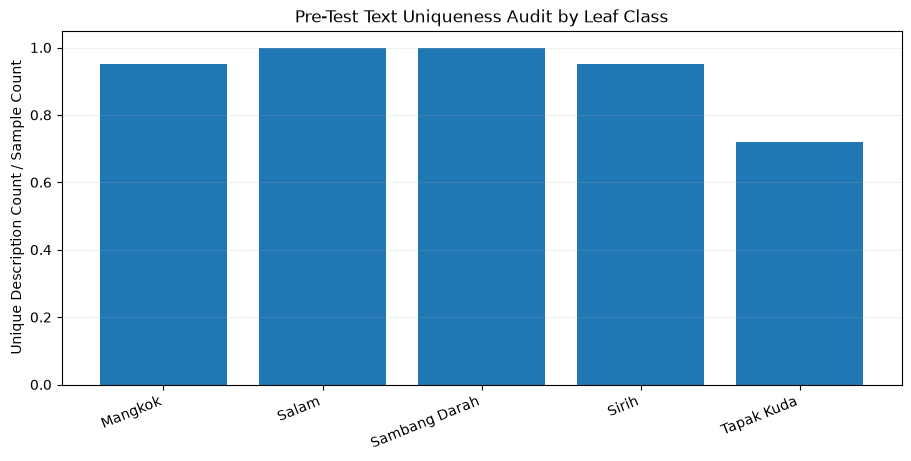

[SAVED] 217_pretest_class_text_uniqueness.png
[SAVED] 686_pretest_integrity_handoff.json

CELL 10 - PRE-TEST INTEGRITY GATE COMPLETED
Selected text config : Unigram + Bigram
Locked alpha         : 0.3
Structural failures  : 0
Review items         : 5
Gate status          : HOLD_METHODOLOGICAL_REVIEW
Approved for test    : False
Saved CSV / PNG / JSON: 7 / 1 / 1
[INFO] No test scores, rankings, or metrics were inspected.
[HOLD] Resolve integrity and methodological review issues before independent test evaluation.

NOTEBOOK 06 - CELL 10 COMPLETED


In [15]:

# ============================================================
# CELL 10 - SELECTION FREEZE & PRE-TEST INTEGRITY GATE
# Notebook: 06_multimodal_retrieval_evaluation.ipynb
# ============================================================

import hashlib
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


print("NOTEBOOK 06 - PRE-TEST INTEGRITY GATE")
print("=" * 72)

EVAL06_PRETEST_GATE_COMPLETED = False
EVAL06_PRETEST_APPROVED_FOR_INDEPENDENT_EVALUATION = False


# ============================================================
# 1. VERIFY PREVIOUS CELL COMPLETION
# ============================================================

requirements = {
    "Cell 3 split": "EVAL06_SPLIT_COMPLETED",
    "Cell 4 features": "EVAL06_FEATURE_PREPARATION_COMPLETED",
    "Cell 5 similarity": "EVAL06_SIMILARITY_CALCULATION_COMPLETED",
    "Cell 7 metrics": "EVAL06_VALIDATION_METRICS_COMPLETED",
    "Cell 8 sensitivity": "EVAL06_ALPHA_SENSITIVITY_COMPLETED",
    "Cell 9 selection": "EVAL06_FUSION_SELECTION_COMPLETED",
    "Cell 9 lock": "EVAL06_FUSION_SELECTION_LOCKED",
}

missing = [
    name
    for name, variable in requirements.items()
    if globals().get(variable, False) is not True
]

if missing:
    raise RuntimeError(
        "Jalankan cell sebelumnya terlebih dahulu: "
        + ", ".join(missing)
    )

metrics_dir = Path(EVAL06_METRICS_DIR)
figures_dir = Path(EVAL06_FIGURES_DIR)

metrics_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# This cell checks identities, source integrity,
# gallery fitting and validation selection.
# It does NOT access test similarity scores.

partitions = ("gallery", "validation", "test")

check_rows = []
issue_rows = []


# ============================================================
# 2. DEFINE AUDIT HELPERS
# ============================================================

def gate_check(
    category,
    name,
    passed,
    severity="BLOCK",
    detail=""
):
    check_rows.append({
        "category": category,
        "check": name,
        "passed": bool(passed),
        "severity_if_failed": severity,
        "detail": str(detail)
    })

    if not passed:
        issue_rows.append({
            "category": category,
            "severity": severity,
            "issue": name,
            "detail": str(detail)
        })


def file_sha256(path):
    digest = hashlib.sha256()

    with Path(path).open("rb") as file:
        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


# ============================================================
# 3. LOAD AND VERIFY SELECTION LOCK
# ============================================================

lock_path = Path(
    EVAL06_SELECTION_LOCK_PATH
)

if not lock_path.is_file():
    raise FileNotFoundError(
        f"Selection lock tidak ditemukan: {lock_path}"
    )

lock = json.loads(
    lock_path.read_text(encoding="utf-8")
)

locked_config = str(
    lock.get("selected_text_configuration", "")
)

locked_alpha = float(
    lock.get("selected_alpha", np.nan)
)

locked_index = int(
    lock.get("selected_alpha_index", -1)
)

validated_selection = (
    locked_config in (
        "Unigram",
        "Unigram + Bigram"
    )

    and np.isfinite(locked_alpha)

    and 0 <= locked_alpha <= 1

    and locked_index in range(11)

    and np.isclose(
        locked_alpha,
        locked_index / 10,
        atol=1e-12
    )

    and locked_config == str(
        EVAL06_SELECTED_TEXT_CONFIG
    )

    and np.isclose(
        locked_alpha,
        float(EVAL06_SELECTED_ALPHA),
        atol=1e-12
    )

    and locked_index == int(
        EVAL06_SELECTED_ALPHA_INDEX
    )

    and lock.get("selection_partition")
    == "validation"

    and lock.get("primary_metric")
    == "mAP@5"

    and lock.get("selected_using_test") is False

    and lock.get(
        "test_metrics_computed_in_cell9"
    ) is False
)

gate_check(
    "Selection Lock",
    "File and in-memory selection agree",
    validated_selection
)


# ============================================================
# 4. RECOMPUTE VALIDATION EVIDENCE FINGERPRINT
# ============================================================

# Recreate exactly the evidence fingerprint
# saved in Cell 9.

candidates = (
    EVAL06_ALPHA_MACRO_METRICS_DF.loc[
        EVAL06_ALPHA_MACRO_METRICS_DF["k"].eq(5)
    ].copy()
)

selected_rows = candidates.loc[
    candidates[
        "text_configuration"
    ].eq(locked_config)

    & candidates[
        "alpha_index"
    ].eq(locked_index)
]

gate_check(
    "Selection Lock",
    "Exactly one selected candidate exists",
    len(selected_rows) == 1,
    detail=f"matches={len(selected_rows)}"
)

if len(candidates) != 22 or len(selected_rows) != 1:
    raise RuntimeError(
        "Cell 8/9 candidate grid tidak konsisten."
    )

candidate_csv = (
    candidates[
        [
            "text_configuration",
            "alpha_index",
            "alpha",
            "map_at_k",
            "mean_ndcg_at_k",
            "mean_mrr_at_k"
        ]
    ]
    .sort_values(
        ["text_configuration", "alpha_index"],
        kind="stable"
    )
    .to_csv(
        index=False,
        float_format="%.12g"
    )
)

identity_json = json.dumps(
    {
        "gallery_ids": list(
            map(
                str,
                EVAL06_SIMILARITY_GALLERY_IDS
            )
        ),
        "validation_ids": list(
            map(
                str,
                EVAL06_SIMILARITY_QUERY_IDS["validation"]
            )
        )
    },
    ensure_ascii=False,
    separators=(",", ":")
)

recomputed_evidence_hash = hashlib.sha256(
    (
        candidate_csv
        + "\n"
        + identity_json
    ).encode("utf-8")
).hexdigest()

gate_check(
    "Selection Lock",
    "Validation evidence SHA-256 matches lock",
    recomputed_evidence_hash
    == lock.get("evidence_sha256"),
    detail=(
        f"lock_hash="
        f"{lock.get('evidence_sha256', 'missing')}"
    )
)

chosen_candidate = selected_rows.iloc[0]

gate_check(
    "Selection Lock",
    "Selected mAP@5 matches saved validation result",
    np.isclose(
        float(chosen_candidate["map_at_k"]),
        float(
            lock.get(
                "selected_validation_map_at_5",
                np.nan
            )
        ),
        atol=1e-10,
        rtol=0
    )
)

gate_check(
    "Selection Lock",
    "Cell 8/9 used validation, not test",
    candidates[
        "test_evaluated"
    ].eq(False).all()
    and lock.get("selected_using_test") is False
)


# ============================================================
# 5. VERIFY SAMPLE AND SPLIT ALIGNMENT
# ============================================================

frame = (
    EVAL06_FEATURE_INPUT_DF.copy()
    .sort_values(
        "matrix_row_index",
        kind="stable"
    )
    .reset_index(drop=True)
)

required_fields = {
    "sample_id",
    "class_label",
    "split",
    "split_group_id",
    "normalized_text",
    "resolved_image_path",
    "image_readable"
}

missing_fields = required_fields - set(frame.columns)

if missing_fields:
    raise ValueError(
        f"Missing Cell 4 columns: "
        f"{sorted(missing_fields)}"
    )

frame["sample_id"] = (
    frame["sample_id"].astype(str)
)

frame["class_label"] = (
    frame["class_label"].astype(str)
)

frame["split"] = (
    frame["split"].astype(str)
)

frame["normalized_text"] = (
    frame["normalized_text"]
    .fillna("")
    .astype(str)
)

n_samples = len(frame)

expected_samples = list(
    map(
        str,
        EVAL06_SAMPLE_IDS
    )
)

gate_check(
    "Dataset",
    "All 104 sample IDs are unique and aligned",
    n_samples == 104
    and frame["sample_id"].is_unique
    and frame["sample_id"].tolist() == expected_samples
)

gate_check(
    "Dataset",
    "All samples assigned to three partitions",
    frame["split"].isin(partitions).all()
)

gate_check(
    "Dataset",
    "Groups do not cross gallery/validation/test",
    frame.groupby("split_group_id")[
        "split"
    ].nunique().eq(1).all()
)

for split in partitions:

    observed_ids = frame.loc[
        frame["split"].eq(split),
        "sample_id"
    ].tolist()

    recorded_ids = list(
        map(
            str,
            EVAL06_SPLIT_SAMPLE_IDS[split]
        )
    )

    gate_check(
        "Dataset",
        f"{split}: sample order matches Cell 3",
        observed_ids == recorded_ids,
        detail=f"count={len(observed_ids)}"
    )

    gate_check(
        "Dataset",
        f"{split}: all five classes represented",
        frame.loc[
            frame["split"].eq(split),
            "class_label"
        ].nunique() == 5
    )


# ============================================================
# 6. VERIFY RAW IMAGE COMPLETENESS
# ============================================================

image_audit = EVAL06_IMAGE_AUDIT_DF.copy()

image_audit["sample_id"] = (
    image_audit["sample_id"].astype(str)
)

image_audit = image_audit.merge(
    frame[
        [
            "sample_id",
            "split",
            "class_label"
        ]
    ],
    on="sample_id",
    how="right",
    validate="one_to_one",
    suffixes=("", "_canonical")
)

image_complete = (
    frame[
        "image_readable"
    ].fillna(False).astype(bool).all()

    and

    frame[
        "resolved_image_path"
    ].fillna("").astype(str).str.len().gt(0).all()
)

gate_check(
    "Raw Images",
    "All 104 image files readable",
    image_complete
)


# ============================================================
# 7. DETECT EXACT IMAGE COLLISIONS
# ============================================================

image_collision_rows = []

for column in (
    "file_sha256",
    "decoded_pixel_sha256"
):

    if column not in image_audit.columns:

        gate_check(
            "Raw Images",
            f"{column} available for duplicate auditing",
            False,
            "REVIEW"
        )

        continue

    valid = image_audit.loc[
        image_audit[column]
        .fillna("")
        .astype(str)
        .ne("")
    ]

    for hash_value, group in valid.groupby(column):

        classes = (
            group["class_label_canonical"]

            if "class_label_canonical" in group.columns

            else group["class_label"]
        )

        if (
            group["split"].nunique() > 1
            or classes.nunique() > 1
        ):

            image_collision_rows.append({
                "hash_type": column,
                "hash_prefix": str(hash_value)[:16],
                "sample_count": len(group),
                "split_count": group["split"].nunique(),
                "class_count": classes.nunique(),
                "sample_ids": " | ".join(
                    group["sample_id"].tolist()
                )
            })

image_collisions = pd.DataFrame(
    image_collision_rows,
    columns=[
        "hash_type",
        "hash_prefix",
        "sample_count",
        "split_count",
        "class_count",
        "sample_ids"
    ]
)

gate_check(
    "Raw Images",
    "No exact-image conflicts across splits or classes",
    image_collisions.empty,
    "BLOCK",
    detail=f"conflict_groups={len(image_collisions)}"
)


# ============================================================
# 8. AUDIT NEAR-DUPLICATE IMAGES ACROSS SPLITS
# ============================================================

near_rows = []

near_df = globals().get(
    "EVAL06_NEAR_DUPLICATE_DF",
    None
)

if (
    isinstance(near_df, pd.DataFrame)
    and not near_df.empty
):

    lookup = (
        frame.set_index("sample_id")[
            "split"
        ].to_dict()
    )

    for row in near_df.itertuples(index=False):

        left = str(row.sample_id_i)
        right = str(row.sample_id_j)

        if (
            left in lookup
            and right in lookup
            and lookup[left] != lookup[right]
        ):

            near_rows.append({
                "sample_id_i": left,
                "sample_id_j": right,
                "split_i": lookup[left],
                "split_j": lookup[right],
                "hamming_distance": getattr(
                    row,
                    "dhash_hamming_distance",
                    np.nan
                )
            })

near_cross_split = pd.DataFrame(
    near_rows,
    columns=[
        "sample_id_i",
        "sample_id_j",
        "split_i",
        "split_j",
        "hamming_distance"
    ]
)

gate_check(
    "Raw Images",
    "No unresolved near-duplicates across splits",
    near_cross_split.empty,
    "REVIEW",
    detail=f"candidate_pairs={len(near_cross_split)}"
)


# ============================================================
# 9. AUDIT RECOVERED TEXT SOURCE
# ============================================================

# Use recovered text from Cell 4,
# not the outdated Cell 2 text inventory.

text_available = (
    frame["normalized_text"]
    .str.strip()
    .ne("")
    .all()
)

gate_check(
    "Raw Text",
    "All 104 original descriptions recovered",
    text_available
)

source_name = str(
    globals().get(
        "source_name",
        "UNKNOWN"
    )
)

gate_check(
    "Raw Text",
    "Text source is not only Notebook 05 gallery index",
    source_name not in (
        "UNKNOWN",
        "NOT_FOUND",
        "Notebook05/gallery_metadata.csv"
    ),
    "REVIEW",
    detail=f"source={source_name}"
)


def norm_audit(value):
    value = str(value).casefold()

    value = re.sub(
        r"[^\w\s]",
        " ",
        value,
        flags=re.UNICODE
    )

    return " ".join(
        value.split()
    )


frame["audit_text"] = (
    frame["normalized_text"]
    .map(norm_audit)
)

frame["audit_text_sha256"] = (
    frame["audit_text"].map(
        lambda text: (
            hashlib.sha256(
                text.encode("utf-8")
            ).hexdigest()
            if text
            else ""
        )
    )
)


# ============================================================
# 10. DETECT DIRECT CLASS-NAME CLUES
# ============================================================

frame["contains_own_class_name"] = [

    bool(norm_audit(label))

    and

    (
        " " + norm_audit(label) + " "
    )
    in
    (
        " " + text + " "
    )

    for label, text in zip(
        frame["class_label"],
        frame["audit_text"]
    )
]

label_hint_count = int(
    frame["contains_own_class_name"].sum()
)

gate_check(
    "Raw Text",
    "No own-class names embedded in descriptions",
    label_hint_count == 0,
    "REVIEW",
    detail=f"flagged_samples={label_hint_count}"
)


# ============================================================
# 11. DETECT REPEATED TEXT ACROSS SPLITS
# ============================================================

valid_text = frame.loc[
    frame["audit_text"].ne("")
]

text_groups = valid_text.groupby(
    "audit_text_sha256"
)

repeated_across_split = (
    text_groups["split"].nunique()
)

repeated_across_split = (
    repeated_across_split.loc[
        repeated_across_split.gt(1)
    ]
)

cross_split_text_count = len(
    repeated_across_split
)

gate_check(
    "Raw Text",
    "No identical descriptions cross partitions",
    cross_split_text_count == 0,
    "REVIEW",
    detail=(
        f"cross_split_description_groups="
        f"{cross_split_text_count}"
    )
)


# ============================================================
# 12. DETECT CLASS-LEVEL TEXT TEMPLATES
# ============================================================

text_unique_per_class = (
    valid_text.groupby("class_label")[
        "audit_text_sha256"
    ].nunique()
)

total_per_class = (
    valid_text.groupby("class_label").size()
)

class_templates = sorted([
    cls
    for cls in total_per_class.index
    if (
        total_per_class[cls] > 1
        and text_unique_per_class[cls] == 1
    )
])

gate_check(
    "Raw Text",
    "No class-level identical-description templates",
    not class_templates,
    "REVIEW",
    detail=f"classes={class_templates}"
)


# ============================================================
# 13. VERIFY GALLERY-ONLY VISUAL SCALER
# ============================================================

gallery_index = np.asarray(
    EVAL06_FEATURE_SPLIT_INDICES["gallery"],
    dtype=int
)

raw_visual = np.asarray(
    EVAL06_VISUAL_RAW_FEATURES,
    dtype=float
)

scaler = EVAL06_VISUAL_SCALER

scaler_ok = (
    raw_visual.shape == (n_samples, 143)

    and np.isfinite(raw_visual).all()

    and np.allclose(
        scaler.mean_,
        raw_visual[gallery_index].mean(axis=0),
        atol=1e-8,
        rtol=0
    )

    and np.all(
        np.asarray(scaler.n_samples_seen_)
        ==
        len(gallery_index)
    )
)

gate_check(
    "Gallery-Only Fitting",
    "Visual scaler fitted exclusively on gallery",
    scaler_ok
)


# ============================================================
# 14. VERIFY GALLERY-ONLY TF-IDF FITTING
# ============================================================

for config in (
    "Unigram",
    "Unigram + Bigram"
):

    vectorizer = (
        EVAL06_TFIDF_VECTORIZERS[config]
    )

    matrix = (
        EVAL06_TEXT_FEATURES_BY_CONFIG[
            config
        ]["gallery"]
        .tocsr()
    )

    gallery_documents = (
        EVAL06_FEATURE_TEXT_DOCUMENTS["gallery"]
    )

    n_gallery_docs = len(
        gallery_documents
    )

    document_frequency = np.asarray(
        (matrix > 0).sum(axis=0)
    ).ravel()

    expected_idf = (
        np.log(
            (
                1 + n_gallery_docs
            )
            /
            (
                1 + document_frequency
            )
        )
        +
        1
    )

    fit_ok = (
        matrix.shape[0] == n_gallery_docs

        and matrix.shape[1] == len(vectorizer.idf_)

        and np.allclose(
            vectorizer.idf_,
            expected_idf,
            atol=1e-8,
            rtol=0
        )
    )

    gate_check(
        "Gallery-Only Fitting",
        f"{config}: IDF agrees with gallery",
        fit_ok
    )

    # Numerical comparison avoids the
    # floating-point issue encountered in Cell 5.

    recomputed = (
        vectorizer.transform(
            gallery_documents
        ).tocsr()
    )

    if recomputed.shape == matrix.shape:

        difference = (
            matrix - recomputed
        ).tocsr()

        max_abs_error = (
            float(
                np.max(
                    np.abs(difference.data)
                )
            )
            if difference.nnz
            else 0.0
        )

    else:

        max_abs_error = float("inf")

    gate_check(
        "Gallery-Only Fitting",
        f"{config}: gallery matrix matches vectorizer",
        np.isfinite(max_abs_error)
        and max_abs_error <= 1e-8,
        detail=f"max_abs_error={max_abs_error:.3e}"
    )


# ============================================================
# 15. CHECK GROUP AND EXTRACTOR PROVENANCE
# ============================================================

credible_group_column = bool(
    globals().get(
        "EVAL06_DECLARED_GROUP_PLAUSIBLE",
        False
    )
)

gate_check(
    "Provenance",
    "Independent specimen/capture group IDs verified",
    credible_group_column,
    "REVIEW",
    detail=(
        f"group_column="
        f"{globals().get('EVAL06_GROUP_COLUMN', None)}"
    )
)

visual_provenance = str(
    globals().get(
        "EVAL06_VISUAL_EXTRACTOR_PROVENANCE",
        "UNKNOWN"
    )
)

# The original Notebook 03 feature vectors
# have not been independently compared here.
# A manually supplied function alone is not proof
# of methodological equivalence.

gate_check(
    "Provenance",
    "Visual extractor equivalence with Notebook 03 verified",
    False,
    "REVIEW",
    detail=(
        "Original Notebook 03 vectors require "
        "independent comparison; "
        + visual_provenance
    )
)


# ============================================================
# 16. VERIFY PREVIOUS APPROVAL STATE
# ============================================================

upstream_approval = (
    globals().get(
        "EVAL06_SPLIT_APPROVED_FOR_EVALUATION",
        False
    ) is True

    and

    globals().get(
        "EVAL06_FEATURES_APPROVED_FOR_INDEPENDENT_EVALUATION",
        False
    ) is True
)

gate_check(
    "Approval",
    "Prior split and feature reviews formally approved",
    upstream_approval,
    "REVIEW",
    detail=(
        "Cells 3 and 4 do not automatically approve "
        "independent evaluation."
    )
)


# ============================================================
# 17. BUILD PRE-TEST GATE STATUS
# ============================================================

EVAL06_PRETEST_CHECKS_DF = pd.DataFrame(
    check_rows
)

EVAL06_PRETEST_ISSUES_DF = pd.DataFrame(
    issue_rows,
    columns=[
        "category",
        "severity",
        "issue",
        "detail"
    ]
)

hard_failures = (
    EVAL06_PRETEST_ISSUES_DF.loc[
        EVAL06_PRETEST_ISSUES_DF[
            "severity"
        ].eq("BLOCK")
    ]
)

review_findings = (
    EVAL06_PRETEST_ISSUES_DF.loc[
        EVAL06_PRETEST_ISSUES_DF[
            "severity"
        ].eq("REVIEW")
    ]
)

EVAL06_PRETEST_STRUCTURALLY_VALID = (
    hard_failures.empty
)

EVAL06_PRETEST_REVIEW_CLEARED = (
    review_findings.empty
)

# No automatic approval based on technical checks.
EVAL06_PRETEST_APPROVED_FOR_INDEPENDENT_EVALUATION = False

if not EVAL06_PRETEST_STRUCTURALLY_VALID:

    EVAL06_PRETEST_GATE_STATUS = (
        "BLOCKED_STRUCTURAL_INTEGRITY"
    )

elif not EVAL06_PRETEST_REVIEW_CLEARED:

    EVAL06_PRETEST_GATE_STATUS = (
        "HOLD_METHODOLOGICAL_REVIEW"
    )

else:

    EVAL06_PRETEST_GATE_STATUS = (
        "READY_FOR_FORMAL_APPROVAL_NOT_YET_APPROVED"
    )


# ============================================================
# 18. DISPLAY AUDIT RESULTS
# ============================================================

print("\n1. PRE-TEST GATE CHECKS")
print("-" * 72)

display(
    EVAL06_PRETEST_CHECKS_DF
)

print("\n2. UNRESOLVED ISSUES")
print("-" * 72)

display(
    EVAL06_PRETEST_ISSUES_DF
)


# ============================================================
# 19. BUILD AUDIT REPORTS
# ============================================================

EVAL06_PRETEST_TEXT_AUDIT_DF = frame[
    [
        "sample_id",
        "class_label",
        "split",
        "audit_text_sha256",
        "contains_own_class_name"
    ]
].copy()

EVAL06_PRETEST_TEXT_CLASS_AUDIT_DF = pd.DataFrame({
    "class_label":
        total_per_class.index,

    "sample_count":
        total_per_class.to_numpy(),

    "unique_descriptions":
        text_unique_per_class.reindex(
            total_per_class.index
        ).to_numpy()
})

EVAL06_PRETEST_TEXT_CLASS_AUDIT_DF[
    "unique_text_ratio"
] = (
    EVAL06_PRETEST_TEXT_CLASS_AUDIT_DF[
        "unique_descriptions"
    ]
    /
    EVAL06_PRETEST_TEXT_CLASS_AUDIT_DF[
        "sample_count"
    ]
)

EVAL06_PRETEST_SPLIT_COUNTS_DF = (
    frame.groupby(
        [
            "split",
            "class_label"
        ]
    )
    .size()
    .rename("sample_count")
    .reset_index()
)


# ============================================================
# 20. SAVE CSV REPORTS
# ============================================================

report_files = {

    "679_pretest_gate_checks.csv":
        EVAL06_PRETEST_CHECKS_DF,

    "680_pretest_gate_unresolved_issues.csv":
        EVAL06_PRETEST_ISSUES_DF,

    "681_pretest_recovered_text_audit.csv":
        EVAL06_PRETEST_TEXT_AUDIT_DF,

    "682_pretest_text_class_uniqueness.csv":
        EVAL06_PRETEST_TEXT_CLASS_AUDIT_DF,

    "683_pretest_exact_image_conflicts.csv":
        image_collisions,

    "684_pretest_cross_split_near_duplicates.csv":
        near_cross_split,

    "685_pretest_split_class_counts.csv":
        EVAL06_PRETEST_SPLIT_COUNTS_DF
}

for filename, dataframe in report_files.items():

    dataframe.to_csv(
        metrics_dir / filename,
        index=False,
        encoding="utf-8-sig"
    )

    print(
        "[SAVED]",
        filename
    )


# ============================================================
# 21. FIGURE 217 - TEXT UNIQUENESS AUDIT
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 4.5),
    constrained_layout=True
)

labels = (
    EVAL06_PRETEST_TEXT_CLASS_AUDIT_DF[
        "class_label"
    ].tolist()
)

values = (
    EVAL06_PRETEST_TEXT_CLASS_AUDIT_DF[
        "unique_text_ratio"
    ].to_numpy(dtype=float)
)

ax.bar(
    range(len(labels)),
    values
)

ax.set_xticks(
    range(len(labels)),
    labels=labels,
    rotation=22,
    ha="right"
)

ax.set_ylim(
    0,
    1.05
)

ax.set_ylabel(
    "Unique Description Count / Sample Count"
)

ax.set_title(
    "Pre-Test Text Uniqueness Audit by Leaf Class"
)

ax.grid(
    axis="y",
    alpha=0.2
)

figure_path = (
    figures_dir
    /
    "217_pretest_class_text_uniqueness.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print(
    "[SAVED]",
    figure_path.name
)


# ============================================================
# 22. SAVE INTEGRITY HANDOFF
# ============================================================

source_lock_sha256 = file_sha256(
    lock_path
)

EVAL06_PRETEST_HANDOFF = {

    "notebook":
        "06_multimodal_retrieval_evaluation.ipynb",

    "cell":
        10,

    "gate_status":
        EVAL06_PRETEST_GATE_STATUS,

    "structurally_valid":
        bool(
            EVAL06_PRETEST_STRUCTURALLY_VALID
        ),

    "review_cleared":
        bool(
            EVAL06_PRETEST_REVIEW_CLEARED
        ),

    "approved_for_independent_evaluation":
        False,

    "selection_lock_path":
        str(lock_path),

    "selection_lock_sha256":
        source_lock_sha256,

    "selection_evidence_sha256":
        recomputed_evidence_hash,

    "selected_text_configuration":
        locked_config,

    "selected_alpha":
        locked_alpha,

    "selected_method":
        str(
            lock.get(
                "selected_method_type",
                "unknown"
            )
        ),

    "sample_count":
        n_samples,

    "split_counts": {
        split: int(
            frame["split"].eq(split).sum()
        )
        for split in partitions
    },

    "check_count":
        len(EVAL06_PRETEST_CHECKS_DF),

    "failed_hard_checks":
        len(hard_failures),

    "open_review_items":
        len(review_findings),

    "test_scores_used":
        False,

    "test_metrics_computed":
        False,

    "approval_note":
        "Technical validity does not replace "
        "independent leakage and provenance review.",

    "next_step":
        "Resolve unresolved issues before "
        "independent test evaluation."
}

EVAL06_PRETEST_HANDOFF_PATH = (
    metrics_dir
    /
    "686_pretest_integrity_handoff.json"
)

EVAL06_PRETEST_HANDOFF_PATH.write_text(
    json.dumps(
        EVAL06_PRETEST_HANDOFF,
        ensure_ascii=False,
        indent=2,
        allow_nan=False
    ),
    encoding="utf-8"
)

print(
    "[SAVED]",
    EVAL06_PRETEST_HANDOFF_PATH.name
)


# ============================================================
# 23. FINAL ARTIFACT VALIDATION
# ============================================================

assert all(
    (
        metrics_dir / filename
    ).is_file()
    for filename in report_files
)

assert (
    figure_path.is_file()
    and figure_path.stat().st_size > 0
)

assert EVAL06_PRETEST_HANDOFF_PATH.is_file()

EVAL06_PRETEST_GATE_COMPLETED = True


# ============================================================
# 24. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 72)

print("CELL 10 - PRE-TEST INTEGRITY GATE COMPLETED")

print("=" * 72)

print(
    "Selected text config :",
    locked_config
)

print(
    "Locked alpha         :",
    locked_alpha
)

print(
    "Structural failures  :",
    len(hard_failures)
)

print(
    "Review items         :",
    len(review_findings)
)

print(
    "Gate status          :",
    EVAL06_PRETEST_GATE_STATUS
)

print(
    "Approved for test    :",
    EVAL06_PRETEST_APPROVED_FOR_INDEPENDENT_EVALUATION
)

print(
    "Saved CSV / PNG / JSON:",
    len(report_files),
    "/ 1 / 1"
)

print(
    "[INFO] No test scores, rankings, or metrics "
    "were inspected."
)

if not EVAL06_PRETEST_APPROVED_FOR_INDEPENDENT_EVALUATION:

    print(
        "[HOLD] Resolve integrity and methodological "
        "review issues before independent test evaluation."
    )

print("\n" + "=" * 72)

print("NOTEBOOK 06 - CELL 10 COMPLETED")

print("=" * 72)


NOTEBOOK 06 - LEAKAGE REVIEW & EVIDENCE PACK

1. DATASET INVENTORY
------------------------------------------------------------------------
Samples: 104
Classes: 5


class_label,Mangkok,Salam,Sambang Darah,Sirih,Tapak Kuda
split,,,,,
gallery,12,11,12,12,15
test,4,4,4,4,5
validation,4,4,4,4,5


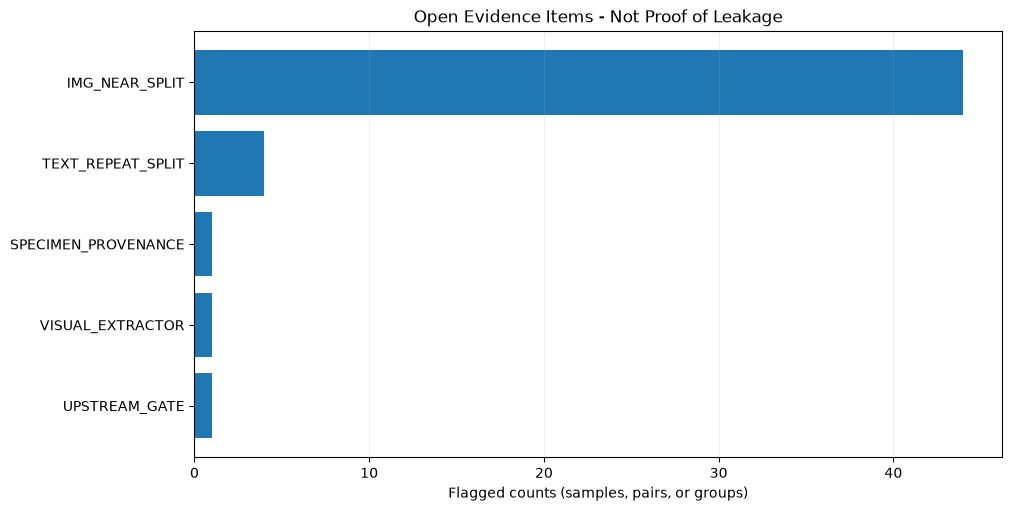


1. LEAKAGE REVIEW FINDINGS
------------------------------------------------------------------------


,issue_id,severity,finding_count,open
0,IMG_EXACT_SPLIT,BLOCK,0,False
1,IMG_CLASS_CONFLICT,BLOCK,0,False
2,IMG_MISSING_PIXEL_HASH,REVIEW,0,False
3,IMG_NEAR_SPLIT,REVIEW,44,True
4,TEXT_CLASS_NAME,REVIEW,0,False
5,TEXT_REPEAT_SPLIT,REVIEW,4,True
6,TEXT_CLASS_TEMPLATE,REVIEW,0,False
7,SPECIMEN_PROVENANCE,REVIEW,1,True
8,VISUAL_EXTRACTOR,REVIEW,1,True
9,UPSTREAM_GATE,REVIEW,1,True



2. MANUAL REVIEW TEMPLATE
------------------------------------------------------------------------


,issue_id,review_status,recommended_action
0,IMG_NEAR_SPLIT,PENDING,Inspect candidate pairs and group confirmed sa...
1,TEXT_REPEAT_SPLIT,PENDING,Review repeated descriptions across partitions.
2,SPECIMEN_PROVENANCE,PENDING,Verify original specimen/capture identity and ...
3,VISUAL_EXTRACTOR,PENDING,Compare raw visual descriptors with Notebook 03.
4,UPSTREAM_GATE,PENDING,Reconcile unresolved issues from Cell 10.



CELL 11 - LEAKAGE REVIEW COMPLETED
Review status: HOLD_REQUIRES_EVIDENCE_REVIEW
Open BLOCK categories: 0
Open REVIEW categories: 5
Reports: 10 CSV
Figures: 1
JSON handoff: 1
Test approved: False

[PASS] Text and image audit reports generated.
[PASS] Group provenance inventory generated.
[PASS] Manual review template saved.
[PASS] Existing reviewer notes preserved.
[INFO] No test scores or metrics accessed.
[INFO] Selection alpha remains unchanged.
[INFO] Formal test approval remains pending.

NOTEBOOK 06 - CELL 11 COMPLETED

Next: Review evidence and resolve leakage findings.


In [16]:

# ============================================================
# CELL 11 - LEAKAGE REVIEW & EVIDENCE PACK
# Notebook: 06_multimodal_retrieval_evaluation.ipynb
# ============================================================

from pathlib import Path
import hashlib
import json
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display


print("NOTEBOOK 06 - LEAKAGE REVIEW & EVIDENCE PACK")
print("=" * 72)

EVAL06_LEAKAGE_REVIEW_COMPLETED = False
EVAL06_REVIEW_APPROVED_FOR_TEST = False


# ============================================================
# 1. VALIDATE PREVIOUS CELLS
# ============================================================

required_flags = {
    "Cell 4": "EVAL06_FEATURE_PREPARATION_COMPLETED",
    "Cell 9": "EVAL06_FUSION_SELECTION_LOCKED",
    "Cell 10": "EVAL06_PRETEST_GATE_COMPLETED",
}

missing = [
    name
    for name, flag in required_flags.items()
    if globals().get(flag, False) is not True
]

if missing:
    raise RuntimeError(
        "Jalankan cell terlebih dahulu: "
        + ", ".join(missing)
    )

out_metrics = Path(EVAL06_METRICS_DIR)
out_figures = Path(EVAL06_FIGURES_DIR)

out_metrics.mkdir(
    parents=True,
    exist_ok=True
)

out_figures.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. LOAD CANONICAL INPUT FROM CELL 4
# ============================================================

# Use recovered original text from Cell 4.
# Do not use the earlier incomplete text audit.

required_cols = {
    "sample_id",
    "class_label",
    "split",
    "split_group_id",
    "normalized_text",
    "resolved_image_path",
    "matrix_row_index"
}

raw = EVAL06_FEATURE_INPUT_DF.copy()

missing_cols = (
    required_cols - set(raw.columns)
)

if missing_cols:
    raise ValueError(
        f"Kolom Cell 4 hilang: "
        f"{sorted(missing_cols)}"
    )

raw = (
    raw
    .sort_values(
        "matrix_row_index",
        kind="stable"
    )
    .reset_index(drop=True)
)

raw["sample_id"] = (
    raw["sample_id"].astype(str)
)

raw["class_label"] = (
    raw["class_label"].astype(str)
)

raw["split"] = (
    raw["split"].astype(str)
)

raw["normalized_text"] = (
    raw["normalized_text"]
    .fillna("")
    .astype(str)
)

raw["resolved_image_path"] = (
    raw["resolved_image_path"]
    .fillna("")
    .astype(str)
)

assert len(raw) == 104

assert raw["sample_id"].is_unique

assert raw["sample_id"].tolist() == list(
    map(str, EVAL06_SAMPLE_IDS)
)

assert raw["split"].isin(
    ["gallery", "validation", "test"]
).all()

assert (
    raw.groupby("split_group_id")["split"]
    .nunique()
    .eq(1)
    .all()
), (
    "Group melewati beberapa split. "
    "Perbaiki Cell 3 terlebih dahulu."
)

id_to_split = (
    raw.set_index("sample_id")[
        "split"
    ].to_dict()
)

id_to_class = (
    raw.set_index("sample_id")[
        "class_label"
    ].to_dict()
)

print("\n1. DATASET INVENTORY")
print("-" * 72)

print("Samples:", len(raw))
print("Classes:", raw["class_label"].nunique())

display(
    raw.groupby(
        ["split", "class_label"]
    )
    .size()
    .unstack(fill_value=0)
)


# ============================================================
# 3. DEFINE TEXT NORMALIZATION
# ============================================================

def review11_normalize(value):

    text = unicodedata.normalize(
        "NFKC",
        str(value)
    ).casefold()

    text = re.sub(
        r"[^\w\s]",
        " ",
        text,
        flags=re.UNICODE
    )

    return " ".join(
        text.split()
    )


raw["audit_text"] = (
    raw["normalized_text"]
    .map(review11_normalize)
)

raw["text_sha256"] = (
    raw["audit_text"].map(
        lambda text: (
            hashlib.sha256(
                text.encode("utf-8")
            ).hexdigest()
            if text
            else ""
        )
    )
)

raw["class_term"] = (
    raw["class_label"]
    .map(review11_normalize)
)


# ============================================================
# 4. DETECT CLASS-NAME CLUES IN DESCRIPTIONS
# ============================================================

# This detects direct class-name mentions.
# A mention is a potential label shortcut,
# not automatic proof of invalid data.

raw["class_name_in_text"] = [

    bool(term)

    and

    bool(
        re.search(
            r"(?<!\w)"
            + re.escape(term)
            + r"(?!\w)",
            text
        )
    )

    for term, text in zip(
        raw["class_term"],
        raw["audit_text"]
    )
]

EVAL06_REVIEW_TEXT_CLUES_DF = (

    raw.loc[
        raw["class_name_in_text"],

        [
            "sample_id",
            "class_label",
            "split",
            "class_term",
            "audit_text"
        ]
    ].copy()
)

EVAL06_REVIEW_TEXT_CLUES_DF[
    "text_excerpt"
] = (
    EVAL06_REVIEW_TEXT_CLUES_DF[
        "audit_text"
    ].str.slice(0, 200)
)

EVAL06_REVIEW_TEXT_CLUES_DF = (
    EVAL06_REVIEW_TEXT_CLUES_DF
    .drop(columns="audit_text")
)


# ============================================================
# 5. DETECT REPEATED TEXT ACROSS PARTITIONS
# ============================================================

repeat_rows = []

valid_text = raw.loc[
    raw["text_sha256"].ne("")
]

for digest, group in valid_text.groupby(
    "text_sha256"
):

    if len(group) <= 1:
        continue

    repeat_rows.append({
        "text_sha256":
            digest,

        "sample_count":
            len(group),

        "class_count":
            group["class_label"].nunique(),

        "split_count":
            group["split"].nunique(),

        "cross_split":
            group["split"].nunique() > 1,

        "sample_ids":
            " | ".join(
                group["sample_id"].tolist()
            ),

        "classes":
            " | ".join(
                sorted(
                    group["class_label"].unique()
                )
            ),

        "splits":
            " | ".join(
                sorted(
                    group["split"].unique()
                )
            ),

        "excerpt":
            str(
                group["audit_text"].iloc[0]
            )[:160]
    })

EVAL06_REVIEW_REPEATED_TEXT_DF = pd.DataFrame(
    repeat_rows,

    columns=[
        "text_sha256",
        "sample_count",
        "class_count",
        "split_count",
        "cross_split",
        "sample_ids",
        "classes",
        "splits",
        "excerpt"
    ]
)

repeated_cross_split = int(
    EVAL06_REVIEW_REPEATED_TEXT_DF[
        "cross_split"
    ].sum()
)


# ============================================================
# 6. AUDIT GROUP PROVENANCE
# ============================================================

group_rows = []

for group_id, group in raw.groupby(
    "split_group_id",
    dropna=False
):

    group_rows.append({
        "split_group_id":
            str(group_id),

        "samples":
            len(group),

        "class_count":
            group["class_label"].nunique(),

        "split_count":
            group["split"].nunique(),

        "split":
            " | ".join(
                sorted(
                    group["split"].unique()
                )
            ),

        "sample_ids":
            " | ".join(
                group["sample_id"].tolist()
            )
    })

EVAL06_REVIEW_GROUP_PROVENANCE_DF = (
    pd.DataFrame(group_rows)
)


# ============================================================
# 7. AUDIT EXACT IMAGE DUPLICATES
# ============================================================

image_columns = [
    "sample_id",
    "file_sha256",
    "decoded_pixel_sha256"
]

if "sample_id" not in EVAL06_IMAGE_AUDIT_DF.columns:
    raise ValueError(
        "Cell 2 image audit tidak memiliki sample_id."
    )

image_audit = EVAL06_IMAGE_AUDIT_DF.copy()

image_audit["sample_id"] = (
    image_audit["sample_id"].astype(str)
)

for column in image_columns[1:]:

    if column not in image_audit.columns:
        image_audit[column] = ""

image_audit = (
    raw[
        [
            "sample_id",
            "class_label",
            "split"
        ]
    ]
    .merge(
        image_audit[image_columns],
        on="sample_id",
        how="left",
        validate="one_to_one"
    )
)

exact_rows = []

for hash_column in image_columns[1:]:

    subset = image_audit.loc[
        image_audit[
            hash_column
        ]
        .fillna("")
        .astype(str)
        .str.strip()
        .ne("")
    ]

    for digest, group in subset.groupby(
        hash_column
    ):

        if len(group) <= 1:
            continue

        exact_rows.append({
            "hash_type":
                hash_column,

            "hash_prefix":
                str(digest)[:18],

            "sample_count":
                len(group),

            "cross_split":
                group["split"].nunique() > 1,

            "cross_class":
                group["class_label"].nunique() > 1,

            "classes":
                " | ".join(
                    sorted(
                        group["class_label"].unique()
                    )
                ),

            "splits":
                " | ".join(
                    sorted(
                        group["split"].unique()
                    )
                ),

            "sample_ids":
                " | ".join(
                    group["sample_id"].tolist()
                )
        })

EVAL06_REVIEW_EXACT_IMAGES_DF = pd.DataFrame(
    exact_rows,

    columns=[
        "hash_type",
        "hash_prefix",
        "sample_count",
        "cross_split",
        "cross_class",
        "classes",
        "splits",
        "sample_ids"
    ]
)

exact_cross_split = int(
    EVAL06_REVIEW_EXACT_IMAGES_DF[
        "cross_split"
    ].sum()
)

exact_cross_class = int(
    EVAL06_REVIEW_EXACT_IMAGES_DF[
        "cross_class"
    ].sum()
)

missing_sha_count = int(
    image_audit[
        "decoded_pixel_sha256"
    ]
    .fillna("")
    .astype(str)
    .str.strip()
    .eq("")
    .sum()
)


# ============================================================
# 8. AUDIT PERCEPTUAL NEAR DUPLICATES
# ============================================================

near_df = globals().get(
    "EVAL06_NEAR_DUPLICATE_DF",
    pd.DataFrame()
)

near_rows = []

if (
    isinstance(near_df, pd.DataFrame)
    and not near_df.empty
):

    needed = {
        "sample_id_i",
        "sample_id_j"
    }

    if not needed.issubset(
        near_df.columns
    ):
        raise ValueError(
            "Near-duplicate audit membutuhkan "
            "sample_id_i dan sample_id_j."
        )

    distance_col = next(
        (
            col
            for col in [
                "dhash_hamming_distance",
                "dhash_distance",
                "hamming_distance"
            ]
            if col in near_df.columns
        ),
        None
    )

    for row in near_df.to_dict("records"):

        left = str(row["sample_id_i"])
        right = str(row["sample_id_j"])

        if (
            left not in id_to_split
            or right not in id_to_split
        ):
            continue

        near_rows.append({
            "sample_id_i":
                left,

            "sample_id_j":
                right,

            "split_i":
                id_to_split[left],

            "split_j":
                id_to_split[right],

            "class_i":
                id_to_class[left],

            "class_j":
                id_to_class[right],

            "cross_split":
                id_to_split[left]
                != id_to_split[right],

            "dhash_hamming_distance":
                (
                    row.get(
                        distance_col,
                        np.nan
                    )
                    if distance_col
                    else np.nan
                ),

            "manual_review":
                "PENDING"
        })

EVAL06_REVIEW_NEAR_DUPLICATES_DF = pd.DataFrame(
    near_rows,

    columns=[
        "sample_id_i",
        "sample_id_j",
        "split_i",
        "split_j",
        "class_i",
        "class_j",
        "cross_split",
        "dhash_hamming_distance",
        "manual_review"
    ]
)

near_cross_split = int(
    EVAL06_REVIEW_NEAR_DUPLICATES_DF[
        "cross_split"
    ].sum()
)


# ============================================================
# 9. DETECT CLASS-LEVEL TEXT TEMPLATES
# ============================================================

EVAL06_REVIEW_CLASS_TEXT_DF = (

    raw.groupby(
        "class_label",
        as_index=False
    )

    .agg(
        samples=(
            "sample_id",
            "size"
        ),

        unique_descriptions=(
            "text_sha256",
            "nunique"
        ),

        class_name_mentions=(
            "class_name_in_text",
            "sum"
        )
    )
)

EVAL06_REVIEW_CLASS_TEXT_DF[
    "template_suspected"
] = (

    EVAL06_REVIEW_CLASS_TEXT_DF[
        "samples"
    ].gt(1)

    &

    EVAL06_REVIEW_CLASS_TEXT_DF[
        "unique_descriptions"
    ].eq(1)
)


# ============================================================
# 10. GENERATE METHODOLOGICAL FINDINGS
# ============================================================

findings = [

    (
        "IMG_EXACT_SPLIT",
        "BLOCK",
        exact_cross_split,
        "Verify exact duplicates and rebuild group-aware split.",
        "690_review_exact_image_duplicates.csv"
    ),

    (
        "IMG_CLASS_CONFLICT",
        "BLOCK",
        exact_cross_class,
        "Resolve conflicting class labels on identical image content.",
        "690_review_exact_image_duplicates.csv"
    ),

    (
        "IMG_MISSING_PIXEL_HASH",
        "REVIEW",
        missing_sha_count,
        "Review missing decoded image hashes in Cell 2.",
        "690_review_exact_image_duplicates.csv"
    ),

    (
        "IMG_NEAR_SPLIT",
        "REVIEW",
        near_cross_split,
        "Inspect candidate pairs and group confirmed same specimens.",
        "691_review_near_duplicate_candidates.csv"
    ),

    (
        "TEXT_CLASS_NAME",
        "REVIEW",
        len(EVAL06_REVIEW_TEXT_CLUES_DF),
        "Review label clues or run label-masked sensitivity analysis.",
        "688_review_text_label_clues.csv"
    ),

    (
        "TEXT_REPEAT_SPLIT",
        "REVIEW",
        repeated_cross_split,
        "Review repeated descriptions across partitions.",
        "689_review_repeated_text_groups.csv"
    ),

    (
        "TEXT_CLASS_TEMPLATE",
        "REVIEW",
        int(
            EVAL06_REVIEW_CLASS_TEXT_DF[
                "template_suspected"
            ].sum()
        ),
        "Document class-level description templates.",
        "692_review_class_text_statistics.csv"
    ),

    (
        "SPECIMEN_PROVENANCE",
        "REVIEW",
        1,
        "Verify original specimen/capture identity and grouping.",
        "693_review_group_provenance.csv"
    ),

    (
        "VISUAL_EXTRACTOR",
        "REVIEW",
        1,
        "Compare raw visual descriptors with Notebook 03.",
        "694_review_provenance_notes.csv"
    ),

    (
        "UPSTREAM_GATE",
        "REVIEW",
        int(
            not globals().get(
                "EVAL06_PRETEST_REVIEW_CLEARED",
                False
            )
        ),
        "Reconcile unresolved issues from Cell 10.",
        "680_pretest_gate_unresolved_issues.csv"
    )
]

EVAL06_REVIEW_FINDINGS_DF = pd.DataFrame(
    findings,

    columns=[
        "issue_id",
        "severity",
        "finding_count",
        "recommended_action",
        "evidence_file"
    ]
)

EVAL06_REVIEW_FINDINGS_DF[
    "open"
] = (
    EVAL06_REVIEW_FINDINGS_DF[
        "finding_count"
    ].gt(0)
)


# ============================================================
# 11. PREPARE MANUAL REVIEW TEMPLATE
# ============================================================

review_path = (
    out_metrics
    /
    "695_review_decision_template.csv"
)

review_template = (

    EVAL06_REVIEW_FINDINGS_DF.loc[
        EVAL06_REVIEW_FINDINGS_DF[
            "open"
        ]
    ]

    .copy()
    .reset_index(drop=True)
)

review_template[
    "review_status"
] = "PENDING"

review_template[
    "reviewer_notes"
] = ""

review_template[
    "supporting_evidence"
] = ""


# Preserve notes if the review template
# already exists and this cell is rerun.

if review_path.exists():

    try:

        previous = pd.read_csv(
            review_path,
            dtype=str,
            keep_default_na=False
        )

        if (
            "issue_id" in previous.columns
            and previous["issue_id"].is_unique
        ):

            old = previous.set_index(
                "issue_id"
            )

            preserve_columns = [
                col
                for col in [
                    "review_status",
                    "reviewer_notes",
                    "supporting_evidence"
                ]
                if col in previous.columns
            ]

            for column in preserve_columns:

                review_template[column] = [

                    old.at[
                        issue_id,
                        column
                    ]

                    if issue_id in old.index

                    else review_template.iloc[
                        position
                    ][column]

                    for position, issue_id
                    in enumerate(
                        review_template[
                            "issue_id"
                        ]
                    )
                ]

    except (
        OSError,
        ValueError,
        pd.errors.ParserError
    ) as error:

        raise RuntimeError(
            "File review sebelumnya "
            "tidak dapat dibaca."
        ) from error


# ============================================================
# 12. DOCUMENT SOURCE PROVENANCE
# ============================================================

provenance_notes = pd.DataFrame([

    {
        "area":
            "Text",

        "source":
            str(
                globals().get(
                    "source_name",
                    "UNKNOWN"
                )
            ),

        "status":
            "Text recovered; independence not certified"
    },

    {
        "area":
            "Visual extractor",

        "source":
            str(
                globals().get(
                    "EVAL06_VISUAL_EXTRACTOR_PROVENANCE",
                    "UNKNOWN"
                )
            ),

        "status":
            "Notebook 03 equivalence requires verification"
    },

    {
        "area":
            "Group provenance",

        "source":
            str(
                globals().get(
                    "EVAL06_GROUP_COLUMN",
                    "UNKNOWN"
                )
            ),

        "status":
            "Group-disjoint split; specimen identity unverified"
    },

    {
        "area":
            "Fusion selection",

        "source":
            str(
                EVAL06_SELECTION_LOCK_PATH
            ),

        "status":
            "Validation-selected configuration remains locked"
    }
])


# ============================================================
# 13. VALIDATE REVIEW INPUT INTEGRITY
# ============================================================

EVAL06_REVIEW_CHECKS_DF = pd.DataFrame([

    {
        "check":
            "104 unique aligned sample IDs",

        "passed":
            len(raw) == 104
            and raw["sample_id"].is_unique
    },

    {
        "check":
            "No groups cross partitions",

        "passed":
            raw.groupby(
                "split_group_id"
            )["split"]
            .nunique()
            .eq(1)
            .all()
    },

    {
        "check":
            "Descriptions are nonempty",

        "passed":
            raw["audit_text"]
            .ne("")
            .all()
    },

    {
        "check":
            "Image paths are present",

        "passed":
            raw[
                "resolved_image_path"
            ]
            .str.strip()
            .ne("")
            .all()
    },

    {
        "check":
            "Selection lock remains unchanged",

        "passed":
            Path(
                EVAL06_SELECTION_LOCK_PATH
            ).is_file()

            and

            EVAL06_SELECTION_LOCK.get(
                "selected_alpha"
            ) == EVAL06_SELECTED_ALPHA

            and

            EVAL06_SELECTION_LOCK.get(
                "selected_text_configuration"
            ) == EVAL06_SELECTED_TEXT_CONFIG
    },

    {
        "check":
            "Cell 10 has not approved test",

        "passed":
            globals().get(
                "EVAL06_PRETEST_APPROVED_FOR_INDEPENDENT_EVALUATION",
                False
            ) is False
    }
])

if not EVAL06_REVIEW_CHECKS_DF[
    "passed"
].all():

    display(
        EVAL06_REVIEW_CHECKS_DF
    )

    raise RuntimeError(
        "Pemeriksaan struktur audit gagal. "
        "Perbaiki data sumber terlebih dahulu."
    )


# ============================================================
# 14. SAVE EVIDENCE REPORTS
# ============================================================

reports = {

    "687_review_findings_summary.csv":
        EVAL06_REVIEW_FINDINGS_DF,

    "688_review_text_label_clues.csv":
        EVAL06_REVIEW_TEXT_CLUES_DF,

    "689_review_repeated_text_groups.csv":
        EVAL06_REVIEW_REPEATED_TEXT_DF,

    "690_review_exact_image_duplicates.csv":
        EVAL06_REVIEW_EXACT_IMAGES_DF,

    "691_review_near_duplicate_candidates.csv":
        EVAL06_REVIEW_NEAR_DUPLICATES_DF,

    "692_review_class_text_statistics.csv":
        EVAL06_REVIEW_CLASS_TEXT_DF,

    "693_review_group_provenance.csv":
        EVAL06_REVIEW_GROUP_PROVENANCE_DF,

    "694_review_provenance_notes.csv":
        provenance_notes,

    "696_review_integrity_checks.csv":
        EVAL06_REVIEW_CHECKS_DF
}

for filename, dataframe in reports.items():

    dataframe.to_csv(
        out_metrics / filename,
        index=False,
        encoding="utf-8-sig"
    )

review_template.to_csv(
    review_path,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 15. FIGURE 218 - LEAKAGE REVIEW FINDINGS
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 5),
    constrained_layout=True
)

visible_findings = (
    EVAL06_REVIEW_FINDINGS_DF.loc[
        EVAL06_REVIEW_FINDINGS_DF[
            "open"
        ]
    ]
)

if visible_findings.empty:

    ax.text(
        0.5,
        0.5,
        "No automatically flagged findings",
        ha="center",
        va="center",
        transform=ax.transAxes
    )

    ax.set_axis_off()

else:

    ax.barh(
        visible_findings[
            "issue_id"
        ],
        visible_findings[
            "finding_count"
        ]
    )

    ax.invert_yaxis()

    ax.set_xlabel(
        "Flagged counts (samples, pairs, or groups)"
    )

    ax.set_title(
        "Open Evidence Items - Not Proof of Leakage"
    )

    ax.grid(
        axis="x",
        alpha=0.2
    )

figure_path = (
    out_figures
    /
    "218_leakage_review_findings.png"
)

fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 16. DETERMINE REVIEW STATUS
# ============================================================

open_block = int(

    EVAL06_REVIEW_FINDINGS_DF.loc[
        EVAL06_REVIEW_FINDINGS_DF[
            "severity"
        ].eq("BLOCK")

        &

        EVAL06_REVIEW_FINDINGS_DF[
            "open"
        ]
    ].shape[0]
)

open_review = int(

    EVAL06_REVIEW_FINDINGS_DF.loc[
        EVAL06_REVIEW_FINDINGS_DF[
            "severity"
        ].eq("REVIEW")

        &

        EVAL06_REVIEW_FINDINGS_DF[
            "open"
        ]
    ].shape[0]
)

if open_block:

    EVAL06_LEAKAGE_REVIEW_STATUS = (
        "BLOCKED_REQUIRES_DATA_REPAIR"
    )

elif open_review:

    EVAL06_LEAKAGE_REVIEW_STATUS = (
        "HOLD_REQUIRES_EVIDENCE_REVIEW"
    )

else:

    EVAL06_LEAKAGE_REVIEW_STATUS = (
        "AUDIT_READY_PENDING_FORMAL_APPROVAL"
    )

EVAL06_REVIEW_APPROVED_FOR_TEST = False


# ============================================================
# 17. SAVE REVIEW HANDOFF
# ============================================================

selection_lock_hash = hashlib.sha256(
    Path(
        EVAL06_SELECTION_LOCK_PATH
    ).read_bytes()
).hexdigest()

handoff = {

    "notebook":
        "06_multimodal_retrieval_evaluation.ipynb",

    "cell":
        11,

    "sample_count":
        int(len(raw)),

    "selection_lock_sha256":
        selection_lock_hash,

    "selection_text_configuration":
        str(
            EVAL06_SELECTED_TEXT_CONFIG
        ),

    "selection_alpha":
        float(
            EVAL06_SELECTED_ALPHA
        ),

    "review_status":
        EVAL06_LEAKAGE_REVIEW_STATUS,

    "open_block_categories":
        open_block,

    "open_review_categories":
        open_review,

    "review_decisions_file":
        review_path.name,

    "test_metrics_computed":
        False,

    "test_approval":
        False,

    "next_step":
        "Review evidence and repair confirmed leakage; "
        "rerun affected upstream cells before test."
}

handoff_path = (
    out_metrics
    /
    "697_leakage_review_handoff.json"
)

handoff_path.write_text(
    json.dumps(
        handoff,
        indent=2,
        ensure_ascii=False,
        allow_nan=False
    ),
    encoding="utf-8"
)


# ============================================================
# 18. FINAL ARTIFACT VALIDATION
# ============================================================

assert all(
    (
        out_metrics / filename
    ).is_file()

    for filename in reports
)

assert review_path.is_file()

assert handoff_path.is_file()

assert (
    figure_path.is_file()
    and figure_path.stat().st_size > 0
)

EVAL06_LEAKAGE_REVIEW_COMPLETED = True


# ============================================================
# 19. FINAL OUTPUT
# ============================================================

print("\n1. LEAKAGE REVIEW FINDINGS")
print("-" * 72)

display(
    EVAL06_REVIEW_FINDINGS_DF[
        [
            "issue_id",
            "severity",
            "finding_count",
            "open"
        ]
    ]
)

print("\n2. MANUAL REVIEW TEMPLATE")
print("-" * 72)

display(
    review_template[
        [
            "issue_id",
            "review_status",
            "recommended_action"
        ]
    ]
)

print("\n" + "=" * 72)

print("CELL 11 - LEAKAGE REVIEW COMPLETED")

print("=" * 72)

print(
    "Review status:",
    EVAL06_LEAKAGE_REVIEW_STATUS
)

print(
    "Open BLOCK categories:",
    open_block
)

print(
    "Open REVIEW categories:",
    open_review
)

print(
    "Reports:",
    len(reports) + 1,
    "CSV"
)

print("Figures: 1")
print("JSON handoff: 1")

print(
    "Test approved:",
    EVAL06_REVIEW_APPROVED_FOR_TEST
)

print(
    "\n[PASS] Text and image audit reports generated."
)

print(
    "[PASS] Group provenance inventory generated."
)

print(
    "[PASS] Manual review template saved."
)

print(
    "[PASS] Existing reviewer notes preserved."
)

print(
    "[INFO] No test scores or metrics accessed."
)

print(
    "[INFO] Selection alpha remains unchanged."
)

print(
    "[INFO] Formal test approval remains pending."
)

print("\n" + "=" * 72)

print("NOTEBOOK 06 - CELL 11 COMPLETED")

print("=" * 72)

print(
    "\nNext: Review evidence and resolve leakage findings."
)
